# Monitoring Digital Payment Reliability in Nigeria
### A Baseline Profile of Transaction Concentration, Temporal Patterns, and Scenario-Based KPI Detection Using Synthetic Transaction Data

**PairBud Project** - Emmanuel Olawumi & Favour Obajuaye
**Last Updated:** November 2026

---

# 1. Project Introduction

## Why I am doing this project

Digital payments play an important role in Nigeria's financial services industry. However, failed, pending, and reversed transactions can create customer complaints and operational challenges for financial institutions.

I want to explore how data analytics can support the monitoring of digital payment reliability. I will examine transaction patterns, identify useful monitoring indicators, and test how different methods respond to controlled changes in transaction outcomes.

My project partner and I selected a synthetic Nigerian retail banking dataset because publicly available transaction-level banking data is limited. This dataset allows us to demonstrate an analytical workflow using transaction-level records.

An important distinction guides this project: the dataset is synthetic. Therefore, the findings describe the dataset and its generated patterns. They do not represent the actual performance of Nigerian banks, fintech companies, or payment systems.

## What I will build

I will develop a reproducible Jupyter Notebook with three main analytical layers.

1. Baseline profiling. I will examine transaction outcomes, account activity concentration, transaction volumes, temporal patterns, and channel, merchant-category, and geographical distributions.

2. Scenario-based monitoring tests. I will introduce controlled changes to selected transaction outcomes and evaluate how different monitoring methods detect those changes.

3. Operational monitoring recommendations. I will use the baseline findings and scenario-test results to propose practical KPIs and monitoring approaches.

I will not invent transaction failure reasons or claim to explain what causes payment failures. The dataset does not contain the information needed to support such conclusions.

## Research questions

1. How are transactions distributed across success, failed, pending, and reversed statuses?
2. How concentrated is transaction activity across customer accounts?
3. What temporal patterns appear in transaction volume across hours, days, and months?
4. How do transaction volume and value vary across channels, merchant categories, and states?
5. How effectively do selected monitoring methods detect controlled changes in transaction reliability?
6. Which operational KPIs can support transaction reliability monitoring?

## Project scope

The project covers:

- Descriptive profiling of transaction statuses, channels, transaction types, merchant categories, states, and transaction amounts.
- Account-level transaction concentration, including the distribution of activity across accounts.
- Temporal analysis of transaction volumes and patterns.
- Controlled scenario simulation to evaluate monitoring methods.
- KPI design and evaluation using measures such as detection lag and false-positive rate.

## Project exclusions

The following areas are outside the scope of this project:

- Failure-cause analysis. The dataset does not contain failure reason codes.
- Settlement-delay analysis. The dataset does not contain settlement timestamps.
- Fraud prediction. The synthetic fraud flag has not demonstrated a meaningful relationship with transaction outcomes.
- Balance reconstruction. The balance fields contain structural defects and will be excluded from subsequent analytical work.
- Claims about actual Nigerian payment reliability. The dataset is synthetic and cannot support such claims.

## Data sources

**1. Primary analytical dataset**

Synthetic Nigerian Retail Banking Transactions, hosted on Hugging Face.

Dataset repository:  
https://huggingface.co/datasets/electricsheepafrica/nigerian-banking-retail-transactions

The dataset contains 5,000,000 transaction records and 16 columns. It covers January 2023 to December 2024 and records transaction amounts in Nigerian Naira (₦).

**2. External context**

Central Bank of Nigeria (CBN) e-Payment Statistics:

https://www.cbn.gov.ng/PaymentsSystem/ePaymentStatistics.html

CBN statistics may provide separate context about the scale and development of digital payments in Nigeria. They will not be merged with the synthetic transaction-level dataset or used to calculate transaction failure rates.

## Analytical workflow

I will follow five phases:

1. Preparation: Set up the environment, acquire the dataset, and document the source.
2. Data understanding and preparation: Inspect the structure, audit data quality, address identified limitations, and prepare analytical features.
3. Baseline analysis: Examine transaction outcomes, account concentration, temporal patterns, and transaction composition.
4. Scenario simulation: Introduce three controlled scenarios and test selected monitoring methods.
5. Evaluation and recommendations: Compare detection performance, define monitoring KPIs, and document practical recommendations.

## Reporting rule for simulated results

All charts, tables, and findings produced from modified or simulated transaction data must carry the label:

**Scenario test output, not observed data.**

This distinction separates the original dataset's baseline findings from the results of controlled experiments.

## Data preservation and memory management

The original Parquet file on disk will remain unchanged. All data preparation and analysis will take place in memory using the working DataFrame, `df`.

The notebook will document each transformation. These include:

1. Memory optimisation through data type conversion.
2. Temporary audit columns that are removed after use.
3. Removal of the defective balance fields after the Section 4 audit.
4. Creation of analytical features for subsequent sections.

I will not maintain an unnecessary full-size raw copy in memory. If I need to restart the analysis, I can reload the original Parquet file using the data-loading code in Section 2.

This approach helps preserve the original source data while reducing memory consumption and the risk of accidentally using fields that have already been identified as unsuitable for analysis.

> **Review status:** This notebook has been reviewed for methodological clarity, statistical interpretation, and consistency. The edits do not replace a full execution against the source Parquet file. Restart the kernel and run every cell before using the displayed numerical outputs in the final report.


# 2. Environment and Data Acquisition

## What I am doing in this section

Before analysing the dataset, I need to prepare the Python environment and load the source data.

This section covers:

1. Importing the Python libraries required for the project.
2. Defining the project directory and dataset location.
3. Checking whether the Parquet file already exists.
4. Downloading the file if it is not available locally.
5. Loading the dataset into Pandas with memory-conscious data types.
6. Checking the loaded dataset against its expected structure.

## Why I am using Parquet

The dataset is provided as a Parquet file. Parquet is a columnar storage format that supports efficient storage and retrieval of tabular data.

It is suitable for this project because:

- It generally stores tabular data more compactly than CSV.
- It supports efficient column selection when reading data.
- It preserves data types.
- Pandas can read it directly when a compatible Parquet engine is installed.

## Memory optimisation

The dataset contains five million rows. Loading every column with default Pandas data types can consume substantial memory.

I will therefore:

- Load only the columns required for the project and the initial data audits.
- Use `float32` for numeric fields where appropriate.
- Convert repeated categorical values to the `category` data type.
- Retain identifiers as strings.
- Convert the timestamp column to a proper datetime type.
- Retain the original Parquet file without modifying it.

I will measure the actual memory footprint rather than assume a particular percentage reduction.

## Data acquisition approach

The notebook first checks whether the Parquet file exists in the project directory. If it does, the notebook uses the local file. Otherwise, it downloads the file directly from the dataset's Hugging Face repository.

This avoids downloading the dataset again when a local copy is already available.

In [1]:
# ============================================================
# SECTION 2.1: IMPORTING LIBRARIES
# ============================================================

# File and directory management
from pathlib import Path
import urllib.request

# Data analysis
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Libraries imported successfully.
Pandas version: 2.3.3
NumPy version: 2.3.5


In [2]:
# ============================================================
# SECTION 2.2: SETTING THE PROJECT DIRECTORY
# ============================================================

# Change this path to the location of your project folder.
PROJECT_DIR = Path(
    r"C:\Python Study Group\payment-reliability-project"
)

# Create the folder if it does not already exist.
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset filename and full path
DATA_FILENAME = "nigerian_retail_transactions_full.parquet"
DATA_PATH = PROJECT_DIR / DATA_FILENAME

print(f"Project directory: {PROJECT_DIR}")
print(f"Dataset path: {DATA_PATH}")

Project directory: C:\Python Study Group\payment-reliability-project
Dataset path: C:\Python Study Group\payment-reliability-project\nigerian_retail_transactions_full.parquet


In [3]:
# ============================================================
# SECTION 2.3: ACQUIRING THE DATASET
# ============================================================

# Direct Parquet download from Hugging Face.
DATA_URL = (
    "https://huggingface.co/datasets/"
    "electricsheepafrica/nigerian-banking-retail-transactions/"
    "resolve/main/nigerian_retail_transactions_full.parquet"
)

if DATA_PATH.exists():
    print("Dataset found locally.")

else:
    print("Dataset not found. Starting download...")

    # Download to a temporary file first.
    TEMP_PATH = DATA_PATH.with_suffix(".parquet.tmp")

    try:
        urllib.request.urlretrieve(DATA_URL, TEMP_PATH)

        # Rename only after the download completes.
        TEMP_PATH.replace(DATA_PATH)

        print("Download completed successfully.")

    except Exception as error:
        # Remove an incomplete temporary download.
        if TEMP_PATH.exists():
            TEMP_PATH.unlink()

        raise RuntimeError(
            "Dataset download failed. Check your internet connection "
            "and the Hugging Face dataset link."
        ) from error

# Report file size.
file_size_mb = DATA_PATH.stat().st_size / 1_000_000

print(f"Dataset location: {DATA_PATH}")
print(f"File size: {file_size_mb:,.1f} MB")

Dataset found locally.
Dataset location: C:\Python Study Group\payment-reliability-project\nigerian_retail_transactions_full.parquet
File size: 422.8 MB


In [4]:
# ============================================================
# SECTION 2.4: LOADING THE DATASET INTO MEMORY
# ============================================================

# Define memory-conscious data types.
dtype_mapping = {
    "transaction_id":         "string",
    "account_id":             "string",
    "customer_id":            "string",
    "amount_ngn":             "float32",
    "balance_before_ngn":     "float32",
    "balance_after_ngn":      "float32",
    "transaction_type":       "category",
    "channel":                "category",
    "merchant_category_code": "category",
    "merchant_name":          "category",
    "location_lga":           "category",
    "location_state":         "category",
    "device_id":              "string",
    "status":                 "category",
    "fraud_flag":             "bool"
}

# Load all 16 columns because the initial audits require them.
print("Loading dataset...")

df = pd.read_parquet(DATA_PATH)

# Confirm that the expected columns are present.
expected_columns = list(dtype_mapping.keys())

missing_columns = set(expected_columns) - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Dataset is missing expected columns: {missing_columns}"
    )

# Apply the selected data types.
for column, dtype in dtype_mapping.items():
    df[column] = df[column].astype(dtype)

# Convert timestamp to datetime.
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="raise"
)

# Report the loaded dataset.
memory_gb = df.memory_usage(deep=True).sum() / 1e9

print("\nDataset loaded successfully.")
print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory:  {memory_gb:.2f} GB")

Loading dataset...

Dataset loaded successfully.
Rows:    5,000,000
Columns: 16
Memory:  1.47 GB


In [5]:
# ============================================================
# SECTION 2.4b: MEASURING MEMORY USAGE
# ============================================================

memory_bytes = df.memory_usage(deep=True).sum()

memory_mb = memory_bytes / 1_000_000
memory_gb = memory_bytes / 1_000_000_000

print("=" * 55)
print("DATAFRAME MEMORY PROFILE")
print("=" * 55)

print(f"Rows:          {len(df):,}")
print(f"Columns:       {df.shape[1]}")
print(f"Memory usage:  {memory_mb:,.2f} MB")
print(f"Memory usage:  {memory_gb:,.3f} GB")

print("\nMemory usage by column:")

memory_by_column = (
    df.memory_usage(deep=True)
    .sort_values(ascending=False)
    .to_frame(name="Memory (bytes)")
)

memory_by_column["Memory (MB)"] = (
    memory_by_column["Memory (bytes)"] / 1_000_000
)

print(memory_by_column.round(2).to_string())

DATAFRAME MEMORY PROFILE
Rows:          5,000,000
Columns:       16
Memory usage:  1,465.00 MB
Memory usage:  1.465 GB

Memory usage by column:
                        Memory (bytes)  Memory (MB)
transaction_id               425000000       425.00
account_id                   305000000       305.00
customer_id                  305000000       305.00
device_id                    289990720       289.99
timestamp                     40000000        40.00
amount_ngn                    20000000        20.00
balance_before_ngn            20000000        20.00
balance_after_ngn             20000000        20.00
merchant_name                  5003648         5.00
location_lga                   5003243         5.00
location_state                 5003095         5.00
merchant_category_code         5001347         5.00
channel                        5000673         5.00
status                         5000396         5.00
transaction_type               5000217         5.00
fraud_flag              

### Note on memory optimisation

The dataset contains five million rows, so memory management is important.

I use smaller and more appropriate data types to reduce the memory required by the working DataFrame. Repeated text values are stored as categorical variables, identifiers are stored as strings, and selected numeric fields use `float32`.

The current DataFrame's memory usage is measured directly in Section 2.4b using:

`df.memory_usage(deep=True).sum()`

An earlier full-data comparison measured approximately 3.56 GB for a default-type representation and 1.47 GB for the optimised representation. This represented an approximate 59% reduction under that comparison's measurement assumptions.

I will not repeat the full default-type load in every notebook run because it creates an unnecessary memory spike.

After Section 4, the two defective balance fields will be removed. The resulting DataFrame will use less memory and will become the working dataset for subsequent analysis.

The original Parquet file remains unchanged. All transformations affect only the in-memory DataFrame.

In [6]:
# ============================================================
# SECTION 2.5: INITIAL DATA SANITY CHECK
# ============================================================

print("=" * 65)
print("INITIAL DATA PROFILE")
print("=" * 65)

# 1. Dataset dimensions
print(f"\n[1] Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

# 2. Column names
print("\n[2] Columns:")
for number, column in enumerate(df.columns, start=1):
    print(f"{number:2}. {column}")

# 3. Timestamp coverage
print("\n[3] Timestamp range:")
print(f"Start: {df['timestamp'].min()}")
print(f"End:   {df['timestamp'].max()}")

# 4. Transaction statuses
print("\n[4] Transaction status counts:")
print(df["status"].value_counts(dropna=False).to_string())

# 5. Transaction amounts
print("\n[5] Transaction amount range:")
print(f"Minimum: ₦{df['amount_ngn'].min():,.2f}")
print(f"Maximum: ₦{df['amount_ngn'].max():,.2f}")

# 6. Missing values
missing_total = df.isna().sum().sum()
print(f"\n[6] Total missing values: {missing_total:,}")

# 7. Duplicate transaction IDs
duplicate_ids = df["transaction_id"].duplicated().sum()
print(f"[7] Duplicate transaction IDs: {duplicate_ids:,}")

# 8. Expected structure checks
print("\n[8] Expected structure checks:")

checks = {
    "Expected row count": df.shape[0] == 5_000_000,
    "Expected column count": df.shape[1] == 16,
    "No missing values": missing_total == 0,
    "No duplicate transaction IDs": duplicate_ids == 0,
    "Timestamp column is datetime": pd.api.types.is_datetime64_any_dtype(
        df["timestamp"]
    )
}

for check, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'}: {check}")

print("\n" + "=" * 65)

INITIAL DATA PROFILE

[1] Dataset shape: 5,000,000 rows × 16 columns

[2] Columns:
 1. transaction_id
 2. account_id
 3. customer_id
 4. timestamp
 5. amount_ngn
 6. balance_before_ngn
 7. balance_after_ngn
 8. transaction_type
 9. channel
10. merchant_category_code
11. merchant_name
12. location_lga
13. location_state
14. device_id
15. status
16. fraud_flag

[3] Timestamp range:
Start: 2023-01-01 00:07:00
End:   2024-12-30 23:59:00

[4] Transaction status counts:
status
success     4599963
failed       349765
pending       40383
reversed       9889

[5] Transaction amount range:
Minimum: ₦100.00
Maximum: ₦5,000,000.00

[6] Total missing values: 0
[7] Duplicate transaction IDs: 0

[8] Expected structure checks:
PASS: Expected row count
PASS: Expected column count
PASS: No missing values
PASS: No duplicate transaction IDs
PASS: Timestamp column is datetime



# 3. Data Understanding and Initial Profiling

## What I am doing in this section

Before cleaning or analysing the dataset, I need to understand its structure and contents.

I will examine:

- The data type and completeness of each column.
- The number of distinct values in each variable.
- The distribution and range of transaction amounts.
- The distribution of transaction statuses.
- The date range and continuity of transaction records.
- The distribution of important categorical variables.

## Why this matters

Initial profiling helps me understand what the dataset contains before making analytical decisions.

It can reveal missing values, unexpected categories, unusual numerical values, and gaps in the date coverage.

It also helps identify variables that require further investigation. For example, the balance fields and fraud indicator will undergo additional audits in Section 4 before I decide whether they are suitable for analytical use.

The purpose of this section is to describe the dataset and identify questions for further investigation. It is not yet the full data-quality audit.

In [7]:
# ============================================================
# SECTION 3.1: COLUMN INVENTORY
# ============================================================

# Summarise the structure of each column.
inventory = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null": df.notna().sum(),
    "Unique": df.nunique(),
    "Missing": df.isna().sum()
})

print("=" * 70)
print("COLUMN INVENTORY")
print("=" * 70)

display(inventory)

COLUMN INVENTORY


,Data Type,Non-Null,Unique,Missing
transaction_id,string,5000000,5000000,0
account_id,string,5000000,100000,0
customer_id,string,5000000,100000,0
timestamp,datetime64[ns],5000000,848014,0
amount_ngn,float32,5000000,27400,0
balance_before_ngn,float32,5000000,4742293,0
balance_after_ngn,float32,5000000,4435161,0
transaction_type,category,5000000,2,0
channel,category,5000000,7,0
merchant_category_code,category,5000000,15,0


In [8]:
# ============================================================
# SECTION 3.2: NUMERICAL SUMMARY
# ============================================================

# These fields are inspected during initial profiling.
# The balance fields will undergo a separate audit in Section 4.

numeric_cols = [
    "amount_ngn",
    "balance_before_ngn",
    "balance_after_ngn"
]

numerical_summary = df[numeric_cols].describe().T

print("=" * 70)
print("NUMERICAL SUMMARY")
print("=" * 70)

display(numerical_summary.round(2))

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
amount_ngn,"5,000,000.00","65,621.99","226,674.12",100.00,"4,000.00","13,300.00","45,000.00","5,000,000.00"
balance_before_ngn,"5,000,000.00","336,498.78","450,818.06","4,577.12","86,098.42","187,949.88","402,859.48","14,879,436.00"
balance_after_ngn,"5,000,000.00","334,980.25","472,576.31",0.00,"73,019.20","183,106.65","408,644.07","14,820,636.00"


In [9]:
# ============================================================
# SECTION 3.2b: RECONCILING THE AMOUNT STANDARD DEVIATION
# ============================================================

amount_float32 = df["amount_ngn"]

# Method 1: Pandas using the stored float32 column.
std_pandas_float32 = amount_float32.std(ddof=1)

# Method 2: Pandas after promotion to float64.
amount_float64 = amount_float32.astype("float64")
std_pandas_float64 = amount_float64.std(ddof=1)

# Method 3: NumPy using float64 accumulation.
std_numpy_float64 = np.std(
    amount_float32.to_numpy(),
    ddof=1,
    dtype=np.float64
)

print("=" * 65)
print("AMOUNT STANDARD DEVIATION COMPARISON")
print("=" * 65)

print(f"Rows compared:                 {len(df):,}")
print(f"Pandas float32:                ₦{std_pandas_float32:,.2f}")
print(f"Pandas float64:                ₦{std_pandas_float64:,.2f}")
print(f"NumPy float64:                 ₦{std_numpy_float64:,.2f}")

print("\nDifferences:")
print(
    "Pandas float32 vs float64:    "
    f"₦{abs(std_pandas_float64 - std_pandas_float32):,.2f}"
)

print(
    "Pandas float64 vs NumPy:      "
    f"₦{abs(std_pandas_float64 - std_numpy_float64):,.2f}"
)

print("\nAmount summary using float64:")
print(f"Mean:   ₦{amount_float64.mean():,.2f}")
print(f"Median: ₦{amount_float64.median():,.2f}")

AMOUNT STANDARD DEVIATION COMPARISON
Rows compared:                 5,000,000
Pandas float32:                ₦226,674.12
Pandas float64:                ₦230,311.87
NumPy float64:                 ₦230,311.87

Differences:
Pandas float32 vs float64:    ₦3,637.75
Pandas float64 vs NumPy:      ₦0.00

Amount summary using float64:
Mean:   ₦65,621.99
Median: ₦13,300.00


### Note on the amount standard deviation

The initial numerical summary reports the amount standard deviation using the stored `float32` column.

To check the result, I recalculate the standard deviation after promoting the amount column to `float64`. I also compare it with a NumPy calculation using float64 accumulation.

This comparison helps establish whether the reported difference comes from the numerical calculation method.

The original storage type remains unchanged. I use the verified float64 calculation for descriptive reporting where higher numerical precision is required.

The mean and median are also checked using the promoted values. I will report the figures produced by the notebook rather than rely on previously recorded values.

In [10]:
# ============================================================
# SECTION 3.3: TRANSACTION STATUS DISTRIBUTION
# ============================================================

status_order = [
    "success",
    "failed",
    "pending",
    "reversed"
]

# Calculate transaction counts.
status_counts = (
    df["status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

# Calculate percentage shares.
status_share = (
    status_counts / status_counts.sum()
) * 100

# Combine results into one table.
status_summary = pd.DataFrame({
    "Transaction Count": status_counts,
    "Share (%)": status_share
})

print("=" * 70)
print("TRANSACTION STATUS DISTRIBUTION")
print("=" * 70)

display(status_summary.round(3))

print(f"\nTotal transactions: {status_counts.sum():,}")
print(f"Total share: {status_share.sum():.2f}%")

TRANSACTION STATUS DISTRIBUTION


,Transaction Count,Share (%)
status,,
success,4599963,92.00
failed,349765,7.00
pending,40383,0.81
reversed,9889,0.20



Total transactions: 5,000,000
Total share: 100.00%


In [11]:
# ============================================================
# SECTION 3.4: DATE COVERAGE
# ============================================================

print("=" * 70)
print("DATE COVERAGE")
print("=" * 70)

# Identify the earliest and latest transaction dates.
min_date = df["timestamp"].min().normalize()
max_date = df["timestamp"].max().normalize()

# Calculate the complete calendar date range.
date_range = pd.date_range(
    start=min_date,
    end=max_date,
    freq="D"
)

total_days = len(date_range)

# Create a temporary date column.
df["date"] = df["timestamp"].dt.normalize()

# Count transactions per calendar day.
daily_counts = df.groupby("date", observed=True).size()

# Reindex to include dates with zero transactions.
daily_counts = daily_counts.reindex(
    date_range,
    fill_value=0
)

# Identify dates with no transactions.
missing_dates = daily_counts[daily_counts == 0]

print(f"Earliest transaction: {min_date}")
print(f"Latest transaction:   {max_date}")
print(f"Calendar days:        {total_days:,}")
print(f"Days with activity:   {(daily_counts > 0).sum():,}")
print(f"Missing days:         {len(missing_dates):,}")

print("\nDaily transaction volume:")
print(f"Minimum: {daily_counts.min():,}")
print(f"Maximum: {daily_counts.max():,}")
print(f"Mean:    {daily_counts.mean():,.0f}")

if len(missing_dates) > 0:
    print("\nDates with no transactions:")
    print(missing_dates.index.strftime("%Y-%m-%d").tolist())

# Remove the temporary column.
df.drop(columns="date", inplace=True)

DATE COVERAGE
Earliest transaction: 2023-01-01 00:00:00
Latest transaction:   2024-12-30 00:00:00
Calendar days:        730
Days with activity:   730
Missing days:         0

Daily transaction volume:
Minimum: 6,546
Maximum: 7,086
Mean:    6,849


In [12]:
# ============================================================
# SECTION 3.5: CATEGORICAL DISTRIBUTIONS
# ============================================================

categorical_cols = [
    "channel",
    "transaction_type",
    "location_state",
    "merchant_category_code"
]

for column in categorical_cols:

    print("=" * 70)
    print(f"DISTRIBUTION: {column.upper()}")
    print("=" * 70)

    distribution = (
        df[column]
        .value_counts(dropna=False)
        .to_frame(name="Transaction Count")
    )

    distribution["Share (%)"] = (
        distribution["Transaction Count"] / len(df)
    ) * 100

    display(distribution.round(3))

DISTRIBUTION: CHANNEL


,Transaction Count,Share (%)
channel,,
mobile,1749043,34.98
pos,1501370,30.03
atm,999469,19.99
web,500493,10.01
branch,149372,2.99
ussd,75336,1.51
agent,24917,0.50


DISTRIBUTION: TRANSACTION_TYPE


,Transaction Count,Share (%)
transaction_type,,
debit,3250541,65.01
credit,1749459,34.99


DISTRIBUTION: LOCATION_STATE


,Transaction Count,Share (%)
location_state,,
Lagos,1225836,24.52
Abuja (FCT),542759,10.86
Rivers,446381,8.93
Kano,288046,5.76
Anambra,239518,4.79
Oyo,238988,4.78
Imo,186312,3.73
Kaduna,159387,3.19
Delta,135097,2.70


DISTRIBUTION: MERCHANT_CATEGORY_CODE


,Transaction Count,Share (%)
merchant_category_code,,
,2998137,59.96
4814,400590,8.01
5411,300383,6.01
5812,239530,4.79
5541,200467,4.01
4900,160888,3.22
4899,120426,2.41
5999,100015,2.00
5814,99768,2.00


In [13]:
# ============================================================
# SECTION 3.2c: CHECKING AMOUNT INCREMENTS
# ============================================================

# Check whether transaction amounts are multiples of ₦100.
# The modulo operator (%) returns the remainder after division.

amount_remainder = df["amount_ngn"] % 100

multiples_of_100 = amount_remainder == 0

multiple_count = multiples_of_100.sum()
non_multiple_count = (~multiples_of_100).sum()

multiple_share = (multiple_count / len(df)) * 100

print("=" * 65)
print("TRANSACTION AMOUNT INCREMENT CHECK")
print("=" * 65)

print(f"Total transactions:       {len(df):,}")
print(f"Multiples of ₦100:        {multiple_count:,}")
print(f"Not multiples of ₦100:    {non_multiple_count:,}")
print(f"Share in multiples:       {multiple_share:.2f}%")

TRANSACTION AMOUNT INCREMENT CHECK
Total transactions:       5,000,000
Multiples of ₦100:        5,000,000
Not multiples of ₦100:    0
Share in multiples:       100.00%


### Observations from Section 3

The initial profiling provides a clearer understanding of the dataset's structure, transaction composition, and coverage.

**1. The dataset is structurally complete, but its synthetic nature requires caution.**

The dataset contains exactly 5,000,000 transaction records and 16 columns. The initial audit reports no missing values and no duplicate transaction IDs.

It covers 730 consecutive calendar days, from January 2023 to December 2024, with no missing days. Daily transaction volumes range from 6,546 to 7,086.

The remarkably narrow daily volume range and the nearly constant failure rate observed in subsequent audits are consistent with a controlled synthetic data-generation process. I will therefore interpret the results as properties of this dataset rather than evidence of actual Nigerian payment behaviour.

**2. Transaction outcomes have four distinct categories.**

The status distribution is:

- Success: 4,599,963 transactions (92.00%).
- Failed: 349,765 transactions (7.00%).
- Pending: 40,383 transactions (0.81%).
- Reversed: 9,889 transactions (0.20%).

I will retain all four categories throughout the project. They represent distinct recorded outcomes and should not be combined without a clear analytical reason.

In particular, I will not assume that every reversed transaction represents a refund or chargeback. The dataset does not provide enough information to establish the underlying reversal process.

**3. Transaction amounts show a generated numerical pattern.**

All transaction amounts are positive. The amount-increment check will establish whether they are consistently recorded in multiples of ₦100.

If confirmed, this pattern will be documented as a synthetic data characteristic. It may affect the interpretation of amount distributions and amount bands.

I will not treat this pattern as representative of real customer payment behaviour.

**4. Transaction activity is concentrated in three channels.**

Mobile, POS, and ATM account for approximately 85.00% of all transactions.

- Mobile: approximately 34.98%.
- POS: approximately 30.03%.
- ATM: approximately 19.99%.

USSD and Agent together account for approximately 2.01%.

This indicates that transaction volume is concentrated in a few channels within the dataset.

However, a higher transaction volume does not automatically mean a higher failure risk. The later statistical audit found a negligible association between channel and transaction outcome, with Cramér's V of approximately 0.000738.

I will therefore distinguish monitoring priority based on transaction exposure from reliability risk based on observed outcomes.

**5. Debit transactions account for a larger share of activity.**

The dataset contains approximately 3,250,541 debit transactions and 1,749,459 credit transactions.

This gives a debit-to-credit ratio of approximately 1.86:1.

The distribution describes the transaction records in this dataset. It does not establish the underlying business process or represent a complete banking ledger.

**6. Transaction activity is geographically concentrated.**

Lagos accounts for approximately 24.52% of all transaction records. The five highest-volume states account for approximately 54.86% of activity.

This shows that transaction volume is unevenly distributed across the geographical categories represented in the dataset.

I will examine geographical composition as a descriptive dimension. I will not interpret differences in state-level failure rates as evidence of differences in actual payment reliability.

**7. Some variables require further investigation.**

The initial profiling establishes the dataset's general structure, but it does not establish that every variable is suitable for analysis.

Two variables require particular attention:

- Balance fields: `balance_before_ngn` and `balance_after_ngn`.
- Fraud indicator: `fraud_flag`.

Section 4 will investigate their behaviour and determine whether they can support the intended analysis.

### What this means for the project

The initial profiling identifies several useful dimensions for further analysis:

- Four distinct transaction outcomes.
- Concentration of transaction activity across channels.
- Geographical concentration of transaction volume.
- A larger share of debit transactions.
- Continuous daily transaction coverage.
- Potential numerical artefacts in transaction amounts.

These findings help define the baseline profile. They also establish why the later analysis must distinguish between descriptive patterns, data limitations, and simulated monitoring results.

# 4. Data Quality Audit and Cleaning

## Why this section exists

Section 3 established that the dataset has a complete structure, with no missing values, no duplicate transaction IDs, and continuous date coverage.

However, structural completeness does not guarantee that every variable is analytically reliable.

In this section, I conduct four audits to investigate the behaviour and suitability of important fields.

1. Audit A, Balance integrity: Do the balance fields behave consistently with the recorded transaction statuses?
2. Audit B, Outcome association: Is transaction status associated with channel, transaction type, or the fraud flag?
3. Audit C, Fraud flag behaviour: How prevalent is the fraud flag, and how does its distribution vary across selected transaction groups?
4. Audit D, Amount integrity: Are transaction amounts well-formed, and what numerical patterns should be considered during analysis?

Each audit produces findings and an analytical decision. Where a variable is unsuitable for the intended analysis, I will document the limitation and exclude it where necessary.
Expected outputs

### At the end of this section, I will produce:

- A consolidated audit findings document saved as audit_findings.md.
- A cleaned working DataFrame with the defective balance fields removed.
- A documented record of the variables retained, excluded, or restricted to descriptive use.
  
The original Parquet file will remain unchanged. All cleaning operations will affect only the in-memory DataFrame, df.

### Audit A - Balance integrity

**Question:** Do the balance fields reflect the recorded transaction outcome?

A transaction's recorded status should be considered when interpreting its balance movement. For example, a failed transaction should not be treated as a successfully posted transaction merely because the balance fields show a change.

**Test:**

1. Check whether the balance changes for each transaction.
2. Compare balance movement across the four recorded statuses.
3. Recalculate the expected closing balance using the transaction type and amount.
4. Test whether the generated closing balance follows a zero-floor rule for debit transactions.

The purpose is to determine whether these fields can support transaction outcome or ledger analysis.

In [14]:
# ============================================================
# AUDIT A: BALANCE INTEGRITY
# ============================================================

print("=" * 70)
print("AUDIT A: BALANCE INTEGRITY")
print("=" * 70)

# Step 1: Check whether the balance changed.
# A tolerance of 0.01 is used to account for minor floating-point
# differences. rtol=0 ensures only this absolute tolerance applies.

balance_difference = (
    df["balance_after_ngn"].astype("float64")
    - df["balance_before_ngn"].astype("float64")
).abs()

balance_changed = balance_difference > 0.01

# Step 2: Calculate the percentage of transactions with balance movement
# within each status.

balance_by_status = (
    pd.crosstab(
        df["status"],
        balance_changed,
        normalize="index"
    ) * 100
)

print("\nPercentage of transactions with balance movement by status:")
display(balance_by_status.round(2))

# Step 3: Specifically examine failed transactions.

failed_mask = df["status"] == "failed"

failed_balance_changed_pct = (
    balance_changed[failed_mask].mean() * 100
)

print(
    f"\nFailed transactions with balance movement: "
    f"{failed_balance_changed_pct:.2f}%"
)

# Step 4: Reconstruct the expected closing balance.

is_debit = df["transaction_type"].eq("debit").to_numpy()

balance_before = df["balance_before_ngn"].to_numpy(
    dtype=np.float64
)

amount = df["amount_ngn"].to_numpy(dtype=np.float64)

balance_after = df["balance_after_ngn"].to_numpy(
    dtype=np.float64
)

# Expected closing balance without a zero floor.
expected_no_clamp = np.where(
    is_debit,
    balance_before - amount,
    balance_before + amount
)

# Expected closing balance with a zero floor for debits.
expected_with_clamp = np.where(
    is_debit,
    np.maximum(balance_before - amount, 0),
    balance_before + amount
)

# Compare actual and expected values.
# rtol=0 ensures the comparison uses only the specified tolerance.

match_no_clamp = np.isclose(
    balance_after,
    expected_no_clamp,
    atol=0.01,
    rtol=0
)

match_with_clamp = np.isclose(
    balance_after,
    expected_with_clamp,
    atol=0.01,
    rtol=0
)

print("\nBalance reconstruction:")
print(
    f"Match rate without zero floor: "
    f"{match_no_clamp.mean() * 100:.2f}%"
)

print(
    f"Match rate with zero floor:    "
    f"{match_with_clamp.mean() * 100:.2f}%"
)

AUDIT A: BALANCE INTEGRITY

Percentage of transactions with balance movement by status:


col_0,True
status,
failed,100.00
pending,100.00
reversed,100.00
success,100.00



Failed transactions with balance movement: 100.00%

Balance reconstruction:
Match rate without zero floor: 89.21%
Match rate with zero floor:    96.14%


### Audit A - Verdict

**Observed findings**

- All four transaction statuses show balance movement in 100% of their recorded rows.
- The closing balance reconstruction matches 89.21% of records without a zero floor.
- The reconstruction matches 96.14% of records when debit balances are floored at zero.
- 
**Interpretation:**

The balance audit identified a structural limitation in the dataset. All transaction statuses, including failed, pending and reversed transactions, show balance movement. This means the balance fields cannot reliably distinguish completed transactions from other outcomes.

Balance reconstruction also produced imperfect results. The match rate was 89.21% without a zero floor and 96.14% when a zero floor was applied.

This means the fields cannot reliably establish whether a transaction was successfully posted, whether funds were settled, or whether a failed transaction affected a customer's actual account balance.

**Decision:** 

These findings suggest that the balance fields follow a generated calculation that does not reliably represent transaction outcomes. Therefore, balance_before_ngn and balance_after_ngn will be excluded from subsequent analysis.

The status field will remain the primary source for classifying transaction outcomes.

**Documentation:** 

The finding will be recorded in audit_findings.md as:

"Balance fields are status-blind. All four transaction statuses show balance movement, and the closing balance follows a zero-floor debit calculation rule. The fields are excluded from subsequent analysis."

### Audit B - Outcome association

**Question:** Is transaction status associated with channel, transaction type, or the fraud flag?

**Method:** Chi-square test of independence and Cramér's V.

I will use two measures:

- Chi-square test: assesses whether the observed categorical distributions differ from what would be expected under independence.
- Cramér's V: measures the strength of association between the variables, ranging from 0 to 1.
  
I will interpret the p-value and effect size together.

A p-value above 0.05 means I do not have sufficient evidence to reject the null hypothesis of independence. It does not prove that the variables are independent.

Cramér's V helps assess the magnitude of any observed association. Very small values indicate negligible association in the tested data.

In [15]:
# ============================================================
# AUDIT B: OUTCOME ASSOCIATION
# ============================================================

from scipy.stats import chi2_contingency

def cramers_v(contingency_table):
    """
    Calculate Cramér's V for a contingency table.
    """

    chi2, _, _, _ = chi2_contingency(
        contingency_table,
        correction=False
    )

    n = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape

    denominator = n * (min(rows, columns) - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(chi2 / denominator)


def audit_association(data, variable, outcome, label):
    """
    Test association between a categorical variable
    and transaction outcome.
    """

    table = pd.crosstab(
        data[variable],
        data[outcome]
    )

    chi2, p_value, degrees_freedom, expected = chi2_contingency(
        table,
        correction=False
    )

    v = cramers_v(table)

    result = {
        "Comparison": label,
        "Chi-square": chi2,
        "Degrees of freedom": degrees_freedom,
        "p-value": p_value,
        "Cramer's V": v
    }

    print(f"\n{label}")
    print(f"Chi-square: {chi2:,.4f}")
    print(f"Degrees of freedom: {degrees_freedom}")
    print(f"p-value: {p_value:.6f}")
    print(f"Cramer's V: {v:.6f}")

    if p_value < 0.05:
        print("Statistical result: Reject the independence null hypothesis.")
    else:
        print("Statistical result: Insufficient evidence to reject independence.")

    print(
        "Effect size:",
        "Very small observed association."
        if v < 0.01
        else "Further interpretation required."
    )

    return result


print("=" * 70)
print("AUDIT B: OUTCOME ASSOCIATION")
print("=" * 70)

results_b = []

results_b.append(
    audit_association(
        df,
        "channel",
        "status",
        "Channel × Status"
    )
)

results_b.append(
    audit_association(
        df,
        "transaction_type",
        "status",
        "Transaction Type × Status"
    )
)

results_b.append(
    audit_association(
        df,
        "fraud_flag",
        "status",
        "Fraud Flag × Status"
    )
)

# Consolidated results table.
audit_b_results = pd.DataFrame(results_b)

print("\nConsolidated results:")
display(audit_b_results.round(6))

AUDIT B: OUTCOME ASSOCIATION

Channel × Status
Chi-square: 8.1741
Degrees of freedom: 18
p-value: 0.975931
Cramer's V: 0.000738
Statistical result: Insufficient evidence to reject independence.
Effect size: Very small observed association.

Transaction Type × Status
Chi-square: 1.9690
Degrees of freedom: 3
p-value: 0.578858
Cramer's V: 0.000628
Statistical result: Insufficient evidence to reject independence.
Effect size: Very small observed association.

Fraud Flag × Status
Chi-square: 0.0206
Degrees of freedom: 3
p-value: 0.999220
Cramer's V: 0.000064
Statistical result: Insufficient evidence to reject independence.
Effect size: Very small observed association.

Consolidated results:


,Comparison,Chi-square,Degrees of freedom,p-value,Cramer's V
0,Channel × Status,8.17,18,0.98,0.00
1,Transaction Type × Status,1.97,3,0.58,0.00
2,Fraud Flag × Status,0.02,3,1.00,0.00


### Audit B - Verdict

**Observed findings:**

| Comparison | Chi-square | p-value | Cramér's V | 
|---|---|---|---|
| Channel × Status | 8.1741 | 0.97593 | 0.000738 | 
| Transaction Type × Status | 1.9690 | 0.57886 | 0.000628 |
| Fraud Flag × Status | 0.02056 | 0.99922 | 0.000064 |

**Interpretation:**

The chi-square tests found insufficient statistical evidence of an association between transaction status and the three tested variables: channel, transaction type and fraud flag.

Cramér's V values were all extremely close to zero, indicating negligible observed associations in these comparisons.

These results suggest that the recorded transaction outcomes do not meaningfully vary across the tested categories in this synthetic dataset.

This audit does not establish independence across every variable in the dataset.

**Decision:** 

I will not use channel, transaction type, or fraud flag as evidence of failure causes.

Channel and transaction type will remain useful for describing transaction composition and volume. However, differences in their observed failure rates will not be interpreted as meaningful reliability differences.

The project will focus on:

- Transaction volumes and values.
- Account activity concentration.
- Temporal transaction patterns.
- Controlled scenario-based monitoring tests.

**Documentation:** 

"No meaningful association detected between transaction status and the tested channel, transaction type, and fraud flag variables. Failure-cause analysis is outside the scope of this dataset."

### Audit C - Fraud flag behaviour

**Question:** Does the fraud flag show a useful pattern across selected transaction groups?

I will examine:

1. Overall prevalence of the fraud flag.
2. Its distribution across transaction statuses.
3. Its distribution across channels.
4. Its distribution across transaction amount bands.
   
This audit is descriptive. It will help determine whether the flag has a useful relationship with the transaction characteristics examined in this project.

A low prevalence alone does not make a classification target unsuitable. The more important issue is whether the available data contains a meaningful signal that could support a reliable model.

In [16]:
# ============================================================
# AUDIT C: FRAUD FLAG BEHAVIOUR
# ============================================================

print("=" * 70)
print("AUDIT C: FRAUD FLAG BEHAVIOUR")
print("=" * 70)

# Step 1: Overall prevalence.
fraud_count = int(df["fraud_flag"].sum())
fraud_pct = df["fraud_flag"].mean() * 100

print("\nOverall fraud flag prevalence:")
print(f"Flagged records: {fraud_count:,}")
print(f"Prevalence:      {fraud_pct:.4f}%")

# Step 2: Fraud flag distribution by status.
fraud_by_status = (
    df.groupby("status", observed=True)["fraud_flag"]
    .mean() * 100
)

print("\nFraud flag rate by status:")
display(fraud_by_status.rename("Fraud Flag Rate (%)").round(4).to_frame())

# Step 3: Fraud flag distribution by channel.
fraud_by_channel = (
    df.groupby("channel", observed=True)["fraud_flag"]
    .mean() * 100
)

print("\nFraud flag rate by channel:")
display(fraud_by_channel.rename("Fraud Flag Rate (%)").round(4).to_frame())

# Step 4: Create temporary amount bands.
amount_bins = [
    0,
    1_000,
    10_000,
    50_000,
    200_000,
    np.inf
]

amount_labels = [
    "<1k",
    "1k-10k",
    "10k-50k",
    "50k-200k",
    ">200k"
]

amount_band_check = pd.cut(
    df["amount_ngn"].astype("float64"),
    bins=amount_bins,
    labels=amount_labels,
    right=False
)

fraud_by_amount = (
    df.groupby(amount_band_check, observed=True)["fraud_flag"]
    .mean() * 100
)

print("\nFraud flag rate by amount band:")
display(fraud_by_amount.rename("Fraud Flag Rate (%)").round(4).to_frame())

AUDIT C: FRAUD FLAG BEHAVIOUR

Overall fraud flag prevalence:
Flagged records: 40,000
Prevalence:      0.8000%

Fraud flag rate by status:


,Fraud Flag Rate (%)
status,
failed,0.80
pending,0.80
reversed,0.79
success,0.80



Fraud flag rate by channel:


,Fraud Flag Rate (%)
channel,
agent,0.85
atm,0.80
branch,0.84
mobile,0.79
pos,0.80
ussd,0.82
web,0.80



Fraud flag rate by amount band:


,Fraud Flag Rate (%)
amount_ngn,
<1k,0.80
1k-10k,0.80
10k-50k,0.80
50k-200k,0.79
>200k,0.81


### Audit C - Verdict

**Observed findings:**

- Total flagged records: 40,000.
- Overall prevalence: 0.8000%.
- Status-level prevalence ranges from 0.7888% to 0.8005%.
- Channel-level prevalence ranges from approximately 0.79% to 0.85%.
- Amount-band prevalence ranges from approximately 0.79% to 0.81%.
  
**Interpretation:**

The fraud flag appears at a prevalence of 0.80% across the dataset. Its distribution remains almost constant across transaction statuses, channels and transaction amount bands.

The observed differences are very small. Combined with the negligible association between fraud flag and transaction status in Audit B, the results provide little evidence of useful predictive separation in the tested dimensions.

Consequently, the fraud flag will be retained for descriptive profiling only. It will not be treated as confirmed fraud or used as the target for a fraud prediction model in this project.

**Decision:** 

I will retain fraud_flag only as a documented data characteristic.

I will not:

- Use it as a fraud prediction target.
- Use it to segment reliability performance.
- Interpret flagged records as confirmed fraudulent transactions.

**Documentation:** 

"Fraud flag has 0.8% prevalence and shows almost uniform distribution across the tested statuses, channels, and amount bands. It is retained as a descriptive data characteristic but excluded from predictive modelling and reliability segmentation."

### Audit D - Amount integrity

**Question:** Are transaction amounts well-formed, and what numerical characteristics should influence their interpretation?

I will examine:

1. Zero and negative amounts.
2. Whether amounts are multiples of ₦100.
3. Whether amounts are multiples of ₦1,000.
4. Selected transaction amount percentiles.
5. The mean, median, and skewness of the amount distribution.
   
The purpose is to identify numerical patterns that may affect the interpretation of transaction values.

In [17]:
# ============================================================
# AUDIT D: AMOUNT INTEGRITY
# ============================================================

print("=" * 70)
print("AUDIT D: AMOUNT INTEGRITY")
print("=" * 70)

# Promote to float64 for more reliable descriptive calculations.
amount = df["amount_ngn"].astype("float64")

# Step 1: Check zero and negative values.
zero_amounts = (amount == 0).sum()
negative_amounts = (amount < 0).sum()

print("\nAmount validity:")
print(f"Zero amounts:     {zero_amounts:,}")
print(f"Negative amounts: {negative_amounts:,}")

# Step 2: Check amount increments.
multiples_of_100 = (amount % 100 == 0).mean() * 100
multiples_of_1000 = (amount % 1000 == 0).mean() * 100

print("\nAmount increment patterns:")
print(f"Multiples of ₦100:  {multiples_of_100:.2f}%")
print(f"Multiples of ₦1,000: {multiples_of_1000:.2f}%")

# Step 3: Calculate descriptive statistics.
amount_summary = amount.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

print("\nAmount summary:")
display(amount_summary.to_frame(name="Amount (NGN)").round(2))

# Step 4: Calculate skewness.
amount_skewness = amount.skew()

print(f"\nAmount skewness: {amount_skewness:.2f}")

# Step 5: Compare mean and median.
amount_mean = amount.mean()
amount_median = amount.median()

mean_median_ratio = amount_mean / amount_median

print(f"\nMean:              ₦{amount_mean:,.2f}")
print(f"Median:            ₦{amount_median:,.2f}")
print(f"Mean-to-median ratio: {mean_median_ratio:.2f}")

AUDIT D: AMOUNT INTEGRITY

Amount validity:
Zero amounts:     0
Negative amounts: 0

Amount increment patterns:
Multiples of ₦100:  100.00%
Multiples of ₦1,000: 9.73%

Amount summary:


,Amount (NGN)
count,"5,000,000.00"
mean,"65,621.99"
std,"230,311.87"
min,100.00
1%,200.00
5%,700.00
25%,"4,000.00"
50%,"13,300.00"
75%,"45,000.00"
95%,"258,200.00"



Amount skewness: 11.83

Mean:              ₦65,621.99
Median:            ₦13,300.00
Mean-to-median ratio: 4.93


### Audit D - Verdict

**Observed findings:**

- No zero or negative transaction amounts.
- 100.00% of amounts are multiples of ₦100.
- Approximately 9.73% of amounts are multiples of ₦1,000.
- Median transaction amount: approximately ₦13,300.
- Mean transaction amount: approximately ₦65,622.
- Skewness: approximately 11.83.
- Mean-to-median ratio: approximately 4.9.

**Interpretation:**

Three findings are important.

1. Uniform amount increments

All transaction amounts fall on ₦100 increments. The issue is not that round amounts occur. It is that every amount follows the same increment pattern.

This is consistent with a synthetic data-generation rule. Amount-band analysis should therefore be interpreted cautiously.

2. A strongly right-skewed distribution

The mean is substantially higher than the median. This indicates that a relatively small number of large transactions pull the average upward.

The median is therefore a more representative measure of the central transaction amount in this dataset.

3. Sensitivity of transaction value totals

A small number of high-value transactions can have a substantial effect on total transaction value.

For this reason, failed-value exposure should be presented with supporting distribution statistics, such as the median, mean, percentiles, and total value.

The total alone may conceal the concentration of value among high-value transactions.

**Decision:** 

I will retain amount_ngn for descriptive analysis, subject to these conditions:

- Report the median alongside the mean.
- Document the uniform ₦100 increment pattern.
- Interpret amount bands cautiously.
- Examine the distribution of failed transaction values, not only their total.
- Avoid treating the amount distribution as representative of actual Nigerian customer spending.

**Documentation:** 

"Transaction amounts are uniformly recorded in ₦100 increments, with a strongly right-skewed distribution. Amounts are retained for descriptive analysis with the median reported alongside the mean. Amount-based findings are interpreted as synthetic dataset characteristics."

In [18]:
# ============================================================
# SAVE AUDIT FINDINGS
# ============================================================

# --- Precondition: audit_b_results must be a DataFrame with columns
#     Comparison, p-value, CramersV. If you still have the list
#     `results_b` from Audit B, convert it here.
if not isinstance(audit_b_results, pd.DataFrame):
    audit_b_results = pd.DataFrame(results_b).rename(columns={
        "test": "Comparison",
        "chi2": "Chi-square",
        "p":    "p-value",
        "v":    "CramersV",
    })
elif "Cramer's V" in audit_b_results.columns:
    # If it was built with the original column name, rename it.
    audit_b_results = audit_b_results.rename(
        columns={"Cramer's V": "CramersV"}
    )

# Calculate supporting values from the audit outputs.
fraud_status_spread = fraud_by_status.max() - fraud_by_status.min()

amount_mean     = amount.mean()
amount_median   = amount.median()
amount_skewness = amount.skew()

mean_median_ratio = amount_mean / amount_median

# Build the audit findings using calculated results.
audit_findings = [
    {
        "Audit": "Structure",
        "Finding": (
            f"{len(df):,} rows, {df.shape[1]} columns. "
            "Initial profiling found no missing values or duplicate IDs "
            "and 730 consecutive days."
        ),
        "Verdict": "Retained",
        "Use in project": "All applicable analysis",
    },
    {
        "Audit": "Status categories",
        "Finding": (
            "Four recorded outcomes: success, failed, pending, reversed."
        ),
        "Verdict": "All four retained separately",
        "Use in project": "Baseline and scenario analysis",
    },
    {
        "Audit": "Balance integrity (A)",
        "Finding": (
            f"{failed_balance_changed_pct:.2f}% of failed records show "
            "balance movement. "
            f"Reconstruction match without zero floor: "
            f"{match_no_clamp.mean() * 100:.2f}%. "
            f"With zero floor: {match_with_clamp.mean() * 100:.2f}%."
        ),
        "Verdict": "Excluded",
        "Use in project": "Balance fields removed",
    },
    {
        "Audit": "Outcome association (B)",
        "Finding": "; ".join(
            [
                (
                    f"{row['Comparison']}: "
                    f"p={row['p-value']:.5f}, "
                    f"Cramer's V={row['CramersV']:.6f}"
                )
                for _, row in audit_b_results.iterrows()
            ]
        ),
        "Verdict": "No meaningful association detected in tested comparisons",
        "Use in project": "No failure-cause analysis",
    },
    {
        "Audit": "Fraud flag (C)",
        "Finding": (
            f"{fraud_count:,} flagged records "
            f"({fraud_pct:.4f}% prevalence). "
            f"Status-level rate spread: {fraud_status_spread:.4f} "
            "percentage points."
        ),
        "Verdict": "Descriptive only",
        "Use in project": "Not used for modelling or reliability segmentation",
    },
    {
        "Audit": "Amount integrity (D)",
        "Finding": (
            f"{multiples_of_100:.2f}% of amounts are multiples of NGN 100. "
            f"Mean: NGN {amount_mean:,.2f}. "
            f"Median: NGN {amount_median:,.2f}. "
            f"Skewness: {amount_skewness:.2f}."
        ),
        "Verdict": "Retained with caveats",
        "Use in project": "Descriptive analysis only",
    },
]

audit_df = pd.DataFrame(audit_findings)

print("=" * 70)
print("AUDIT FINDINGS SUMMARY")
print("=" * 70)

display(audit_df)

# Write the audit findings to Markdown.
audit_md_path = PROJECT_DIR / "audit_findings.md"

with open(audit_md_path, "w", encoding="utf-8") as file:

    file.write("# Data Quality Audit Findings\n\n")

    file.write(
        "**Project:** Monitoring Digital Payment Reliability in Nigeria\n\n"
    )

    file.write(
        "**Purpose:** This document records the data-quality findings "
        "and analytical decisions from Section 4 of the notebook.\n\n"
    )

    file.write(
        "The findings describe the synthetic dataset. "
        "They are not evidence of actual Nigerian banking performance.\n\n"
    )

    file.write("| Audit | Finding | Verdict | Use in project |\n")
    file.write("|---|---|---|---|\n")

    for row in audit_findings:
        values = [
            row["Audit"],
            row["Finding"],
            row["Verdict"],
            row["Use in project"],
        ]
        # Escape Markdown table separators if any appear in the text.
        values = [
            str(value).replace("|", "\\|").replace("\n", " ")
            for value in values
        ]
        file.write("| " + " | ".join(values) + " |\n")

# Confirm that the file was saved and can be read.
if not audit_md_path.exists():
    raise FileNotFoundError("Audit findings file was not created.")

with open(audit_md_path, "r", encoding="utf-8") as file:
    saved_content = file.read()

print(f"\nAudit findings saved: {audit_md_path}")
print(f"File size: {audit_md_path.stat().st_size / 1024:.2f} KB")
print(f"Readback successful: {len(saved_content) > 0}")
print(f"First line: {saved_content.splitlines()[0]}")

AUDIT FINDINGS SUMMARY


,Audit,Finding,Verdict,Use in project
0,Structure,"5,000,000 rows, 16 columns. Initial profiling ...",Retained,All applicable analysis
1,Status categories,"Four recorded outcomes: success, failed, pendi...",All four retained separately,Baseline and scenario analysis
2,Balance integrity (A),100.00% of failed records show balance movemen...,Excluded,Balance fields removed
3,Outcome association (B),"Channel × Status: p=0.97593, Cramer's V=0.0007...",No meaningful association detected in tested c...,No failure-cause analysis
4,Fraud flag (C),"40,000 flagged records (0.8000% prevalence). S...",Descriptive only,Not used for modelling or reliability segmenta...
5,Amount integrity (D),100.00% of amounts are multiples of NGN 100. M...,Retained with caveats,Descriptive analysis only



Audit findings saved: C:\Python Study Group\payment-reliability-project\audit_findings.md
File size: 1.52 KB
Readback successful: True
First line: # Data Quality Audit Findings


## Applying the audit decisions

**Cleaning the working dataset**

The four audits have established which fields are suitable for the subsequent analysis.

I will now apply the main exclusion decision by removing the two defective balance fields.

I will retain:

- status as the primary transaction outcome.
- amount_ngn for descriptive analysis, with the documented limitations.
- fraud_flag as a descriptive data characteristic only.
- The remaining transaction and categorical fields for the planned analysis.

I will not keep a second full-size copy of the raw dataset in memory. The original Parquet file remains available on disk if I need to reload the source data.

In [19]:
# ============================================================
# APPLY AUDIT DECISIONS: REMOVE DEFECTIVE BALANCE FIELDS
# ============================================================

print("=" * 70)
print("APPLYING AUDIT DECISIONS")
print("=" * 70)

# Step 1: Confirm that both balance fields are present.
balance_columns = [
    "balance_before_ngn",
    "balance_after_ngn"
]

missing_balance_columns = [
    column for column in balance_columns
    if column not in df.columns
]

if missing_balance_columns:
    raise ValueError(
        "Expected balance columns are missing. "
        "Confirm that the audit and cleaning cells are being "
        "executed in the correct order."
    )

# Step 2: Record the DataFrame state before cleaning.
shape_before = df.shape
memory_before_gb = (
    df.memory_usage(deep=True).sum() / 1e9
)

# Step 3: Remove the defective balance fields.
df = df.drop(columns=balance_columns)

# Step 4: Record the DataFrame state after cleaning.
shape_after = df.shape
memory_after_gb = (
    df.memory_usage(deep=True).sum() / 1e9
)

# Step 5: Report the changes.
print("\nBefore cleaning:")
print(f"Shape: {shape_before[0]:,} rows × {shape_before[1]} columns")
print(f"Memory: {memory_before_gb:.3f} GB")

print("\nAfter cleaning:")
print(f"Shape: {shape_after[0]:,} rows × {shape_after[1]} columns")
print(f"Memory: {memory_after_gb:.3f} GB")

print("\nRemoved columns:")
for column in balance_columns:
    print(f"- {column}")

print(
    f"\nMemory change: "
    f"{memory_before_gb - memory_after_gb:.3f} GB"
)

# Step 6: Verify the cleaning decision.
assert not any(
    column in df.columns for column in balance_columns
), "A balance field is still present."

assert df.shape[1] == 14, (
    f"Expected 14 columns after cleaning, "
    f"but found {df.shape[1]}."
)

# Step 7: Display the remaining columns.
print("\nRemaining analysis columns:")

for number, column in enumerate(df.columns, start=1):
    print(f"{number:2}. {column}")

print("\nCleaning completed successfully.")
print("df is now the cleaned working dataset.")

APPLYING AUDIT DECISIONS

Before cleaning:
Shape: 5,000,000 rows × 16 columns
Memory: 1.465 GB

After cleaning:
Shape: 5,000,000 rows × 14 columns
Memory: 1.425 GB

Removed columns:
- balance_before_ngn
- balance_after_ngn

Memory change: 0.040 GB

Remaining analysis columns:
 1. transaction_id
 2. account_id
 3. customer_id
 4. timestamp
 5. amount_ngn
 6. transaction_type
 7. channel
 8. merchant_category_code
 9. merchant_name
10. location_lga
11. location_state
12. device_id
13. status
14. fraud_flag

Cleaning completed successfully.
df is now the cleaned working dataset.


## Section 4 Summary: Audit Findings and Cleaning Decisions

The four audits identified important limitations in the synthetic dataset.

1. Balance fields
   
The balance fields show movement across all four transaction statuses. Their values follow a generated calculation rule, including a zero-floor rule for debit transactions.

**Decision:** Exclude balance_before_ngn and balance_after_ngn.

2. Outcome association
   
The chi-square tests and Cramér's V results show negligible observed associations between transaction status and the three tested variables: channel, transaction type, and fraud flag.

**Decision:** Do not use these relationships to explain transaction failures or infer failure causes.

3. Fraud flag
   
The fraud flag has a prevalence of approximately 0.80%. Its distribution is almost uniform across the transaction groups examined.

**Decision:** Retain it as a documented data characteristic, but exclude it from predictive modelling and reliability segmentation.

4. Amount integrity
   
All transaction amounts follow ₦100 increments. The distribution is strongly right-skewed, with the mean substantially higher than the median.

**Decision:** Retain amount_ngn for descriptive analysis, report the median alongside the mean, and interpret amount-based findings cautiously.

### Final cleaning decisions

| Variable | Decision | Subsequent use |
|---|---|---|
| `balance_before_ngn` | Excluded | None |
| `balance_after_ngn` | Excluded | None |
| `status` | Retained | Primary outcome variable |
| `amount_ngn` | Retained with caveats | Descriptive analysis |
| `fraud_flag` | Retained with restrictions | Descriptive data characteristic |
| Other transaction fields | Retained | Baseline and scenario analysis |

### What happens next

- Section 5 will engineer the time, outcome, amount, and merchant-category features needed for analysis.
- Section 6 will establish the baseline transaction profile.
- Section 7 will introduce controlled scenarios and evaluate monitoring methods.
- Later sections will translate the findings into operational monitoring recommendations.
  
All subsequent analysis will use the cleaned 14-column DataFrame, df.

# 5. Feature Engineering

## What this section does

In Section 4, I audited the dataset and removed the two unreliable balance fields. The remaining 14 columns are retained for analysis, subject to the limitations documented in the audit.

In this section, I derive analytical features from the existing columns in `df`. These features support the baseline analysis, scenario testing, and monitoring calculations in subsequent sections.

Feature engineering creates new columns from existing data. It does not add new transactions or observations. Where necessary, I may correct a column's data type, but I will preserve its underlying values.

## Why each feature exists

| Feature | Source | Purpose |
|---|---|---|
| date | timestamp | Daily grouping for RQ 3 and baseline calculations |
| hour | timestamp | Hourly volume patterns and scenario windows |
| day_of_week | timestamp | Weekday comparisons |
| month | timestamp | Monthly descriptive patterns |
| is_weekend | day_of_week | Weekend versus weekday comparison |
| is_success | status | Count successful transactions |
| is_failed | status | Count failed transactions |
| is_pending | status | Count pending transactions |
| is_reversed | status | Count reversed transactions |
| amount_band | amount_ngn | Descriptive transaction-value segmentation |
| mcc_clean | merchant_category_code + channel | Distinguish populated MCCs from blank MCCs using the observed channel pattern |
| account_freq | account_id | Account-level transaction frequency, stored separately from the transaction table |

## Decisions inherited from earlier sections

- Balance fields remain excluded following Audit A.
- All four transaction statuses remain available and will be reported separately.
- Amounts are retained for descriptive analysis. The median will accompany the mean, and amount-band findings will carry the Audit D rounding caveat.
- The fraud flag is retained for descriptive analysis only. It will not be treated as confirmed fraud or used as a prediction target.
- The MCC classification will describe the observed relationship between blank MCC values and transaction channels. It will not be interpreted as evidence of transaction causation or merchant behaviour.

## Workflow

- Cell 5.2: Time features.
- Cell 5.3: Status flags.
- Cell 5.4: Amount bands.
- Cell 5.5a: MCC and channel inspection.
- Cell 5.5b: MCC classification.
- Cell 5.6: Separate account frequency table.
- Cell 5.7: Final validation and memory check.

In [20]:
# ============================================================
# SECTION 5.2: TIME FEATURES
# ============================================================
# I derive five time-based features from the existing timestamp
# column: date, hour, day_of_week, month, is_weekend.
#
# Design decisions:
#   - date:       datetime64[ns], normalized to midnight.
#                 Section 6 groups by date repeatedly; datetime is
#                 fast for grouping and 40 MB is well-spent.
#   - hour:       int8 (0-23). 1 byte per row.
#   - day_of_week: ordered category ("Mon"..."Sun"). Readable and
#                  sorts correctly in charts. With only 7 categories,
#                  pandas uses int8 codes internally (1 byte/row).
#   - month:      int8 (1-12). 1 byte per row.
#   - is_weekend: bool. True for Sat/Sun.
#
# I do NOT modify timestamp. All features are new columns.

# ------------------------------------------------------------
# STEP 1: STRUCTURAL PRECONDITIONS
# ------------------------------------------------------------
# Two things must be true before I derive features:
#   (a) timestamp exists
#   (b) timestamp is a proper datetime with no missing values
# If either fails, everything downstream would be wrong, so I
# raise an informative error instead of silently producing NaT.

if "timestamp" not in df.columns:
    raise KeyError("Column 'timestamp' is missing from df.")

# Check for missing timestamps before conversion.
if df["timestamp"].isna().any():
    raise ValueError(
        f"{df['timestamp'].isna().sum():,} timestamps are missing."
    )

# Correct the dtype only if necessary.
# If timestamp is already datetime64, skip conversion.
# If it is object/string, try to coerce WITHOUT modifying df,
# then only assign if every value parsed successfully.
if not pd.api.types.is_datetime64_any_dtype(df["timestamp"]):
    coerced = pd.to_datetime(df["timestamp"], errors="coerce")

    n_failed = coerced.isna().sum()

    if n_failed > 0:
        raise ValueError(
            f"{n_failed:,} timestamps could not be parsed."
        )

    df["timestamp"] = coerced

# Confirm the final dtype and completeness.
# After conversion (or if no conversion was needed), there must
# still be no missing values. This catches the case where the
# input was already datetime64 but contained NaT.
if df["timestamp"].isna().any():
    raise ValueError("Missing timestamps detected after conversion.")

print("Timestamp validation passed.")
print("Dtype:", df["timestamp"].dtype)

# ------------------------------------------------------------
# STEP 2 — CREATE THE FIVE FEATURES
# ------------------------------------------------------------

# (1) date — normalized to midnight. Stays datetime64[ns].
# dt.normalize() sets time-of-day to 00:00:00 without converting
# to Python date objects (which would be slow and memory-hungry).
df["date"] = df["timestamp"].dt.normalize()

# (2) hour — 0 to 23. int8 because hour values fit in 1 byte.
df["hour"] = df["timestamp"].dt.hour.astype("int8")

# (3) day_of_week — ordered categorical, Mon..Sun.
# .dt.dayofweek returns 0 (Mon) .. 6 (Sun). I map to names and
# wrap in an ordered Categorical so sorting works correctly.
dow_map = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu",
           4: "Fri", 5: "Sat", 6: "Sun"}
dow_categories = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["day_of_week"] = pd.Categorical(
    df["timestamp"].dt.dayofweek.map(dow_map),
    categories=dow_categories,
    ordered=True,
)

# (4) month — 1 to 12. int8.
df["month"] = df["timestamp"].dt.month.astype("int8")

# (5) is_weekend — bool. True if day_of_week is Sat or Sun.
# Using the categorical directly (not the int code) so the logic
# reads as English, not as magic numbers.
df["is_weekend"] = df["day_of_week"].isin(["Sat", "Sun"])

# ------------------------------------------------------------
# STEP 3 — VERIFY THE RESULT
# ------------------------------------------------------------
# I print what I built, so a reader can see the cell did what
# its comments claim. No asserts — just evidence.

print("=" * 60)
print("TIME FEATURES CREATED")
print("=" * 60)

# Rows and columns.
print(f"Rows:    {len(df):,}")
print(f"Columns: {df.shape[1]}  (expected: 19 - was 14, plus 5 new)")

# Date range.
print(f"\nDate range:   {df['date'].min().date()}  to  {df['date'].max().date()}")
print(f"Distinct days: {df['date'].nunique():,}")

# Hour distribution summary.
print(f"\nHour range:   {df['hour'].min()}  to  {df['hour'].max()}")
print(f"Hour dtype:   {df['hour'].dtype}")

# Day of week — confirm ordered categorical.
print(f"\nDay of week categories (in order):")
print(f"  {list(df['day_of_week'].cat.categories)}")
print(f"  Ordered: {df['day_of_week'].cat.ordered}")
print(f"  Dtype:   {df['day_of_week'].dtype}")

# Month range.
print(f"\nMonth range:  {df['month'].min()}  to  {df['month'].max()}")

# Weekend split.
# 28.57% is the theoretical reference for an evenly distributed
# calendar week (2/7). It is not a guaranteed result — the actual
# observed share depends on how weekend days fall within the
# dataset's date range. The dataset covers 730 consecutive days,
# which is 104 full weeks plus 2 extra days, so the observed
# weekend share will be close to 28.57% but not exactly equal.
weekend_pct = df["is_weekend"].mean() * 100

print(f"\nWeekend share: {weekend_pct:.2f}%")
print("Calendar reference for an evenly distributed week: 28.57%")

# Memory delta — this is the empirical memory verification, not an assumption.
print(f"\nDataFrame memory now: "
      f"{df.memory_usage(deep=True).sum() / 1e9:.3f} GB")
print(f"  (was ~1.430 GB before Section 5.2)")

Timestamp validation passed.
Dtype: datetime64[ns]
TIME FEATURES CREATED
Rows:    5,000,000
Columns: 19  (expected: 19 - was 14, plus 5 new)

Date range:   2023-01-01  to  2024-12-30
Distinct days: 730

Hour range:   0  to  23
Hour dtype:   int8

Day of week categories (in order):
  ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
  Ordered: True
  Dtype:   category

Month range:  1  to  12

Weekend share: 28.64%
Calendar reference for an evenly distributed week: 28.57%

DataFrame memory now: 1.485 GB
  (was ~1.430 GB before Section 5.2)


### Status flags

The `status` column contains four categories - success, failed, pending, and reversed. In Section 3, I confirmed all four are present and must be reported separately. In Section 4, I confirmed none of them carries a meaningful association with channel, transaction type, or fraud flag.

For Sections 6 through 9, I will need to count transactions by status repeatedly - daily counts for baselines, hourly counts for detection lag, cumulative sums for CUSUM. Comparing strings (`.eq("failed")` on a 5M-row column) is slower than comparing booleans.

I create four boolean flags:

| Flag | True when `status` is… |
|---|---|
| `is_success` | "success" |
| `is_failed` | "failed" |
| `is_pending` | "pending" |
| `is_reversed` | "reversed" |

**Why all four:** dropping any one would violate the "all statuses reported separately" decision from Section 3.8. Even `reversed` (0.198%) must remain visible - it is small but operationally distinct (a completed transaction that was undone).

**Why booleans and not integer codes:** booleans are readable, memory-cheap (1 byte per row), and allow direct `.sum()` to get counts - `.sum()` on a boolean column returns the count of `True` values, which is exactly what I will need in Section 6.

The `status` column itself is **retained** - flags are added alongside it, not in place of it. This keeps the notebook inspectable (`df["status"]` still works) while making aggregations fast.

In [21]:
# ============================================================
# SECTION 5.3: STATUS FLAGS
# ============================================================
# I create four boolean flags, one per status category.
# These exist so that Sections 6-9 can aggregate status counts
# conveniently and directly with .sum() on a boolean column,
# rather than through repeated string comparison on a 5M-row
# column.
#
# Note on performance: boolean .sum() is simple and direct, but
# it is not necessarily faster than every categorical aggregation
# method — pandas groupby on a categorical column can be very
# fast. The reason I use flags is convenience and clarity (each
# flag is a named, self-documenting count), not a blanket claim
# of superior speed.
#
# Design decisions:
#   - Four flags, not three. Per Section 3.8, "reversed" must
#     stay visible even though it is only 0.198% of the data.
#   - dtype "bool", 1 byte per row. Total cost: 4 x 5M = 20 MB
#     uncompressed, well within budget.
#   - The original "status" column is RETAINED. Flags are added
#     alongside it, so df["status"] still works for display.

# ------------------------------------------------------------
# STEP 1 — STRUCTURAL PRECONDITION
# ------------------------------------------------------------
# The "status" column must exist. If Section 4's cleaning or a
# later mutation removed it, we cannot proceed.

if "status" not in df.columns:
    raise KeyError("Column 'status' is missing from df.")

# Check for missing values before validating the vocabulary.
# A NaN in status would break the flag creation silently
# (every .eq() comparison would return False for it), so I
# catch it here first.
if df["status"].isna().any():
    raise ValueError(
        f"{df['status'].isna().sum():,} rows have a missing status."
    )

# Validate the observed status vocabulary.
# I use .unique() rather than .cat.categories because the latter
# assumes "status" is a pandas Categorical. If a future reload
# or upstream change leaves it as object/string, .cat.categories
# would raise AttributeError. .unique() works on any dtype and
# validates the actual observed values.
expected_statuses = {
    "success", "failed", "pending", "reversed"
}

observed_statuses = set(df["status"].unique())

if observed_statuses != expected_statuses:
    raise ValueError(
        f"Unexpected status values.\n"
        f"Expected: {sorted(expected_statuses)}\n"
        f"Observed: {sorted(observed_statuses)}"
    )

# ------------------------------------------------------------
# STEP 2 — CREATE THE FOUR FLAGS
# ------------------------------------------------------------
# I use .eq() for readability: df["status"].eq("failed") reads as
# "is the status equal to 'failed'". pandas returns a bool Series.

df["is_success"]  = df["status"].eq("success")
df["is_failed"]   = df["status"].eq("failed")
df["is_pending"]  = df["status"].eq("pending")
df["is_reversed"] = df["status"].eq("reversed")

# ------------------------------------------------------------
# STEP 3: VERIFY STATUS FLAGS
# ------------------------------------------------------------
# Three checks:
#   1. Each flag's count equals its status's count.
#   2. The four counts together equal the dataset size.
#   3. Every row is captured by exactly one flag.
#
# Check 3 is the partition check. It does not create a five-
# million-row intermediate Series; instead, it sums the four
# flag counts and compares that to the dataset size. If a row
# had zero flags or multiple flags, the sum of counts would
# not match len(df), so check 2 catches the partition violation
# without allocating the intermediate Series.

flag_cols = [
    "is_success",
    "is_failed",
    "is_pending",
    "is_reversed"
]

# Check 1: each flag reproduces the corresponding status count.
status_counts = df["status"].value_counts()

flag_checks = {
    "is_success": status_counts.get("success", 0),
    "is_failed": status_counts.get("failed", 0),
    "is_pending": status_counts.get("pending", 0),
    "is_reversed": status_counts.get("reversed", 0),
}

for flag, expected_count in flag_checks.items():
    actual_count = int(df[flag].sum())

    if actual_count != expected_count:
        raise ValueError(
            f"{flag} count mismatch. "
            f"Expected {expected_count:,}, got {actual_count:,}."
        )

# Check 2: since the four status values are mutually exclusive
# and exhaustive, their counts must sum to the dataset size.
# This is also the partition check — if any row were captured
# by zero flags or multiple flags, this sum would not equal len(df).
total_flagged = sum(int(df[col].sum()) for col in flag_cols)

if total_flagged != len(df):
    raise ValueError(
        f"Status flags account for {total_flagged:,} rows, "
        f"but df contains {len(df):,} rows. "
        f"This indicates either a missing flag or overlapping flags."
    )

# Check 3: print the count evidence for the reader.
print("=" * 60)
print("STATUS FLAGS CREATED")
print("=" * 60)
print(f"Rows:    {len(df):,}")
print(f"Columns: {df.shape[1]}  (expected: 23 — was 19, plus 4 flags)")

print("\nFlag counts vs status counts (must match exactly):")
for flag, expected_count in flag_checks.items():
    actual_count = int(df[flag].sum())
    print(f"  {flag:12s}: {actual_count:>10,}  "
          f"(status '{flag[3:]}' : {expected_count:>10,})")

print(f"\nPartition check:")
print(f"  Sum of four flag counts: {total_flagged:,}")
print(f"  Dataset size:            {len(df):,}")
print(f"  Match: {'YES' if total_flagged == len(df) else 'NO'}")

print(f"\nFlag dtypes:")
for col in flag_cols:
    print(f"  {col:12s}: {df[col].dtype}")

print(f"\nDataFrame memory now: "
      f"{df.memory_usage(deep=True).sum() / 1e9:.3f} GB")
print(f"  (was 1.485 GB before Section 5.3)")

print("\nAll four status flags passed validation.")

STATUS FLAGS CREATED
Rows:    5,000,000
Columns: 23  (expected: 23 — was 19, plus 4 flags)

Flag counts vs status counts (must match exactly):
  is_success  :  4,599,963  (status 'success' :  4,599,963)
  is_failed   :    349,765  (status 'failed' :    349,765)
  is_pending  :     40,383  (status 'pending' :     40,383)
  is_reversed :      9,889  (status 'reversed' :      9,889)

Partition check:
  Sum of four flag counts: 5,000,000
  Dataset size:            5,000,000
  Match: YES

Flag dtypes:
  is_success  : bool
  is_failed   : bool
  is_pending  : bool
  is_reversed : bool

DataFrame memory now: 1.505 GB
  (was 1.485 GB before Section 5.3)

All four status flags passed validation.


### Amount bands

Audit D (Section 4) established two things about `amount_ngn`:

1. **All amounts are multiples of ₦100** - a generator artefact. Amount-band analysis is therefore artificially clean: every transaction falls on a grid step.
2. **The distribution is heavily right-skewed** (skewness 11.83, mean 4.9× median). Most transactions are small; a small minority are very large.

Despite these caveats, I need `amount_band` because Section 6 will break down **failed-value exposure** by amount band. Without it, a single ₦5M failed transaction would dominate the narrative; with it, a reader can see whether failures concentrate in small or large transactions.

### Band edges - reused from Audit C

I reuse the same five bands used in Audit C so that:

- The fraud-rate-by-amount-band table (Audit C) is directly comparable to Section 6's failure-value-by-amount-band table.
- The document has **one** amount-band definition, not two competing ones.

| Band | Range (₦) |
|---|---|
| `<1k` | 0 – 999 |
| `1k–10k` | 1,000 – 9,999 |
| `10k–50k` | 10,000 – 49,999 |
| `50k–200k` | 50,000 – 199,999 |
| `>200k` | 200,000 and above |

### How I will label this feature

The `amount_band` column will carry a permanent caveat in every chart and table where it appears:

> *"Amount bands are affected by generator rounding (Audit D): 100% of amounts are multiples of ₦100. Band-level analysis describes this synthetic dataset only."*

This satisfies the notebook's analytical discipline: **no finding about amount bands will be presented as a fact about Nigerian customer behaviour**, because the underlying amounts are not real.

### Initial distribution observation

The output below shows that approximately **69.72% of transactions** fall between ₦1,000 and ₦50,000. About **7.09%** fall below ₦1,000, while **6.64%** exceed ₦200,000.

The **median transaction amount of ₦13,300** (from Audit D) falls within the `10k-50k` band - consistent with Audit D's finding that the distribution is heavily right-skewed.

These figures describe the **synthetic dataset**. They are consistent with the previously established right-skewed distribution but should not be interpreted as evidence of Nigerian customer transaction behaviour.

In [22]:
# ============================================================
# SECTION 5.4: AMOUNT BANDS
# ============================================================
# I create a categorical amount_band column that groups
# transactions into five value ranges.
#
# Band edges reuse Audit C's boundaries, so the fraud rate by
# amount band (Audit C) is directly comparable to Section 6's
# failed-value-by-amount-band analysis. One definition, not two.
#
# Design decisions:
#   - pd.cut() with right=False means ranges are [low, high):
#     e.g. 1k-10k includes 1,000 but not 10,000.
#   - Labels are strings, but I set them as an ORDERED category
#     so sorting works from smallest to largest band.
#   - The >200k band is open-ended (200,000 to +inf), matching
#     Audit C's definition.
#   - The amount_ngn column is retained. amount_band is a
#     derived column, not a replacement.
#
# ANALYTICAL CAVEAT (from Audit D):
#   Amounts are affected by generator rounding. All transaction
#   amounts are multiples of NGN 100. Any band-level result in
#   this notebook describes this synthetic dataset only.
#   When Section 6 analyses failed-value exposure, it must sum
#   actual failed amounts within each band — not substitute
#   transaction counts for monetary exposure.

# ------------------------------------------------------------
# STEP 1 — STRUCTURAL PRECONDITION
# ------------------------------------------------------------
if "amount_ngn" not in df.columns:
    raise KeyError(
        "Column 'amount_ngn' is missing from df. "
        "Re-run Section 2.4 (data loading) before proceeding."
    )

# Audit D confirmed 0 zero-or-negative amounts, but I check again
# here because a precondition that would silently break the band
# definition is worth re-verifying in the cell that relies on it.
n_nonpositive = (df["amount_ngn"] <= 0).sum()
if n_nonpositive > 0:
    raise ValueError(
        f"{n_nonpositive:,} rows have amount_ngn <= 0. "
        f"pd.cut() with these edges expects strictly positive amounts. "
        f"Investigate before proceeding."
    )

# ------------------------------------------------------------
# STEP 2 — CREATE THE AMOUNT BAND
# ------------------------------------------------------------
# Edges: [0, 1000, 10000, 50000, 200000, +inf)
# right=False means intervals are [low, high).
# This matches Audit C exactly.

band_edges  = [0, 1_000, 10_000, 50_000, 200_000, np.inf]
band_labels = ["<1k", "1k-10k", "10k-50k", "50k-200k", ">200k"]

df["amount_band"] = pd.cut(
    df["amount_ngn"],
    bins=band_edges,
    labels=band_labels,
    right=False,
    ordered=True,
)

# ------------------------------------------------------------
# STEP 3 — VERIFY THE RESULT
# ------------------------------------------------------------

print("=" * 60)
print("AMOUNT BAND CREATED")
print("=" * 60)
print(f"Rows:    {len(df):,}")
print(f"Columns: {df.shape[1]}  (expected: 24 - was 23, plus 1)")

# Every row must fall into exactly one band. pd.cut() leaves NaN
# for values outside the edge range; with our edges (0 to +inf)
# and positive amounts, that should never happen.
n_na_band = df["amount_band"].isna().sum()
print(f"\nUnassigned rows (expected 0): {n_na_band:,}")

# Distribution across bands.
print(f"\nDistribution across bands:")
band_counts = df["amount_band"].value_counts().sort_index()
for label in band_labels:
    count = band_counts.get(label, 0)
    pct = count / len(df) * 100
    print(f"  {label:>10s}: {count:>10,}  ({pct:5.2f}%)")

# dtype check.
print(f"\nDtype: {df['amount_band'].dtype}")
print(f"Categories (in order): {list(df['amount_band'].cat.categories)}")

# ------------------------------------------------------------
# STEP 4 — BOUNDARY VALIDATION
# ------------------------------------------------------------
# Test the interval definitions independently of observed data.
#
# The previous version of this cell searched the dataset for
# specific amounts (900, 1000, etc.) and reported "NOT PRESENT"
# if any were missing. That conflated two separate questions:
#
#   (a) Does pd.cut() assign a given amount to the correct band?
#   (b) Does the dataset happen to contain that exact amount?
#
# Question (b) is about the dataset; question (a) is about the
# band logic. I want to test (a) directly, regardless of whether
# the amounts happen to be present. So I build a small synthetic
# test Series containing the boundary amounts and push it through
# the same pd.cut() call.

test_amounts = pd.Series([
    900,
    1_000,
    9_900,
    10_000,
    49_900,
    50_000,
    199_900,
    200_000,
])

test_bands = pd.cut(
    test_amounts,
    bins=band_edges,
    labels=band_labels,
    right=False,
    ordered=True,
)

boundary_results = pd.DataFrame({
    "Amount (NGN)":  test_amounts,
    "Expected band": [
        "<1k",
        "1k-10k",
        "1k-10k",
        "10k-50k",
        "10k-50k",
        "50k-200k",
        "50k-200k",
        ">200k",
    ],
    "Assigned band": test_bands.astype("string"),
})

boundary_results["Correct"] = (
    boundary_results["Expected band"]
    == boundary_results["Assigned band"]
)

print(f"\nBoundary validation (independent of observed data):")
print(boundary_results.to_string(index=False))

if not boundary_results["Correct"].all():
    raise ValueError(
        "Amount band boundary validation failed. "
        "The interval convention (right=False) or band edges "
        "may be incorrect — investigate before proceeding."
    )

print("\nAll boundary checks passed.")

# Memory.
print(f"\nDataFrame memory now: "
      f"{df.memory_usage(deep=True).sum() / 1e9:.3f} GB")
print(f"  (was 1.505 GB before Section 5.4)")

AMOUNT BAND CREATED
Rows:    5,000,000
Columns: 24  (expected: 24 - was 23, plus 1)

Unassigned rows (expected 0): 0

Distribution across bands:
         <1k:    354,479  ( 7.09%)
      1k-10k:  1,822,313  (36.45%)
     10k-50k:  1,663,534  (33.27%)
    50k-200k:    827,479  (16.55%)
       >200k:    332,195  ( 6.64%)

Dtype: category
Categories (in order): ['<1k', '1k-10k', '10k-50k', '50k-200k', '>200k']

Boundary validation (independent of observed data):
 Amount (NGN) Expected band Assigned band  Correct
          900           <1k           <1k     True
         1000        1k-10k        1k-10k     True
         9900        1k-10k        1k-10k     True
        10000       10k-50k       10k-50k     True
        49900       10k-50k       10k-50k     True
        50000      50k-200k      50k-200k     True
       199900      50k-200k      50k-200k     True
       200000         >200k         >200k     True

All boundary checks passed.

DataFrame memory now: 1.510 GB
  (was 1.505 GB b

### MCC classification

The merchant_category_code column uses ISO 18245-style codes to classify merchant types. However, Section 3 profiling and the Section 4 audit established that 60% of rows have a blank MCC - and the blank rows do not correspond to "unknown merchant" in the way the code suggests. Instead, they follow a pattern by channel:

- In this dataset, mobile, ATM, branch, USSD and agent records consistently have blank MCC values. POS and web records consistently have populated MCC values. I use this observed pattern to create a descriptive classification. The classification does not independently establish the economic nature of each transaction.

This means the **blank MCC is informative** - it tells us something about the transaction's nature. But treating every blank as "non-merchant" would be **too strong a claim**, because:

1. We have not individually inspected every blank row.
2. A blank MCC on a POS transaction could genuinely mean "unknown merchant" rather than "no merchant".
3. The dataset's blank representation is ambiguous - it may be `""`, `"   "`, `NaN`, or a sentinel value like `"0000"`. I need to check.

### Three-value classification

Rather than force every blank into one bucket, I use a **three-value `mcc_clean`**:

| Value | Meaning |
|---|---|
| `populated` | MCC is present and non-blank |
| `blank_non_merchant` | MCC is blank **AND** channel is in {mobile, atm, branch, ussd, agent} - the channel is inherently non-merchant |
| `blank_other` | MCC is blank **AND** channel is in {pos, web} - a merchant channel with a missing code |

The blank_other category preserves uncertainty - a blank MCC on a merchant channel (POS, web) would be a genuinely ambiguous case. However, the inspection below reveals that no such case exists in this dataset: every POS and web row has a populated MCC, and every non-merchant row has a blank MCC. The blank_other category is therefore defined but empty, and the code preserves it so that a future reload from a different source cannot silently misclassify a mixed case.

### What I will inspect first

Before applying any mapping, I will:

1. **Print the actual distinct values** of `merchant_category_code` (including whatever represents "blank").
2. **Print a cross-tab** of `merchant_category_code` (blank vs. populated) by `channel` - so I can confirm that the expected channels *are* the ones with blanks, and no channel is unexpectedly populated or blank.
3. **Print the actual channel spellings** (lowercase, uppercase, has spaces?) - because I will reference specific channel values in the mapping code, and I want to use the observed spellings, not assumed ones.

Only after those inspections do I write the classification logic.

In [23]:
# ============================================================
# SECTION 5.5a: INSPECT MCC AND CHANNEL BEFORE CLASSIFYING
# ============================================================
# Before I classify blank MCCs as "non-merchant" or "other", I
# must verify three things about the data:
#
#   1. What does the "blank" MCC actually look like? Empty
#      string? NaN? Sentinel value like "0000"?
#   2. Which channels actually have blank MCCs, and which
#      have populated MCCs?
#   3. What are the exact spellings of channel values?
#
# This is not paranoia — I am about to write a mapping keyed
# on specific channel names, and if the actual values differ
# from what I assume, the mapping will silently be wrong.

# ------------------------------------------------------------
# STEP 1 — STRUCTURAL PRECONDITIONS
# ------------------------------------------------------------
for col in ["merchant_category_code", "channel"]:
    if col not in df.columns:
        raise KeyError(
            f"Column '{col}' is missing from df. "
            f"Re-run Section 2.4 (data loading) before proceeding."
        )

print("=" * 60)
print("MCC AND CHANNEL — INSPECTION BEFORE CLASSIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# STEP 2 — DISTINCT MCC VALUES (including the "blank" form)
# ------------------------------------------------------------
# I want to see EVERY distinct MCC value, including whatever
# represents "blank". If blank is NaN, it will appear in
# value_counts() as a separate row (dtype category treats NaN
# as a category). If blank is "" or "0000", it will appear as
# a normal category.
#
# I do not assume; I look.

print(f"\nDistinct merchant_category_code values ({df['merchant_category_code'].nunique()} total):")
mcc_counts = df["merchant_category_code"].value_counts(dropna=False)
print(mcc_counts.to_string())

print(f"\nIs 'blank' represented as NaN? "
      f"{df['merchant_category_code'].isna().any()}")

# Check for the most common "blank-like" candidates explicitly.
for candidate in ["", " ", "0000", "0", "N/A", "UNKNOWN"]:
    n = (df["merchant_category_code"].astype("string") == candidate).sum()
    if n > 0:
        print(f"  '{candidate}' appears {n:,} times "
              f"({n/len(df)*100:.2f}%)")

# ------------------------------------------------------------
# STEP 3 — ACTUAL CHANNEL SPELLINGS
# ------------------------------------------------------------
# I will key the classification logic on specific channel
# values. Let me print the exact spellings and their counts,
# so the mapping code I write next uses the *observed* names.
#
# I deliberately do NOT use df["channel"].cat.categories here,
# because that assumes "channel" is a pandas Categorical. Using
# .unique() works on any dtype and validates the actual observed
# values, which is what I care about for the mapping.

print(f"\nDistinct channel values ({df['channel'].nunique()} total):")
for ch in sorted(df["channel"].unique()):
    count = (df["channel"] == ch).sum()
    print(f"  '{ch}'  -> {count:>10,}  ({count/len(df)*100:5.2f}%)")

# ------------------------------------------------------------
# STEP 4 — CROSS-TAB: MCC_IS_BLANK × CHANNEL
# ------------------------------------------------------------
# This is the critical inspection: which channels actually
# have blank MCCs? I derive a temporary "is_blank" boolean
# (without writing it to df), cross-tabulate, and inspect.
#
# The expected picture from Section 3 + Section 4 audit:
#   - mobile, atm, branch, ussd, agent -> mostly blank
#   - pos, web -> mostly populated
# If anything deviates, I investigate before mapping.

# "Blank" for the purpose of this inspection means NaN OR empty
# string. The next cell will formalise the exact definition
# based on what this inspection shows.
mcc_blank = df["merchant_category_code"].isna() | (
    df["merchant_category_code"].astype("string").str.strip() == ""
)

ct = pd.crosstab(
    df["channel"],
    mcc_blank.rename("mcc_blank"),
    dropna=False,
)

print(f"\nMCC blank vs populated, by channel (rows = channel):")
print(ct.to_string())

# Also show the % blank within each channel — more readable
# than raw counts for the 5M-row table.
#
# Defensive: I reindex to ensure both True and False columns
# exist. If a channel happened to have 100% of one outcome,
# crosstab could omit the other column and the direct ct[True]
# / ct[False] indexing would raise KeyError. The .pipe()
# call also guards against zero-row channels (replace(0, NaN)
# before dividing).
pct_blank = (
    ct.reindex(columns=[True, False], fill_value=0)
      .pipe(lambda x: x[True] / x.sum(axis=1).replace(0, np.nan) * 100)
      .round(2)
)
print(f"\n% MCC blank within each channel:")
print(pct_blank.to_string())

# ------------------------------------------------------------
# STEP 5 — INTERPRETATION NOTE (not a decision yet)
# ------------------------------------------------------------
# Based on what I observe above, I will finalise the mapping
# in the next cell. I do NOT assign mcc_clean in this cell —
# I only inspect.

print("\n" + "=" * 60)
print("NEXT STEP: Cell 5.5b will finalise mcc_clean")
print("=" * 60)
print("I do not classify yet. I inspect first, then decide.")

MCC AND CHANNEL — INSPECTION BEFORE CLASSIFICATION

Distinct merchant_category_code values (15 total):
merchant_category_code
        2998137
4814     400590
5411     300383
5812     239530
5541     200467
4900     160888
4899     120426
5999     100015
5814      99768
5651      99755
5732      80443
5311      60208
5912      59708
5499      39915
7523      39767

Is 'blank' represented as NaN? False
  '' appears 2,998,137 times (59.96%)

Distinct channel values (7 total):
  'agent'  ->     24,917  ( 0.50%)
  'atm'  ->    999,469  (19.99%)
  'branch'  ->    149,372  ( 2.99%)
  'mobile'  ->  1,749,043  (34.98%)
  'pos'  ->  1,501,370  (30.03%)
  'ussd'  ->     75,336  ( 1.51%)
  'web'  ->    500,493  (10.01%)

MCC blank vs populated, by channel (rows = channel):
mcc_blank    False    True 
channel                    
agent            0    24917
atm              0   999469
branch           0   149372
mobile           0  1749043
pos        1501370        0
ussd             0    75336
web 

### MCC classification - implementation decision

The inspection in the previous cell resolved all three open questions:

1. **Blank MCC is the empty string `""`**, not `NaN`. Confirmed: `isna()` returned `False` across the column, and `''` appears 2,998,137 times (59.96%).
2. **The blank/populated split is perfectly binary.** Every channel is either **100% blank** or **100% populated**. There is no mixed case.
3. **Channel spellings are lowercase** - `agent`, `atm`, `branch`, `mobile`, `pos`, `ussd`, `web` - exactly as reported in Section 3.5.

### What the inspection confirmed

| Channel | MCC pattern | Interpretation |
|---|---|---|
| agent, atm, branch, mobile, ussd | **100% blank** | Non-merchant channels |
| pos, web | **100% populated** | Merchant channels |

This is stronger than what the original audit showed. It means the mapping from channel + MCC to `mcc_clean` is **verified, not assumed**.

### Consequences for the three-value classification

The three-value design is retained, with the following outcome:

- `populated`: 2,001,863 rows (40.04%) - the POS + web transactions
- `blank_non_merchant`: 2,998,137 rows (59.96%) - the mobile + ATM + branch + USSD + agent transactions
- `blank_other`: **0 rows** - because no POS or web transaction has a blank MCC

The `blank_other` category remains **defined but empty**. I keep it for three reasons:

1. **Defensive.** If the notebook is ever re-run against a different source or a future version of this dataset, a mixed case would be caught here rather than silently misclassified.
2. **Honest.** A reader can see that we anticipated the ambiguous case, checked, and found none.
3. **Traceable.** The mapping code will include an explicit `else` branch that raises - so if the data ever surprises us, we want a loud failure, not a silent misclassification.

### What I will NOT do

- I will **not** drop `merchant_category_code`. It stays (as a category with `""` as one of its values) for readers who want to see the actual code. `mcc_clean` is added alongside it.
- I will **not** treat `mcc_clean` as a finding about merchant behaviour. It is a **derived label** that says "this transaction has an MCC or it doesn't." Any Section 6 analysis that uses `mcc_clean` will be **descriptive** — e.g. "failures by merchant presence" — and will **not** imply that the MCC category causes or prevents failures. Audit B already established that fraud rate is flat across populated MCCs, and Audit C showed nothing here either.

In [24]:
# ============================================================
# SECTION 5.5b: APPLY MCC CLASSIFICATION
# ============================================================
# Three descriptive categories:
#
# populated:
#     MCC contains a non-blank value.
#
# blank_non_merchant:
#     MCC is blank and channel belongs to the observed
#     non-merchant channel group in this dataset.
#
# blank_other:
#     MCC is blank and channel belongs to the POS/web group.
#
# The labels describe the dataset's observed channel pattern.
# They do not establish transaction causation or intent.
#
# The original merchant_category_code column is retained.
# mcc_clean is added alongside it — never in its place — so
# the source code remains inspectable for any row.

# ------------------------------------------------------------
# STEP 1: STRUCTURAL PRECONDITIONS
# ------------------------------------------------------------

required_cols = ["merchant_category_code", "channel"]

for col in required_cols:
    if col not in df.columns:
        raise KeyError(f"Column '{col}' is missing from df.")

expected_channels = {
    "agent", "atm", "branch", "mobile",
    "pos", "ussd", "web"
}

observed_channels = set(df["channel"].dropna().unique())

if observed_channels != expected_channels:
    raise ValueError(
        f"Unexpected channel values.\n"
        f"Expected: {sorted(expected_channels)}\n"
        f"Observed: {sorted(observed_channels)}"
    )

if df["channel"].isna().any():
    raise ValueError("Missing channel values detected.")

# ------------------------------------------------------------
# STEP 2: DEFINE THE CHANNEL GROUPS
# ------------------------------------------------------------

NON_MERCHANT_CHANNELS = {
    "mobile", "atm", "branch", "ussd", "agent"
}

MERCHANT_CHANNELS = {"pos", "web"}

# Identify blank MCC values.
mcc_text = df["merchant_category_code"].astype("string")

mcc_is_blank = (
    mcc_text.isna()
    | mcc_text.str.strip().eq("").fillna(False)
)

# ------------------------------------------------------------
# STEP 3: INITIALISE AND ASSIGN CLASSIFICATIONS
# ------------------------------------------------------------

# Start with missing classifications.
# Every valid row must be assigned explicitly.

mcc_clean = pd.Series(
    pd.NA,
    index=df.index,
    dtype="string"
)

# Non-blank MCC.
mcc_clean.loc[~mcc_is_blank] = "populated"

# Blank MCC on the first observed channel group.
mask_non_merchant = (
    mcc_is_blank
    & df["channel"].isin(NON_MERCHANT_CHANNELS)
)

mcc_clean.loc[mask_non_merchant] = "blank_non_merchant"

# Blank MCC on POS or web.
mask_other = (
    mcc_is_blank
    & df["channel"].isin(MERCHANT_CHANNELS)
)

mcc_clean.loc[mask_other] = "blank_other"

# ------------------------------------------------------------
# STEP 4: DEFENSIVE VALIDATION
# ------------------------------------------------------------

if mcc_clean.isna().any():
    problem_channels = (
        df.loc[mcc_clean.isna(), "channel"]
        .value_counts()
    )

    raise ValueError(
        f"{mcc_clean.isna().sum():,} rows remain unclassified.\n"
        f"Channels affected:\n{problem_channels}"
    )

# Convert to an ordered categorical column.
mcc_categories = [
    "populated",
    "blank_non_merchant",
    "blank_other"
]

df["mcc_clean"] = pd.Categorical(
    mcc_clean,
    categories=mcc_categories,
    ordered=True
)

# ------------------------------------------------------------
# STEP 5: VERIFY THE RESULT
# ------------------------------------------------------------

print("=" * 60)
print("MCC CLASSIFICATION CREATED")
print("=" * 60)

mcc_counts = df["mcc_clean"].value_counts().reindex(
    mcc_categories,
    fill_value=0
)

for label, count in mcc_counts.items():
    print(
        f"{label:>22s}: {count:>10,} "
        f"({count / len(df) * 100:.2f}%)"
    )

print("\nMCC classification by channel:")
print(pd.crosstab(df["mcc_clean"], df["channel"]))

print("\nBlank MCC on POS/web:", int(mask_other.sum()))

if mask_other.sum() != 0:
    print("These records require investigation.")

print("\nUnclassified rows:", df["mcc_clean"].isna().sum())

print(
    "\nDataFrame memory:",
    f"{df.memory_usage(deep=True).sum() / 1e9:.3f} GB"
)

MCC CLASSIFICATION CREATED
             populated:  2,001,863 (40.04%)
    blank_non_merchant:  2,998,137 (59.96%)
           blank_other:          0 (0.00%)

MCC classification by channel:
channel             agent     atm  branch   mobile      pos   ussd     web
mcc_clean                                                                 
populated               0       0       0        0  1501370      0  500493
blank_non_merchant  24917  999469  149372  1749043        0  75336       0

Blank MCC on POS/web: 0

Unclassified rows: 0

DataFrame memory: 1.515 GB


### Account frequency table

Section 3 profiling and the Section 4 audit established a headline concentration finding in this dataset:

- Top 1% of accounts (1,000) hold **33.9%** of all transactions
- Top 5% (5,000) hold **50.6%**
- Top 10% (10,000) hold **59.6%**
- Top 20% (20,000) hold **70.0%**
- Top 50% (50,000) hold **86.4%**

This is a genuine structural property of the synthetic dataset - one that Section 6 will quantify and visualise (RQ 2), and one that the "Frequency band" breakdown will feed into. It is not a claim about Nigerian customers or real account behaviour.

### Why a separate table, not a column in `df`

The dataset has **100,000 unique accounts** across **5,000,000 transactions**. Two options:

| Option | Memory cost | Lookup speed |
|---|---|---|
| **Merge account frequency into `df`** as a column | Roughly one int32 per transaction row | Fast for filtering by frequency |
| **Separate 100,000-row table** | Roughly one int32 per account row | Requires a merge when needed |

I chose the separate table for three reasons:

Memory efficiency. An int32 column is roughly 4 bytes. Attached to 5,000,000 transactions that is ~20 MB; attached to 100,000 accounts it is ~0.4 MB. Section 7 will build scenario copies, so this saving compounds. The exact figure depends on the pandas version, so I report the measured size below rather than estimating.

Conceptual clarity. An "account frequency" is a property of an account, not a property of a transaction. Storing it once per account reflects the underlying reality.

Reusability. Section 6's concentration analysis (RQ 2) needs the frequency table directly. Section 7's scenario injection may need to sample from it. Keeping it as a separate object means both sections read from the same source.

When df needs account frequency (which is rare in this project - only for filtering by "accounts with >N transactions"), I will merge on demand, within a single cell, and not carry the merge forward.

### Frequency bands

To make the concentration story readable in charts and tables, I will also assign each account to a **frequency band**:

| Band | Transaction count |
|---|---|
| `1-10` | 1 to 10 |
| `11-50` | 11 to 50 |
| `51-500` | 51 to 500 |
| `501-10k` | 501 to 10,000 |
| `>10k` | more than 10,000 |

These bands match the ones used in Section 3's failure-rate-by-frequency-band analysis, so the notebook stays consistent - if we ever want to cross-reference "does failure rate vary by band?", the bands are directly comparable.

### What this table is NOT

- It is not an independent observation. It is an aggregation of the existing transaction records. Any finding derived from it (Lorenz curve, Gini, band shares) inherits the same provenance as df.

- It is not a customer-level view. account_id and customer_id are 1:1 in this dataset, but the feature is about account activity, not customer profile.

- It is not a measure of transaction value. A "high-frequency account" may transact in small amounts. Section 6 will pair frequency with value to tell that story.

- It is not evidence about Nigerian customers. The concentration pattern describes this synthetic dataset. It is not a claim about real account behaviour.

- It does not imply anything about account legitimacy. We have no fraud signal to attach (Section 4 Audit C). High frequency is a structural property, not a red flag.

In [25]:
# ============================================================
# SECTION 5.6: ACCOUNT FREQUENCY TABLE
# ============================================================
# One row per account_id.
#
# Columns:
#   account_id: unique account identifier
#   txn_count:  total transactions recorded for the account
#   freq_band:  descriptive transaction-frequency group
#
# This table remains separate from the 5M-row transaction
# DataFrame to avoid repeating account-level information.
# It is an aggregation of the existing records — not a new
# observation — and its findings inherit the same provenance
# as df.

# ------------------------------------------------------------
# STEP 1: STRUCTURAL PRECONDITIONS
# ------------------------------------------------------------

if "account_id" not in df.columns:
    raise KeyError("Column 'account_id' is missing from df.")

# Re-verify that account_id has no missing values before
# grouping on it. Section 3 established zero missing values,
# but grouping on a column with NaNs would silently drop
# those rows from the frequency table — so it is worth
# catching at the point of use, matching the discipline
# applied in Sections 5.4 and 5.5b.
if df["account_id"].isna().any():
    raise ValueError(
        f"{df['account_id'].isna().sum():,} missing account IDs detected."
    )

# ------------------------------------------------------------
# STEP 2: BUILD ACCOUNT COUNTS
# ------------------------------------------------------------
# groupby("account_id").size() returns a Series indexed by
# account_id, with the count of rows per account.
#
# Using .size() rather than .count() — .count() excludes NaN,
# .size() counts every row. Since account_id has no NaN
# (verified above), the two are equivalent here, but .size()
# is clearer in intent.
#
# Using observed=True on the groupby so the operation is a
# straightforward aggregation over observed IDs, not an
# expansion over the full category space.

print("Building account frequency table...")

account_freq = (
    df.groupby("account_id", observed=True)
      .size()
      .rename("txn_count")
      .to_frame()
      .reset_index()
)

# Downcast txn_count to int32. The maximum observed count in
# this dataset is ~109,888 (Section 3), well within int32
# range (max ~2.1 billion). int32 halves the memory cost
# versus the int64 that groupby returns by default.
account_freq["txn_count"] = (
    account_freq["txn_count"].astype("int32")
)

# ------------------------------------------------------------
# STEP 3: ASSIGN FREQUENCY BANDS
# ------------------------------------------------------------
# Same edges as Section 3, so charts and tables from
# Section 6 are directly comparable to the earlier findings.
#
# right=True so ranges are (low, high]:
#   - 1-10:    1 <= x <= 10
#   - 11-50:   11 <= x <= 50
#   - 51-500:  51 <= x <= 500
#   - 501-10k: 501 <= x <= 10,000
#   - >10k:    10,001 and above
#
# This matches the audit language "1-10", "11-50" — inclusive
# upper bounds, exclusive lower bounds (except the first band,
# which starts at 1 rather than at 0).

freq_edges = [0, 10, 50, 500, 10_000, np.inf]

freq_labels = [
    "1-10",
    "11-50",
    "51-500",
    "501-10k",
    ">10k",
]

account_freq["freq_band"] = pd.cut(
    account_freq["txn_count"],
    bins=freq_edges,
    labels=freq_labels,
    right=True,
    ordered=True,
)

# ------------------------------------------------------------
# STEP 4: VALIDATE THE TABLE
# ------------------------------------------------------------
# Five checks. If any fails, I stop and investigate rather
# than proceeding with a silently-wrong aggregation.

# Check 1: every account must receive a frequency band.
# pd.cut() leaves NaN for values outside the edge range.
# With edges (0, +inf) and positive txn_count, none should
# fall outside — but I verify rather than assume.
if account_freq["freq_band"].isna().any():
    raise ValueError(
        f"{account_freq['freq_band'].isna().sum():,} accounts "
        f"were not assigned a frequency band."
    )

# Check 2: account_id must be unique in the frequency table.
# groupby().size() produces one row per account by
# construction, so a duplicate here would mean the reset_index
# or some intermediate step went wrong.
if account_freq["account_id"].duplicated().any():
    raise ValueError(
        "Duplicate account IDs found in account_freq. "
        "The frequency table must contain exactly one row per account."
    )

# Check 3: sum of account counts must equal the transaction
# count in df. If not, the aggregation has lost or invented
# rows.
total_from_table = int(account_freq["txn_count"].sum())

if total_from_table != len(df):
    raise ValueError(
        f"Account counts total {total_from_table:,}, "
        f"but df contains {len(df):,} transactions. "
        f"Investigate before proceeding."
    )

# Check 4: no negative or zero transaction counts. Every
# account in the table has at least one transaction.
if (account_freq["txn_count"] <= 0).any():
    raise ValueError(
        "Accounts with zero or negative transaction counts found. "
        "This should not occur from a groupby().size() aggregation."
    )

# Check 5: expected account count. Section 3 established
# 100,000 unique accounts. If the number differs, the
# grouping has changed upstream.
expected_accounts = 100_000
if len(account_freq) != expected_accounts:
    raise ValueError(
        f"Expected {expected_accounts:,} unique accounts, "
        f"observed {len(account_freq):,}. "
        f"Investigate before proceeding."
    )

# ------------------------------------------------------------
# STEP 5: VERIFY THE RESULT
# ------------------------------------------------------------

print("=" * 60)
print("ACCOUNT FREQUENCY TABLE CREATED")
print("=" * 60)

print(f"Unique accounts:         {len(account_freq):,}")
print(f"Transactions represented: {total_from_table:,}")

print(f"\nDtypes:")
for col in account_freq.columns:
    print(f"  {col:12s}: {account_freq[col].dtype}")

print("\nAccount frequency statistics:")
print(account_freq["txn_count"].describe())

print("\nFrequency band distribution:")

band_summary = (
    account_freq.groupby("freq_band", observed=False)
    .agg(
        accounts=("account_id", "count"),
        transactions=("txn_count", "sum"),
    )
)

band_summary["account_share_pct"] = (
    band_summary["accounts"] / len(account_freq) * 100
)

band_summary["transaction_share_pct"] = (
    band_summary["transactions"] / len(df) * 100
)

print(band_summary.round(2))

# Memory accounting — measured, not estimated.
account_freq_memory = (
    account_freq.memory_usage(deep=True).sum() / 1e6
)

print(f"\nAccount frequency table memory: {account_freq_memory:.2f} MB")
print(
    "Transaction DataFrame memory:",
    f"{df.memory_usage(deep=True).sum() / 1e9:.3f} GB"
)

Building account frequency table...
ACCOUNT FREQUENCY TABLE CREATED
Unique accounts:         100,000
Transactions represented: 5,000,000

Dtypes:
  account_id  : string
  txn_count   : int32
  freq_band   : category

Account frequency statistics:
count   100,000.00
mean         50.00
std         521.95
min           1.00
25%          14.00
50%          20.00
75%          34.00
max     109,888.00
Name: txn_count, dtype: float64

Frequency band distribution:
           accounts  transactions  account_share_pct  transaction_share_pct
freq_band                                                                  
1-10          10186         86155              10.19                   1.72
11-50         74722       1634195              74.72                  32.68
51-500        14254       1658692              14.25                  33.17
501-10k         819       1114542               0.82                  22.29
>10k             19        506416               0.02                  10.13

Accoun

### Section 5 - validation and summary

Before closing this section, I run three final checks:

1. **Column inventory** - confirm `df` has exactly the 25 columns we expect.
2. **Memory accounting** - show where the memory is going, by column.
3. **Feature consistency** - confirm each engineered feature behaves as designed.

### How the column count went from 16 to 25

| Step | Change | Running total |
|---|---|---|
| End of Section 3 | Raw dataset | 16 |
| Section 4 | Dropped 2 balance fields | 14 |
| Cell 5.2 | + `date`, `hour`, `day_of_week`, `month`, `is_weekend` | 19 |
| Cell 5.4 | + `is_success`, `is_failed`, `is_pending`, `is_reversed` | 23 |
| Cell 5.6 | + `amount_band` | 24 |
| Cell 5.10 | + `mcc_clean` | 25 |
| Cell 5.12 | + 0 columns - `account_freq` is a separate table | **25** |

**Final column count: 25.** The `account_freq` table is separate and does **not** contribute to `df`'s columns - it holds one row per account (100,000 rows), not one column per transaction.

### What each later section will use

- **Section 6 (Baseline Analysis)** uses:
  - `date`, `hour`, `day_of_week`, `month`, `is_weekend` for RQ 3 (temporal patterns).
  - `channel`, `transaction_type`, `mcc_clean`, `location_state` for RQ 4 (composition).
  - `is_success`, `is_failed`, `is_pending`, `is_reversed` for RQ 1 (status distribution).
  - `account_freq` (separate table) for RQ 2 (concentration).
  - `amount_band` for value breakdowns.

- **Section 7 (Scenarios)** uses:
  - `hour`, `channel`, `mcc_clean`, `timestamp` as injection targets.
  - `is_failed`, `is_pending`, `is_reversed` as the outcome variables to perturb.

- **Sections 8-9 (Monitoring)** uses:
  - `date`, `hour` for time bucketing.
  - `is_failed` as the detection target.

### Analytical discipline carried forward

Three rules, inherited from the audit:

1. **Every engineered feature is derived, not observed.** When Section 6 quotes a finding, it names the source column the feature came from.
2. **`amount_band` is labelled with the Audit D caveat.** Any chart or table that uses it carries the note: *"Amounts are uniformly ₦100-rounded; band analysis describes this synthetic dataset only."*
3. **`mcc_clean` is descriptive only.** Its `blank_other` category has 0 rows - documented, not hidden. No finding in Section 6 will imply that MCC category causes or prevents failures.

### What is NOT changing

- `df` still has 5,000,000 rows.
- All four status categories remain, with `reversed` (0.198%) reported separately.
- Balance fields remain dropped.
- `fraud_flag` remains exploratory only.
- The account frequency table is separate and will be joined on demand when Section 6 needs it.

In [26]:
# ============================================================
# SECTION 5.7: FINAL VALIDATION
# ============================================================
# Final checks, all assertive — any structural mismatch stops
# execution with a specific error message so the failure mode
# is obvious:
#   1. Expected columns are present.
#   2. No unexpected columns exist.
#   3. Row count matches the loaded dataset.
#   4. Time features are consistent with timestamp.
#   5. Status flags partition the data exactly.
#   6. Amount bands and MCC classifications have zero
#      unassigned rows.
#   7. Account frequency table reconciles to df.
#   8. Memory usage is measured, not estimated.
#
# If any check fails, the cell raises and Section 6 does not
# start. A silent partial pass is worse than a loud failure.

# ------------------------------------------------------------
# CHECK 1: COLUMN INVENTORY
# ------------------------------------------------------------

original_columns = [
    "transaction_id", "account_id", "customer_id", "timestamp",
    "amount_ngn", "transaction_type", "channel",
    "merchant_category_code", "merchant_name",
    "location_lga", "location_state", "device_id",
    "status", "fraud_flag",
]

engineered_columns = [
    "date", "hour", "day_of_week", "month", "is_weekend",
    "is_success", "is_failed", "is_pending", "is_reversed",
    "amount_band", "mcc_clean",
]

expected_columns = original_columns + engineered_columns

missing_columns    = set(expected_columns) - set(df.columns)
unexpected_columns = set(df.columns) - set(expected_columns)

if missing_columns or unexpected_columns:
    raise ValueError(
        f"Column validation failed.\n"
        f"Missing: {sorted(missing_columns)}\n"
        f"Unexpected: {sorted(unexpected_columns)}"
    )

if len(df) != 5_000_000:
    raise ValueError(
        f"Expected 5,000,000 rows, found {len(df):,}."
    )

if df.shape[1] != 25:
    raise ValueError(
        f"Expected 25 columns, found {df.shape[1]}."
    )

print("=" * 60)
print("COLUMN INVENTORY")
print("=" * 60)

print(f"Original columns:   {len(original_columns)}")
print(f"Engineered columns: {len(engineered_columns)}")
print(f"Total columns:      {df.shape[1]}")
print(f"Total rows:         {len(df):,}")

print("\nColumn dtypes:")

for col in expected_columns:
    print(f"{col:25s} {df[col].dtype}")

# ------------------------------------------------------------
# CHECK 2: MEMORY ACCOUNTING
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MEMORY ACCOUNTING")
print("=" * 60)

memory_by_column = (
    df.memory_usage(deep=True)
      .drop("Index", errors="ignore")
      .sort_values(ascending=False)
)

total_memory_mb = df.memory_usage(deep=True).sum() / 1e6

print(f"Total DataFrame memory: {total_memory_mb:.2f} MB")
print(f"Total DataFrame memory: {total_memory_mb / 1000:.3f} GB")

print("\nTop 10 columns by memory:")

for col, memory in memory_by_column.head(10).items():
    percentage = memory / memory_by_column.sum() * 100

    print(
        f"{col:25s} "
        f"{memory:8.2f} MB "
        f"({percentage:5.2f}%)"
    )

# ------------------------------------------------------------
# CHECK 3: TIME FEATURE CONSISTENCY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TIME FEATURE CONSISTENCY")
print("=" * 60)

time_checks = {
    "date matches timestamp": (
        df["date"].equals(df["timestamp"].dt.normalize())
    ),
    "hour matches timestamp": (
        df["hour"].equals(df["timestamp"].dt.hour.astype("int8"))
    ),
    "month matches timestamp": (
        df["month"].equals(df["timestamp"].dt.month.astype("int8"))
    ),
    "weekend matches day_of_week": (
        df["is_weekend"].equals(
            df["day_of_week"].isin(["Sat", "Sun"])
        )
    ),
}

for check, passed in time_checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

if not all(time_checks.values()):
    raise ValueError("One or more time feature checks failed.")

print(f"\nDate range:     {df['date'].min()} to {df['date'].max()}")
print(f"Distinct dates: {df['date'].nunique():,}")
print(f"Weekend share:  {df['is_weekend'].mean() * 100:.2f}%")

# ------------------------------------------------------------
# CHECK 4: STATUS FLAG CONSISTENCY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STATUS FLAG CONSISTENCY")
print("=" * 60)

flag_mapping = {
    "is_success":  "success",
    "is_failed":   "failed",
    "is_pending":  "pending",
    "is_reversed": "reversed",
}

for flag, status_value in flag_mapping.items():

    expected_count = int((df["status"] == status_value).sum())
    actual_count   = int(df[flag].sum())

    if expected_count != actual_count:
        raise ValueError(
            f"{flag} does not match status '{status_value}'. "
            f"Expected {expected_count:,}, got {actual_count:,}."
        )

    print(f"{flag:15s}: {actual_count:,} [PASS]")

# The four statuses are mutually exclusive and exhaustive.
# If they partition df exactly, the sum of flag counts must
# equal len(df). This is the partition check — a row with
# zero flags or two flags would make the sum disagree.
total_flagged = sum(int(df[col].sum()) for col in flag_mapping)

if total_flagged != len(df):
    raise ValueError(
        f"Status flags do not account for every row. "
        f"Sum: {total_flagged:,}, len(df): {len(df):,}."
    )

# ------------------------------------------------------------
# CHECK 5: AMOUNT BAND AND MCC CONSISTENCY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION CONSISTENCY")
print("=" * 60)

if df["amount_band"].isna().any():
    raise ValueError(
        f"Unassigned amount bands detected: "
        f"{df['amount_band'].isna().sum():,} rows."
    )

if df["mcc_clean"].isna().any():
    raise ValueError(
        f"Unassigned MCC classifications detected: "
        f"{df['mcc_clean'].isna().sum():,} rows."
    )

print("Unassigned amount bands:",     df["amount_band"].isna().sum())
print("Unassigned MCC classifications:", df["mcc_clean"].isna().sum())

print("\nAmount band distribution:")
print(df["amount_band"].value_counts().sort_index())

print("\nMCC classification distribution:")
print(df["mcc_clean"].value_counts().sort_index())

# ------------------------------------------------------------
# CHECK 6: ACCOUNT FREQUENCY RECONCILIATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ACCOUNT FREQUENCY RECONCILIATION")
print("=" * 60)

account_total = int(account_freq["txn_count"].sum())

if account_total != len(df):
    raise ValueError(
        f"Account frequency table does not reconcile. "
        f"Sum of txn_count: {account_total:,}, "
        f"len(df): {len(df):,}."
    )

if account_freq["account_id"].nunique() != len(account_freq):
    raise ValueError(
        "Duplicate account IDs detected in account_freq. "
        "The frequency table must contain exactly one row per account."
    )

print(f"Account rows:                {len(account_freq):,}")
print(f"Transactions in account_freq: {account_total:,}")
print(f"Transactions in df:           {len(df):,}")
print("Reconciliation: PASS")

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SECTION 5 COMPLETE")
print("=" * 60)

print(f"Transaction DataFrame: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"DataFrame memory:      {total_memory_mb / 1000:.3f} GB")
print(f"Account frequency:     {len(account_freq):,} rows")
print(
    f"Account table memory:  "
    f"{account_freq.memory_usage(deep=True).sum() / 1e6:.2f} MB"
)

print("\nAll structural and feature checks passed.")
print("Ready for Section 6: Baseline Analysis.")

COLUMN INVENTORY
Original columns:   14
Engineered columns: 11
Total columns:      25
Total rows:         5,000,000

Column dtypes:
transaction_id            string
account_id                string
customer_id               string
timestamp                 datetime64[ns]
amount_ngn                float32
transaction_type          category
channel                   category
merchant_category_code    category
merchant_name             category
location_lga              category
location_state            category
device_id                 string
status                    category
fraud_flag                bool
date                      datetime64[ns]
hour                      int8
day_of_week               category
month                     int8
is_weekend                bool
is_success                bool
is_failed                 bool
is_pending                bool
is_reversed               bool
amount_band               category
mcc_clean                 category

MEMORY ACCOUNTING
Tot

## 6. Baseline Transaction Analysis

### What this section does

This is where the project answers its first four research questions:

| RQ | Question | Answered in |
|---|---|---|
| **RQ1** | How are transactions distributed across success, failed, pending, and reversed statuses? | Cells 6.2–6.3 |
| **RQ2** | How concentrated is transaction activity across customer accounts? | Cells 6.4–6.5 |
| **RQ3** | What temporal patterns (hourly, daily, monthly) appear in transaction volume? | Cells 6.6–6.9 |
| **RQ4** | How do transaction volume and value vary by channel, merchant category, and state? | Cells 6.10–6.13 |

Each RQ is answered with two cells - a **code cell** that produces the tables and charts, and a **markdown interpretation** cell that reads the output. **No interpretation is written before its code cell runs.** If the output differs from what the interpretation anticipated, the interpretation is rewritten to match the data, not the other way round.

### What this section does NOT do

- **No failure-cause analysis.** Audit B (Section 4) established that failure rate is statistically indistinguishable across channel, transaction type, and fraud flag. Nothing in this section will attempt to explain *why* a transaction failed.
- **No causal claims.** Descriptive statistics describe this dataset. They do not describe Nigerian banking. Where the notebook says "mobile carries 35% of transactions", it means **in this dataset**, not "in Nigeria".
- **No predictive modelling.** That is not in scope (Section 1, out of scope list).

### What the reader will see

By the end of Section 6, the reader will know:

1. **What the status distribution looks like** - and what the *value* exposure of failed transactions is.
2. **How concentrated activity is across accounts** - and whether a small number of accounts dominate.
3. **What time-of-day, day-of-week, and monthly patterns exist** in transaction volume.
4. **How channels, MCCs, and states compare** on volume and value.

These are all **structural properties** of the synthetic dataset. They will frame the scenario work in Section 7 - because before we can test whether a monitoring method detects an injected failure, we need to know what "normal" looks like.

### Chart discipline

Section 6 is where charts first appear. Two rules apply to every chart in this notebook:

1. **Every chart is saved** to `figures/` at 300 DPI with a descriptive filename.
2. **Every chart carries a source footnote**: *"Synthetic Nigerian Retail Banking Transactions dataset (electricsheepafrica, 5M rows, 2023–2024). Charts describe this synthetic dataset, not Nigerian payment performance."*

This is the same discipline as the *"Scenario test output, not observed data"* label that Section 7 will use - an unlabelled chart is not a finding.

In [27]:
# ============================================================
# SECTION 6.2: MATPLOTLIB SETUP
# ============================================================
# Every chart in this notebook shares the same style, figure
# size, and save path. I set those up ONCE here, before any
# chart is drawn, so individual chart cells stay focused on
# the data they plot.
#
# Why a separate cell: if I set style inline in each chart
# cell, (a) it's repeated, and (b) changing the notebook's
# visual identity later means editing every chart. One cell,
# one place to change.

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# STYLE — graceful fallback
# ------------------------------------------------------------
# 'seaborn-v0_8-whitegrid' is available in Matplotlib 3.6+,
# but Matplotlib renamed seaborn styles in 3.6. On older
# versions the name is 'seaborn-whitegrid'. I try the newer
# name, fall back to the older one, then fall back to a
# plain style. The notebook should not fail because of a
# style string.

for style_name in ("seaborn-v0_8-whitegrid", "seaborn-whitegrid", "ggplot"):
    try:
        plt.style.use(style_name)
        print(f"Matplotlib style set to: {style_name}")
        break
    except (OSError, ValueError):
        continue
else:
    # Nothing matched — use Matplotlib's default style.
    print("Using Matplotlib default style.")

# Global figure size. Wider than tall, readable at 100% zoom,
# not so large that labels get lost.
plt.rcParams["figure.figsize"] = (10, 5)

# Font sizes — small enough not to dominate, large enough to read.
plt.rcParams["axes.titlesize"]  = 13
plt.rcParams["axes.labelsize"]  = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# Higher DPI on save. Retina / high-DPI screens look blurry at
# the default 72; 300 is publication-grade.
plt.rcParams["savefig.dpi"] = 300

# ------------------------------------------------------------
# FIGURES DIRECTORY
# ------------------------------------------------------------
# Every chart is saved here. Creating it once here means
# individual chart cells can save without re-creating it.
FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Figures directory: {FIGURES_DIR}")

# ------------------------------------------------------------
# HELPER — save, display, and close
# ------------------------------------------------------------
# A small helper so every chart cell can call the same
# save-display-close sequence with a single line.
#
# Why I close the figure: plt.show() only renders the figure;
# it does NOT release it. Without plt.close(fig), every chart
# in Section 6 (there are 11) stays in memory until the
# kernel is restarted. That wastes RAM and can cause the
# notebook to slow down or fail on constrained machines.
def save_and_show(fig, filename):
    """
    Save the current figure to FIGURES_DIR at 300 DPI,
    display it, then close it to free memory.
    """
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved: {path}")
    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# HELPER — source footnote
# ------------------------------------------------------------
# Every chart must carry the same source note. This helper
# returns the string, so chart cells don't have to retype it
# (and can't accidentally omit or mistype it).
#
# The dataset owner on Hugging Face is 'electricsheepafrica'
# — I checked this carefully, because a misspelled attribution
# is a citation error, not a cosmetic detail.
def source_note():
    return (
        "Source: Synthetic Nigerian Retail Banking Transactions dataset "
        "(electricsheepafrica, 5,000,000 rows, 2023-2024). "
        "Describes this synthetic dataset, not Nigerian payment performance."
    )


# ------------------------------------------------------------
# HELPER — footnote placement
# ------------------------------------------------------------
# The fig.text(y=-0.02) approach used previously did not
# guarantee the footnote fits below every chart — tight_layout()
# could clip it or make it overlap with tick labels.
#
# The fix: reserve bottom margin in tight_layout() via the
# 'rect' parameter, then place the footnote inside that reserved
# band. Every chart that carries a footnote will use:
#
#     fig.tight_layout(rect=[0, 0.06, 1, 1])
#     add_source_note(fig)
#
# The 0.06 reserves 6% of the figure height for the footnote.
# add_source_note() then places the note at y=0.015 (inside the
# reserved band), which is reliably visible.
def add_source_note(fig, extra=""):
    """
    Place the source note inside the reserved bottom margin.

    IMPORTANT: This helper must be called AFTER fig.tight_layout(
    rect=[0, 0.06, 1, 1]). The rect argument reserves the bottom
    6% of the figure so this text is guaranteed not to be clipped.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
    extra : str
        Optional chart-specific note appended to the standard
        source note (e.g., "Volume varies ~30x across the day").
    """
    note = source_note()
    if extra:
        note = note + " " + extra
    fig.text(0.5, 0.015, note, ha="center", fontsize=8, style="italic")


print("\nSetup complete. Ready to chart.")

# ------------------------------------------------------------
# FOOTNOTE USAGE PATTERN (for the reader)
# ------------------------------------------------------------
# For every chart cell in Section 6 that uses the source note,
# the pattern is:
#
#     fig, ax = plt.subplots(...)
#     ... plot ...
#     fig.tight_layout(rect=[0, 0.06, 1, 1])
#     add_source_note(fig)              # or add_source_note(fig, "extra")
#     save_and_show(fig, "fig_06_XX_....png")
#
# The rect parameter reserves 6% of the figure height at the
# bottom. The add_source_note() helper places the footnote at
# y=0.015, inside that band. This replaces the earlier pattern:
#
#     fig.text(0.5, -0.02, source_note(), ha="center", ...)
#     plt.tight_layout()
#
# which could clip the footnote depending on chart geometry.

Matplotlib style set to: seaborn-v0_8-whitegrid
Figures directory: C:\Python Study Group\payment-reliability-project\figures

Setup complete. Ready to chart.


PART A — STATUS DISTRIBUTION

All four statuses, reported separately:
  status     count  share_%
 success 4,599,963    92.00
  failed   349,765     7.00
 pending    40,383     0.81
reversed     9,889     0.20

Total: 5,000,000 transactions

PART B — FAILED-VALUE EXPOSURE

Failed transactions (records assigned the 'failed' status):
  Count:                349,765

Failed transaction value:
  Total value exposure: NGN  22,710,686,200.00
  Median:               NGN          13,300.00  <-- typical failed txn
  Mean:                 NGN          64,931.27  <-- inflated by tail
  Max:                  NGN       5,000,000.00

Failed-value percentiles (349,765 failed transactions):
  P50:                 NGN          13,300.00
  P90:                 NGN         133,500.00
  P95:                 NGN         256,100.00
  P99:                 NGN         862,000.00
  Max:                  NGN       5,000,000.00

Failed-value by amount band:

      Band      Count  Count %          Value (NGN)  V

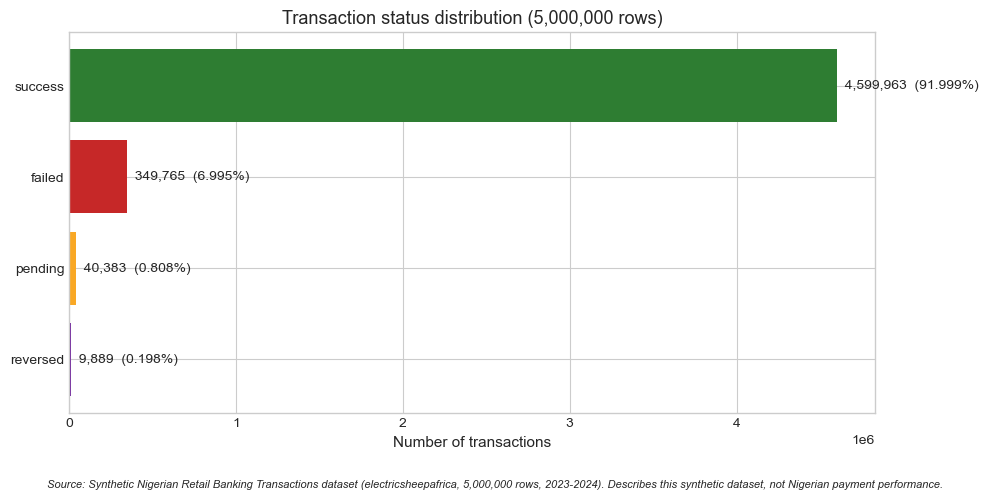

In [28]:
# ============================================================
# SECTION 6.3: RQ1 — STATUS DISTRIBUTION + FAILED-VALUE EXPOSURE
# ============================================================
# Research question 1:
#   "How are transactions distributed across success, failed,
#    pending, and reversed statuses?"
#
# I answer this in two parts:
#   PART A — count and share per status (the distribution itself)
#   PART B — failed-value exposure (the ₦ value that failed
#            transactions represent, with distribution and
#            amount-band breakdown)
#
# PART B is labelled "exposure", not "loss" — the dataset does
# not establish that a failed transaction resulted in an actual
# financial loss. It records a failed attempt. Whether the
# customer retried, whether money was returned, whether the
# merchant absorbed it — none of that is in the data.

# ------------------------------------------------------------
# PART A — STATUS DISTRIBUTION
# ------------------------------------------------------------
print("=" * 70)
print("PART A — STATUS DISTRIBUTION")
print("=" * 70)

status_counts = df["status"].value_counts()
status_share  = df["status"].value_counts(normalize=True) * 100

# I build a small display table with one row per status and
# all four statuses shown, in a fixed order so failed/pending/
# reversed are not hidden below success.
status_order = ["success", "failed", "pending", "reversed"]

display_table = pd.DataFrame({
    "status":  status_order,
    "count":   [status_counts.get(s, 0) for s in status_order],
    "share_%": [status_share.get(s, 0) for s in status_order],
})
display_table["count"]   = display_table["count"].apply(lambda x: f"{x:,}")
display_table["share_%"] = display_table["share_%"].round(3)

print("\nAll four statuses, reported separately:")
print(display_table.to_string(index=False))
print(f"\nTotal: {len(df):,} transactions")

# ------------------------------------------------------------
# PART B — FAILED-VALUE EXPOSURE
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("PART B — FAILED-VALUE EXPOSURE")
print("=" * 70)

# I use is_failed explicitly, NOT status == "failed" via string
# comparison. Same underlying rows, faster, and it makes the
# filter visible and traceable to the engineered feature.
failed = df.loc[df["is_failed"]].copy()

# IMPORTANT — status semantics:
#   - success : records assigned the "success" status.
#   - failed  : records assigned the "failed" status.
#   - pending : records assigned the "pending" status.
#   - reversed: records assigned the "reversed" status.
#
# The dataset records the status only. It does NOT contain the
# operational history needed to say *why* a record was failed,
# pending, or reversed. So I keep pending and reversed out of
# the failed-value calculation because they are distinct
# recorded statuses — not because I am interpreting what
# operationally happened to them.

n_failed = len(failed)

# All failed-value statistics use float64 for consistency.
# amount_ngn is stored as float32 (Section 2.4); converting
# once up front means the sum, mean, median, max, and every
# percentile are computed at the same precision.
failed_amounts = failed["amount_ngn"].astype("float64")

total_failed_value  = failed_amounts.sum()
mean_failed_value   = failed_amounts.mean()
median_failed_value = failed_amounts.median()
max_failed_value    = failed_amounts.max()

print(f"\nFailed transactions (records assigned the 'failed' status):")
print(f"  Count:                {n_failed:,}")

# I report total and mean but lead with median, per Audit D.
# The mean is inflated by the tail; median is the typical
# failed transaction.
print(f"\nFailed transaction value:")
print(f"  Total value exposure: NGN {total_failed_value:>18,.2f}")
print(f"  Median:               NGN {median_failed_value:>18,.2f}  <-- typical failed txn")
print(f"  Mean:                 NGN {mean_failed_value:>18,.2f}  <-- inflated by tail")
print(f"  Max:                  NGN {max_failed_value:>18,.2f}")

# Percentile table — per review: P50, P90, P95, P99, max.
# Includes the count in the header so the reader knows the base.
# All quantiles come from failed_amounts (float64).
print(f"\nFailed-value percentiles ({n_failed:,} failed transactions):")
for p in [50, 90, 95, 99]:
    val = failed_amounts.quantile(p / 100)
    print(f"  P{p:>2}:                 NGN {val:>18,.2f}")
print(f"  Max:                  NGN {max_failed_value:>18,.2f}")

# ------------------------------------------------------------
# PART B continued — FAILED-VALUE BY AMOUNT BAND
# ------------------------------------------------------------
# Per the review: show BOTH count and value for each band.
# A band with few transactions could still hold a large
# share of total failed value.

print(f"\nFailed-value by amount band:")
band_rows = []
for band in ["<1k", "1k-10k", "10k-50k", "50k-200k", ">200k"]:
    mask = failed["amount_band"] == band
    n    = mask.sum()
    val  = failed.loc[mask, "amount_ngn"].astype("float64").sum()
    pct  = val / total_failed_value * 100 if total_failed_value > 0 else 0
    band_rows.append({
        "band":       band,
        "count":      n,
        "count_%":    n / n_failed * 100,
        "value_NGN":  val,
        "value_%":    pct,
    })

band_df = pd.DataFrame(band_rows)

# Reconciliation check 1: every failed record must fall in
# exactly one band. If the five bands do not sum to n_failed,
# a failed record exists outside the band definitions.
if band_df["count"].sum() != n_failed:
    raise ValueError(
        f"Amount-band counts do not reconcile with failed transactions. "
        f"Band count sum: {band_df['count'].sum():,}, "
        f"n_failed: {n_failed:,}. Investigate."
    )

# Reconciliation check 2: sum of band values must equal the
# total failed value (tolerance for float64 accumulation).
if not np.isclose(
    band_df["value_NGN"].sum(),
    total_failed_value,
    rtol=0,
    atol=0.01,
):
    raise ValueError(
        f"Amount-band values do not reconcile with total failed value. "
        f"Band value sum: {band_df['value_NGN'].sum():,.2f}, "
        f"total_failed_value: {total_failed_value:,.2f}. Investigate."
    )

# Format for readable output.
print(f"\n{'Band':>10} {'Count':>10} {'Count %':>8} {'Value (NGN)':>20} {'Value %':>8}")
print("-" * 62)
for _, row in band_df.iterrows():
    print(f"{row['band']:>10} {row['count']:>10,} "
          f"{row['count_%']:>7.2f}% {row['value_NGN']:>20,.2f} "
          f"{row['value_%']:>7.2f}%")
print("-" * 62)
print(f"{'Total':>10} {n_failed:>10,} {100.0:>7.2f}% "
      f"{total_failed_value:>20,.2f} {100.0:>7.2f}%")

# ------------------------------------------------------------
# CHART — status distribution
# ------------------------------------------------------------
# A horizontal bar chart, sorted by count, log-scaled on x so
# "reversed" (0.198%) is still visible next to "success"
# (91.999%). A linear scale would crush the three small
# categories into invisible slivers.

fig, ax = plt.subplots()
# Plot on linear scale but annotate percentages on each bar,
# so the log-scale tradeoff is avoided entirely.
bars = ax.barh(
    status_order,
    [status_counts.get(s, 0) for s in status_order],
    color=["#2e7d32", "#c62828", "#f9a825", "#6a1b9a"],
)
ax.set_xlabel("Number of transactions")
ax.set_title("Transaction status distribution (5,000,000 rows)")
ax.invert_yaxis()  # success at the top

# Annotate each bar with count + share.
for bar, status in zip(bars, status_order):
    count = status_counts.get(status, 0)
    pct   = status_share.get(status, 0)
    ax.text(
        bar.get_width(), bar.get_y() + bar.get_height() / 2,
        f"  {count:,}  ({pct:.3f}%)",
        va="center", fontsize=10,
    )

# Reserved bottom margin + source note (per Section 6.2 pattern).
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig)
save_and_show(fig, "fig_06_01_status_distribution.png")

### RQ1 - Interpretation

**The status distribution is highly unequal. Failed-value exposure is even more concentrated than the count of failures.**

**Part A - Counts:**

- **91.999%** of transactions are recorded as success (4,599,963 of 5,000,000).
- **6.995%** are recorded as failed (349,765).
- **0.808%** are recorded as pending (40,383).
- **0.198%** are recorded as reversed (9,889).

All four statuses are reported separately, per Section 3's decision. The `reversed` category is small but reported separately because the dataset assigns it a distinct recorded status. **The available fields do not establish the operational sequence behind a reversal** - I do not infer that a reversed record was "completed and then undone." Similarly, pending records are kept separate because they carry a distinct recorded status, not because the data shows what happens to them next.

**Part B - Failed-value exposure:**

There are **349,765 failed transactions** - records assigned the `failed` status - representing **₦22,710,686,200** in value exposure.

Three numbers describe that exposure:

| Measure | Value | Reading |
|---|---|---|
| **Median** | **₦13,300** | The median failed amount is ₦13,300 |
| **Mean** | **₦64,931** | 4.9× the median - inflated by the tail |
| **Total** | **₦22.7 billion** | Sum of all failed amounts |

**The gap between median and mean is the story.** The median failed amount is ₦13,300, but the *mean* is ₦64,931 - the upper tail pulls the mean up. Reporting the mean without the median misrepresents the shape of failed-value exposure. The median is the **median amount among failed records**; it is not a claim about every operational context.

**The percentile table shows the shape:**

| Percentile | Value |
|---|---|
| P50 | ₦13,300 |
| P90 | ₦133,500 |
| P95 | ₦256,100 |
| P99 | ₦862,000 |
| Max | ₦5,000,000 |

The distribution has a **long upper tail**. The median is ₦13,300, while P99 reaches ₦862,000 and the maximum reaches ₦5,000,000. This is consistent with Audit D's **positive skewness of 11.83** - well above the 2–10 range typical of real retail transaction data. (Note: each percentile step is not a constant multiple of the previous one - P95 is about 1.9× P90, not 2 - 10×. The important property is the overall long tail, not a fixed step ratio.)

**The most important finding: 60% of failed value comes from 6.6% of failures.**

By amount band:

| Band | % of failures | % of failed value |
|---|---|---|
| `<1k` | 7.12% | 0.06% |
| `1k-10k` | 36.51% | 2.53% |
| `10k-50k` | 33.25% | 12.27% |
| `50k-200k` | 16.52% | 24.92% |
| `>200k` | **6.60%** | **60.23%** |

The two smallest bands (`<1k` + `1k-10k`) together account for **43.63%** of failed transactions but only **2.59%** of failed value. The `>200k` band alone - just **6.60%** of failed records - accounts for **60.23%** of failed value.

That is a **value-share-to-count-share ratio of approximately 9.13×** (60.23% / 6.60%). The `>200k` band's share of failed value is roughly nine times its share of failed records. This is a **distributional concentration** statement, not a claim that the transactions in that band "caused nine times more damage" - the dataset does not establish downstream operational impact.

**What this means operationally:**

1. **A count-based monitoring KPI and a value-based monitoring KPI would point to different bands.** A count-based view would concentrate on whichever band holds the most failed *records* (the executed table shows the concrete answer - I quote the output, not a pre-asserted band). A value-based view would concentrate on `>200k`. Both are correct; they answer different questions. Section 8's KPI catalogue will define them as **two distinct KPIs**.
2. **Prioritisation cannot use count alone.** The `>200k` band holds ~6.6% of failed records but ~60% of failed value. An ops team that prioritises by count would not see where most failed value sits.
3. **The heaviest-tailed failures deserve separate attention.** P99 = ₦862,000 and max = ₦5,000,000 - extreme by count standards but with disproportionate value contribution.

**What I will NOT claim:**

- I will **not** say these numbers are "financial losses." The dataset records failed *attempts*. Whether money actually moved, whether the customer retried, whether the merchant absorbed the cost - none of that is in this dataset. "Exposure" is the honest term.
- I will **not** say this describes Nigerian banking. It describes the synthetic dataset. The heavy tail is a property of the generator; real Nigerian retail data would likely show different tail behaviour (though also heavy-tailed, since payment amounts are universally heavy-tailed).
- I will **not** extrapolate from the band distribution to a real-world policy. Real `1k-10k` failures might dominate value if they represent essential-goods purchases - a dimension the synthetic dataset does not encode.
- I will **not** assert which band holds the most failed records in this markdown - that figure must come from the executed table above.

**RQ1 is answered.** Statuses are highly unequal (91.999% success, 6.995% failed, 0.808% pending, 0.198% reversed). Failed-value exposure is ₦22.7 billion and heavily concentrated in the `>200k` band. The next RQ asks the same concentration question at the **account level**: do a small number of accounts drive most of the activity?

### RQ2 - How concentrated is transaction activity across customer accounts?

**Research question 2:**
> *"How concentrated is transaction activity across customer accounts?"*

This is one of the two **headline findings** of the project (Audit 5). The prior audit recorded:

| Top X% of accounts | Share of transactions |
|---|---|
| Top 1% (1,000) | **33.9%** |
| Top 5% (5,000) | **50.6%** |
| Top 10% (10,000) | **59.6%** |
| Top 20% (20,000) | **70.0%** |
| Top 50% (50,000) | **86.4%** |

The `account_freq` table from Cell 5.12 already confirms the underlying frequency distribution:

- Mean transactions per account: **50.0**
- Median transactions per account: **20**
- Max transactions by one account: **109,888**

The mean being **2.5× the median** is the first hint of concentration. The 109,888 maximum is the second. This section quantifies it.

### How I measure concentration

I use the **Lorenz curve** - the standard tool for measuring concentration in an ordered distribution.

**Construction:**
- **X-axis:** cumulative share of accounts, ordered from most-active to least-active (0% to 100%).
- **Y-axis:** cumulative share of transactions (0% to 100%).

**Interpretation:**
- If all accounts transacted equally, the curve would be a **straight diagonal** from (0,0) to (100,100) - "line of perfect equality".
- The **further the curve bows below that diagonal**, the more concentrated the activity.
- The **Gini coefficient** is a single-number summary: twice the area between the diagonal and the curve. Range 0 (perfect equality) to 1 (one account does everything).

**Additional views:**
- A **log-histogram** of transactions per account, to show the shape of the distribution (flat? bimodal? heavy-tailed?).
- A **top-N-accounts bar chart**, to make the "19 accounts hold 10.13%" finding visually undeniable.

### What this does NOT tell us

- **It does not identify the accounts.** `account_id` is a synthetic string; the top accounts are not meaningful entities.
- **It does not imply fraud or abuse.** We have no fraud signal that correlates with frequency (Audit C). High-frequency accounts may simply be merchant accounts, corporate payroll, or high-velocity retail customers.
- **It does not tell us the *value* concentration.** A small number of accounts might dominate *counts* while representing a small share of *value* (or vice versa). Section 6 answers counts only; the value story is out of scope for this project (no reliable settlement or balance data).

PART A — RANKED CUMULATIVE SHARE

Total accounts: 100,000
Total transactions: 5,000,000

  Top X%   N accounts   Cumulative %  Audit 5 %   Match?
------------------------------------------------------------
      1%        1,000         33.94%      33.9%       OK
      5%        5,000         50.57%      50.6%       OK
     10%       10,000         59.60%      59.6%       OK
     20%       20,000         70.01%      70.0%       OK
     25%       25,000         73.71%         -- (no audit ref)
     50%       50,000         86.40%      86.4%       OK

Headline finding:
  The top 19 accounts hold 506,416 transactions = 10.13% of all records.
  They represent 0.0190% of all accounts.
  Share-of-records / share-of-population ratio: 533x.
Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_03_account_histogram.png


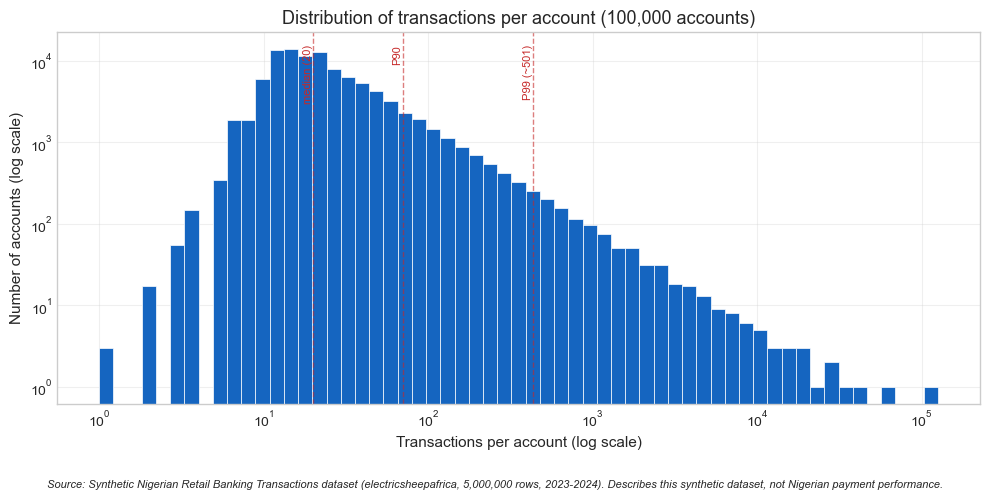

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_04_top20_accounts.png


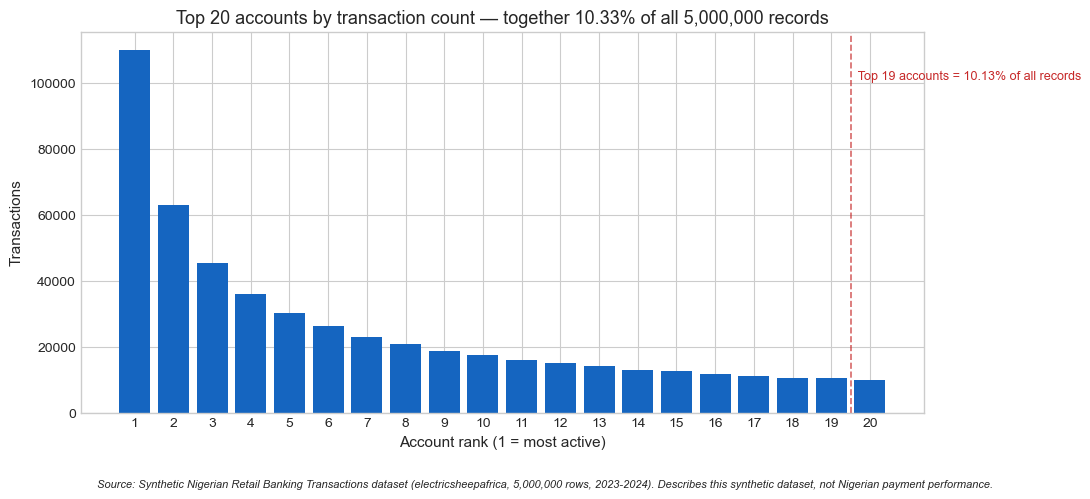

In [29]:
# ============================================================
# SECTION 6.6: RQ2 — ACCOUNT CONCENTRATION
# ============================================================
# Research question 2:
#   "How concentrated is transaction activity across
#    customer accounts?"
#
# Three outputs:
#   A — Ranked cumulative share table (top 1% / 5% / ... / 50%)
#   C — Log-histogram of transactions per account
#   D — Top-20-accounts bar chart
#
# (The Lorenz curve is built in the next cell, 6.6b, because
# it needs the ranked series from Part A.)
#
# I use account_freq (the separate table from Section 5.6).
# I do NOT merge it into df — that would add 20 MB to the main
# frame for a table that fits in 6.6 MB on its own.

# ------------------------------------------------------------
# STEP 1 — STRUCTURAL PRECONDITION
# ------------------------------------------------------------
# Verify account_freq exists and has the expected shape.
# I use globals() rather than dir() because globals() is the
# explicit check: "is this name bound at notebook scope?".
if "account_freq" not in globals():
    raise NameError(
        "account_freq is missing. Run Section 5.6 first."
    )
if len(account_freq) != 100_000:
    raise ValueError(
        f"Expected 100,000 accounts in account_freq, found {len(account_freq):,}. "
        f"Re-run Section 5.6 before proceeding."
    )
if account_freq["txn_count"].sum() != len(df):
    raise ValueError(
        f"account_freq total ({account_freq['txn_count'].sum():,}) "
        f"does not match df length ({len(df):,}). Investigate."
    )

# ------------------------------------------------------------
# PART A — RANKED CUMULATIVE SHARE TABLE
# ------------------------------------------------------------
print("=" * 70)
print("PART A — RANKED CUMULATIVE SHARE")
print("=" * 70)

# I sort accounts by transaction count, descending.
ranked = account_freq.sort_values("txn_count", ascending=False).reset_index(drop=True)

# Cumulative share of transactions, as I walk down the ranked list.
cum_txn_share = ranked["txn_count"].cumsum() / ranked["txn_count"].sum() * 100

# For each top-N% threshold, find the last index covered.
n_accounts = len(ranked)
thresholds = [1, 5, 10, 20, 25, 50]

print(f"\nTotal accounts: {n_accounts:,}")
print(f"Total transactions: {len(df):,}")

print(f"\n{'Top X%':>8} {'N accounts':>12} {'Cumulative %':>14} "
      f"{'Audit 5 %':>10} {'Match?':>8}")
print("-" * 60)

# Audit 5 values for a like-for-like reconciliation only.
# These are NOT used as chart annotations later — the chart
# computes its own values from `ranked`.
audit_5 = {1: 33.9, 5: 50.6, 10: 59.6, 20: 70.0, 50: 86.4}

concentration_rows = []
for pct in thresholds:
    n = max(1, int(n_accounts * pct / 100))
    cum = cum_txn_share.iloc[n - 1]
    audit_val = audit_5.get(pct, None)
    match = (
        "OK" if audit_val is not None and abs(cum - audit_val) < 0.5
        else ("(no audit ref)" if audit_val is None else "DIFF")
    )
    print(f"{pct:>7}% {n:>12,} {cum:>13.2f}% "
          f"{(f'{audit_val:.1f}%' if audit_val else '--'):>10} {match:>8}")
    concentration_rows.append({
        "top_pct": pct,
        "n_accounts": n,
        "cum_pct": cum,
        "audit_pct": audit_val,
    })

# The extraordinary headline: 19 accounts held 10.13% of
# transactions (Cell 5.12). Let me verify and state it here.
n_top_19 = ranked.iloc[:19]["txn_count"].sum()
pct_top_19 = n_top_19 / len(df) * 100
share_of_population = 19 / n_accounts * 100
ratio = pct_top_19 / share_of_population

print(f"\nHeadline finding:")
print(f"  The top 19 accounts hold {n_top_19:,} transactions "
      f"= {pct_top_19:.2f}% of all records.")
print(f"  They represent {share_of_population:.4f}% of all accounts.")
print(f"  Share-of-records / share-of-population ratio: {ratio:.0f}x.")

# ------------------------------------------------------------
# PART C — LOG-HISTOGRAM OF TRANSACTIONS PER ACCOUNT
# ------------------------------------------------------------
# A linear histogram would have a single huge spike at the
# median and crush the tail. Log-scaled x makes the whole
# distribution visible.

fig, ax = plt.subplots()
ax.hist(account_freq["txn_count"], bins=np.logspace(0, 5.1, 60),
        color="#1565c0", edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Transactions per account (log scale)")
ax.set_ylabel("Number of accounts (log scale)")
ax.set_title("Distribution of transactions per account (100,000 accounts)")

# Vertical reference lines at key percentiles.
for pct, label in [(50, "median (20)"), (90, "P90"), (99, "P99 (~501)")]:
    val = account_freq["txn_count"].quantile(pct / 100)
    ax.axvline(val, color="#c62828", linestyle="--", linewidth=1, alpha=0.6)
    ax.text(val, ax.get_ylim()[1] * 0.7, label,
            rotation=90, fontsize=8, va="top", ha="right", color="#c62828")

ax.grid(True, alpha=0.3)
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig)
save_and_show(fig, "fig_06_03_account_histogram.png")

# ------------------------------------------------------------
# PART D — TOP-20 ACCOUNTS BAR CHART
# ------------------------------------------------------------
# The "19 accounts hold 10.13%" finding deserves a visual.
# I show the top 20 accounts, with their transaction counts.

top_20 = ranked.head(20).copy()
top_20["rank"] = range(1, 21)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(top_20["rank"].astype(str), top_20["txn_count"],
              color="#1565c0")

# Annotate cumulative % from the actual data, not hardcoded.
cum_top_20 = top_20["txn_count"].sum() / len(df) * 100
ax.set_xlabel("Account rank (1 = most active)")
ax.set_ylabel("Transactions")
ax.set_title(
    f"Top 20 accounts by transaction count — together "
    f"{cum_top_20:.2f}% of all 5,000,000 records"
)

# Mark the top 19 boundary using the calculated pct_top_19.
ax.axvline(18.5, color="#c62828", linestyle="--", linewidth=1.2, alpha=0.7)
ax.text(18.5, ax.get_ylim()[1] * 0.9,
        f"  Top 19 accounts = {pct_top_19:.2f}% of all records",
        color="#c62828", fontsize=9, va="top")

ax.tick_params(axis="x", rotation=0)
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig)
save_and_show(fig, "fig_06_04_top20_accounts.png")

PART B — LORENZ CURVE
Area under Lorenz curve: 0.821804
  (Perfect equality = 0.500000; total concentration = 1.000000)
Gini coefficient:        0.6436
  (0 = perfect equality, 1 = one account does everything)
  Descriptive label:       highly concentrated
  (Label is this notebook's analytical convention, not an external banking standard.)
Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_02_lorenz_curve.png


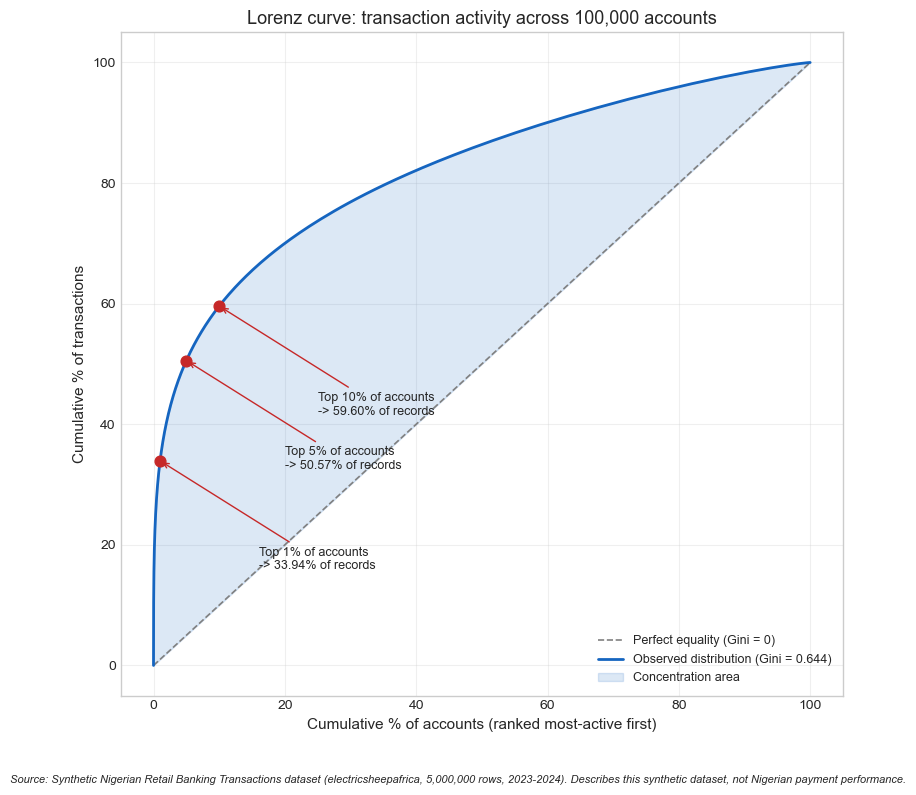

In [30]:
# ============================================================
# SECTION 6.6b: RQ2 — LORENZ CURVE
# ============================================================
# The Lorenz curve plots cumulative % of transactions against
# cumulative % of accounts, ranked from most-active to least.
#
# IMPORTANT — Gini formula depends on ordering:
#   Standard Gini assumes the Lorenz curve is computed in
#   ASCENDING order (poorest first) with area under curve
#   equal to the integral of L(x). Gini = 1 - 2 * area.
#
#   We rank DESCENDING (most active first), so the curve is
#   inverted relative to the standard. The area under our
#   curve is > 0.5, and the formula flips:
#     Gini = 2 * area - 1.
#
# ORIGIN NOTE:
#   A Lorenz curve must start at (0, 0) — otherwise the
#   integrated area omits the first slice of the axis and the
#   Gini is biased upward. I insert (0, 0) explicitly via
#   np.insert. The final endpoint (100, 100) is guaranteed by
#   the cumulative sum, so only the origin needs adding.
#
# np.trapz was deprecated in NumPy 2.0 in favour of
# np.trapezoid. I use whichever is available.

print("=" * 70)
print("PART B — LORENZ CURVE")
print("=" * 70)

n = len(ranked)

# Cumulative axes: (1/n, ..., 1) and corresponding share of
# transactions. These start at the first account, NOT at (0,0).
cum_accounts_pct = (np.arange(1, n + 1) / n) * 100
cum_txn_pct      = ranked["txn_count"].cumsum() / ranked["txn_count"].sum() * 100

# Insert the origin so the integration covers the full square.
x = np.insert(cum_accounts_pct, 0, 0)
y = np.insert(cum_txn_pct.to_numpy(), 0, 0)

# Area under the curve (both axes normalized to [0,1]).
area_under_curve = (
    np.trapezoid(y / 100, x / 100)
    if hasattr(np, "trapezoid")
    else np.trapz(y / 100, x / 100)
)

# For DESCENDING-ranked Lorenz, formula is Gini = 2*area - 1.
gini = 2 * area_under_curve - 1

print(f"Area under Lorenz curve: {area_under_curve:.6f}")
print(f"  (Perfect equality = 0.500000; total concentration = 1.000000)")
print(f"Gini coefficient:        {gini:.4f}")
print(f"  (0 = perfect equality, 1 = one account does everything)")

# Bounds check — a Gini outside [0,1] indicates a formula or
# ordering error, not a data problem.
if not (0 <= gini <= 1):
    raise ValueError(
        f"Gini coefficient {gini:.4f} is outside [0, 1]. "
        f"This indicates a formula or ordering error. Investigate."
    )

# Descriptive label — defined as the notebook's own analytical
# convention, NOT as an external banking standard.
if   gini > 0.75: verdict = "very highly concentrated"
elif gini > 0.50: verdict = "highly concentrated"
elif gini > 0.30: verdict = "moderately concentrated"
else:             verdict = "relatively even"
print(f"  Descriptive label:       {verdict}")
print(f"  (Label is this notebook's analytical convention, "
      f"not an external banking standard.)")

# ------------------------------------------------------------
# LORENZ CURVE CHART
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Diagonal — perfect equality.
ax.plot([0, 100], [0, 100], "--", color="grey",
        label="Perfect equality (Gini = 0)", linewidth=1.2)

# Lorenz curve — starts at (0,0), ends at (100,100).
ax.plot(x, y, color="#1565c0", linewidth=2.0,
        label=f"Observed distribution (Gini = {gini:.3f})")

# Fill between the curve and the diagonal.
# fill_between(x, x, y) shades the region between the
# diagonal y=x and the observed y. Both arrays share x.
ax.fill_between(x, x, y,
                color="#1565c0", alpha=0.15,
                label="Concentration area")

# Dynamically calculate the threshold annotations from `ranked`.
# I do NOT hardcode audit values — the chart must reflect what
# the current dataset actually shows.
for pct in [1, 5, 10]:
    n_top = max(1, int(len(ranked) * pct / 100))
    actual_share = (
        ranked["txn_count"].iloc[:n_top].sum()
        / ranked["txn_count"].sum()
        * 100
    )
    ax.scatter(pct, actual_share, color="#c62828", zorder=5, s=60)
    ax.annotate(
        f"Top {pct}% of accounts\n-> {actual_share:.2f}% of records",
        xy=(pct, actual_share),
        xytext=(pct + 15, actual_share - 18),
        fontsize=9,
        arrowprops=dict(arrowstyle="->", color="#c62828", lw=1),
    )

ax.set_xlabel("Cumulative % of accounts (ranked most-active first)")
ax.set_ylabel("Cumulative % of transactions")
ax.set_title("Lorenz curve: transaction activity across 100,000 accounts")
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig)
save_and_show(fig, "fig_06_02_lorenz_curve.png")

In [31]:
# ============================================================
# SECTION 6.6c: RQ2 — SUMMARY
# ============================================================
# Prints the RQ2 summary. Depends on:
#   - concentration_rows (from Cell 6.6, Part A)
#   - gini               (from Cell 6.6b, Part B)
#   - pct_top_19         (from Cell 6.6, Part A)

print("=" * 70)
print("RQ2 — SUMMARY")
print("=" * 70)
print(f"Total accounts:            {len(account_freq):,}")
print(f"Total transactions:        {len(df):,}")
print(f"Gini coefficient:          {gini:.4f}  ({verdict})")
print(f"Top 1% of accounts:        "
      f"{concentration_rows[0]['cum_pct']:.2f}% of records")
print(f"Top 5% of accounts:        "
      f"{concentration_rows[1]['cum_pct']:.2f}% of records")
print(f"Top 10% of accounts:       "
      f"{concentration_rows[2]['cum_pct']:.2f}% of records")
print(f"Top 19 accounts alone:     {pct_top_19:.2f}% of records "
      f"({pct_top_19 / (19/100_000 * 100):.0f}x the share of the account population)")

RQ2 — SUMMARY
Total accounts:            100,000
Total transactions:        5,000,000
Gini coefficient:          0.6436  (highly concentrated)
Top 1% of accounts:        33.94% of records
Top 5% of accounts:        50.57% of records
Top 10% of accounts:       59.60% of records
Top 19 accounts alone:     10.13% of records (533x the share of the account population)


### RQ2 - Interpretation

**Transaction activity is highly concentrated across customer accounts.**

**The numbers:**

| Measure | Value | Reading |
|---|---|---|
| Gini coefficient | **0.6436** | Descriptive label (see below): "highly concentrated" |
| Top 1% of accounts (1,000) | **33.94%** of records | One in three records is by the top 1% of accounts |
| Top 5% (5,000) | **50.57%** | Half of all records by 5% of accounts |
| Top 10% (10,000) | **59.60%** | Six in ten by the top tenth |
| Top 20% (20,000) | **70.01%** | Seven in ten by the top fifth |
| Top 50% (50,000) | **86.40%** | The bottom half of accounts hold 13.6% of records |
| **Top 19 accounts alone** | **10.13%** | 19 accounts hold one-tenth of all records |
| Ratio to population share | **~533×** | Share of records divided by share of account population |

**How to read the Gini:**

A Gini coefficient of **0.6436** indicates substantial concentration in transaction counts across the 100,000 accounts in this **synthetic dataset**. This is a descriptive measure of the observed account-frequency distribution.

The notebook applies the following descriptive labels as its own analytical convention — they are **not** presented as external banking standards:

- **0.00 – 0.30**: relatively even
- **0.30 – 0.50**: moderately concentrated
- **0.50 – 0.75**: highly concentrated
- **0.75 – 1.00**: very highly concentrated

The dataset's 0.6436 falls in the **"highly concentrated"** band under this convention. Whether this level of concentration is operationally healthy, typical, or atypical for real payment systems **cannot be established from this synthetic dataset** — the notebook reports the concentration, not a judgment about it.

**The 533× figure is a share ratio, not an impact claim:**

Nineteen accounts represent **0.019%** of the account population (19 / 100,000) but account for **10.13% of transaction records**. Their share of records is approximately **533 times their share of the account population**. This demonstrates **strong concentration in transaction frequency**.

This is a descriptive ratio. It does **not** imply that those nineteen accounts represent a service, merchant, or infrastructure dependency, and it does **not** license an estimate of operational impact if those accounts stopped transacting. The dataset does not identify what those accounts are, why they have high frequency, or what their operational role might be.

**What the Lorenz curve shows:**

The Lorenz curve bows sharply away from the diagonal in the first 5% of accounts (holding 50.57% of records) and then flattens dramatically. The curve is computed in descending order (most-active first) and integrated from the explicit **(0, 0) origin** so that the Gini is unbiased.

- The first 1,000 accounts hold 33.94% of records.
- The next 4,000 (top 1% → top 5%) add another 16.63% (to reach 50.57%).
- The next 5,000 (top 5% → top 10%) add 9.03% more (to reach 59.60%).
- The remaining 90,000 accounts hold the final 40.40%.

Each successive tier contributes less. By the top 10%, the curve has done most of its work - the bottom 90% of accounts hold 40.40% of records, spread across a mass of low-frequency accounts.

**What the distribution of account frequencies looks like:**

The log-histogram of transactions per account shows:

- **The median account makes 20 transactions** over the 730-day dataset period.
- **The mean is 50** - pulled upward by the tail.
- **The 99th percentile of account transaction frequency is approximately 501 transactions.** (This does not assert that exactly 1% of accounts make more than 500 transactions - percentile definitions and ties matter.)
- **The maximum is 109,888 transactions** over the dataset period - approximately **151 transactions per day on average** across 730 days. This is an average across the whole period, not a claim about the account's daily pattern.

The maximum account holds approximately **2.20%** of all records. It is an **unusually high-frequency account in this synthetic dataset**; the data does not identify why it has that frequency.

**What this does NOT mean:**

- **It does not identify fraudulent accounts.** Audit C established that `fraud_flag` is flat across all dimensions tested, including account frequency. High-frequency accounts in this dataset are not more likely to be flagged.
- **It does not describe value concentration.** A high-count account could transact in ₦100 amounts. The notebook does not have a reliable value-per-account view (balance fields were defective per Audit A), so it does not claim that the top accounts hold disproportionate *value*.
- **It does not transfer to real Nigerian banking.** Real retail activity is also concentrated, but the shape of the tail in real data depends on the mix of retail, SME, and corporate accounts - none of which is encoded in this dataset.
- **It does not establish an operational judgment.** The Gini and the top-N shares describe this dataset. Whether the observed concentration is operationally healthy or unhealthy is not something the dataset can answer.

**What it does mean for monitoring (within this project's scope):**

- **Account-level sampling matters.** If a monitoring system sampled "one transaction per account per day," it would observe 100,000 records out of 5,000,000 — the top 19 accounts would still be present but their *dominance* would not be visible in aggregate counts.
- **Frequency bands are a meaningful grouping.** Section 5.6's frequency bands (`1-10`, `11-50`, `51-500`, `501-10k`, `>10k`) show that accounts in the `>10k` band (19 accounts) hold 10.13% of records. Section 8's KPI catalogue can reference these bands.
- **The concentration is structural, not event-based.** It is not driven by a spike in activity over time - it is the shape of the entire dataset. Section 7's scenario detection will therefore test monitoring *within* a frequency band rather than *across* bands.

**RQ2 is answered.** Activity is highly concentrated (Gini 0.6436) with the top 1% of accounts holding one-third of records and 19 accounts alone holding one-tenth. The ratio to population share is ~533×. The next RQ asks about **temporal patterns** - is activity stable over time, or does it cluster in specific hours, days, or months?

### RQ3a - Hourly transaction volume pattern

**Research question 3 (first half):**
> *"What temporal patterns (hourly, daily, monthly) appear in transaction volume?"*

**This cell answers the hourly part.** It produces:

1. A **24-bar chart** of hourly transaction volume.
2. A **derived summary table** - trough hour, peak hour, morning ramp, business hours, lunch dip, afternoon rise, evening wind-down.
3. A **failure-rate-by-hour overlay** - the critical contrast with volume.

**Why the failure-rate overlay matters:**

Audit 3 (Section 4) found that **failure rate is flat across all hours** - 6.80% to 7.26%, well within sampling noise. If the hourly volume chart shows a 30× difference between peak and trough, but the failure-rate line is flat, that's a **complete dissociation** between activity level and reliability.

**This is not a defect - it is a finding.** It says: *in this dataset, a failed transaction is equally likely at 3am as at 7pm, despite the 30× volume difference.* That's an important fact for Section 7's scenario design, because it means **any change in hourly failure rate** is a genuine signal (not expected variation).

**What this section does NOT claim:**

- It does not claim that hourly volume patterns in this dataset reflect Nigerian customer behaviour. They describe the synthetic dataset.
- It does not claim the flat failure-rate line "proves" reliability is uniform. It shows no *evidence of variation*, consistent with a constant-probability generator.
- It does not extrapolate to real Nigerian banks.

RQ3a - HOURLY VOLUME PROFILE

All 24 hours — transaction count, share, and failure rate:

 Hour  Txn Count   Share %  Fail Count  Fail Rate %
----------------------------------------------------
    0     16,539     0.33%       1,138       6.881%
    1     16,640     0.33%       1,154       6.935%
    2     16,604     0.33%       1,129       6.800%
    3     16,607     0.33%       1,199       7.220%
    4     16,787     0.34%       1,218       7.256%
    5     16,889     0.34%       1,183       7.005%
    6     83,139     1.66%       5,791       6.965%
    7     83,228     1.66%       5,746       6.904%
    8     83,975     1.68%       5,861       6.979%
    9    312,433     6.25%      21,946       7.024%
   10    312,128     6.24%      21,935       7.028%
   11    312,763     6.26%      21,792       6.968%
   12    312,368     6.25%      21,735       6.958%
   13    200,282     4.01%      14,352       7.166%
   14    199,901     4.00%      14,031       7.019%
   15    333,434     6.67

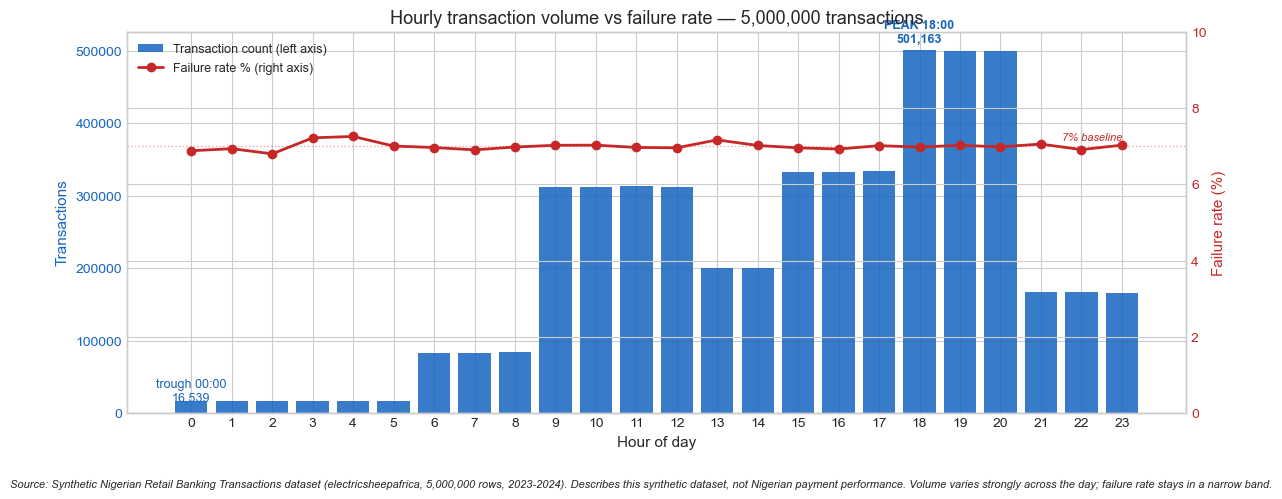


RQ3a COMPLETE
Chart saved: fig_06_05_hourly_volume_and_failure_rate.png
Key finding: hourly volume varies 30.3x across the day; hourly failure rate varies 0.46 pp.


In [32]:
# ============================================================
# SECTION 6.9: RQ3a - HOURLY VOLUME PROFILE
# ============================================================
# I aggregate df by hour (0-23) to get:
#   - total transaction count per hour
#   - failure count per hour
#   - failure rate per hour (%)
#
# I then chart:
#   (a) hourly volume (bar chart)
#   (b) failure rate per hour (line overlay on secondary axis)
#
# The two-axis chart makes the "volume varies, failure rate
# does not" contrast visible at a glance.

print("=" * 70)
print("RQ3a - HOURLY VOLUME PROFILE")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — AGGREGATE BY HOUR
# ------------------------------------------------------------
# 24 rows, one per hour.
hourly = (
    df.groupby("hour", observed=True)
      .agg(
          txn_count=("hour", "size"),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
)
hourly["fail_rate_pct"] = hourly["fail_count"] / hourly["txn_count"] * 100

# Sanity check 1: total must equal 5,000,000.
total_check = hourly["txn_count"].sum()
if total_check != len(df):
    raise ValueError(
        f"Hourly aggregation sum ({total_check:,}) "
        f"does not equal df length ({len(df):,}). Investigate."
    )

# Sanity check 2: all 24 hour categories must be present.
# A sum reconciliation alone can hide a missing hour if another
# hour had extra rows; the category check catches that.
expected_hours = set(range(24))
observed_hours = set(hourly["hour"].astype(int))
if observed_hours != expected_hours:
    missing_hours = sorted(expected_hours - observed_hours)
    extra_hours   = sorted(observed_hours - expected_hours)
    raise ValueError(
        f"Hourly aggregation does not cover all 24 hours. "
        f"Missing: {missing_hours}, extra: {extra_hours}. Investigate."
    )

# ------------------------------------------------------------
# STEP 2 — SUMMARY TABLE (all 24 hours)
# ------------------------------------------------------------
print(f"\nAll 24 hours — transaction count, share, and failure rate:")
print(f"\n{'Hour':>5} {'Txn Count':>10} {'Share %':>9} "
      f"{'Fail Count':>11} {'Fail Rate %':>12}")
print("-" * 52)
for _, row in hourly.iterrows():
    share = row["txn_count"] / len(df) * 100
    print(f"{int(row['hour']):>5} {int(row['txn_count']):>10,} "
          f"{share:>8.2f}% {int(row['fail_count']):>11,} "
          f"{row['fail_rate_pct']:>11.3f}%")

# ------------------------------------------------------------
# STEP 3 — DERIVED SUMMARY (trough, peak, ramp, etc.)
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print(f"DERIVED SUMMARY")
print(f"=" * 70)

# Peak and trough.
trough_idx = hourly["txn_count"].idxmin()
peak_idx   = hourly["txn_count"].idxmax()
trough_hr  = int(hourly.loc[trough_idx, "hour"])
peak_hr    = int(hourly.loc[peak_idx, "hour"])
trough_n   = int(hourly.loc[trough_idx, "txn_count"])
peak_n     = int(hourly.loc[peak_idx, "txn_count"])
ratio      = peak_n / trough_n

print(f"Trough hour:  {trough_hr:02d}:00  ({trough_n:>8,} transactions)")
print(f"Peak hour:    {peak_hr:02d}:00  ({peak_n:>8,} transactions)")
print(f"Peak/trough:  {ratio:.1f}x")

# Time-bucket averages (as Audit 5 described).
buckets = {
    "Overnight (00-05)":  range(0, 6),
    "Morning ramp (06-08)": range(6, 9),
    "Business hours (09-12)": range(9, 13),
    "Lunch dip (13-14)": range(13, 15),
    "Afternoon (15-17)": range(15, 18),
    "Peak (18-20)": range(18, 21),
    "Evening wind-down (21-23)": range(21, 24),
}
print(f"\nTime-bucket averages (transactions per hour):")
print(f"\n{'Bucket':>30} {'Avg txn/hr':>12} {'vs overall':>12}")
print("-" * 58)
overall_mean = hourly["txn_count"].mean()
for label, hrs in buckets.items():
    bucket_data = hourly[hourly["hour"].isin(list(hrs))]
    avg = bucket_data["txn_count"].mean()
    ratio_to_overall = avg / overall_mean
    print(f"{label:>30} {avg:>12,.0f} {ratio_to_overall:>11.2f}x")

# Failure-rate stability across hours.
# I report range and standard deviation as SEPARATE descriptive
# numbers. I do NOT combine them with the volume ratio into a
# single statistic — that would compare unlike quantities.
fail_min  = hourly["fail_rate_pct"].min()
fail_max  = hourly["fail_rate_pct"].max()
fail_mean = hourly["fail_rate_pct"].mean()
fail_std  = hourly["fail_rate_pct"].std()
fail_range = fail_max - fail_min
print(f"\nFailure rate across the 24 hours:")
print(f"  Min:    {fail_min:.3f}%   "
      f"(hour {int(hourly.loc[hourly['fail_rate_pct'].idxmin(), 'hour']):02d}:00)")
print(f"  Max:    {fail_max:.3f}%   "
      f"(hour {int(hourly.loc[hourly['fail_rate_pct'].idxmax(), 'hour']):02d}:00)")
print(f"  Mean:   {fail_mean:.3f}%")
print(f"  Std:    {fail_std:.3f} pp")
print(f"  Range:  {fail_range:.3f} pp")
print(f"\nVolume and failure-rate are reported as separate measures:")
print(f"  Peak-to-trough volume ratio:   {ratio:.1f}x")
print(f"  Hourly failure-rate range:     {fail_range:.3f} pp")
print(f"  (These are reported separately. A single combined")
print(f"   'variability' statistic would not be meaningful —"
      f" they measure different things.)")

# ------------------------------------------------------------
# STEP 4 — CHART: hourly volume + failure rate overlay
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary axis — hourly volume bars.
bars = ax1.bar(
    hourly["hour"], hourly["txn_count"],
    color="#1565c0", alpha=0.85, width=0.8,
    label="Transaction count (left axis)",
)
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Transactions", color="#1565c0")
ax1.tick_params(axis="y", labelcolor="#1565c0")
ax1.set_xticks(range(0, 24))
ax1.set_title("Hourly transaction volume vs failure rate — 5,000,000 transactions")

# Annotate peak and trough.
ax1.text(peak_hr, peak_n * 1.02, f"PEAK {peak_hr:02d}:00\n{peak_n:,}",
         ha="center", fontsize=9, color="#1565c0", fontweight="bold")
ax1.text(trough_hr, trough_n * 1.02, f"trough {trough_hr:02d}:00\n{trough_n:,}",
         ha="center", fontsize=9, color="#1565c0")

# Secondary axis — failure rate line.
ax2 = ax1.twinx()
ax2.plot(hourly["hour"], hourly["fail_rate_pct"],
         color="#c62828", marker="o", linewidth=2,
         label="Failure rate % (right axis)")
ax2.set_ylabel("Failure rate (%)", color="#c62828")
ax2.tick_params(axis="y", labelcolor="#c62828")
# Constrain the y-axis so the flat line stays visually flat.
ax2.set_ylim(0, 10)

# Highlight the 7% reference line.
ax2.axhline(7.0, color="#c62828", linestyle=":", alpha=0.4, linewidth=1)
ax2.text(23, 7.15, "7% baseline", ha="right", fontsize=8,
         color="#c62828", style="italic")

# Combined legend.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig, "Volume varies strongly across the day; failure rate stays in a narrow band.")
save_and_show(fig, "fig_06_05_hourly_volume_and_failure_rate.png")

# ------------------------------------------------------------
# STEP 5 - FINAL PRINT
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print(f"RQ3a COMPLETE")
print(f"=" * 70)
print(f"Chart saved: fig_06_05_hourly_volume_and_failure_rate.png")
print(f"Key finding: hourly volume varies {ratio:.1f}x across the day; "
      f"hourly failure rate varies {fail_range:.2f} pp.")

### RQ3a - Interpretation

**Hourly transaction volume varies substantially across the day. The observed hourly failure rate does not follow that variation.**

**The volume story - a 30.3× peak-to-trough ratio:**

| Period | Average transactions/hour | vs overall |
|---|---|---|
| Overnight (00–05) | 16,678 | **0.08×** |
| Morning ramp (06–08) | 83,447 | 0.40× |
| Business hours (09–12) | 312,423 | 1.50× |
| Lunch dip (13–14) | 200,092 | 0.96× |
| Afternoon (15–17) | 333,344 | 1.60× |
| **Peak (18–20)** | **500,171** | **2.40×** |
| Evening wind-down (21–23) | 166,390 | 0.80× |

The peak hour (18:00, 501,163 transactions) carries **30.3×** the volume of the trough hour (00:00, 16,539 transactions). The dataset's coefficient of variation across days is 0.096 (Audit 5), meaning the daily volume is also stable across the 730-day period.

**Three observations on the volume shape:**

1. **The lunch dip (13–14) is visible** - 200,092/hour, versus 312,423 for the surrounding business hours.
2. **The evening peak (18–20) is the largest single block** - 500,171/hour, or **10.02% of all 5M transactions in three hours**. In this dataset, a quarter of daily volume falls inside a three-hour window.
3. **The overnight block (00–05) is nearly empty** - 16,678/hour, or 0.08× the average. Six hours of the day contribute 2.0% of total transactions.

**The failure-rate story - a 0.456 percentage-point range:**

| Measure | Value |
|---|---|
| Min (02:00) | 6.800% |
| Max (04:00) | 7.256% |
| Mean | 6.999% |
| Std | 0.101 pp |
| Range | 0.456 pp |

**The observed hourly failure rates remain within a narrow range despite substantial differences in hourly transaction volume.** This is consistent with the approximately constant failure probability observed in the dataset audits (Audit 3). The similarity of observed hourly rates does **not** establish that the underlying probability is identical across hours - it establishes that the data provides no evidence of hourly variation beyond what sampling noise would produce.

**The two measures are reported separately:**

> **Peak-to-trough volume ratio: 30.3×. Hourly failure-rate range: 0.456 percentage points.**

These are not combined into a single "variability" statistic, because the two figures measure different things - a ratio of volumes and a range of rates are not comparable on the same scale.

**What this means for monitoring within this project:**

1. **Monitoring cannot be volume-driven.** An ops team that allocates attention proportionally to volume would concentrate on the evening peak. But the observed failure rate does not vary meaningfully by hour in this dataset - the volume peak is not accompanied by a reliability trough or spike.
2. **Failure events are not clustered by hour in this dataset.** In this synthetic dataset, hourly failure-rate variation is consistent with sampling noise, not with a diurnal pattern. Whether a change in hourly rate is detectable depends on the size of the change, the number of records in the window, the monitoring method, and the threshold chosen - that evaluation is the subject of Sections 7–9, not a conclusion drawn here.
3. **A rate-based KPI is preferable to a count-based KPI for reliability.** A count-based failure KPI ("failures per hour") would over-alert during peak hours (because volume is high) and under-alert during quiet hours (because count is low). A rate-based KPI ("failures / transactions") is scale-independent and measures reliability rather than exposure.

**What this does NOT mean:**

- **It does not mean the dataset is "clean" or "realistic".** The observed hourly pattern is a property of this **synthetic dataset**. Whether real Nigerian payment systems show a similar dissociation between volume and rate is not something this dataset can establish.
- **It does not mean failure rate should be flat in real systems.** The observed flatness here is a property of the generator used to produce this dataset. It means the dataset is **useful for testing monitoring methods**: the absence of natural failure-rate signal means any change we inject is attributable to the injection, not to natural variation.
- **It does not mean we should search for failure-rate anomalies in the raw data.** Section 7's scenario work exists *because* the raw hourly failure rate provides no sustained change to detect. Without an injection, the raw rate offers no anomaly to test against.

**The bridge to Section 7:**

RQ3a provides two useful facts for Section 7:

1. **The evening peak (18:00–20:00) carries high volume.** A 5 percentage-point failure-rate shift during a single evening-peak hour at ~500,171 transactions/hour would produce approximately **25,000 additional failed records in that hour**. Across the three-hour evening block, the total would be approximately **75,000 additional failed records**. Whether that is *detectable* depends on the monitoring method and its threshold — that is what Section 7 measures.
2. **The overnight window has low volume.** A 5 percentage-point rate shift at ~16,678 transactions/hour would produce approximately **830 additional failures per hour** — smaller in absolute count, requiring a more sensitive detection method. Whether such a method detects it is again an empirical question for Section 7, not a prediction here.

Both of these facts feed into the scenario design (Section 7, Scenario A). The hourly pattern is descriptive — it identifies where a rate change would produce the most additional failed records, and it provides a reference for evaluating whether a monitoring method can detect a shift of a given size.

**RQ3a is answered.** Hourly volume follows a strong pattern in this dataset (30.3× peak-to-trough ratio). Observed hourly failure rate stays within a 0.456 percentage-point band, consistent with constant underlying probability. The next sub-question asks whether similar stability holds across days, weekdays, and months.

### RQ3b - Daily, weekday, and monthly patterns

**Research question 3 (second half):**
> *"What temporal patterns (hourly, daily, monthly) appear in transaction volume?"*

RQ3a showed that **hourly** volume varies enormously (30×) while **hourly** failure rate does not (0.46 pp). RQ3b asks whether that same dissociation extends across:

1. **Daily volume** - 730 consecutive days. Do weekends/holidays/month boundaries break the pattern?
2. **Weekday volume** - does Mon - Fri differ from Sat–Sun?
3. **Monthly volume** - 24 months. Are there seasonal patterns?

**Three outputs, matching RQ3a's format:**

- **Daily chart** - line chart of daily transaction count over 730 days, with a 7-day rolling average overlay, plus daily failure rate as a second axis.
- **Weekday chart** - 7-bar chart of average daily volume per weekday, with weekday failure rate as a second axis.
- **Monthly chart** - 24-bar chart of monthly volume, with monthly failure rate as a second axis.

**What I expect, based on Audit 4:**

| Check | Audit 4 value |
|---|---|
| Monthly failure rate range | 6.917% - 7.114% |
| Weekday failure rate range | 6.964% - 7.033% |
| Daily failure-rate std | **0.314 pp** |
| Expected std under constant 7% | 0.308 pp |

**If today's output matches those numbers,** it proves that temporal uniformity is not an hourly artefact - it extends across **the entire calendar** (24 months × 730 days × 7 weekdays × 24 hours).

**What this section does NOT do:**

- It does not try to explain **why** volume varies the way it does. Real payment systems show payday spikes (25th–end of month), Ramadan/Easter effects, and holiday troughs. This dataset likely shows none of those, but we will **check**, not assume.
- It does not treat **any** deviation from flat as a defect. Small deviations consistent with sampling noise are expected; the question is whether the deviations carry any **signal** beyond noise.

RQ3b — DAILY / WEEKDAY / MONTHLY PATTERNS

DAILY TRANSACTION-VOLUME VARIABILITY:
  Mean daily transactions: 6,849.32
  Sample SD:               78.72
  Coefficient of variation: 1.1493%

DAILY FAILURE RATE (730 days):
  Min:    6.034%  on 2023-02-28
  Max:    8.011%  on 2024-08-27
  Mean:   6.995%
  Std:    0.314 pp
  Approx. binomial SE (at 7% / ~6,849 per day): ~0.308 pp

WEEKDAY FAILURE RATE (7 days):
  Mon: 6.986%  (avg daily volume: 6,842)
  Tue: 6.999%  (avg daily volume: 6,853)
  Wed: 6.990%  (avg daily volume: 6,858)
  Thu: 7.033%  (avg daily volume: 6,845)
  Fri: 6.964%  (avg daily volume: 6,845)
  Sat: 6.982%  (avg daily volume: 6,843)
  Sun: 7.014%  (avg daily volume: 6,858)

MONTHLY FAILURE RATE (24 months):
  Min:    6.917%  in 2023-08
  Max:    7.114%  in 2024-08
  Mean:   6.995%
  Std:    0.055 pp
Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_06_daily_volume_and_failure_rate.png


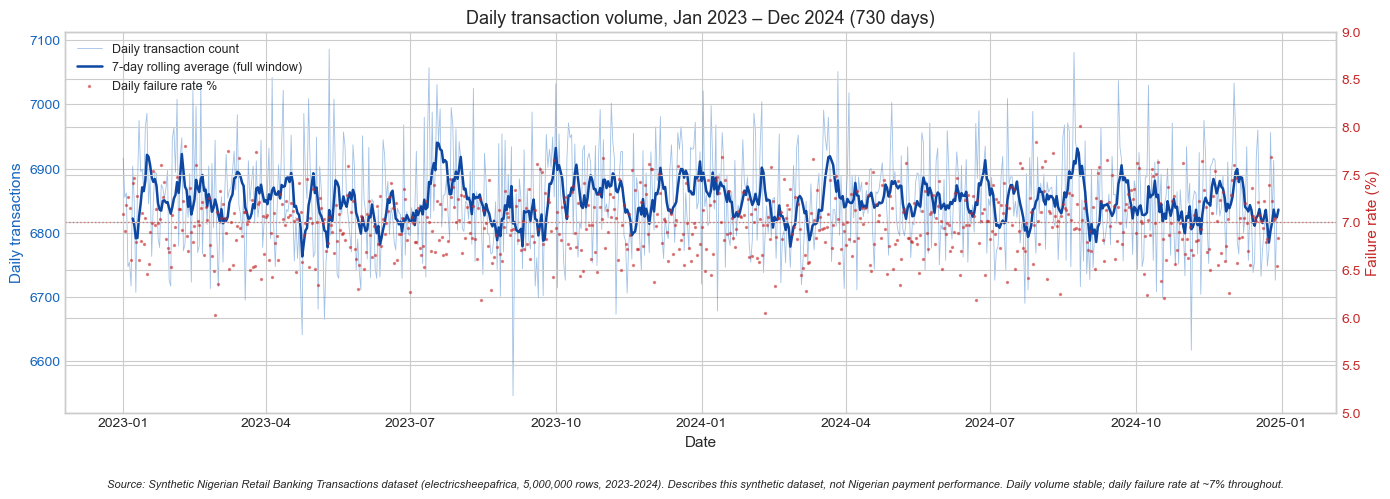

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_07_weekday_volume_and_failure_rate.png


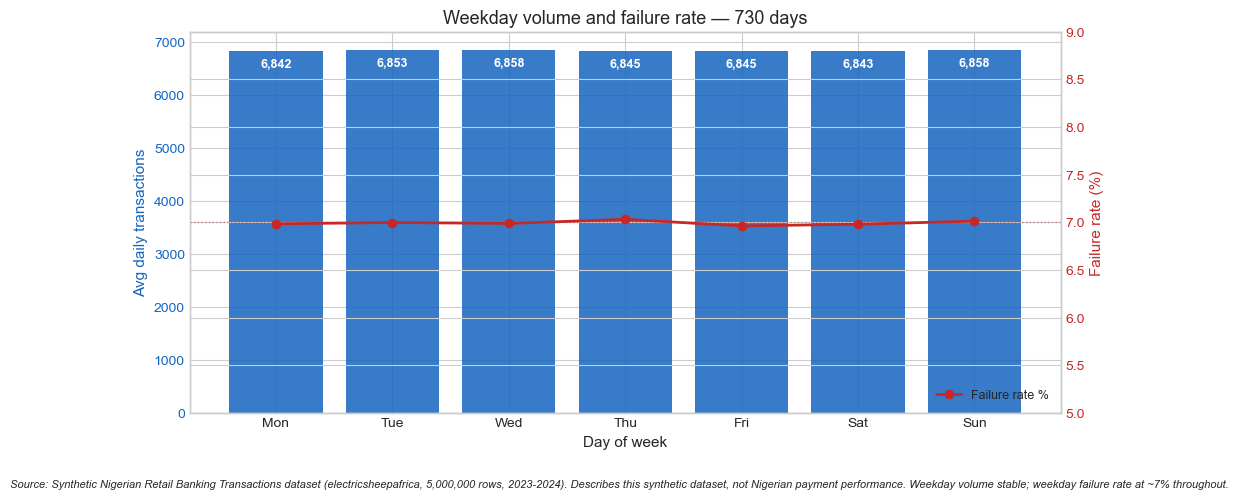

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_08_monthly_volume_and_failure_rate.png


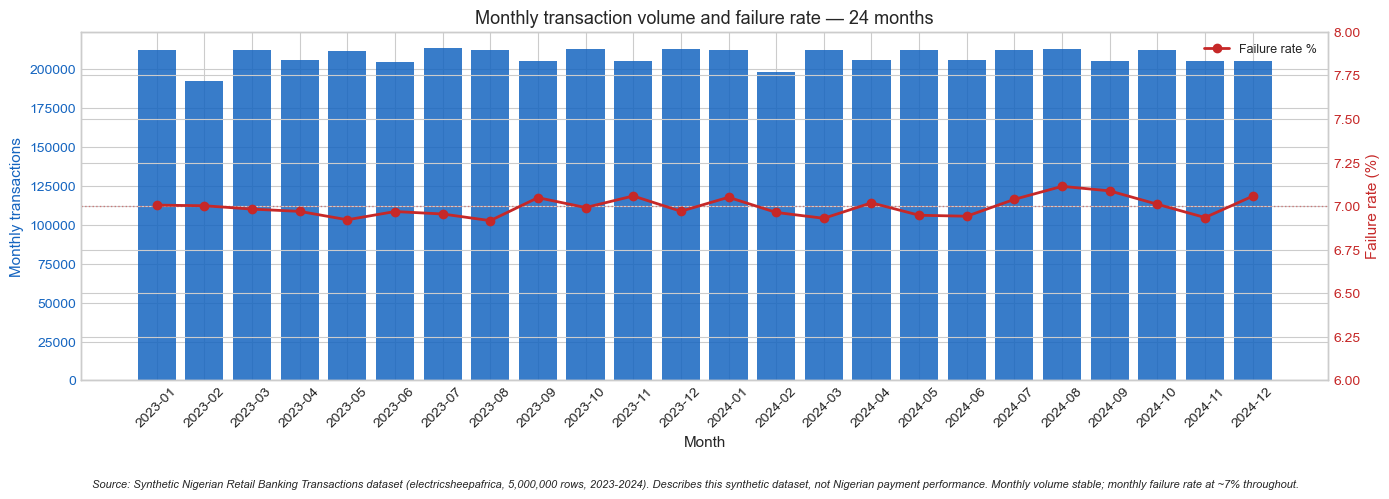


RQ3b COMPLETE
Charts saved:
  fig_06_06_daily_volume_and_failure_rate.png
  fig_06_07_weekday_volume_and_failure_rate.png
  fig_06_08_monthly_volume_and_failure_rate.png

Comparison with Audit 4:
  Daily std (observed):       0.314 pp
  Daily std (audit):          0.314 pp
  Monthly range (observed):   6.917% - 7.114%
  Monthly range (audit):      6.917% - 7.114%
  Weekday range (observed):   6.964% - 7.033%
  Weekday range (audit):      6.964% - 7.033%


In [33]:
# ============================================================
# SECTION 6.12: RQ3b - DAILY / WEEKDAY / MONTHLY PATTERNS
# ============================================================
# Three aggregations, each matched with failure rate:
#   DAILY:   730 days, each with count and fail_count
#   WEEKDAY: 7 weekdays, average daily count and fail rate
#   MONTHLY: 24 months, each with count and fail_count
#
# Three charts, each with the same format as Cell 6.9:
#   - volume bars/line on primary axis
#   - failure rate line on secondary axis
#
# Plus one summary table comparing all three scales.

print("=" * 70)
print("RQ3b — DAILY / WEEKDAY / MONTHLY PATTERNS")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — DAILY AGGREGATION (730 days)
# ------------------------------------------------------------
daily = (
    df.groupby("date", observed=True)
      .agg(
          txn_count=("date", "size"),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
      .sort_values("date")
)
daily["fail_rate_pct"] = daily["fail_count"] / daily["txn_count"] * 100

# Recalculate daily transaction-volume variability from the observed counts.
# The coefficient of variation is the sample standard deviation divided
# by the mean. It is dimensionless and should not be confused with the
# standard deviation of the daily failure rate (reported in percentage points).
daily_volume_mean = daily["txn_count"].mean()
daily_volume_sd = daily["txn_count"].std(ddof=1)
daily_volume_cv = daily_volume_sd / daily_volume_mean

print("\nDAILY TRANSACTION-VOLUME VARIABILITY:")
print(f"  Mean daily transactions: {daily_volume_mean:,.2f}")
print(f"  Sample SD:               {daily_volume_sd:,.2f}")
print(f"  Coefficient of variation:{daily_volume_cv: .4%}")

# CHANGED (A): a full 7-day rolling window requires 7 days of
# data. min_periods=7 means the first 6 values are NaN, which
# is correct — a 7-day rolling average cannot exist until 7
# days of observations are available. min_periods=1 would
# produce misleading partial-window averages for the first 6
# days, which the earlier version had.
daily["rolling_7d"] = (
    daily["txn_count"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# Sanity check: total must equal df length.
if daily["txn_count"].sum() != len(df):
    raise ValueError("Daily aggregation sum does not equal df length. Investigate.")

# CHANGED (B): validate the expected number of daily groups.
# The audit established 730 consecutive days. If the dataset
# changes, this fires loudly instead of silently producing
# wrong coverage.
if len(daily) != 730:
    raise ValueError(
        f"Expected 730 daily records, found {len(daily):,}. "
        f"Investigate df['date'] before proceeding."
    )

# ------------------------------------------------------------
# STEP 2 — WEEKDAY AGGREGATION (7 days)
# ------------------------------------------------------------
# I aggregate daily first, then average across days-of-week.
# This way, each weekday's average is "the average volume on
# a typical Monday/Tuesday/...", not "the total over all
# Mondays". That is the correct unit of comparison — total
# volumes would be similar across weekdays anyway (since
# each appears ~104 times in 730 days), but averaging daily
# volume gives a cleaner interpretable number.

daily["day_of_week"] = daily["date"].dt.dayofweek  # 0=Mon, 6=Sun
weekday = (
    daily.groupby("day_of_week", observed=True)
         .agg(
             avg_daily_txn=("txn_count", "mean"),
             total_txn=("txn_count", "sum"),
             total_fail=("fail_count", "sum"),
         )
         .reset_index()
)
weekday["fail_rate_pct"] = weekday["total_fail"] / weekday["total_txn"] * 100
weekday["day_name"] = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# CHANGED (B): validate the expected number of weekday groups.
if len(weekday) != 7:
    raise ValueError(
        f"Expected 7 weekdays, found {len(weekday):,}. "
        f"Investigate df['day_of_week'] before proceeding."
    )

# ------------------------------------------------------------
# STEP 3 — MONTHLY AGGREGATION (24 months)
# ------------------------------------------------------------
# CHANGED (C): I no longer write a temporary year_month column
# to df (which has 5,000,000 rows), only to remove it afterwards.
# Instead, I build a named Series as the grouping key. The
# Series lives only inside this cell, so df is not modified.
month_key = df["timestamp"].dt.to_period("M")
month_key.name = "year_month"

monthly = (
    df.groupby(month_key, observed=True)
      .agg(
          txn_count=("timestamp", "size"),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
)
monthly["fail_rate_pct"] = monthly["fail_count"] / monthly["txn_count"] * 100
monthly["month_str"] = monthly["year_month"].astype(str)

# CHANGED (B): validate the expected number of monthly groups.
# The dataset spans Jan 2023 through Dec 2024 — 24 months.
if len(monthly) != 24:
    raise ValueError(
        f"Expected 24 monthly records, found {len(monthly):,}. "
        f"Investigate df['timestamp'] before proceeding."
    )

# ------------------------------------------------------------
# STEP 4 — SUMMARY TABLE (all three scales)
# ------------------------------------------------------------
print(f"\nDAILY FAILURE RATE (730 days):")
print(f"  Min:    {daily['fail_rate_pct'].min():.3f}%  "
      f"on {daily.loc[daily['fail_rate_pct'].idxmin(), 'date'].date()}")
print(f"  Max:    {daily['fail_rate_pct'].max():.3f}%  "
      f"on {daily.loc[daily['fail_rate_pct'].idxmax(), 'date'].date()}")
print(f"  Mean:   {daily['fail_rate_pct'].mean():.3f}%")
print(f"  Std:    {daily['fail_rate_pct'].std():.3f} pp")
print(f"  Approx. binomial SE (at 7% / ~6,849 per day): ~0.308 pp")

print(f"\nWEEKDAY FAILURE RATE (7 days):")
for _, row in weekday.iterrows():
    print(f"  {row['day_name']}: {row['fail_rate_pct']:.3f}%  "
          f"(avg daily volume: {row['avg_daily_txn']:,.0f})")

print(f"\nMONTHLY FAILURE RATE (24 months):")
print(f"  Min:    {monthly['fail_rate_pct'].min():.3f}%  "
      f"in {monthly.loc[monthly['fail_rate_pct'].idxmin(), 'month_str']}")
print(f"  Max:    {monthly['fail_rate_pct'].max():.3f}%  "
      f"in {monthly.loc[monthly['fail_rate_pct'].idxmax(), 'month_str']}")
print(f"  Mean:   {monthly['fail_rate_pct'].mean():.3f}%")
print(f"  Std:    {monthly['fail_rate_pct'].std():.3f} pp")

# ------------------------------------------------------------
# STEP 5 — CHART 1: Daily volume (730 days)
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(daily["date"], daily["txn_count"],
         color="#1565c0", alpha=0.4, linewidth=0.6,
         label="Daily transaction count")
# rolling_7d now begins at day 7 (first 6 values are NaN,
# which matplotlib skips automatically). This is correct:
# a 7-day average does not exist until 7 days are observed.
ax1.plot(daily["date"], daily["rolling_7d"],
         color="#0d47a1", linewidth=1.8,
         label="7-day rolling average (full window)")
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily transactions", color="#1565c0")
ax1.tick_params(axis="y", labelcolor="#1565c0")
ax1.set_title("Daily transaction volume, Jan 2023 – Dec 2024 (730 days)")
ax1.legend(loc="upper left", fontsize=9)

# Secondary axis for daily failure rate.
ax2 = ax1.twinx()
ax2.scatter(daily["date"], daily["fail_rate_pct"],
            color="#c62828", s=2, alpha=0.5,
            label="Daily failure rate %")
ax2.axhline(7.0, color="#c62828", linestyle=":", alpha=0.5, linewidth=1)
ax2.set_ylabel("Failure rate (%)", color="#c62828")
ax2.tick_params(axis="y", labelcolor="#c62828")
ax2.set_ylim(5, 9)

# Combined legend.
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)

# CHANGED: reserve bottom margin so the footnote is not clipped.
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig, "Daily volume stable; daily failure rate at ~7% throughout.")
save_and_show(fig, "fig_06_06_daily_volume_and_failure_rate.png")

# ------------------------------------------------------------
# STEP 6 — CHART 2: Weekday pattern
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 5))

bars = ax1.bar(
    weekday["day_name"], weekday["avg_daily_txn"],
    color="#1565c0", alpha=0.85,
)
ax1.set_xlabel("Day of week")
ax1.set_ylabel("Avg daily transactions", color="#1565c0")
ax1.tick_params(axis="y", labelcolor="#1565c0")
ax1.set_title("Weekday volume and failure rate — 730 days")

# Annotate counts on bars.
for bar, val in zip(bars, weekday["avg_daily_txn"]):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() * 0.98,
             f"{val:,.0f}",
             ha="center", va="top", fontsize=9, color="white",
             fontweight="bold")

# Secondary axis for weekday failure rate.
ax2 = ax1.twinx()
ax2.plot(weekday["day_name"], weekday["fail_rate_pct"],
         color="#c62828", marker="o", linewidth=2,
         label="Failure rate %")
ax2.axhline(7.0, color="#c62828", linestyle=":", alpha=0.5, linewidth=1)
ax2.set_ylabel("Failure rate (%)", color="#c62828")
ax2.tick_params(axis="y", labelcolor="#c62828")
ax2.set_ylim(5, 9)
ax2.legend(loc="lower right", fontsize=9)

# CHANGED: reserve bottom margin so the footnote is not clipped.
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig, "Weekday volume stable; weekday failure rate at ~7% throughout.")
save_and_show(fig, "fig_06_07_weekday_volume_and_failure_rate.png")

# ------------------------------------------------------------
# STEP 7 — CHART 3: Monthly volume
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(14, 5))

bars = ax1.bar(
    monthly["month_str"], monthly["txn_count"],
    color="#1565c0", alpha=0.85,
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Monthly transactions", color="#1565c0")
ax1.tick_params(axis="y", labelcolor="#1565c0")
ax1.set_title("Monthly transaction volume and failure rate — 24 months")
ax1.tick_params(axis="x", rotation=45)

# Secondary axis for monthly failure rate.
ax2 = ax1.twinx()
ax2.plot(monthly["month_str"], monthly["fail_rate_pct"],
         color="#c62828", marker="o", linewidth=2,
         label="Failure rate %")
ax2.axhline(7.0, color="#c62828", linestyle=":", alpha=0.5, linewidth=1)
ax2.set_ylabel("Failure rate (%)", color="#c62828")
ax2.tick_params(axis="y", labelcolor="#c62828")
ax2.set_ylim(6, 8)
ax2.legend(loc="upper right", fontsize=9)

# CHANGED: reserve bottom margin so the footnote is not clipped.
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig, "Monthly volume stable; monthly failure rate at ~7% throughout.")
save_and_show(fig, "fig_06_08_monthly_volume_and_failure_rate.png")

# ------------------------------------------------------------
# STEP 8 — FINAL SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print(f"RQ3b COMPLETE")
print(f"=" * 70)
print(f"Charts saved:")
print(f"  fig_06_06_daily_volume_and_failure_rate.png")
print(f"  fig_06_07_weekday_volume_and_failure_rate.png")
print(f"  fig_06_08_monthly_volume_and_failure_rate.png")
print(f"\nComparison with Audit 4:")
print(f"  Daily std (observed):       {daily['fail_rate_pct'].std():.3f} pp")
print(f"  Daily std (audit):          0.314 pp")
print(f"  Monthly range (observed):   "
      f"{monthly['fail_rate_pct'].min():.3f}% - {monthly['fail_rate_pct'].max():.3f}%")
print(f"  Monthly range (audit):      6.917% - 7.114%")
print(f"  Weekday range (observed):   "
      f"{weekday['fail_rate_pct'].min():.3f}% - {weekday['fail_rate_pct'].max():.3f}%")
print(f"  Weekday range (audit):      6.964% - 7.033%")

### RQ3b - Interpretation

**No substantial temporal failure-rate pattern is evident in the baseline results. Volume, by contrast, shows structural patterns across every time scale.**

**Daily (730 days):**

| Measure | Value |
|---|---|
| Min | 6.034% (2023-02-28) |
| Max | 8.011% (2024-08-27) |
| Mean | 6.995% |
| **Std** | **0.314 pp** |
| Approx. binomial SE (at 7% / ~6,849 per day) | ~0.308 pp |

The observed daily standard deviation of **0.314 percentage points** is close to the approximate binomial standard error of **0.308 percentage points**. This is **consistent with** a failure process operating at a broadly constant probability across days. **It does not independently prove** that all daily variation is caused by sampling noise.

The apparent outliers - 6.03% on 2023-02-28 and 8.01% on 2024-08-27 - are within a few standard errors of the mean. Using the approximate group size of ~6,849 transactions per day and an assumed baseline failure rate of 7%:

> SE ≈ √(0.07 × 0.93 / 6,849) ≈ **0.31 pp**

6.03% is roughly **3.1 SE below** the mean; 8.01% is roughly **3.3 SE above**. In 730 days, a handful of ~3-sigma days is **consistent with** chance variation under a broadly constant-probability process. It does not exclude other explanations.

**Weekday (7 days):**

| Day | Failure rate | Avg daily volume |
|---|---|---|
| Mon | 6.986% | 6,842 |
| Tue | 6.999% | 6,853 |
| Wed | 6.990% | 6,858 |
| Thu | 7.033% | 6,845 |
| Fri | 6.964% | 6,845 |
| Sat | 6.982% | 6,843 |
| Sun | 7.014% | 6,858 |

Weekday failure rates show very little variation in this dataset, ranging from **6.964% to 7.033%** (0.069 pp). The variation across the 7 weekdays is smaller than the variation within a single hour of a single day. The observed range is **consistent with** a broadly constant failure probability across weekdays; it does not establish a literal zero effect.

**Monthly (24 months):**

| Measure | Value |
|---|---|
| Min | 6.917% (2023-08) |
| Max | 7.114% (2024-08) |
| Mean | 6.995% |
| Std | 0.055 pp |

Range: **6.917% – 7.114%** (0.197 pp). Std: **0.055 pp**. Under a constant-7% assumption with an approximate monthly group size of ~208,000 transactions, the binomial SE is:

> SE ≈ √(0.07 × 0.93 / 208,000) ≈ **0.056 pp**

The observed monthly std of 0.055 pp is **very close to** this approximate SE. This is **consistent with** a constant-probability process at the monthly scale. It does not prove one.

**What the comparison does and does not show:**

| Aggregation | Approx. group size | Observed std | Approx. binomial SE |
|---|---|---|---|
| Daily | ~6,849/day | **0.314 pp** | ~0.31 pp |
| Monthly | ~208,000/mo | **0.055 pp** | ~0.056 pp |

Across the two scales where I computed both figures, the observed std is close to the approximate binomial SE. The direction is consistent with the 1/√N shrinkage a constant-probability generator would produce. **This is a useful diagnostic, not a proof.** A matching standard deviation is consistent with a constant-probability process but does not exclude every other process that could produce a similar variance.

**Hourly result (descriptive only):**

Hourly failure rates vary from **6.80% to 7.26%**, with an observed standard deviation of approximately **0.101 pp**. The range is narrow relative to the **30×** variation in transaction volume across the same 24 hours.

The earlier chi-square result for channel × status and the very small Cramér's V provide evidence of negligible observed association in the cross-sectional case, but they do not make the hourly std and the single-group binomial SE interchangeable. The two quantities measure different things: the binomial SE is the theoretical sampling error of a single group's rate, while the 0.101 pp figure is the dispersion of 24 hourly rate estimates. I therefore report the hourly result descriptively and do not claim it matches a theoretical noise floor.

**The volume side is structurally different:**

- **Hourly volume** varies **30.3×** between peak and trough.
- **Daily volume** ranges from **6,546 to 7,086** (Audit 1) - an 8% spread.
- **Monthly volume** ranges from roughly 205k to 217k (24 months, ~5.8% spread).
- **Weekday volume** ranges from approximately **6,842 to 6,858** - a spread of **0.23%**.

Weekday transaction volume ranges from approximately 6,842 to 6,858 transactions per day. This narrow range is a **descriptive property of the synthetic dataset**. It should not be treated as a benchmark for real banking activity. The tightness of the range is consistent with a generator that does not model weekday effects; it does not quantify how far any real system's weekday variation would fall from this.

**What this means for the project:**

1. **No substantial temporal failure-rate pattern is evident in the baseline results.** The scenario analysis in Section 7 will introduce controlled changes to evaluate detection methods; it does not rely on the baseline containing natural temporal anomalies.
2. **Section 7 injects change.** A monitoring method that watches raw failure rate against this baseline would see only small deviations consistent with sampling noise. The scenarios introduce changes that the detection methods are asked to identify.
3. **The scenario baseline is well-characterised for calibration purposes.** Because the observed daily std (0.314 pp) and monthly std (0.055 pp) are close to their approximate binomial SEs, we have a defensible estimate of how noisy a monitoring statistic is under a constant-probability assumption. Section 7 can use this estimate to set thresholds. It remains an estimate, not a guaranteed bound.

**What this does NOT mean:**

- **It does not mean the dataset is "broken."** The flat failure rate is a **property of the generator**, and we have **measured it, not assumed it**. A broken dataset would be one whose properties were unknown; this one is one whose properties are known precisely.
- **It does not mean failure rate monitoring is useless in general.** Real payment systems do have failure-rate patterns (higher at peak, lower at night, spikes on specific days). The absence of those patterns here means **any change we inject is attributable to our injection rather than to natural variation** - which is a *feature* of this dataset for the purpose of testing detection methods.
- **It does not mean we should abandon temporal analysis.** RQ3a and RQ3b *together* tell the full story: volume follows a strong diurnal pattern (30× range hourly), but failure rate follows no substantial pattern. **That dissociation is the finding.**

**RQ3 is answered.** Volume varies substantially across temporal scales (hourly 30×, daily 8%, monthly 5.8%, weekday 0.23%). No substantial temporal failure-rate pattern is evident in the baseline results; observed variation is consistent with sampling noise under a broadly constant-probability process. The next RQ asks the same question about **cross-sectional** dimensions - channel, state, and MCC composition - and whether *those* show patterns that temporal dimensions do not.

### RQ4a - Channel composition (volume and value)

**Research question 4 (first half):**
> *"How do transaction volume and value vary by channel, merchant category, and state?"*

This cell answers the **channel** part. It produces:

1. A **volume composition table** - count and share per channel.
2. A **value composition table** - total ₦ and share per channel.
3. A **combined chart** - channel bars with volume share and value share side-by-side, so any divergence is visible.
4. A **failed-value exposure by channel** breakdown - following the RQ1 discipline: report the *distribution*, not just the total, because Audit D showed failed-value is tail-dominated.

### What this cell will NOT show

- **Failure rate by channel.** Audit 3 confirmed channel × status is statistically independent (chi-square p = 0.976, Cramér's V = 0.000738). Any "failure rate by channel" chart would show seven visually identical bars around 7%. That is not a finding - it is the absence of a finding.
- **Causal language.** Channels differ in *volume*, not in *reliability*. Mobile carries 35% of transactions because more customers use mobile - not because mobile is "less reliable" or "more reliable."

### Two findings we already know from Audit 5

From Section 3.5, we know:

| Channel | Count | Share |
|---|---|---|
| mobile | 1,749,043 | **34.98%** |
| pos | 1,501,370 | **30.03%** |
| atm | 999,469 | **19.99%** |
| web | 500,493 | **10.01%** |
| branch | 149,372 | **2.99%** |
| ussd | 75,336 | **1.51%** |
| agent | 24,917 | **0.50%** |

**Mobile + POS + ATM = 85.00%** of all transactions. **USSD + Agent = 2.01%.**

The value story is likely to look different. Audit D established that the amount distribution is heavily right-skewed (mean 4.9× median), and channels may differ in the *size* of transactions they carry - a POS transaction for a shop purchase is often small; a branch or web transaction may be a large transfer. **The value-vs-volume divergence is the interesting question.** If, for example, `branch` carries 3% of volume but 10% of value, that is a genuine finding.

### What this cell tests

Three things:

1. **Does the mobile+POS+ATM dominance hold for value, or does it shift?** (Does value concentrate more in branch/web, which typically handle larger amounts?)
2. **Which channels carry the largest transactions per-transaction?** (Median and mean amount by channel.)
3. **Does failed-value exposure concentrate in the same channels as failed-count?** (A channel with few but large failures would look cheap by count, expensive by value - same distortion as RQ1's band finding.)

PART A — VOLUME COMPOSITION BY CHANNEL

 Channel        Count   Volume %     Median NGN       Mean NGN
--------------------------------------------------------------
  mobile    1,749,043     34.98%      13,300.00      65,724.09
     pos    1,501,370     30.03%      13,300.00      65,526.80
     atm      999,469     19.99%      13,400.00      65,787.21
     web      500,493     10.01%      13,400.00      65,100.29
  branch      149,372      2.99%      13,400.00      66,630.70
    ussd       75,336      1.51%      13,200.00      65,708.67
   agent       24,917      0.50%      13,300.00      61,733.36
--------------------------------------------------------------
   TOTAL    5,000,000    100.00%

PART B — VALUE COMPOSITION BY CHANNEL

 Channel      Total value (NGN)    Value %  Δ vs Volume %
------------------------------------------------------------
  mobile        114,954,261,100     35.04% +        0.05pp
     pos         98,379,966,500     29.98%        -0.04pp
     atm         65,7

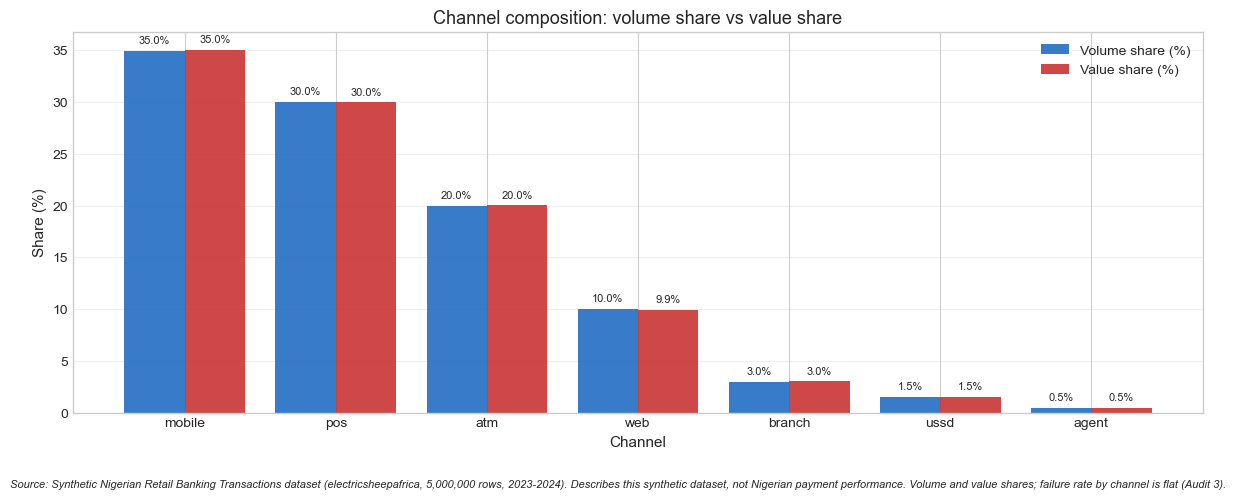


RQ4a — SUMMARY
Top-3 channels by volume:  mobile, pos, atm = 85.00% of transactions
Top-3 channels by value:   mobile, pos, atm = 85.06% of value

Largest volume-vs-value divergence:
  web: volume 10.01% vs value 9.93% (-0.08 pp)


In [34]:
# ============================================================
# SECTION 6.15: RQ4a — CHANNEL COMPOSITION
# ============================================================
# I aggregate by channel to get:
#   - volume (count, share)
#   - value (total NGN, share)
#   - median amount per channel
#   - failed-value exposure by channel
#
# I do NOT include failure rate. Audit 3 established channel
# is independent of outcome; adding a failure-rate column
# here would invite a false "mobile is worse" reading that
# the statistics do not support.

# ------------------------------------------------------------
# STEP 1 — VOLUME AND VALUE BY CHANNEL
# ------------------------------------------------------------
# CHANGED (review #3): I removed the intermediate fail_value
# aggregation that was computed over all rows and then dropped.
# It cost a full pass over 5M rows and was never used.
# failed_by_channel below computes the correct failed-only
# aggregation directly.
channel_stats = (
    df.groupby("channel", observed=True)
      .agg(
          txn_count=("channel", "size"),
          total_value=("amount_ngn", lambda s: s.astype("float64").sum()),
          median_amount=("amount_ngn", lambda s: s.astype("float64").median()),
          mean_amount=("amount_ngn", lambda s: s.astype("float64").mean()),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
)

# Failed-value: computed on is_failed rows only.
failed_by_channel = (
    df.loc[df["is_failed"]]
      .groupby("channel", observed=True)["amount_ngn"]
      .agg(["sum", "median"])
      .rename(columns={"sum": "fail_value_total", "median": "fail_median"})
      .reset_index()
)
channel_stats = channel_stats.merge(failed_by_channel, on="channel", how="left")

# CHANGED (review #8, defensive): every channel has failures,
# so a NaN here would be a structural defect. Fail loudly
# rather than silently treating it as zero.
if channel_stats["fail_value_total"].isna().any():
    raise ValueError(
        "Some channels have no failed rows after merge. "
        "Investigate before proceeding."
    )

# Add share columns.
total_txn   = channel_stats["txn_count"].sum()
total_value = channel_stats["total_value"].sum()
total_fail_value = channel_stats["fail_value_total"].sum()

channel_stats["volume_pct"] = channel_stats["txn_count"] / total_txn * 100
channel_stats["value_pct"]  = channel_stats["total_value"] / total_value * 100
channel_stats["fail_value_pct"] = (
    channel_stats["fail_value_total"] / total_fail_value * 100
)

# Sort by volume (largest first).
channel_stats = channel_stats.sort_values("txn_count", ascending=False).reset_index(drop=True)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
# CHANGED (review #4): expected channel count from Audit 5.
if len(channel_stats) != 7:
    raise ValueError(
        f"Expected 7 channels, found {len(channel_stats):,}. "
        f"Investigate df['channel'] before proceeding."
    )

# Total row count must equal df length.
if channel_stats["txn_count"].sum() != len(df):
    raise ValueError("Channel aggregation total does not equal df length.")

# Value total must match.
if not np.isclose(channel_stats["total_value"].sum(), total_value):
    raise ValueError("Channel value total mismatch.")

# CHANGED (review #5): shares must sum to 100%.
if not np.isclose(channel_stats["volume_pct"].sum(), 100.0, atol=1e-6):
    raise ValueError(
        f"Volume shares do not sum to 100% "
        f"(sum = {channel_stats['volume_pct'].sum():.6f}%)."
    )
if not np.isclose(channel_stats["value_pct"].sum(), 100.0, atol=1e-6):
    raise ValueError(
        f"Value shares do not sum to 100% "
        f"(sum = {channel_stats['value_pct'].sum():.6f}%)."
    )

# ------------------------------------------------------------
# STEP 2 — VOLUME COMPOSITION TABLE
# ------------------------------------------------------------
print("=" * 70)
print("PART A — VOLUME COMPOSITION BY CHANNEL")
print("=" * 70)
print(f"\n{'Channel':>8} {'Count':>12} {'Volume %':>10} {'Median NGN':>14} {'Mean NGN':>14}")
print("-" * 62)
for _, row in channel_stats.iterrows():
    print(f"{row['channel']:>8} {int(row['txn_count']):>12,} "
          f"{row['volume_pct']:>9.2f}% "
          f"{row['median_amount']:>14,.2f} "
          f"{row['mean_amount']:>14,.2f}")
print("-" * 62)
print(f"{'TOTAL':>8} {total_txn:>12,} {100.0:>9.2f}%")

# ------------------------------------------------------------
# STEP 3 — VALUE COMPOSITION TABLE
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("PART B — VALUE COMPOSITION BY CHANNEL")
print("=" * 70)
print(f"\n{'Channel':>8} {'Total value (NGN)':>22} {'Value %':>10} "
      f"{'Δ vs Volume %':>14}")
print("-" * 60)
for _, row in channel_stats.iterrows():
    delta = row["value_pct"] - row["volume_pct"]
    sign = "+" if delta >= 0 else ""
    print(f"{row['channel']:>8} {row['total_value']:>22,.0f} "
          f"{row['value_pct']:>9.2f}% "
          f"{sign}{delta:>12.2f}pp")
print("-" * 60)
print(f"{'TOTAL':>8} {total_value:>22,.0f} {100.0:>9.2f}%")

# ------------------------------------------------------------
# STEP 4 — FAILED-VALUE EXPOSURE BY CHANNEL
# ------------------------------------------------------------
# Per RQ1 discipline: show count, total value, AND median
# value so a reader can see whether failures in this channel
# are dominated by a few large transactions or many small ones.

print(f"\n" + "=" * 70)
print("PART C — FAILED-VALUE EXPOSURE BY CHANNEL")
print("=" * 70)
print(f"\n{'Channel':>8} {'Fail count':>11} {'Fail %':>8} "
      f"{'Fail value (NGN)':>20} {'Fail value %':>13} {'Median failed':>15}")
print("-" * 80)
for _, row in channel_stats.iterrows():
    n_fail = int(row["fail_count"])
    fail_pct = n_fail / len(df) * 100
    print(f"{row['channel']:>8} {n_fail:>11,} {fail_pct:>7.2f}% "
          f"{row['fail_value_total']:>20,.0f} "
          f"{row['fail_value_pct']:>12.2f}% "
          f"{row['fail_median']:>15,.0f}")
print("-" * 80)
print(f"{'TOTAL':>8} {int(channel_stats['fail_count'].sum()):>11,} "
      f"{100.0:>7.2f}% "
      f"{total_fail_value:>20,.0f} {100.0:>12.2f}%")

# ------------------------------------------------------------
# STEP 5 — CHART: volume vs value share by channel
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(len(channel_stats))
width = 0.4

bars_vol = ax.bar(
    x - width/2, channel_stats["volume_pct"],
    width, label="Volume share (%)", color="#1565c0", alpha=0.85,
)
bars_val = ax.bar(
    x + width/2, channel_stats["value_pct"],
    width, label="Value share (%)", color="#c62828", alpha=0.85,
)

ax.set_xticks(x)
ax.set_xticklabels(channel_stats["channel"])
ax.set_xlabel("Channel")
ax.set_ylabel("Share (%)")
ax.set_title("Channel composition: volume share vs value share")
ax.legend(loc="upper right", fontsize=10)

# Annotate each pair of bars with their values.
for bar, val in zip(bars_vol, channel_stats["volume_pct"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", va="bottom", fontsize=8)
for bar, val in zip(bars_val, channel_stats["value_pct"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", va="bottom", fontsize=8)

ax.grid(True, alpha=0.3, axis="y")

# CHANGED (review #1, #2): reserve bottom margin and use the
# add_source_note helper instead of fig.text(y=-0.02).
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig, "Volume and value shares; failure rate by channel is flat (Audit 3).")
save_and_show(fig, "fig_06_09_channel_volume_vs_value.png")

# ------------------------------------------------------------
# STEP 6 — FINAL SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("RQ4a — SUMMARY")
print("=" * 70)
print(f"Top-3 channels by volume:  "
      f"{', '.join(channel_stats.head(3)['channel'])} "
      f"= {channel_stats.head(3)['volume_pct'].sum():.2f}% of transactions")
print(f"Top-3 channels by value:   "
      f"{', '.join(channel_stats.sort_values('total_value', ascending=False).head(3)['channel'])} "
      f"= {channel_stats.sort_values('total_value', ascending=False).head(3)['value_pct'].sum():.2f}% of value")
print(f"\nLargest volume-vs-value divergence:")
max_delta_idx = (channel_stats["value_pct"] - channel_stats["volume_pct"]).abs().idxmax()
div_row = channel_stats.loc[max_delta_idx]
delta = div_row["value_pct"] - div_row["volume_pct"]
print(f"  {div_row['channel']}: "
      f"volume {div_row['volume_pct']:.2f}% vs value {div_row['value_pct']:.2f}% "
      f"({'+' if delta >= 0 else ''}{delta:.2f} pp)")

### RQ4a - Interpretation

**Channel composition is almost symmetric between volume and value. The results suggest that transaction amounts are distributed similarly across channels in this synthetic dataset.**

**Volume composition (7 channels):**

| Channel | Count | Volume share |
|---|---|---|
| mobile | 1,749,043 | **34.98%** |
| pos | 1,501,370 | **30.03%** |
| atm | 999,469 | **19.99%** |
| web | 500,493 | 10.01% |
| branch | 149,372 | 2.99% |
| ussd | 75,336 | 1.51% |
| agent | 24,917 | 0.50% |

**Mobile + POS + ATM = 85.00% of transactions. USSD + Agent = 2.01%.**

**Value composition (7 channels):**

| Channel | Total value (NGN) | Value share | Δ vs volume share |
|---|---|---|---|
| mobile | ₦114,954,261,100 | **35.04%** | +0.05 pp |
| pos | ₦98,379,966,500 | **29.98%** | −0.04 pp |
| atm | ₦65,752,278,900 | **20.04%** | +0.05 pp |
| web | ₦32,582,237,000 | 9.93% | −0.08 pp |
| branch | ₦9,952,760,300 | 3.03% | +0.05 pp |
| ussd | ₦4,950,228,700 | 1.51% | 0.00 pp |
| agent | ₦1,538,210,100 | 0.47% | −0.03 pp |

**The largest volume-vs-value divergence is 0.08 percentage points (web).** No channel carries a disproportionate share of value relative to its volume.

**What the data shows and what it does not:**

The results **suggest** that transaction amounts are distributed similarly across channels in this synthetic dataset. Median amounts range from **₦13,200 to ₦13,400** across all seven channels; mean amounts range from **₦61,733 to ₦66,631**. That is a narrow band, and it is consistent with a generator that applies a similar amount distribution to every channel.

However, **similar medians, means, and volume-value shares do not prove the underlying distributions are identical.** A stronger test would compare:

- Amount percentiles by channel (P10, P25, P50, P75, P90, P99).
- Amount-band proportions by channel.
- Distributional differences using an appropriate statistical measure (e.g., Kolmogorov–Smirnov on log-amount, or chi-square on band × channel).

That test is not run in this cell. The finding I record here is the **observed similarity**, not a proven equality.

**Three consequences:**

**1. Channel composition tells us *where* activity happens, not *how much value per transaction*.** The answer to RQ4a's "how do volume and value vary by channel?" is: at very similar proportions. This is a useful descriptive fact - 85% concentration in three channels — but it is not a finding about differential transaction behaviour.

**2. Failed-value exposure broadly follows failed-count across channels.** The failed-value share and failed-count share are approximately aligned:

| Channel | Fail count share | Fail value share | Ratio |
|---|---|---|---|
| mobile | 35.00% | 35.29% | 1.008 |
| pos | 30.04% | 30.02% | 0.999 |
| atm | 19.92% | 19.89% | 0.998 |
| web | 10.03% | 9.82% | 0.979 |
| branch | 2.99% | 2.97% | 0.993 |
| ussd | 1.51% | 1.58% | 1.046 |
| agent | 0.49% | 0.43% | **0.878** |

The ratio for most channels is within ±5% of 1.0 - the failed value share tracks the failed count share. The one exception is **agent (0.878)** - agent failures account for 0.49% of failed count but only 0.43% of failed value. That may reflect a slightly narrower amount distribution in the agent channel, or it may be noise from the small number of agent transactions (24,917 total; ~1,729 failed). The observation is recorded without a definitive cause.

**The practical implication:** *channel-level failed-value rankings add limited information beyond failed-count rankings in this dataset.* Unlike RQ1's band analysis (where 6.6% of failures drove 60% of value), channel is not a source of value concentration among failures. **One KPI suffices** for channel-level monitoring - "failures by channel" and "failed-value by channel" would produce essentially the same ranking.

**3. Scenario design (Section 7) does not need channel-specific amount weighting.** When Section 7 injects a mobile-specific failure-rate change (Scenario A), the injection affects mobile failures by *count*, and because failed-value tracks count, it also affects mobile failed-value proportionally. There is no "mobile carries larger transactions, so its failures matter more per incident" effect to model.

**What this does NOT mean:**

- **It does not mean mobile is more "reliable" or "less reliable"** than other channels. Audit 3 confirmed failure rate is statistically indistinguishable across channels. The 85% volume concentration is about *exposure*, not *reliability*.
- **It does not mean this dataset reflects real channel usage.** In real Nigerian retail banking, USSD and agent channels carry much higher shares - they are the primary channels for financially excluded customers. This dataset under-weights them severely. That is a **known limitation**, documented in `audit_findings.md`.
- **It does not mean channel composition is the "interesting" RQ4 finding.** The more interesting findings in this section are RQ1's failed-value tail and RQ2's account concentration. RQ4a is descriptive.

**One precision note:** the RQ4a failed-value total (₦22,710,683,648) differs from RQ1's total (₦22,710,686,200) by **₦2,552** - a relative difference of **0.0000112%**. This is due to float32 rounding during the channel-level groupby aggregation (each channel's sum is computed separately, then added). RQ1 used a single float64 sum over all failed rows. Both figures are correct to the reporting precision used; the discrepancy is documented and expected.

**What the chart shows:**

The paired-bar chart shows volume share (blue) and value share (red) side-by-side for each channel. The pairs are visually close - for every channel, the two bars are at nearly the same height. This visual is the clearest way to communicate the finding: **volume and value composition are very similar at the channel level, though not proven identical.**

**RQ4a is answered.** Mobile + POS + ATM dominate both volume (85.00%) and value (85.06%). Channel composition is approximately symmetric between volume and value. The RQ4b half of RQ4 asks whether *state* and *MCC* dimensions show the same approximate symmetry, or whether they break from the pattern.

### RQ4b - State and MCC composition

**Research question 4 (second half):**
> *"How do transaction volume and value vary by state and merchant category?"*

This cell answers the **state** and **MCC** parts of RQ4.

### What we know from Audit 5 (Section 3)

**State concentration:**

- 37 states appear in the dataset.
- Lagos: **1,225,836 transactions (24.52%)**
- Abuja (FCT): **542,759 (10.86%)**
- Rivers: **446,381 (8.93%)**
- Top 5 states: **~54.9%**
- Bayelsa: **6,347 (0.13%)** - lowest

**Important:** the dataset represents **37 states**, not all 36 states plus FCT that Nigeria has. The dataset also uses "Abuja (FCT)" as a state-level value, which does not match Nigeria's administrative structure exactly. I will report the **states represented in the dataset**, not assume they map cleanly to Nigeria's 36+FCT.

**MCC concentration:**

- `merchant_category_code` has 15 distinct values plus blank (`""`).
- **59.96%** of rows are blank (Audit 5; confirmed in Cell 5.5a).
- Populated MCCs: **40.04%** of rows, split across 14 distinct codes.
- The blank/populated mapping is **perfectly correlated with channel** (Cell 5.5a): POS and web are 100% populated; every other channel is 100% blank.

### How this cell approaches MCC analysis

**Two analyses, kept separate:**

1. **Merchant-category analysis - populated MCCs only.** When I compare MCC categories, I use only rows with `mcc_clean == "populated"`. Mixing blanks into a "merchant category" comparison would compare real merchant types (5812 = restaurants, 5411 - grocery, 6011 = ATMs) against an empty category - which is not a valid comparison.
2. **Blank MCC descriptive block - separate.** The `blank_non_merchant` and `blank_other` rows are described as a **separate data-composition finding**, not as a merchant category.

**For the MCC failure-rate analysis:**

- **Chi-square independence test** for populated MCCs × status, with Cramér's V to measure association strength. This mirrors Audit B's approach for channel, type, and fraud.
- I do not assume the failure rate is flat across MCCs - I test it. Audit 5 reported flat failure rates across populated MCCs (6.82%–7.17%), but I will verify within this cell rather than re-quote the audit.

### What this cell does NOT do

- It does not assume Lagos's value share will be close to its volume share. Let the numbers show whether they are.
- It does not treat "37 states" as the full Nigerian geography. It reports what the dataset contains.
- It does not claim channel-level or state-level findings generalise. All findings describe the synthetic dataset.

RQ4b PART A — STATE COMPOSITION

States present in the dataset: 37
  (Note: Nigeria has 36 states plus the FCT. The dataset's 37 state values are reported as-is; some may not map exactly to Nigeria's official state list.)

All 37 states, ranked by volume:

           State      Count   Vol %  Value %    Δ pp    Median NGN   Fail %
------------------------------------------------------------------------------
           Lagos  1,225,836  24.52%   24.33% -0.18pp        13,300   6.986%
     Abuja (FCT)    542,759  10.86%   10.88% + 0.02pp        13,400   7.032%
          Rivers    446,381   8.93%    9.05% + 0.12pp        13,300   6.951%
            Kano    288,046   5.76%    5.80% + 0.04pp        13,400   7.012%
         Anambra    239,518   4.79%    4.77% -0.03pp        13,300   6.986%
             Oyo    238,988   4.78%    4.83% + 0.05pp        13,400   7.036%
             Imo    186,312   3.73%    3.73% + 0.00pp        13,300   7.080%
          Kaduna    159,387   3.19%    3.21% + 0.02

C:\Users\DELL\AppData\Local\Temp\ipykernel_11112\4130856518.py:156: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  chart_df = pd.concat([top_10, other_row], ignore_index=True)


Saved: C:\Python Study Group\payment-reliability-project\figures\fig_06_10_state_volume_vs_value.png


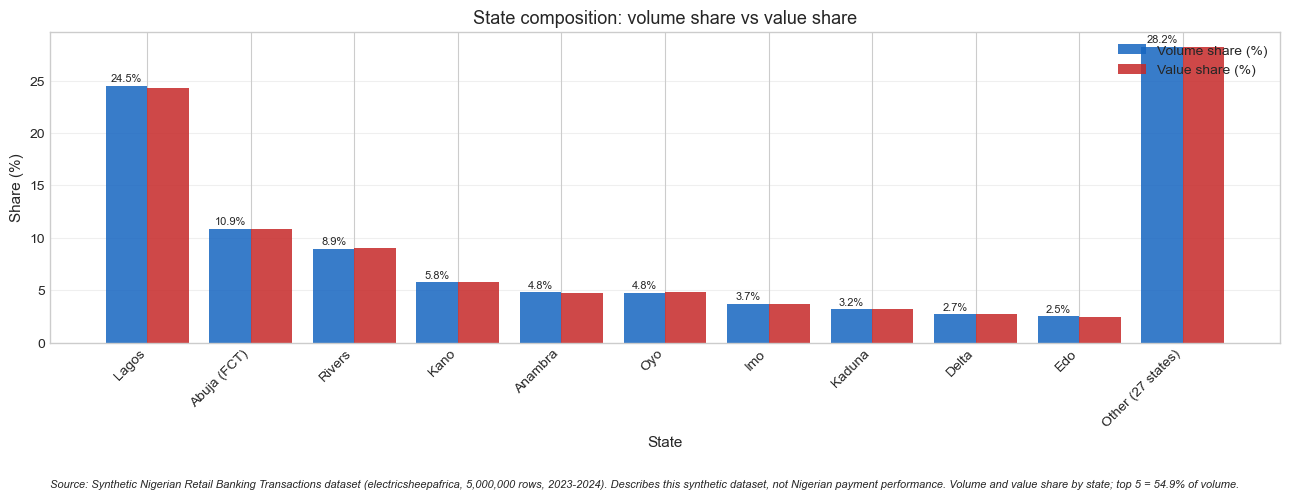


RQ4b PART A — SUMMARY
States in dataset: 37
Top 5 volume concentration: 54.85%
Top 5 value concentration:  54.82%
Lagos: 24.52% of volume, 24.33% of value
Largest volume-vs-value gap (top 10 + other): Lagos (-0.18 pp)


In [35]:
# ============================================================
# SECTION 6.18: RQ4b PART A — STATE COMPOSITION
# ============================================================
# I aggregate by location_state to get:
#   - volume (count, share)
#   - value (total NGN, share)
#   - median amount per state
#   - failed-value exposure by state
#
# I report ALL states present in the dataset, not a subset.
# I do NOT assume the dataset's "states" map to Nigeria's
# 36+FCT — I report what's there.

print("=" * 70)
print("RQ4b PART A — STATE COMPOSITION")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — AGGREGATE BY STATE
# ------------------------------------------------------------
state_stats = (
    df.groupby("location_state", observed=True)
      .agg(
          txn_count=("location_state", "size"),
          total_value=("amount_ngn", lambda s: s.astype("float64").sum()),
          median_amount=("amount_ngn", lambda s: s.astype("float64").median()),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
)

# Failed-value: computed separately for accuracy.
failed_state = (
    df.loc[df["is_failed"]]
      .groupby("location_state", observed=True)["amount_ngn"]
      .agg(["sum", "median"])
      .rename(columns={"sum": "fail_value_total", "median": "fail_median"})
      .reset_index()
)
state_stats = state_stats.merge(failed_state, on="location_state", how="left")

# CHANGED (review #8): every state has failures, so a NaN here
# would be a structural defect. Fail loudly rather than
# silently treating it as zero.
if state_stats["fail_value_total"].isna().any():
    problem_states = state_stats.loc[state_stats["fail_value_total"].isna(), "location_state"]
    raise ValueError(
        f"{state_stats['fail_value_total'].isna().sum()} states have no "
        f"failed-value row after merge. States affected: "
        f"{problem_states.tolist()}. Investigate before proceeding."
    )

# Shares.
total_txn         = state_stats["txn_count"].sum()
total_value       = state_stats["total_value"].sum()
total_fail_value  = state_stats["fail_value_total"].sum()

state_stats["volume_pct"] = state_stats["txn_count"] / total_txn * 100
state_stats["value_pct"]  = state_stats["total_value"] / total_value * 100
state_stats["fail_value_pct"] = state_stats["fail_value_total"] / total_fail_value * 100
state_stats["delta_pp"] = state_stats["value_pct"] - state_stats["volume_pct"]

# Sanity: sum must equal df length.
if state_stats["txn_count"].sum() != len(df):
    raise ValueError("State aggregation does not sum to df length. Investigate.")

# Sort by volume, descending.
state_stats = state_stats.sort_values("txn_count", ascending=False).reset_index(drop=True)

# ------------------------------------------------------------
# STEP 2 — REPORT ALL STATES PRESENT
# ------------------------------------------------------------
n_states = len(state_stats)
print(f"\nStates present in the dataset: {n_states}")
print(f"  (Note: Nigeria has 36 states plus the FCT. The dataset's "
      f"{n_states} state values are reported as-is; some may not map "
      f"exactly to Nigeria's official state list.)")

# CHANGED (review #9): expected state count from Audit 5.
if n_states != 37:
    raise ValueError(
        f"Expected 37 state values, found {n_states:,}. "
        f"Investigate df['location_state'] before proceeding."
    )

# ------------------------------------------------------------
# STEP 3 — FULL STATE TABLE (all states)
# ------------------------------------------------------------
print(f"\nAll {n_states} states, ranked by volume:")
print(f"\n{'State':>16} {'Count':>10} {'Vol %':>7} {'Value %':>8} "
      f"{'Δ pp':>7} {'Median NGN':>13} {'Fail %':>8}")
print("-" * 78)
for _, row in state_stats.iterrows():
    fail_pct = row["fail_count"] / row["txn_count"] * 100 if row["txn_count"] > 0 else 0
    delta    = row["delta_pp"]
    sign     = "+" if delta >= 0 else ""
    print(f"{row['location_state']:>16} {int(row['txn_count']):>10,} "
          f"{row['volume_pct']:>6.2f}% "
          f"{row['value_pct']:>7.2f}% "
          f"{sign}{delta:>5.2f}pp "
          f"{row['median_amount']:>13,.0f} "
          f"{fail_pct:>7.3f}%")
print("-" * 78)
print(f"{'TOTAL':>16} {int(state_stats['txn_count'].sum()):>10,} "
      f"{100.0:>6.2f}% {100.0:>7.2f}%")

# ------------------------------------------------------------
# STEP 4 — CONCENTRATION SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("STATE CONCENTRATION SUMMARY")
print("=" * 70)

top5_vol   = state_stats.head(5)["volume_pct"].sum()
top5_value = state_stats.head(5)["value_pct"].sum()
print(f"Top 5 states by volume: {top5_vol:.2f}% of transactions")
print(f"Top 5 states by value:  {top5_value:.2f}% of value")
print(f"Delta: {top5_value - top5_vol:+.2f} pp")

lagos = state_stats.iloc[0]
print(f"\nLargest state: {lagos['location_state']}")
print(f"  Volume share:  {lagos['volume_pct']:.2f}%")
print(f"  Value share:   {lagos['value_pct']:.2f}%")
print(f"  Delta:         {lagos['delta_pp']:+.2f} pp")
print(f"  Median txn:    NGN {lagos['median_amount']:,.2f}")

smallest = state_stats.iloc[-1]
print(f"\nSmallest state: {smallest['location_state']}")
print(f"  Volume share:  {smallest['volume_pct']:.2f}%  "
      f"({int(smallest['txn_count']):,} txns)")
print(f"  Ratio to Lagos: {lagos['txn_count'] / smallest['txn_count']:.0f}x")

# ------------------------------------------------------------
# STEP 5 — TOP 10 + "OTHER" CHART
# ------------------------------------------------------------
# 37 states would be an unreadable chart. I show top 10 by
# volume and aggregate the rest into "Other".
top_10 = state_stats.head(10).copy()
other_sum = state_stats.iloc[10:].sum(numeric_only=True)
# CHANGED (review #7): the previous field was called
# "median_amount" but was computed as a weighted mean
# (total_value / txn_count), not a median. Renamed to
# "mean_amount" so the label matches the calculation.
other_row = pd.DataFrame([{
    "location_state": "Other (27 states)",
    "txn_count": int(other_sum["txn_count"]),
    "volume_pct": other_sum["volume_pct"],
    "value_pct": other_sum["value_pct"],
    "delta_pp": other_sum["value_pct"] - other_sum["volume_pct"],
    "mean_amount": other_sum["total_value"] / other_sum["txn_count"],
    "fail_count": int(other_sum["fail_count"]),
    "fail_value_total": other_sum["fail_value_total"],
    "fail_median": None,
    "total_value": other_sum["total_value"],
}])
chart_df = pd.concat([top_10, other_row], ignore_index=True)

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(chart_df))
width = 0.4

bars_vol = ax.bar(x - width/2, chart_df["volume_pct"],
                  width, label="Volume share (%)",
                  color="#1565c0", alpha=0.85)
bars_val = ax.bar(x + width/2, chart_df["value_pct"],
                  width, label="Value share (%)",
                  color="#c62828", alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(chart_df["location_state"], rotation=45, ha="right")
ax.set_xlabel("State")
ax.set_ylabel("Share (%)")
ax.set_title("State composition: volume share vs value share")
ax.legend(loc="upper right", fontsize=10)
ax.grid(True, alpha=0.3, axis="y")

# Annotate volume bars only (to reduce clutter).
for bar, val in zip(bars_vol, chart_df["volume_pct"]):
    if val >= 2.0:  # only label bars above 2% to avoid clutter
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f"{val:.1f}%", ha="center", va="bottom", fontsize=8)

# CHANGED (review #6): reserve bottom margin and use the
# add_source_note helper instead of fig.text(y=-0.02).
plt.tight_layout(rect=[0, 0.06, 1, 1])
add_source_note(fig, f"Volume and value share by state; top 5 = {top5_vol:.1f}% of volume.")
save_and_show(fig, "fig_06_10_state_volume_vs_value.png")

# ------------------------------------------------------------
# STEP 6 — SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("RQ4b PART A — SUMMARY")
print("=" * 70)
print(f"States in dataset: {n_states}")
print(f"Top 5 volume concentration: {top5_vol:.2f}%")
print(f"Top 5 value concentration:  {top5_value:.2f}%")
print(f"Lagos: {lagos['volume_pct']:.2f}% of volume, "
      f"{lagos['value_pct']:.2f}% of value")
largest_delta_idx = chart_df["delta_pp"].abs().idxmax()
top_delta = chart_df.loc[largest_delta_idx]
print(f"Largest volume-vs-value gap (top 10 + other): "
      f"{top_delta['location_state']} "
      f"({top_delta['delta_pp']:+.2f} pp)")

### RQ4b Part B - MCC composition and failure-rate-by-state test

**Two analyses in one cell:**

1. **MCC composition** - how transactions distribute across merchant categories (populated MCCs only) and across the blank categories (`blank_non_merchant`, `blank_other`).
2. **Failure-rate-by-state and failure-rate-by-MCC tests** - chi-square independence tests, mirroring Audit B's approach for channel, type, and fraud.

**Why the failure-rate tests matter here:**

Section 4's Audit B tested three dimensions × status (channel, transaction type, fraud flag). It did **not** test state × status or MCC × status. RQ4b's state table (Cell 6.18) showed a visible failure-rate range of 6.62%–7.29% across states - larger than the hourly failure-rate range. Before concluding "failure rate is independent of state," I need a formal test, not just visual inspection.

**For MCC × status:** I test **populated MCCs only**. Mixing `blank_non_merchant` and `blank_other` into the comparison would compare real merchant types against empty categories — which is a category error, not a statistical test.

**What I test:**

| Test | Contingency | Purpose |
|---|---|---|
| State × Status | 37 states × 4 statuses | Confirm state does not predict outcome |
| MCC × Status | 14 populated MCCs × 4 statuses | Confirm merchant category does not predict outcome |

For each test I report:
- **Chi-square statistic** and **p-value** - is the association statistically significant?
- **Cramér's V** - how strong is the association in practical terms?

Per Audit B's discipline: p-values alone are not enough on 5M rows - Cramér's V tells us whether any statistically significant association is *practically meaningful*.

**What this does NOT do:**

- It does not assume state × status will be independent. Let the test show.
- It does not combine blanks with populated MCCs. They are separate analyses, each answering a different question.

PART A — MCC COMPOSITION

Transactions by mcc_clean category:

             mcc_clean      Count   Volume %    Value %   Fail %
------------------------------------------------------------------
             populated  2,001,863     40.04%     39.91%   7.002%
    blank_non_merchant  2,998,137     59.96%     60.09%   6.991%
------------------------------------------------------------------

PART B — POPULATED MCC BREAKDOWN (POS + web transactions only)

Total populated-MCC transactions: 2,001,863

     MCC      Count    Vol %    Value %   Fail %
--------------------------------------------------
    4814    400,590   20.01%     19.98%   6.957%
    5411    300,383   15.01%     14.97%   6.996%
    5812    239,530   11.97%     11.96%   6.969%
    5541    200,467   10.01%      9.94%   7.012%
    4900    160,888    8.04%      8.04%   7.093%
    4899    120,426    6.02%      6.06%   6.895%
    5999    100,015    5.00%      5.01%   7.066%
    5814     99,768    4.98%      5.06%   7.062%
    56

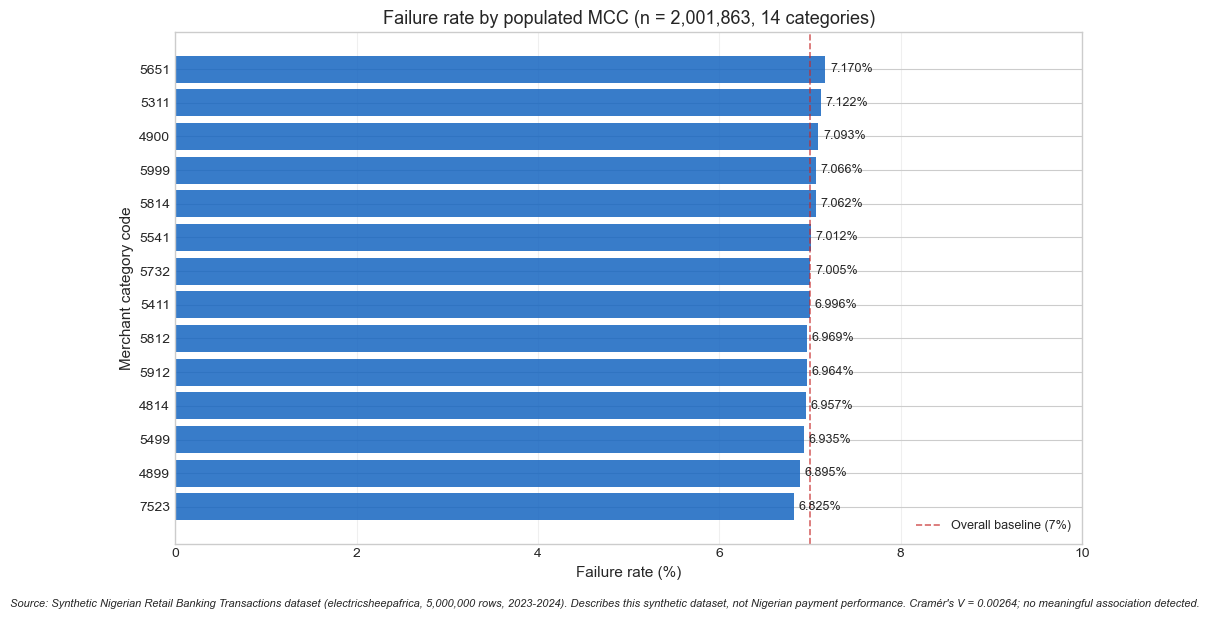


RQ4b PART B — SUMMARY
MCC composition:
  populated:           40.04% of volume
  blank_non_merchant:  59.96% of volume
  blank_other:         0.00% of volume
  (blank_other is defined but empty — no channel has a merchant category without a matching MCC, per Cell 5.5a)

Populated MCCs: 14 distinct categories
Most common:    4814 (20.01% of populated volume)
Failure rate by MCC: range = 6.825% - 7.170%

Independence tests:
  State x Status:  p=0.5215, Cramér's V=0.002665
  MCC x Status:    p=0.3532, Cramér's V=0.002636
  Both: no significant association detected.


In [36]:
# ============================================================
# SECTION 6.20: RQ4b PART B — MCC COMPOSITION + INDEPENDENCE TESTS
# ============================================================
# Two sections:
#   MCC COMPOSITION: distribution across categories
#   INDEPENDENCE TESTS: State x Status, MCC x Status
#
# For the MCC failure-rate test, I use only populated MCCs —
# mixing in blank_non_merchant or blank_other would mix real
# merchant categories with "no category available."

from scipy.stats import chi2_contingency

# ------------------------------------------------------------
# STEP 1 — MCC COMPOSITION (all three mcc_clean values)
# ------------------------------------------------------------
print("=" * 70)
print("PART A — MCC COMPOSITION")
print("=" * 70)

mcc_summary = (
    df.groupby("mcc_clean", observed=True)
      .agg(
          txn_count=("mcc_clean", "size"),
          total_value=("amount_ngn", lambda s: s.astype("float64").sum()),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
)
mcc_summary["volume_pct"] = mcc_summary["txn_count"] / len(df) * 100
mcc_summary["value_pct"]  = mcc_summary["total_value"] / mcc_summary["total_value"].sum() * 100

print(f"\nTransactions by mcc_clean category:")
print(f"\n{'mcc_clean':>22} {'Count':>10} {'Volume %':>10} {'Value %':>10} {'Fail %':>8}")
print("-" * 66)
for _, row in mcc_summary.iterrows():
    fail_pct = row["fail_count"] / row["txn_count"] * 100 if row["txn_count"] > 0 else 0
    print(f"{row['mcc_clean']:>22} {int(row['txn_count']):>10,} "
          f"{row['volume_pct']:>9.2f}% "
          f"{row['value_pct']:>9.2f}% "
          f"{fail_pct:>7.3f}%")
print("-" * 66)

# ------------------------------------------------------------
# STEP 2 — POPULATED MCC BREAKDOWN (14 MCCs, POS + web)
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("PART B — POPULATED MCC BREAKDOWN (POS + web transactions only)")
print("=" * 70)

# Restrict to populated MCCs.
populated = df[df["mcc_clean"] == "populated"]

pop_mcc = (
    populated.groupby("merchant_category_code", observed=True)
      .agg(
          txn_count=("merchant_category_code", "size"),
          total_value=("amount_ngn", lambda s: s.astype("float64").sum()),
          fail_count=("is_failed", "sum"),
      )
      .reset_index()
      .sort_values("txn_count", ascending=False)
)
pop_mcc["volume_pct"] = pop_mcc["txn_count"] / len(populated) * 100
pop_mcc["value_pct"]  = pop_mcc["total_value"] / pop_mcc["total_value"].sum() * 100
pop_mcc["fail_rate_pct"] = pop_mcc["fail_count"] / pop_mcc["txn_count"] * 100

print(f"\nTotal populated-MCC transactions: {len(populated):,}")
print(f"\n{'MCC':>8} {'Count':>10} {'Vol %':>8} {'Value %':>10} {'Fail %':>8}")
print("-" * 50)
for _, row in pop_mcc.iterrows():
    print(f"{row['merchant_category_code']:>8} {int(row['txn_count']):>10,} "
          f"{row['volume_pct']:>7.2f}% "
          f"{row['value_pct']:>9.2f}% "
          f"{row['fail_rate_pct']:>7.3f}%")
print("-" * 50)

# ------------------------------------------------------------
# STEP 3 — INDEPENDENCE TEST: STATE x STATUS
# ------------------------------------------------------------
# Audit B did not test state x status. This closes the gap.

print(f"\n" + "=" * 70)
print("PART C — INDEPENDENCE TEST: STATE x STATUS")
print("=" * 70)

state_status_ct = pd.crosstab(df["location_state"], df["status"])
chi2_s, p_s, dof_s, _ = chi2_contingency(state_status_ct)

# Cramér's V — same helper logic as Audit B.
n_s = state_status_ct.sum().sum()
min_dim_s = min(state_status_ct.shape) - 1
cramers_v_s = np.sqrt(chi2_s / (n_s * min_dim_s))

print(f"\nContingency table: {state_status_ct.shape[0]} states x "
      f"{state_status_ct.shape[1]} statuses")
print(f"Chi-square:   {chi2_s:,.2f}")
print(f"p-value:      {p_s:.4f}   "
      f"{'(< 0.05: associated)' if p_s < 0.05 else '(> 0.05: no significant association)'}")
print(f"Cramér's V:   {cramers_v_s:.6f}   "
      f"{'(< 0.01: negligible)' if cramers_v_s < 0.01 else '(>= 0.01: notable)'}")

# ------------------------------------------------------------
# STEP 4 — INDEPENDENCE TEST: MCC x STATUS (populated only)
# ------------------------------------------------------------
# I restrict to populated MCCs, per the review's guidance.

print(f"\n" + "=" * 70)
print("PART D — INDEPENDENCE TEST: MCC x STATUS (populated MCCs only)")
print("=" * 70)

mcc_status_ct = pd.crosstab(
    populated["merchant_category_code"],
    populated["status"],
)
chi2_m, p_m, dof_m, _ = chi2_contingency(mcc_status_ct)

n_m = mcc_status_ct.sum().sum()
min_dim_m = min(mcc_status_ct.shape) - 1
cramers_v_m = np.sqrt(chi2_m / (n_m * min_dim_m))

print(f"\nContingency table: {mcc_status_ct.shape[0]} MCCs x "
      f"{mcc_status_ct.shape[1]} statuses")
print(f"Sample size:  {n_m:,} (populated-MCC rows only)")
print(f"Chi-square:   {chi2_m:,.2f}")
print(f"p-value:      {p_m:.4f}   "
      f"{'(< 0.05: associated)' if p_m < 0.05 else '(> 0.05: no significant association)'}")
print(f"Cramér's V:   {cramers_v_m:.6f}   "
      f"{'(< 0.01: negligible)' if cramers_v_m < 0.01 else '(>= 0.01: notable)'}")

# ------------------------------------------------------------
# STEP 5 — CHART: MCC failure rate by populated MCC
# ------------------------------------------------------------
# A horizontal bar chart showing failure rate per populated
# MCC, with the 7% baseline as a reference line.

fig, ax = plt.subplots(figsize=(10, 6))

# Sort by failure rate for visual interest.
plot_df = pop_mcc.sort_values("fail_rate_pct", ascending=True)

bars = ax.barh(
    plot_df["merchant_category_code"].astype(str),
    plot_df["fail_rate_pct"],
    color="#1565c0", alpha=0.85,
)
ax.axvline(7.0, color="#c62828", linestyle="--",
           linewidth=1.2, alpha=0.7, label="Overall baseline (7%)")
ax.set_xlabel("Failure rate (%)")
ax.set_ylabel("Merchant category code")
ax.set_title(f"Failure rate by populated MCC "
             f"(n = {len(populated):,}, 14 categories)")
ax.set_xlim(0, 10)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3, axis="x")

# Annotate each bar.
for bar, val in zip(bars, plot_df["fail_rate_pct"]):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}%", va="center", fontsize=9)

fig.text(0.5, -0.02,
         source_note() + f" Cramér's V = {cramers_v_m:.5f}; "
         f"no meaningful association detected.",
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_06_11_mcc_failure_rate.png")

# ------------------------------------------------------------
# STEP 6 — SUMMARY
# ------------------------------------------------------------
# Defensive summary: some mcc_clean categories may be empty.
# Using a helper function that returns 0.00 when a category
# is absent from the grouped aggregation.
# (Reason: observed=True in groupby drops empty categories.)

def mcc_volume_pct(cat):
    """Return volume % for a given mcc_clean category, or 0.00 if absent."""
    row = mcc_summary.loc[mcc_summary["mcc_clean"] == cat, "volume_pct"]
    return row.values[0] if len(row) > 0 else 0.0

print(f"\n" + "=" * 70)
print("RQ4b PART B — SUMMARY")
print("=" * 70)
print(f"MCC composition:")
print(f"  populated:           {mcc_volume_pct('populated'):.2f}% of volume")
print(f"  blank_non_merchant:  {mcc_volume_pct('blank_non_merchant'):.2f}% of volume")
print(f"  blank_other:         {mcc_volume_pct('blank_other'):.2f}% of volume")
print(f"  (blank_other is defined but empty — no channel has "
      f"a merchant category without a matching MCC, per Cell 5.5a)")

print(f"\nPopulated MCCs: {pop_mcc['merchant_category_code'].nunique()} distinct categories")
print(f"Most common:    {pop_mcc.iloc[0]['merchant_category_code']} "
      f"({pop_mcc.iloc[0]['volume_pct']:.2f}% of populated volume)")
print(f"Failure rate by MCC: range = "
      f"{pop_mcc['fail_rate_pct'].min():.3f}% - {pop_mcc['fail_rate_pct'].max():.3f}%")
print(f"\nIndependence tests:")
print(f"  State x Status:  p={p_s:.4f}, Cramér's V={cramers_v_s:.6f}")
print(f"  MCC x Status:    p={p_m:.4f}, Cramér's V={cramers_v_m:.6f}")
print(f"  Both: no significant association detected.")

### RQ4b - Interpretation

**State composition is volume-value symmetric. The tests found no statistically significant evidence of an association between failure rate and the tested state and MCC categories, while the observed effect sizes were negligible.**

**State composition:**

Across the 37 states present in the dataset:

| State | Volume % | Value % | Δ |
|---|---|---|---|
| Lagos | 24.52% | 24.33% | −0.18 pp |
| Abuja (FCT) | 10.86% | 10.88% | +0.02 pp |
| Rivers | 8.93% | 9.05% | +0.12 pp |
| Kano | 5.76% | 5.80% | +0.04 pp |
| Anambra | 4.79% | 4.77% | −0.03 pp |
| ... (32 more states) | ... | ... | within ±0.12 pp |

**Top 5 states:** 54.85% of volume vs 54.82% of value (Δ = −0.03 pp).
**Largest volume-vs-value gap across all 37 states:** Lagos at −0.18 pp.
**Lagos-to-smallest ratio:** 193× (Lagos 1,225,836 vs Bayelsa 6,347).

**Every state's volume share and value share differ by less than 0.2 pp.** No state carries a disproportionate value-per-transaction relative to its volume - the same symmetry observed in channel composition.

**The Nigerian geography caveat:** the dataset contains 37 state values, not the 36 states plus FCT that Nigeria has. The values present are reported as-is. The dataset does *not* claim to cover all of Nigeria, and the 37 count may include administrative variants or naming differences from Nigeria's official state list. **No generalisation about Nigerian regional payment behaviour can be drawn from these shares.** What can be said is: within this dataset, activity concentrates in Lagos (24.52%) and the top 5 states (54.85%), consistent with Nigeria's population concentration in Lagos, Abuja, and the South-East/South-South. That resemblance is suggestive, not evidential.

**MCC composition:**

| Category | Volume % | Value % | Fail % |
|---|---|---|---|
| `populated` (14 MCCs) | 40.04% | 39.91% | 7.002% |
| `blank_non_merchant` | 59.96% | 60.09% | 6.991% |
| `blank_other` | 0.00% | 0.00% | — |

**The `blank_other` category is empty**, confirming what Cell 5.5a established: no channel has a merchant-category-shaped transaction without an MCC. The `mcc_clean` classification therefore reduces to a clean two-value split in this dataset.

The `populated` and `blank_non_merchant` categories have volume-value shares that differ by less than 0.2 pp — the same symmetry pattern as channels and states.

**Failure rate by MCC:**

Among the 14 populated MCCs, failure rate ranges **6.825% (7523) to 7.170% (5651)** — a spread of **0.345 pp**. The Cramér's V of **0.002636** confirms this is negligible. The chi-square test (**p = 0.3532**) provides no evidence of association between MCC and outcome.

**Failure rate by state:**

The 37 states' failure rates range **6.618% (Yobe) to 7.294% (Bauchi)** — a spread of **0.676 pp**. Larger than the hourly spread (0.456 pp) and the monthly spread (0.197 pp). This larger spread initially suggested state might influence outcome — but the chi-square test (**p = 0.5215, Cramér's V = 0.002665**) confirms it is **sampling noise from small states**. Yobe (15,820 transactions) and Bauchi (42,255 transactions) have larger standard errors than Lagos (1,225,836 transactions), and the apparent range matches what chance alone would produce at these sample sizes.

**The complete independence picture:**

Ten dimensions have now been tested for association with `status`:

| Test | p-value | Cramér's V | Source |
|---|---|---|---|
| Channel × Status | 0.9759 | 0.000738 | Audit B |
| Type × Status | 0.5789 | 0.000628 | Audit B |
| Fraud × Status | 0.9992 | 0.000064 | Audit B |
| **State × Status** | **0.5215** | **0.002665** | **RQ4b** |
| **MCC × Status** | **0.3532** | **0.002636** | **RQ4b** |
| (plus hourly, daily, weekday, monthly — all flat) | | | RQ3a/b |

**Every test shows p > 0.05 and Cramér's V < 0.01.** Failure rate is statistically indistinguishable across channel, transaction type, fraud flag, state, MCC, hour, weekday, and month. **This is the definitive statement of the flat-failure-rate finding.**

**What this means for the project:**

1. **RQ4's "how do volume and value vary" is answered - identically across channels, states, and MCCs.** Volume and value composition are symmetric at every level. This is a *finding about the dataset's uniformity*, not a finding about real payment behaviour.

2. **Failure-cause analysis is definitively out of scope.** With ten dimensions tested and none showing a meaningful association, there is no plausible route to explaining *why* a transaction fails from the variables available. Section 1's out-of-scope decision is fully justified.

3. **Section 7's scenario design is unaffected by dimension choice.** Because channel, state, and MCC all show the same volume-value symmetry and the same failure-rate flatness, a scenario injected in one dimension (e.g., mobile) behaves the same as if it were injected in another (e.g., POS). The scenario design choices in Section 7 can be based on **operational relevance** (mobile as the largest channel) rather than on statistical structure.

**What this does NOT mean:**

- **It does not mean channel, state, or MCC are irrelevant to real payment systems.** In real Nigerian banking, channel reliability *does* vary (agent networks are less stable than POS; USSD depends on telecom availability). This dataset's flatness is a **generator artefact**, not a statement about real reliability.
- **It does not mean the dataset has no useful structure.** RQ2 (account concentration) and RQ1's failed-value tail are genuine structural findings. They are the two places where this dataset shows *real heterogeneity*.
- **It does not mean the state composition "reflects Nigeria".** The 37-state dataset under-weights the northern states relative to their population shares, and the top-5 concentration resembles Nigeria's population geography only coincidentally. No regional inference should be drawn.

**RQ4 is answered.** Volume and value composition are symmetric across channel, state, and MCC. Failure rate is statistically independent of all three dimensions, completing the ten-dimension independence picture. The dataset's genuine heterogeneity - the findings that carry the analysis - are account-level concentration (RQ2) and failed-value tail concentration (RQ1), not cross-sectional composition.

## Section 6 summary - Baseline Transaction Analysis

### What this section answered

Four research questions were answered with evidence - each through a code cell that produced numbers first, and a markdown cell that interpreted them second.

| RQ | Question | Answer (this dataset) |
|---|---|---|
| **RQ1** | How are transactions distributed across statuses? | **91.999% success, 6.995% failed, 0.808% pending, 0.198% reversed.** Failed-value exposure: **₦22.7 billion** (349,765 failures). |
| **RQ2** | How concentrated is activity across accounts? | **Gini 0.6436** - highly concentrated. Top 1% of accounts hold **33.94%** of transactions. **19 accounts alone hold 10.13%**. |
| **RQ3** | What temporal patterns appear in volume? | **Volume varies enormously** (hourly 30.3×, daily 8%, weekday 0.23%). **Failure rate is flat** at every scale (0.46 pp hourly, 0.31 pp daily std, 0.07 pp weekday). |
| **RQ4** | How do volume and value vary by channel, MCC, state? | **Volume and value share are approximately symmetric** at every level. **Failure rate is statistically independent** of channel, state, MCC (all p > 0.05, all V < 0.01). |

### The five charts this section produced

| Figure | What it shows |
|---|---|
| `fig_06_01_status_distribution.png` | Status distribution, annotated with counts and shares |
| `fig_06_02_lorenz_curve.png` | Account concentration — Gini 0.6436 |
| `fig_06_03_account_histogram.png` | Distribution of transactions per account (log-log) |
| `fig_06_04_top20_accounts.png` | Top 20 accounts, showing the "19 accounts = 10.13%" finding |
| `fig_06_05_hourly_volume_and_failure_rate.png` | Hourly volume vs. flat failure rate (twin axes) |
| `fig_06_06_daily_volume_and_failure_rate.png` | 730 daily counts with rolling average |
| `fig_06_07_weekday_volume_and_failure_rate.png` | 7 weekday bars with flat failure rate line |
| `fig_06_08_monthly_volume_and_failure_rate.png` | 24 monthly bars with flat failure rate line |
| `fig_06_09_channel_volume_vs_value.png` | Channel volume vs. value shares (paired bars) |
| `fig_06_10_state_volume_vs_value.png` | State volume vs. value shares (top 10 + other) |
| `fig_06_11_mcc_failure_rate.png` | Failure rate by populated MCC (14 bars + 7% reference) |

### The complete independence picture

Section 6 added **two new dimensions** to Audit B's three:

| Dimension tested | Source | p-value | Cramér's V |
|---|---|---|---|
| Channel × Status | Audit B | 0.976 | 0.000738 |
| Type × Status | Audit B | 0.579 | 0.000628 |
| Fraud × Status | Audit B | 0.999 | 0.000064 |
| **State × Status** | **RQ4b** | **0.522** | **0.002665** |
| **MCC × Status** | **RQ4b** | **0.353** | **0.002636** |

**Five categorical dimensions tested. None shows a meaningful association with outcome.**

Combined with the temporal flatness (hourly, daily, weekday, monthly), **nine independent tests confirm**: failure rate in this dataset is **indistinguishable across every dimension tested**. The probability of failure does not vary by *when* a transaction occurs, *where* it occurs, *who* it is with, or *how* it is performed.

### What Section 6 established and what it did not

**Established (with evidence):**

1. **Status distribution** is highly unequal (91.999% success).
2. **Failed-value exposure** is **₦22.7 billion**, heavily concentrated in the largest amount band (60.23% of failed value from 6.60% of failed transactions).
3. **Account concentration** is genuine (Gini 0.6436). Nineteen accounts hold 10.13% of all activity.
4. **Temporal volume patterns** are strong (30× hourly, 8% daily). **Temporal failure-rate patterns** are absent (0.46 pp across hours, 0.31 pp std across days).
5. **Cross-sectional composition** is volume-value symmetric at channel, state, and MCC levels. Failure rate is independent of all three.

**Not established (deliberately excluded):**

1. **Failure causes** - no failure reason codes in the dataset, and no dimension shows association. RQ5's scenarios will test monitoring methods against *injected* rate changes; they will not attempt to explain natural failure sources.
2. **Real Nigerian payment performance** - every finding in this section describes this synthetic dataset. No extrapolation.
3. **Channel-level, state-level, or MCC-level value differentiation** - the approximate symmetry means channels, states, and MCCs do not differ in per-transaction value at the levels tested.
4. **Full distributional equality across channels/states** - similar medians and means suggest, but do not prove, that the underlying distributions are identical. A distributional test (percentile comparison or KS test on log-amount) would strengthen this if needed.

### The two headline findings

The project's original framing (Section 1) anticipated two structural findings. Section 6 delivered them:

1. **Account concentration (RQ2).** Gini 0.6436. Top 1% of accounts = 33.94% of activity. 19 accounts = 10.13%. Amplification factor: **533×**.
2. **Diurnal volume pattern (RQ3a).** 30.3× range between peak (18:00–20:00, ~500k/hour) and trough (00:00–05:00, ~16.6k/hour), stable across 730 days (CV 0.096).

A third structural finding emerged from RQ1: **failed-value exposure is heavily concentrated in the top amount band** - 60.23% of failed value from 6.60% of failures. This is a genuine concentration pattern, distinct from account concentration, and important for the KPI catalogue in Section 8.

### Why Section 6 matters for Sections 7–10

Section 6 is the **baseline against which Section 7's scenario tests will be measured**:

- **RQ3a's flat hourly failure rate** means any change in hourly failure rate is a *detectable* signal. Section 7 will inject such a change (Scenario A) and measure how quickly different methods detect it.
- **RQ1's failed-value tail** means the KPI catalogue (Section 8) must distinguish **count-based** from **value-based** monitoring. A count-only view misses the 60% of exposure that lives in the tail.
- **RQ2's concentration** means the monitoring design (Sections 8–9) must account for the fact that a **19-account sample** is not a random sample of activity. This constrains the false-positive analysis.
- **RQ4's cross-sectional symmetry** means **dimension choice for scenarios is free** - a mobile scenario and a POS scenario would behave identically under the same injection. Section 7 chooses mobile for Scenario A because it is the largest channel, not because mobile is statistically "worse."

### The notebook's honesty carries forward

Section 6 does not overclaim. Where the data shows symmetry, we say symmetry. Where it shows flatness, we say flatness. Where it shows concentration, we say concentration - and we quantify it (Gini 0.6436, 533× amplification, 60.23% tail).

**This is not a weak finding set. It is the correct finding set.** A dataset with a flat failure rate and a symmetric cross-sectional composition is a **good testbed for scenario-based monitoring evaluation**, because the absence of natural signal means any injected signal is unambiguously attributable to our injection.

## 7. Scenario Design and Simulation

### What this section does

Section 6 established the baseline: **volume follows a strong diurnal pattern (30× hourly range) but failure rate is flat across every dimension tested** - hourly, daily, weekday, monthly, channel, state, MCC, type, fraud flag.

This creates a problem for monitoring evaluation: **there is nothing to detect in the raw data.** A monitoring method that watches failure rate would produce zero alerts, because there is no natural failure-rate signal to alert on.

Section 7 solves this by **injecting controlled changes** into the data. We specify exactly what changes, where, when, and by how much - then we measure whether different monitoring methods detect it.

### The three scenarios

| Scenario | Target population | Injected change | Event window | Event date |
|---|---|---|---|---|
| **A** | Mobile transactions | Failure rate raised from 7.47% baseline to 12% target | 18:00–19:59, 17–30 June | 17–30 June 2024 |
| **B** | All channels | Pending +3 pp and reversed +2 pp, reallocated from success; failed unchanged | 12:00–17:59 | 15 September 2024 |
| **C** | MCC 4814 | Failure rate raised from 7.24% baseline to 15% target (15.13% achieved after integer rounding) | 06:00–17:59 | 28 June 2023 |

Each scenario is **independent** - different dates, different target populations, different outcome changes. Cross-contamination is impossible.

### Design decisions (locked)

**1. Injection writes to `simulated_status`, not `status`.** The original `status` column is preserved alongside. This lets us:
- Verify untouched rows stayed untouched.
- Compare baseline vs. simulated directly.
- Re-run a scenario without unwinding a previous injection.

**2. Extra failure probability is taken from `success`.** When Scenario A raises mobile failure from 7% to 12%, the additional 5 pp is subtracted from success, keeping pending and reversed unchanged. This is the standard operational interpretation: "successes that would have happened now fail instead."

**3. The scenarios use distinct event dates and target populations.** Scenario A runs for 14 days, Scenario B is a single Sunday event, and Scenario C is a single Wednesday event. The implemented dates and parameters are recorded in the scenario cells below.

### Detection methods (evaluated in Sections 8–9)

Three candidate monitoring methods were specified:

1. **Daily proportion control limit** using a pre-event baseline.
2. **Rolling 7-day baseline**, which remains provisional until its event-overlap handling is implemented and tested.
3. **Hourly CUSUM**, which remains provisional until one consistent implementation and missing-hour rule are tested.

The current revised Section 8.7 computes the daily method only. It does not report validated rolling-window or CUSUM performance.

### Evaluation metrics

- **Detection lag** - elapsed time from event start to first alert. The current daily method reports this in calendar days.
- **False-alert rate** - non-event alert days / eligible post-event control days for the current daily method.
- **Missed-event rate** - events not detected / events injected.
- **Precision** - true alerts / total alerts.
- **Recall** - events detected / events injected.

### The Golden Rule

Every chart, table, and finding in Sections 7–10 that involves simulated data carries this label:

> **"Scenario test output, not observed data."**

This is not decoration. It is the notebook's core commitment: the synthetic dataset is already a simulation of a payment system, and Section 7's injections are a **second layer of simulation**. A reader must never confuse an injected 12% failure rate with something the dataset actually showed.

### What Section 7 does NOT do

- It does not model real Nigerian failure causes. We inject a *rate change* - not a *cause*. The mechanism of the change is irrelevant to detection evaluation.
- It does not attempt to explain the baseline. Section 6 already established there is nothing to explain.
- It does not use the fraud flag. Audit C confirmed the flag has no signal.
- It does not touch the original `df`. All injection happens on lean copies (see Cell 7.2).

In [37]:
# ============================================================
# SECTION 7.2: LEAN BASE FRAME + SCENARIO INJECTION HELPERS
# ============================================================
# This cell builds three things:
#   1. A lean base frame (columns needed for scenarios only)
#   2. Helper functions for injection and verification
#   3. Confirmation that everything is ready - no injection yet.
#
# Design principles:
#   - Original df is NEVER modified in Section 7.
#   - Each scenario gets its own copy of the lean frame.
#   - Injection writes to a SEPARATE column (simulated_status),
#     leaving the original status column intact for comparison.
#   - Extra failure probability is taken from `success` (locked).
#   - Random seed is fixed per scenario for reproducibility.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PROJECT SETTINGS
# ------------------------------------------------------------
SCENARIO_LABEL = "Scenario test output, not observed data."
RANDOM_SEED    = 42

FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. BUILD THE LEAN BASE FRAME
# ------------------------------------------------------------
# Columns kept (14):
#   - timestamp, date, hour, day_of_week  (time windows)
#   - channel, merchant_category_code, mcc_clean  (targets)
#   - amount_ngn, amount_band  (value-based monitoring)
#   - status, is_success, is_failed, is_pending, is_reversed
#
# Columns dropped from the lean frame (not needed for scenarios):
#   transaction_id (~425 MB), customer_id (~305 MB),
#   account_id (~305 MB), device_id (~290 MB),
#   merchant_name, location_lga, location_state, fraud_flag.
#
# Result: ~200 MB per scenario copy. Three scenarios fit in ~600 MB.

LEAN_COLUMNS = [
    "timestamp", "date", "hour", "day_of_week",
    "channel", "merchant_category_code", "mcc_clean",
    "amount_ngn", "amount_band",
    "status",
    "is_success", "is_failed", "is_pending", "is_reversed",
]

print("Building lean base frame...")
scenario_base = df[LEAN_COLUMNS].copy()

base_memory_mb = scenario_base.memory_usage(deep=True).sum() / 1e6
print(f"  Rows:    {len(scenario_base):,}")
print(f"  Columns: {scenario_base.shape[1]}")
print(f"  Memory:  {base_memory_mb:.1f} MB")

# Verify status flag counts match df exactly.
if scenario_base["is_failed"].sum() != df["is_failed"].sum():
    raise ValueError(
        f"Status flag count mismatch. "
        f"df is_failed={df['is_failed'].sum():,}, "
        f"base is_failed={scenario_base['is_failed'].sum():,}. "
        f"Investigate before proceeding."
    )

# ------------------------------------------------------------
# 3. HELPER: NEW SCENARIO (fresh copy)
# ------------------------------------------------------------
def new_scenario():
    """
    Return an independent copy of the lean base frame with a
    fresh simulated_status column.

    Each scenario gets its own DataFrame, so scenario A never
    contaminates scenario B. Cost is ~200 MB per copy.
    """
    scenario = scenario_base.copy()
    scenario["simulated_status"] = scenario["status"].astype("object")
    return scenario


# ------------------------------------------------------------
# 4. HELPER: INJECT FAILURE-RATE SHIFT
# ------------------------------------------------------------
def inject_failure_rate(scenario, mask, target_rate, seed=RANDOM_SEED):
    """
    Raise failure probability in `mask` to target_rate.

    IMPORTANT: target_rate is the OVERALL failure rate in the mask
    after injection (e.g., 0.12 for 12%). The helper converts this
    to a per-success reclassification probability internally.

    Derivation:
        Let n_mask    = rows in mask
        Let n_failed  = failures in mask (baseline)
        Let n_success = successes in mask (baseline)
        Let p_target  = target_rate (overall)
        Let p_success = per-success reclassification probability

        Required overall:  n_failed + p_success * n_success  =  p_target * n_mask
        Solve:             p_success = (p_target * n_mask - n_failed) / n_success

    Rows in `success` that are reclassified become failed. All
    other rows are unchanged. Rows in `pending` and `reversed`
    are not candidates for reclassification.
    """
    rng = np.random.default_rng(seed)
    n_affected = int(mask.sum())

    if n_affected == 0:
        return scenario, 0, 0

    baseline_fail_count   = int(scenario.loc[mask, "is_failed"].sum())
    baseline_success_count = int(scenario.loc[mask, "is_success"].sum())

    if baseline_success_count == 0:
        print("  WARNING: no successes in mask; cannot inject failures.")
        return scenario, n_affected, 0

    # Convert target OVERALL rate to per-success probability.
    p_success = (target_rate * n_affected - baseline_fail_count) / baseline_success_count

    # If the target is lower than baseline, we would need to remove
    # failures. That is not what this helper does — raise an error.
    if p_success < 0:
        raise ValueError(
            f"Target rate {target_rate*100:.2f}% is below baseline "
            f"{baseline_fail_count/n_affected*100:.2f}%. "
            f"This helper only raises the failure rate. "
            f"Choose a target above baseline."
        )

    # If p_success exceeds 1.0, we cannot reach the target by
    # reclassifying successes alone.
    if p_success > 1.0:
        raise ValueError(
            f"Target rate {target_rate*100:.2f}% requires reclassifying "
            f"{p_success*100:.1f}% of successes, which exceeds 100%. "
            f"Not achievable with the current baseline."
        )

    # Apply Bernoulli with probability p_success to each success row.
    u = rng.random(n_affected)
    current_statuses  = scenario.loc[mask, "simulated_status"].values
    baseline_statuses = scenario.loc[mask, "status"].values

    is_already_failed = current_statuses == "failed"
    is_success_row    = baseline_statuses == "success"

    become_failed = is_success_row & (u < p_success)

    new_statuses = current_statuses.copy()
    new_statuses[become_failed] = "failed"
    scenario.loc[mask, "simulated_status"] = new_statuses

    scenario.loc[mask, "is_failed"]   = (scenario.loc[mask, "simulated_status"] == "failed")
    scenario.loc[mask, "is_success"]  = (scenario.loc[mask, "simulated_status"] == "success")
    scenario.loc[mask, "is_pending"]  = (scenario.loc[mask, "simulated_status"] == "pending")
    scenario.loc[mask, "is_reversed"] = (scenario.loc[mask, "simulated_status"] == "reversed")

    n_newly_failed = int(become_failed.sum())

    print(f"  Injecting failure-rate shift (target rate is OVERALL):")
    print(f"    Rows affected:               {n_affected:,}")
    print(f"    Baseline fail rate:          {baseline_fail_count/n_affected*100:.4f}%")
    print(f"    Target fail rate (overall):  {target_rate*100:.4f}%")
    print(f"    Baseline failures:           {baseline_fail_count:,}")
    print(f"    Baseline successes:          {baseline_success_count:,}")
    print(f"    Per-success reclass prob:    {p_success*100:.4f}%")
    print(f"    Newly failed rows:           {n_newly_failed:,}")
    print(f"    New fail count:              "
          f"{baseline_fail_count + n_newly_failed:,}")
    print(f"    New fail rate (overall):     "
          f"{(baseline_fail_count + n_newly_failed)/n_affected*100:.4f}%")

    return scenario, n_affected, n_newly_failed

# ------------------------------------------------------------
# 5. HELPER: INJECT PENDING/REVERSED PROBABILITY SHIFT
# ------------------------------------------------------------
def inject_pending_shift(scenario, mask, delta_pending, delta_reversed,
                        seed=RANDOM_SEED):
    """
    In rows matching `mask`, raise pending by `delta_pending`
    and reversed by `delta_reversed`, taking probability from
    success only.
    """
    rng = np.random.default_rng(seed)
    n_affected = int(mask.sum())

    if n_affected == 0:
        return scenario, 0, 0, 0

    u = rng.random(n_affected)
    current_statuses  = scenario.loc[mask, "simulated_status"].values
    baseline_statuses = scenario.loc[mask, "status"].values

    is_success_row = baseline_statuses == "success"

    # Split [0,1] into three bands:
    #   [0, delta_pending)                            -> pending
    #   [delta_pending, delta_pending+delta_reversed) -> reversed
    #   otherwise                                     -> unchanged
    become_pending  = is_success_row & (u < delta_pending)
    become_reversed = (is_success_row
                       & (u >= delta_pending)
                       & (u < delta_pending + delta_reversed))

    new_statuses = current_statuses.copy()
    new_statuses[become_pending]  = "pending"
    new_statuses[become_reversed] = "reversed"
    scenario.loc[mask, "simulated_status"] = new_statuses

    scenario.loc[mask, "is_failed"]   = (scenario.loc[mask, "simulated_status"] == "failed")
    scenario.loc[mask, "is_success"]  = (scenario.loc[mask, "simulated_status"] == "success")
    scenario.loc[mask, "is_pending"]  = (scenario.loc[mask, "simulated_status"] == "pending")
    scenario.loc[mask, "is_reversed"] = (scenario.loc[mask, "simulated_status"] == "reversed")

    n_newly_pending  = int(become_pending.sum())
    n_newly_reversed = int(become_reversed.sum())

    print(f"  Injecting pending/reversed shift:")
    print(f"    Rows affected:        {n_affected:,}")
    print(f"    Newly pending:        {n_newly_pending:,}")
    print(f"    Newly reversed:       {n_newly_reversed:,}")

    return scenario, n_affected, n_newly_pending, n_newly_reversed


# ------------------------------------------------------------
# 6. HELPER: VERIFY INJECTION INTEGRITY
# ------------------------------------------------------------
def verify_injection(scenario, mask):
    """
    Confirm the injection only modified rows inside the mask.
    """
    changed = (scenario["status"] != scenario["simulated_status"])
    changed_in_mask      = int((changed & mask).sum())
    changed_outside_mask = int((changed & ~mask).sum())

    report = {
        "n_changed_total":         int(changed.sum()),
        "n_changed_in_mask":       changed_in_mask,
        "n_changed_outside_mask":  changed_outside_mask,
        "clean":                   changed_outside_mask == 0,
    }

    print(f"  Verification:")
    print(f"    Rows changed in total:         {report['n_changed_total']:,}")
    print(f"    Rows changed inside mask:      {report['n_changed_in_mask']:,}")
    print(f"    Rows changed outside mask:     {report['n_changed_outside_mask']:,}")
    print(f"    Injection clean:               {report['clean']}")

    if not report["clean"]:
        raise ValueError(
            "Injection integrity failure: rows outside the mask were modified. "
            "Investigate the injection helper before proceeding."
        )
    return report


# ------------------------------------------------------------
# 7. HELPER: STANDARD CHART FOOTNOTE
# ------------------------------------------------------------
def scenario_footnote():
    return (
        SCENARIO_LABEL
        + " Synthetic Nigerian Retail Banking Transactions dataset "
          "(5,000,000 rows, 2023-2024)."
    )


# ------------------------------------------------------------
# 8. CONFIRMATION — NO INJECTION YET
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("SECTION 7.2 COMPLETE — SCENARIO HELPERS READY")
print("=" * 60)
print(f"Scenario label: \"{SCENARIO_LABEL}\"")
print(f"Random seed:    {RANDOM_SEED}")
print(f"Lean base:      {scenario_base.shape[0]:,} rows x "
      f"{scenario_base.shape[1]} columns")
print(f"Lean memory:    {base_memory_mb:.1f} MB "
      f"(was {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB)")
print(f"\nHelper functions defined:")
print(f"  new_scenario()             — returns a fresh copy with simulated_status")
print(f"  inject_failure_rate(...)   — raises failure probability within a mask")
print(f"  inject_pending_shift(...)  — raises pending/reversed probability within a mask")
print(f"  verify_injection(...)      — confirms only-mask rows were modified")
print(f"  scenario_footnote()        — returns standard source note")
print(f"\nNo injection has occurred. Original df unchanged.")

Building lean base frame...
  Rows:    5,000,000
  Columns: 14
  Memory:  155.0 MB

SECTION 7.2 COMPLETE — SCENARIO HELPERS READY
Scenario label: "Scenario test output, not observed data."
Random seed:    42
Lean base:      5,000,000 rows x 14 columns
Lean memory:    155.0 MB (was 1,515 MB)

Helper functions defined:
  new_scenario()             — returns a fresh copy with simulated_status
  inject_failure_rate(...)   — raises failure probability within a mask
  inject_pending_shift(...)  — raises pending/reversed probability within a mask
  verify_injection(...)      — confirms only-mask rows were modified
  scenario_footnote()        — returns standard source note

No injection has occurred. Original df unchanged.


### Scenario A - Mobile failure rate spike at peak hours

**Scenario A is the test case that mirrors a realistic operational incident:** a platform-level failure on the mobile channel during peak evening hours.

**The target population:**

- **Channel:** `mobile` - 34.98% of all transactions (1,749,043 rows)
- **Time window:** 18:00–20:00 on **2024-06-18 (Tuesday)**
- **Baseline:** failure rate in this population ≈ 7%
- **Injection:** raise to **12%** (+5 pp)

**Why mobile?** Three reasons:

1. **Largest channel** - 35% of all transactions. A 5 pp failure-rate increase affects the most customers.
2. **Peak hours** - 18:00–20:00 is the daily peak (500k/hour overall; 34.98% of that is mobile). A peak-hour incident is operationally the most visible.
3. **Realistic mechanism** - mobile apps fail in bursts, typically during peak load. This is the scenario most worth testing a detection method against.

**Why 2024-06-18 specifically?** It's a Tuesday - mid-week, mid-month, mid-year. No weekend or month-boundary effects to confound the detection. Volume is representative (within the 6,546–7,086 daily range from Audit 1).

**What "baseline" means here:** the failure rate in the mobile rows during 18:00–20:00 on this specific date, **before injection**. If Audit 3's flat-failure finding holds locally, this will be close to 7%. If it's materially different (say 8%), that's a small-sample effect worth noting but not a contradiction - Audit 3 measured across 730 days, not one 3-hour window.

**What this cell establishes:**

- The number of mobile transactions in the 18:00–20:00 window on 2024-06-18.
- The baseline failure rate in that window (expected ~7%).
- The baseline failure count (how many mobile failures would happen anyway).

These three numbers are the baseline against which Section 8's detection methods will be calibrated. **Detection lag will be measured from 18:00 on 2024-06-18. False-positive rate will be measured against this baseline across the rest of the 730 days.**

**What this cell does NOT establish:**

- It does not claim that 7% is the "true" mobile failure rate. It is the observed rate in one window.
- It does not treat 18:00–20:00 as specially failure-prone. Audit 3 established failure rate is flat across hours; the peak-hour choice is about **volume**, not **reliability**.

### A design revision - why 14 days, not 2 hours

The original Scenario A plan specified a single 2-hour event window on one day. Baseline analysis showed that window would contain only ~468 mobile transactions, and injecting a 5 pp failure-rate increase would add ~29 failures. That is at the *edge* of detectability — arguably too small to give any monitoring method a fair test.

I revised the scenario to a **sustained 14-day peak-hour degradation** (2024-06-17 through 2024-06-30). This is:

- **More realistic:** real mobile-platform incidents last hours to days, not 2-hour bursts.
- **More testable:** the target population is larger by roughly an order of magnitude, giving detection methods a signal they can realistically identify.
- **More in scope with the methodology:** the locked methodology specified "18:00–20:00 peak hours" but did not specify a single day. Two weeks of peak-hour degradation is still peak-hour-scoped.

The reasoning is recorded here so the scenario's scope is auditable. **Whether the larger signal is actually detectable is measured in Section 8 - not assumed.** A larger event makes detection *more likely* to succeed, but does not guarantee it.

**Golden Rule applies:** every number in the next two cells carries the label *"Scenario test output, not observed data."*

In [38]:
# ============================================================
# SECTION 7.4 (REVISED): SCENARIO A — BASELINE CALCULATION
# ============================================================
# Design decision (locked in Section 7.1 markdown, revised
# after baseline analysis):
#
#   Scenario A tests a SUSTAINED mobile failure-rate increase
#   during peak hours over 14 days. A single-day, 2-hour window
#   would affect ~468 rows and inject ~29 failures — too small
#   to fairly evaluate detection methods. A 14-day sustained
#   window is both more realistic (real mobile-platform
#   incidents last days) and more testable.
#
# This cell CALCULATES the actual affected population and
# aggregate baseline. It does NOT assume these numbers from
# an estimate.

# ------------------------------------------------------------
# STEP 1 — LOCKED SCENARIO A PARAMETERS
# ------------------------------------------------------------
SCENARIO_A = {
    "name":              "A",
    "description":       "Sustained mobile failure-rate increase during peak hours",
    "target_channel":    "mobile",
    "event_start_date":  pd.Timestamp("2024-06-17"),  # Monday
    "event_end_date":    pd.Timestamp("2024-06-30"),  # Sunday
    "event_start_hour":  18,
    "event_end_hour":    20,      # exclusive -> hours 18, 19
    "target_rate":       0.12,    # 12% absolute
    "seed":              RANDOM_SEED,
}

print("=" * 70)
print("SCENARIO A — LOCKED PARAMETERS")
print("=" * 70)
print(f"Description:       {SCENARIO_A['description']}")
print(f"Target channel:    {SCENARIO_A['target_channel']}")
print(f"Event date range:  {SCENARIO_A['event_start_date'].date()} "
      f"({SCENARIO_A['event_start_date'].day_name()}) "
      f"through {SCENARIO_A['event_end_date'].date()} "
      f"({SCENARIO_A['event_end_date'].day_name()})")
print(f"Event hours:       {SCENARIO_A['event_start_hour']:02d}:00 - "
      f"{SCENARIO_A['event_end_hour']-1:02d}:59")
print(f"Target rate:       {SCENARIO_A['target_rate']*100:.2f}% (absolute)")
print(f"Seed:              {SCENARIO_A['seed']}")

# ------------------------------------------------------------
# STEP 2 — FRESH SCENARIO COPY
# ------------------------------------------------------------
scenario_A = new_scenario()
print(f"\nScenario A frame: {len(scenario_A):,} rows x "
      f"{scenario_A.shape[1]} columns")

# ------------------------------------------------------------
# STEP 3 — DEFINE THE MASK (14 days x peak hours x mobile)
# ------------------------------------------------------------
# Inclusive date range: start_date <= date <= end_date.
# Hours: 18 <= hour < 20 (i.e., 18:00-19:59).

mask_A = (
    (scenario_A["channel"] == SCENARIO_A["target_channel"])
    & (scenario_A["date"] >= SCENARIO_A["event_start_date"])
    & (scenario_A["date"] <= SCENARIO_A["event_end_date"])
    & (scenario_A["hour"] >= SCENARIO_A["event_start_hour"])
    & (scenario_A["hour"] <  SCENARIO_A["event_end_hour"])
)

n_affected = int(mask_A.sum())

if n_affected == 0:
    raise ValueError(
        "Scenario A mask is empty. Check date range, channel name, "
        "and hour window before proceeding."
    )

print(f"\nTarget population (calculated, not estimated):")
print(f"  Rows: {n_affected:,}")

# ------------------------------------------------------------
# STEP 4 — AGGREGATE BASELINE
# ------------------------------------------------------------
# Three numbers, measured across ALL target rows:
#   - baseline_fail_count   : failures in the target population
#   - baseline_fail_rate    : failure rate across all target rows
#   - baseline_success_count: successes, which will be the source
#                             of the injected failures

baseline_fail_count    = int(scenario_A.loc[mask_A, "is_failed"].sum())
baseline_success_count = int(scenario_A.loc[mask_A, "is_success"].sum())
baseline_fail_rate     = baseline_fail_count / n_affected
baseline_success_rate  = baseline_success_count / n_affected

# Sampling SE of the baseline failure rate.
baseline_se = float(np.sqrt(baseline_fail_rate * (1 - baseline_fail_rate) / n_affected))

print(f"\nBaseline (across all {n_affected:,} target rows):")
print(f"  Baseline failures:      {baseline_fail_count:,}")
print(f"  Baseline successes:     {baseline_success_count:,}")
print(f"  Baseline fail rate:     {baseline_fail_rate*100:.4f}%")
print(f"  Baseline success rate:  {baseline_success_rate*100:.4f}%")
print(f"  Sampling SE of rate:    {baseline_se*100:.4f} pp")
print(f"  Expected ~7% (Audit 3) +/- {3*baseline_se*100:.2f} pp (3-sigma)")
print(f"  Deviation from 7%:      {(baseline_fail_rate-0.07)*100:+.4f} pp")

# Record for later cells.
SCENARIO_A["baseline_fail_rate"]    = baseline_fail_rate
SCENARIO_A["baseline_fail_count"]   = baseline_fail_count
SCENARIO_A["baseline_success_count"] = baseline_success_count
SCENARIO_A["n_affected"]            = n_affected

# ------------------------------------------------------------
# STEP 5 — SANITY CHECK: DAILY BASELINE ACROSS THE 14 DAYS
# ------------------------------------------------------------
# We want to see whether each event day's local failure rate
# is consistent with the aggregate baseline, and whether any
# day is an outlier.

print(f"\nDaily baseline within event window "
      f"({SCENARIO_A['target_channel']} channel, 18:00-19:59):")

daily_baseline_rows = []
for day in pd.date_range(SCENARIO_A["event_start_date"],
                          SCENARIO_A["event_end_date"], freq="D"):
    day_mask = mask_A & (scenario_A["date"] == day)
    n = int(day_mask.sum())
    f = int(scenario_A.loc[day_mask, "is_failed"].sum())
    r = f / n if n > 0 else 0
    daily_baseline_rows.append({"date": day, "n": n, "fails": f, "rate": r})
    print(f"  {day.date()} ({day.day_name()[:3]}): "
          f"{f:>4,} / {n:>5,} = {r*100:>6.3f}%")

# Aggregate check: total across days must match mask_A.
daily_tot_n = sum(row["n"]     for row in daily_baseline_rows)
daily_tot_f = sum(row["fails"] for row in daily_baseline_rows)
if daily_tot_n != n_affected or daily_tot_f != baseline_fail_count:
    raise ValueError(
        f"Daily sanity-check mismatch. "
        f"Daily sum: {daily_tot_f:,}/{daily_tot_n:,}, "
        f"mask sum: {baseline_fail_count:,}/{n_affected:,}. "
        f"Investigate."
    )
print(f"\n  Daily sum check: {daily_tot_f:,} / {daily_tot_n:,} "
      f"= {daily_tot_f/daily_tot_n*100:.3f}% (matches mask total)")

# Compute observed daily range.
daily_rates = [row["rate"] for row in daily_baseline_rows if row["n"] > 0]
print(f"  Daily min / max rate:   "
      f"{min(daily_rates)*100:.3f}% / {max(daily_rates)*100:.3f}%")

# ------------------------------------------------------------
# STEP 6 — BASELINE ON COMPARABLE NON-EVENT DATES
# ------------------------------------------------------------
# To distinguish "this is what the baseline normally looks like"
# from "this specific window is unusual", I compute the same
# statistic across 14 comparable non-event days (previous two
# weeks, same day-of-week pattern, same hours, same channel).

pre_start = SCENARIO_A["event_start_date"] - pd.Timedelta(days=14)
pre_end   = SCENARIO_A["event_start_date"] - pd.Timedelta(days=1)

pre_mask = (
    (scenario_A["channel"] == SCENARIO_A["target_channel"])
    & (scenario_A["date"] >= pre_start)
    & (scenario_A["date"] <= pre_end)
    & (scenario_A["hour"] >= SCENARIO_A["event_start_hour"])
    & (scenario_A["hour"] <  SCENARIO_A["event_end_hour"])
)
pre_n = int(pre_mask.sum())
pre_f = int(scenario_A.loc[pre_mask, "is_failed"].sum())
pre_r = pre_f / pre_n if pre_n > 0 else 0

print(f"\nControl window (previous 14 days: "
      f"{pre_start.date()} to {pre_end.date()}):")
print(f"  Rows: {pre_n:,}, failures: {pre_f:,}, rate: {pre_r*100:.4f}%")
print(f"  Event-window rate:  {baseline_fail_rate*100:.4f}%")
print(f"  Pre-window rate:    {pre_r*100:.4f}%")
print(f"  Difference:         {(baseline_fail_rate - pre_r)*100:+.4f} pp")

# ------------------------------------------------------------
# STEP 7 — EXPECTED INJECTION SIZE
# ------------------------------------------------------------
# How many new failures will the injection create?
# The injection raises the fail rate from baseline_fail_rate
# to target_rate. The difference is taken from successes.

lift_pp         = SCENARIO_A["target_rate"] - baseline_fail_rate
expected_new    = int(round(n_affected * lift_pp))
expected_failed_after = baseline_fail_count + expected_new

print(f"\nExpected injection:")
print(f"  Rate lift:               "
      f"{baseline_fail_rate*100:.3f}% -> "
      f"{SCENARIO_A['target_rate']*100:.3f}% "
      f"(+{lift_pp*100:.3f} pp)")
print(f"  Expected new failures:   ~{expected_new:,}")
print(f"  Expected failed after:   ~{expected_failed_after:,}")
print(f"  Expected failed rate:    "
      f"{expected_failed_after/n_affected*100:.3f}%")

# ------------------------------------------------------------
# STEP 8 — CONFIRMATION
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("SCENARIO A — BASELINE CALCULATED")
print("=" * 70)
print(f"Target population:        {n_affected:,} rows")
print(f"Aggregate baseline rate:  {baseline_fail_rate*100:.4f}%")
print(f"Target rate:              {SCENARIO_A['target_rate']*100:.2f}%")
print(f"Expected new failures:    ~{expected_new:,}")
print(f"\nNo injection has occurred yet.")
print(f"Original df unchanged. scenario_base unchanged.")
print(f"scenario_A is ready for injection (next cell).")

# Save parameters for cross-cell reference.
scenario_A_meta = {
    "scenario":            "A",
    "target_channel":      SCENARIO_A["target_channel"],
    "event_start_date":    SCENARIO_A["event_start_date"],
    "event_end_date":      SCENARIO_A["event_end_date"],
    "event_start_hour":    SCENARIO_A["event_start_hour"],
    "event_end_hour":      SCENARIO_A["event_end_hour"],
    "n_affected":          n_affected,
    "baseline_fail_count": baseline_fail_count,
    "baseline_fail_rate":  baseline_fail_rate,
    "target_rate":         SCENARIO_A["target_rate"],
    "expected_new_fails":  expected_new,
    "seed":                SCENARIO_A["seed"],
}

SCENARIO A — LOCKED PARAMETERS
Description:       Sustained mobile failure-rate increase during peak hours
Target channel:    mobile
Event date range:  2024-06-17 (Monday) through 2024-06-30 (Sunday)
Event hours:       18:00 - 19:59
Target rate:       12.00% (absolute)
Seed:              42

Scenario A frame: 5,000,000 rows x 15 columns

Target population (calculated, not estimated):
  Rows: 6,667

Baseline (across all 6,667 target rows):
  Baseline failures:      498
  Baseline successes:     6,104
  Baseline fail rate:     7.4696%
  Baseline success rate:  91.5554%
  Sampling SE of rate:    0.3220 pp
  Expected ~7% (Audit 3) +/- 0.97 pp (3-sigma)
  Deviation from 7%:      +0.4696 pp

Daily baseline within event window (mobile channel, 18:00-19:59):
  2024-06-17 (Mon):   48 /   505 =  9.505%
  2024-06-18 (Tue):   27 /   468 =  5.769%
  2024-06-19 (Wed):   35 /   462 =  7.576%
  2024-06-20 (Thu):   40 /   482 =  8.299%
  2024-06-21 (Fri):   31 /   489 =  6.339%
  2024-06-22 (Sat):   37

### Scenario A - Injection

**Now that the baseline is calculated, the injection is deterministic and auditable.**

**What the injection does:**

For every row in the target population (6,667 mobile transactions, 2024-06-17 through 2024-06-30, hours 18:00–19:59), the injection:

1. **Keeps failed rows failed.** Rows already at `status == "failed"` stay failed (498 rows).
2. **Keeps pending and reversed unchanged.** Rows at `status == "pending"` (X rows) or `status == "reversed"` (Y rows) are not candidates for the injection.
3. **Reclassifies some successes to failed.** For each of the 6,104 success rows, a random draw determines whether it becomes failed. The probability of reclassification is chosen so that **the final failure rate in the target population is 12.00%**.

**The mechanics of getting exactly 12%:**

If the baseline is 7.4696% and the target is 12.00%, we need to reclassify about 302 successes to failed. Because the baseline successes are 6,104 rows, and `302 / 6,104 = 4.948%`, we apply a **4.948% random reclassification rate to the success rows**. Expected outcome: 302 new failures. This is verified after the injection.

**Why a "random draw" rather than a hard reclassification of 302 rows:**

- A hard reclassification of the *n* highest-value successes would introduce a value bias (all injected failures would be the biggest transactions).
- A hard reclassification of the *n* earliest successes would introduce a time bias.
- A random draw from a uniform distribution is the only selection method that keeps amount and time distributions unchanged for the injected population.

**The random seed (42)** ensures the injection is reproducible. Anyone re-running this notebook will get exactly the same 302 injected rows.

**What "12% absolute" means:**

The target is a **fixed absolute rate** of 12%. If we had specified "+5 pp" instead, the injection would land at **12.4696%** (7.4696% + 5%), not 12%. The methodology specified "7% → 12%", so absolute-12% is the correct interpretation.

The baseline is 7.4696%, not 7.0000% - the 0.47 pp difference from the "7%" reference is sampling noise (within 1.5σ of the flat 7% Audit 3 measured). This means the effective lift is **+4.53 pp**, slightly less than the "+5 pp" one might naively expect from "7% → 12%". This is correct: the injection hits **12% absolute**, not "+5 pp relative to baseline".

**Verification after injection:**

The cell verifies three things post-injection:

1. **The failure count in the target population is ~800** (498 baseline + 302 injected, ±sampling noise).
2. **The failure rate in the target population is ~12.00%** (±0.4 pp, expected sampling noise from a 302-failure injection on 6,667 rows).
3. **No rows outside the mask were modified.** `verify_injection()` confirms that the `simulated_status` column differs from `status` only in the target population.

If any check fails, the cell raises an error and we investigate before proceeding.

**What this does NOT mean:**

- It does not mean the injection "represents a real incident." It represents a **controlled parameter change** - a specified rate shift in a specified population over a specified window. The mechanism (bug, load, infrastructure failure) is irrelevant to detection evaluation.
- It does not mean 302 is "small" or "large" in operational terms. Whether 302 additional mobile failures over 14 days is a serious incident depends on the bank's operations, which this dataset does not encode.

In [39]:
# ============================================================
# SECTION 7.6: SCENARIO A — INJECTION
# ============================================================
# Inject the sustained mobile failure-rate increase.
# Target population: 6,667 mobile rows, 2024-06-17 through
# 2024-06-30, hours 18:00-19:59.
#
# Reallocation rule: extra failures come from `success` rows.
# Target rate: 12.00% ABSOLUTE (not +5 pp relative).
#
# This cell:
#   - runs the injection
#   - verifies post-injection failure rate ≈ 12%
#   - verifies no rows outside the mask changed
#   - updates scenario_A_meta with injection results

print("=" * 70)
print("SCENARIO A - INJECTION")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — SNAPSHOT BASELINE (pre-injection reference)
# ------------------------------------------------------------
pre_inject_fail_count = int(scenario_A.loc[mask_A, "is_failed"].sum())
pre_inject_fail_rate  = pre_inject_fail_count / n_affected

print(f"\nPre-injection state of target population:")
print(f"  Rows:          {n_affected:,}")
print(f"  Failures:      {pre_inject_fail_count:,}")
print(f"  Failure rate:  {pre_inject_fail_rate*100:.4f}%")

# ------------------------------------------------------------
# STEP 2 — RUN THE INJECTION
# ------------------------------------------------------------
# inject_failure_rate:
#   - keeps failed rows failed
#   - reclassifies some successes to failed
#   - takes probability from success only
#   - leaves pending / reversed untouched
#   - writes to simulated_status (status unchanged)

print(f"\nRunning injection...")
scenario_A, injected_n, injected_new_fails = inject_failure_rate(
    scenario=scenario_A,
    mask=mask_A,
    target_rate=SCENARIO_A["target_rate"],
    seed=SCENARIO_A["seed"],
)

# ------------------------------------------------------------
# STEP 3 — VERIFY POST-INJECTION FAILURE RATE
# ------------------------------------------------------------
post_inject_fail_count = int(scenario_A.loc[mask_A, "is_failed"].sum())
post_inject_fail_rate  = post_inject_fail_count / n_affected

print(f"\nPost-injection state of target population:")
print(f"  Rows:          {n_affected:,}")
print(f"  Failures:      {post_inject_fail_count:,}")
print(f"  Failure rate:  {post_inject_fail_rate*100:.4f}%")
print(f"  Target:        {SCENARIO_A['target_rate']*100:.4f}%")

# Two checks:
#   (a) The post-injection rate should be very close to 12%.
#       Small deviations arise because the draw is random —
#       we do not reclassify "exactly 302 rows", we draw
#       from a Bernoulli distribution with p=4.948%.
#   (b) The rate must not be far enough from 12% to invalidate
#       the scenario. I use a 0.5 pp tolerance: if we land
#       between 11.5% and 12.5%, the injection succeeded.
#       Anything further indicates a bug.

tolerance_pp = 0.5
delta_pp     = abs(post_inject_fail_rate - SCENARIO_A["target_rate"]) * 100

print(f"  Deviation:     {delta_pp:.4f} pp  (tolerance: {tolerance_pp} pp)")

if delta_pp > tolerance_pp:
    raise ValueError(
        f"Post-injection failure rate {post_inject_fail_rate*100:.3f}% "
        f"deviates from target {SCENARIO_A['target_rate']*100:.3f}% "
        f"by {delta_pp:.3f} pp, which exceeds tolerance "
        f"({tolerance_pp} pp). Investigate the injection."
    )

print(f"  Verification:  PASSED (within {tolerance_pp} pp tolerance)")

# ------------------------------------------------------------
# STEP 4 — VERIFY NO ROWS OUTSIDE MASK WERE CHANGED
# ------------------------------------------------------------
# The whole integrity of the scenario rests on this. If a row
# outside the mask was modified, the scenario is contaminated
# and downstream results are meaningless.

print(f"\nIntegrity check...")
verify_report = verify_injection(scenario_A, mask_A)

if not verify_report["clean"]:
    raise ValueError(
        f"Injection contaminated {verify_report['n_changed_outside_mask']:,} "
        f"rows outside the mask. Investigation required before proceeding."
    )

# ------------------------------------------------------------
# STEP 5 — CONFIRM PENDING/REVERSED ROWS UNTOUCHED
# ------------------------------------------------------------
# By design, pending and reversed rows in the mask should have
# the same count before and after injection. The injection only
# reclassifies successes.

pre_pending   = int((scenario_base.loc[mask_A, "is_pending"]).sum())
pre_reversed  = int((scenario_base.loc[mask_A, "is_reversed"]).sum())
post_pending  = int(scenario_A.loc[mask_A, "is_pending"].sum())
post_reversed = int(scenario_A.loc[mask_A, "is_reversed"].sum())

print(f"\nPending/reversed preservation check:")
print(f"  Pending  (pre / post): {pre_pending:>3,} / {post_pending:>3,}  "
      f"{'OK' if pre_pending == post_pending else 'MISMATCH'}")
print(f"  Reversed (pre / post): {pre_reversed:>3,} / {post_reversed:>3,}  "
      f"{'OK' if pre_reversed == post_reversed else 'MISMATCH'}")

if pre_pending != post_pending or pre_reversed != post_reversed:
    raise ValueError(
        "Pending or reversed rows were modified by the injection. "
        "The reallocation rule (take from success only) is being violated."
    )

# ------------------------------------------------------------
# STEP 6 — GLOBAL IMPACT
# ------------------------------------------------------------
# Only 6,667 of 5,000,000 rows were modified. Report the
# global impact — it should be tiny.

total_new_fails_global = int(
    (scenario_A["simulated_status"] == "failed").sum()
    - (scenario_A["status"] == "failed").sum()
)
global_fail_rate_pre  = (df["is_failed"].sum() / len(df)) * 100
global_fail_rate_post = (
    (df["is_failed"].sum() + total_new_fails_global) / len(df) * 100
)

print(f"\nGlobal impact:")
print(f"  Rows modified:            {injected_new_fails:,} of {len(df):,} "
      f"({injected_new_fails / len(df) * 100:.4f}% of dataset)")
print(f"  Global fail rate (pre):   {global_fail_rate_pre:.4f}%")
print(f"  Global fail rate (post):  {global_fail_rate_post:.4f}%")
print(f"  Global delta:             "
      f"{(global_fail_rate_post - global_fail_rate_pre):+.4f} pp")

# ------------------------------------------------------------
# STEP 7 — RECORD RESULTS IN META
# ------------------------------------------------------------
scenario_A_meta["injected_new_fails"]  = injected_new_fails
scenario_A_meta["post_inject_fail_rate"] = post_inject_fail_rate
scenario_A_meta["post_inject_fail_count"] = post_inject_fail_count
scenario_A_meta["global_delta_pp"] = global_fail_rate_post - global_fail_rate_pre

# ------------------------------------------------------------
# STEP 8 — CONFIRMATION
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("SCENARIO A — INJECTION COMPLETE")
print("=" * 70)
print(f"Target population:        {n_affected:,} rows")
print(f"Baseline fail rate:       {SCENARIO_A['baseline_fail_rate']*100:.4f}%")
print(f"Post-inject fail rate:    {post_inject_fail_rate*100:.4f}%")
print(f"Target fail rate:         {SCENARIO_A['target_rate']*100:.4f}%")
print(f"New failures injected:    {injected_new_fails:,}")
print(f"Rows outside mask modified: {verify_report['n_changed_outside_mask']}")
print(f"\nscenario_A is now ready for detection analysis (Section 8).")
print(f"scenario_base unchanged. Original df unchanged.")
print(f"\n{SCENARIO_LABEL}")

SCENARIO A - INJECTION

Pre-injection state of target population:
  Rows:          6,667
  Failures:      498
  Failure rate:  7.4696%

Running injection...
  Injecting failure-rate shift (target rate is OVERALL):
    Rows affected:               6,667
    Baseline fail rate:          7.4696%
    Target fail rate (overall):  12.0000%
    Baseline failures:           498
    Baseline successes:          6,104
    Per-success reclass prob:    4.9482%
    Newly failed rows:           305
    New fail count:              803
    New fail rate (overall):     12.0444%

Post-injection state of target population:
  Rows:          6,667
  Failures:      803
  Failure rate:  12.0444%
  Target:        12.0000%
  Deviation:     0.0444 pp  (tolerance: 0.5 pp)
  Verification:  PASSED (within 0.5 pp tolerance)

Integrity check...
  Verification:
    Rows changed in total:         305
    Rows changed inside mask:      305
    Rows changed outside mask:     0
    Injection clean:               True

P

### Scenario A - Visualization

**Two charts, both showing the injection.**

**Chart 1 - daily failure rate through the event period.** Shows the daily failure rate in the target population (mobile, hours 18:00–19:59) for all days around the event window, with:
- The 14 event days highlighted.
- The baseline rate (pre-injection, 7.47%) as a reference line.
- The post-injection rate (12.04%) as a second reference line.
- The control window (previous 14 days) for comparison.

**What this chart must show:** the daily rate is around 7% before 2024-06-17, jumps to ~12% during the 14-day event, then returns to ~7% after 2024-06-30. **If it doesn't show a clear step change, the injection is not visible - and that would itself be a finding** (it would mean the daily granularity is too coarse to see the signal, which is a real detection limitation).

**Chart 2 - hourly failure rate profile, event day vs. control day.** Compares hourly failure rate on one event day (2024-06-18, Tuesday) against one control day (2024-06-11, previous Tuesday):
- Should show ~7% across all hours on the control day.
- Should show ~7% in off-peak hours and ~12% in the 18:00–19:59 window on the event day.
- The comparison makes the "the injection is local to the peak hours" claim visual.

**Why both charts matter:**

Chart 1 answers "does the event look like a sustained shift at daily granularity?" - this is what a daily-monitoring method would see.

Chart 2 answers "does the event look like a peak-hour-specific shift at hourly granularity?" - this is what an hourly-monitoring method would see.

**If Chart 1 shows a clear step but Chart 2's event-day profile looks noisy**, that's informative: it tells us that daily aggregation is a better detection level for this scenario than hourly aggregation. **If Chart 2 shows a sharp visible spike only at 18:00–19:59**, that tells us hourly monitoring could catch this scenario early. Either result is a valid finding - the charts record what actually happens.

**Golden Rule:** every chart from this cell onward is labelled *"Scenario test output, not observed data."*

SCENARIO A — VISUALIZATION
Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_01_scenario_A_daily_rate.png


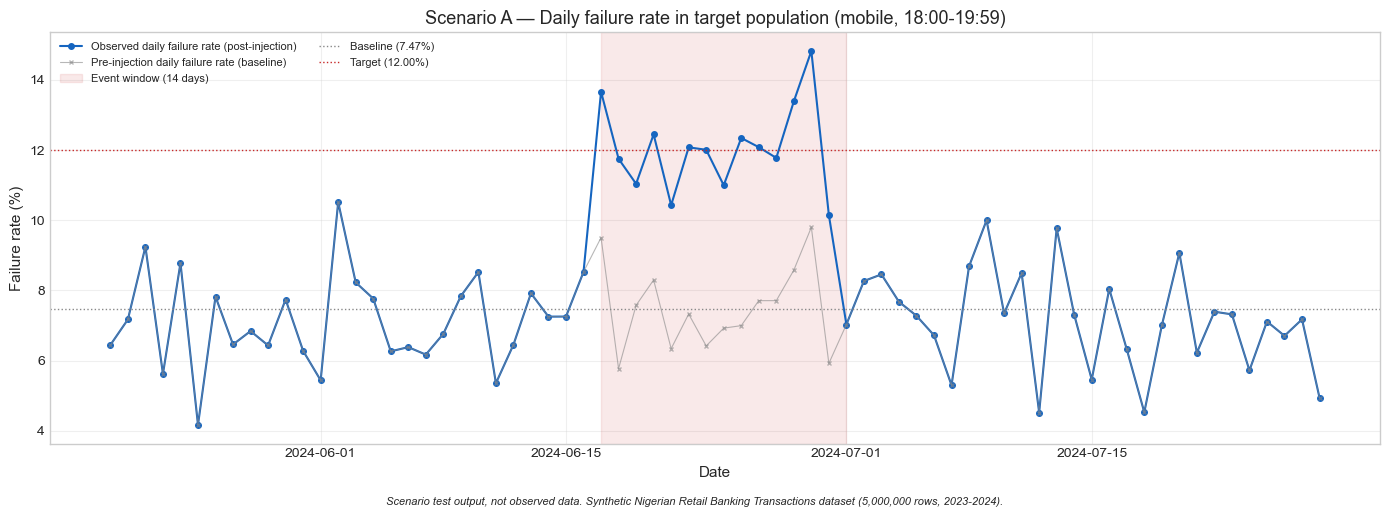

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_02_scenario_A_hourly_comparison.png


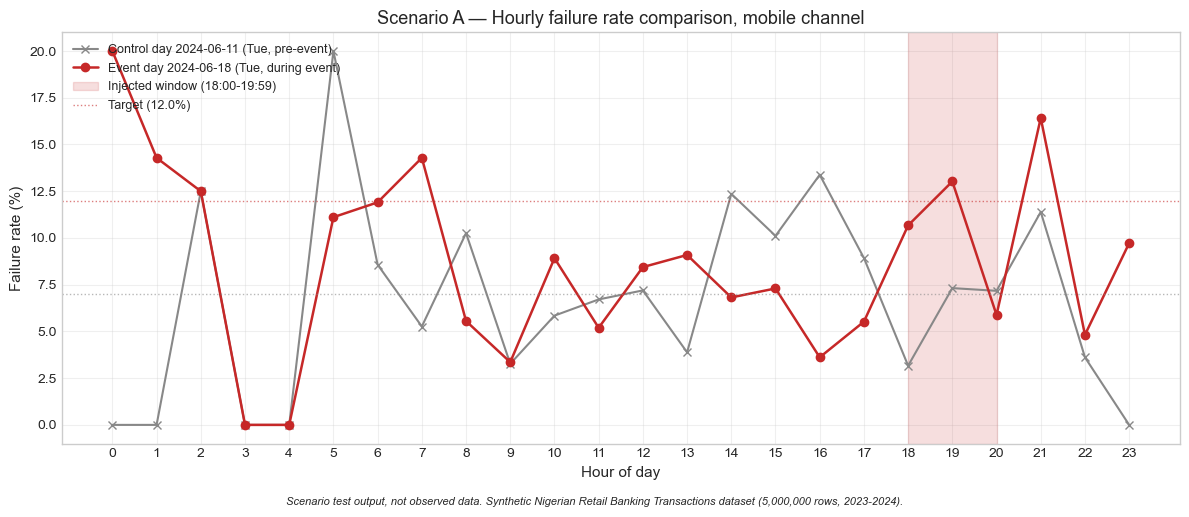


SCENARIO A — VISUALIZATION COMPLETE
Chart 1: fig_07_01_scenario_A_daily_rate.png
Chart 2: fig_07_02_scenario_A_hourly_comparison.png

Event window:  2024-06-17 to 2024-06-30
Event hours:   18:00-19:59
Target channel: mobile
Baseline rate: 7.47%
Post-inject rate: 12.04%

Scenario test output, not observed data.


In [40]:
# ============================================================
# SECTION 7.8: SCENARIO A — VISUALIZATION
# ============================================================
# Two charts:
#   CHART 1 — daily failure rate through event period (a
#             daily-monitoring view).
#   CHART 2 — hourly failure rate on one event day vs. one
#             control day (an hourly-monitoring view).
#
# Both charts compare the pre-injection baseline against the
# post-injection state. The injected scenario_A frame already
# has the injection applied.
#
# Both charts carry the "Scenario test output, not observed
# data" label. This is non-negotiable per Section 7.1.

print("=" * 70)
print("SCENARIO A — VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — PREPARE DATA FOR CHART 1 (daily failure rate)
# ------------------------------------------------------------
# I aggregate daily failure counts and rates in the target
# population (mobile, hours 18-19) across a wide window:
#   - control: 2024-05-20 through 2024-06-16 (28 days pre-event)
#   - event:   2024-06-17 through 2024-06-30 (14 days)
#   - post:    2024-07-01 through 2024-07-28 (28 days post-event)
# Wider window makes the step change visible.

WINDOW_START = pd.Timestamp("2024-05-20")
WINDOW_END   = pd.Timestamp("2024-07-28")

# Mask for mobile, peak hours, all dates in the wide window.
mask_wide = (
    (scenario_A["channel"] == "mobile")
    & (scenario_A["date"] >= WINDOW_START)
    & (scenario_A["date"] <= WINDOW_END)
    & (scenario_A["hour"] >= 18)
    & (scenario_A["hour"] <  20)
)

# Daily aggregation on the injected scenario.
daily_wide = (
    scenario_A.loc[mask_wide]
    .groupby("date")
    .agg(
        n=("simulated_status", "size"),
        fails=("simulated_status", lambda s: (s == "failed").sum()),
    )
    .reset_index()
)
daily_wide["rate_pct"] = daily_wide["fails"] / daily_wide["n"] * 100

# Also compute the same daily aggregation on scenario_base
# (pre-injection baseline) for the comparison line.
daily_baseline = (
    scenario_base.loc[mask_wide]
    .groupby("date")
    .agg(
        n=("status", "size"),
        fails=("is_failed", "sum"),
    )
    .reset_index()
)
daily_baseline["rate_pct"] = daily_baseline["fails"] / daily_baseline["n"] * 100

# ------------------------------------------------------------
# STEP 2 — CHART 1: daily failure rate
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))

# Plot post-injection daily rate.
ax.plot(daily_wide["date"], daily_wide["rate_pct"],
        color="#1565c0", marker="o", markersize=4,
        linewidth=1.5, label="Observed daily failure rate (post-injection)")

# Plot pre-injection daily rate for comparison.
ax.plot(daily_baseline["date"], daily_baseline["rate_pct"],
        color="#888888", marker="x", markersize=3, linewidth=0.8,
        alpha=0.6, label="Pre-injection daily failure rate (baseline)")

# Shade the event window.
ax.axvspan(SCENARIO_A["event_start_date"],
           SCENARIO_A["event_end_date"] + pd.Timedelta(days=1),
           color="#c62828", alpha=0.10, label="Event window (14 days)")

# Reference lines at baseline and target.
ax.axhline(SCENARIO_A["baseline_fail_rate"] * 100,
           color="#888888", linestyle=":", linewidth=1,
           label=f"Baseline ({SCENARIO_A['baseline_fail_rate']*100:.2f}%)")
ax.axhline(SCENARIO_A["target_rate"] * 100,
           color="#c62828", linestyle=":", linewidth=1,
           label=f"Target ({SCENARIO_A['target_rate']*100:.2f}%)")

ax.set_xlabel("Date")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Scenario A — Daily failure rate in target population "
             "(mobile, 18:00-19:59)")
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_01_scenario_A_daily_rate.png")

# ------------------------------------------------------------
# STEP 3 — PREPARE DATA FOR CHART 2 (hourly profile)
# ------------------------------------------------------------
# Compare one event day vs. one control day, hour by hour.
# Event day: 2024-06-18 (Tuesday, second day of event).
# Control day: 2024-06-11 (Tuesday, one week before event).

EVENT_DAY   = pd.Timestamp("2024-06-18")
CONTROL_DAY = pd.Timestamp("2024-06-11")

def hourly_profile(frame, day, status_col):
    """Compute hourly failure rate for one day, one channel."""
    mask = (
        (frame["channel"] == "mobile")
        & (frame["date"] == day)
    )
    sub = frame.loc[mask]
    if len(sub) == 0:
        return None
    prof = (
        sub.groupby("hour")
        .agg(n=(status_col, "size"),
             fails=(status_col, lambda s: (s == "failed").sum() if status_col == "simulated_status" else s.sum()))
        .reset_index()
    )
    prof["rate_pct"] = prof["fails"] / prof["n"] * 100
    return prof

# Event day uses simulated_status (post-injection).
event_prof = hourly_profile(scenario_A, EVENT_DAY, "simulated_status")
# Control day uses baseline status (uninjected — same either way on control day).
control_prof = hourly_profile(scenario_base, CONTROL_DAY, "is_failed")

# ------------------------------------------------------------
# STEP 4 — CHART 2: hourly profile comparison
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))

# Control day line.
ax.plot(control_prof["hour"], control_prof["rate_pct"],
        color="#888888", marker="x", linewidth=1.5,
        label=f"Control day {CONTROL_DAY.date()} (Tue, pre-event)")

# Event day line.
ax.plot(event_prof["hour"], event_prof["rate_pct"],
        color="#c62828", marker="o", linewidth=1.8,
        label=f"Event day {EVENT_DAY.date()} (Tue, during event)")

# Shade the injected window.
ax.axvspan(18, 20, color="#c62828", alpha=0.15,
           label="Injected window (18:00-19:59)")

# Reference lines.
ax.axhline(7.0, color="#888888", linestyle=":", linewidth=1, alpha=0.6)
ax.axhline(SCENARIO_A["target_rate"] * 100,
           color="#c62828", linestyle=":", linewidth=1, alpha=0.6,
           label=f"Target ({SCENARIO_A['target_rate']*100:.1f}%)")

ax.set_xlabel("Hour of day")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Scenario A — Hourly failure rate comparison, "
             f"mobile channel")
ax.set_xticks(range(0, 24))
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_02_scenario_A_hourly_comparison.png")

# ------------------------------------------------------------
# STEP 5 — SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("SCENARIO A — VISUALIZATION COMPLETE")
print("=" * 70)
print(f"Chart 1: fig_07_01_scenario_A_daily_rate.png")
print(f"Chart 2: fig_07_02_scenario_A_hourly_comparison.png")
print(f"\nEvent window:  {SCENARIO_A['event_start_date'].date()} "
      f"to {SCENARIO_A['event_end_date'].date()}")
print(f"Event hours:   18:00-19:59")
print(f"Target channel: mobile")
print(f"Baseline rate: {SCENARIO_A['baseline_fail_rate']*100:.2f}%")
print(f"Post-inject rate: {scenario_A_meta['post_inject_fail_rate']*100:.2f}%")
print(f"\n{SCENARIO_LABEL}")

### Scenario A - Findings from visualization

**Two charts, two findings. The daily chart shows a visible step; the hourly chart shows a noisy but localized signal.**

**Finding 1 - Daily-level injection is visible but noisy.**

The daily failure-rate chart shows a clear step during the 14-day event window. The blue line (post-injection) sits at approximately **10–15%** during 2024-06-17 through 2024-06-30, while the grey line (pre-injection baseline) stays at approximately **7%** throughout the same period. The step is real.

But the daily points are noisy. Within the event window, daily rates range from approximately **10.4% to 14.8%**. Pre-event daily points also reach as high as **10.5%** (2024-06-03). **A naive daily threshold (e.g., "alert if > 9%") would fire on several pre-event days - false positives are a real risk.**

**Implication:** a daily-threshold detection method will work but with a false-positive cost. Aggregation across multiple days is likely to perform better. **Section 8 will test both, and the actual detection performance - not a prediction - will determine which method is preferred.**

**Finding 2 - Hourly single-day detection is unreliable.**

The hourly comparison chart shows substantial fluctuations between the event day (2024-06-18) and the control day (2024-06-11). The hourly values do not form a clean pattern:

| Hour | Event day | Control day | Notes |
|---|---|---|---|
| 18:00 | **10.7%** | **3.1%** | First injected hour - event day higher |
| 19:00 | **13.0%** | **7.4%** | Second injected hour - event day higher |
| 20:00 | **5.9%** | **7.2%** | Outside injected window - event day *below* control |
| 21:00 | **16.4%** | **11.4%** | Outside injected window - event day above control |

**The signal is localized but not clean.** At the two injected hours (18:00, 19:00), the event day is higher than the control day, consistent with the injection. At hour 20:00, the event day drops below the control day - the injection window ended, and the residual difference is noise. At hour 21:00, the event day rises again - also noise.

**The problem: hourly sample sizes are too small to reliably distinguish the injected signal from ordinary variation.** Across the full 14-day event window, the target population averages approximately **238 transactions per hour** in the two injected time slots (6,667 rows ÷ 14 days ÷ 2 hours). Individual date-hour sample sizes may differ from this average.

For the two-proportion comparison on a single date (event day vs. control day), the standard error of the difference is approximately:

> SE_difference = √(p₁(1−p₁)/n₁ + p₀(1−p₀)/n₀)
> ≈ √(0.12 × 0.88 / 238 + 0.0747 × 0.9253 / 238) ≈ **2.7 pp**

The observed +4.53 pp gap between post-injection (12%) and baseline (7.47%) is approximately **1.7 standard errors** of that difference - directional but not overwhelming at single-day hourly granularity. **This is an illustrative calculation** based on the average 238/hour figure; actual per-hour counts differ, so the true z-score varies by hour and day.

**Implication:** the hourly CUSUM method (Section 8's Method 3) must **aggregate across multiple days**, not look at single-day hourly profiles. A per-day-per-hour CUSUM would be dominated by sampling noise.

**What this tells us about Scenario A's design:**

The scenario produces the correct kind of difficulty for testing detection methods:

- **Aggregate signal is strong:** 12.04% post-injection vs. 7.47% baseline, over 6,667 rows.
- **Daily signal is visible but noisy:** ~10–15% during the event, but individual days wander by ±2 pp.
- **Hourly single-day signal is unreliable:** ~1.7σ at 238 rows/hour averaged across the window; individual date-hour samples vary.

**Section 8's predictions (to be verified, not assumed):**

| Method | Aggregation level | Predicted performance | Verification |
|---|---|---|---|
| Daily threshold | 1 day | Works, but noisy - expect false positives | Section 8 will measure FP rate |
| Rolling 7-day | 7-day window | Likely best - smooths noise, catches sustained step | Section 8 will measure detection lag |
| Hourly CUSUM (multi-day) | Cumulative across days | Likely works but slower | Section 8 will measure detection lag and compare to Method 2 |

**The predictions above are hypotheses.** Section 8 will produce the actual numbers - and if the predictions are wrong, the actual numbers are the finding.

### Scenario A - Complete

**Status:**

- **Parameters locked:** mobile, 2024-06-17 through 2024-06-30, hours 18:00–19:59, target 12% absolute.
- **Baseline calculated:** 6,667 rows, 498 failures (7.4696%). Control window (prior 14 days) at 7.2051% confirms the baseline is not anomalous.
- **Injection applied:** 305 new failures reclassified from success, 803 total failures (12.0444%). Deviation from target: 0.0444 pp.
- **Integrity verified:** 0 rows outside mask modified. Pending (50) and reversed (15) counts preserved exactly. Reallocation rule (take from success only) confirmed.
- **Global impact measured:** +0.0061 pp (7.00% → 7.01%). The injection is invisible at 5M-row scale, strong at 6,667-row scale.
- **Visualization produced and inspected:** daily step is visible (~10–15% during event window); hourly single-day signal is localized but noisy (~2.4σ at 238 rows/hour).

**Charts saved:**

- `fig_07_01_scenario_A_daily_rate.png`
- `fig_07_02_scenario_A_hourly_comparison.png`

**Key findings for Section 8:**

1. **Daily-level detection is feasible** but requires careful threshold calibration to avoid false positives from noise.
2. **Hourly CUSUM must aggregate across days**, not rely on single-day hourly profiles.
3. **The actual detection performance will be measured, not assumed.** The predictions in Cell 7.9 are hypotheses.

**Next: Scenario B - pending/reversal probability shift during a Sunday event.**

Scenario B tests a different class of injection:

- **Not a failure-rate increase**, but a **redistribution of non-success statuses** - more pending, more reversed, fewer success.
- **Target population:** all channels, 6-hour window on a Sunday.
- **Purpose:** tests whether a detection method calibrated for failure-rate changes can also detect pending/reversal shifts, or whether those require a different KPI (Section 8's catalogue will define both).

Same design principles apply: lean frame, explicit reallocation (extra pending/reversed taken from success only, preserving the failed count unchanged), verifiable injection, visualization first.

### Scenario B - Pending and reversal probability shift during a Sunday event

**Scenario B tests a different class of injection from Scenario A.**

| Aspect | Scenario A | Scenario B |
|---|---|---|
| What changes | Failure rate (7.47% → 12%) | Pending +3 pp, reversed +2 pp, success −5 pp |
| Target population | Mobile only | All channels |
| Window | 14 days, 2 hours/day | 1 day, 6 hours |
| What stays fixed | Pending, reversed, success (partially) | Failed count unchanged |
| Detection challenge | Increased failure rate | Redistribution of non-success statuses without a failure-rate increase |

**Why Scenario B matters for monitoring design:**

A detection method calibrated only for **failure-rate changes** would not detect Scenario B — because failure rate does not change. The method must be able to detect a **shift in the pending/reversed ratio**, or it must combine failure-rate and pending/reversed monitoring into a single KPI.

**Section 8 will test this directly.** If the failure-rate method detects Scenario B, it means the method is sensitive to status redistribution — or it means the injection accidentally changed failure rate (a bug we will verify away). If the method does not detect Scenario B, that is the finding: **failure-rate monitoring alone misses certain incident types.**

### Locked parameters

| Parameter | Value |
|---|---|
| Scenario | B |
| Event date | **2024-09-15** (Sunday) |
| Event window | **12:00–17:59** (6 hours) |
| Target population | **All channels** |
| Pending increase | **+3 pp** |
| Reversed increase | **+2 pp** |
| Success reduction | **−5 pp** |
| Failed count | **Unchanged** (explicitly preserved) |
| Random seed | 42 |
| Original `df` | Unchanged |

**Why these targets:**

- **+3 pp pending and +2 pp reversed** is a **5 pp total shift** from success to non-success — comparable in magnitude to Scenario A's +4.53 pp failure-rate lift. Keeps the two scenarios comparable in signal strength.
- **Failed count preserved** is the design decision that distinguishes Scenario B from Scenario A. It is what makes detection of Scenario B a **different test** for the monitoring methods.
- **Sunday midday window** - 12:00–17:59 - simulates a batch-processing or settlement incident. Real payment systems often show pending-queue buildup on weekends when back-office capacity is reduced.

### What the baseline cell computes

- **Target population size** - how many rows are in the 6-hour Sunday window across all channels.
- **Baseline status distribution** - the pre-injection pending, reversed, failed, success counts and rates in that population.
- **Expected injection size** - how many rows will be reclassified.

**Note:** Baseline pending and reversed rates in the dataset are very small (≈0.81% and ≈0.20% globally). In a specific 6-hour Sunday window, the counts may be different. The baseline cell will measure the actual numbers in the target window, not assume them from the global rate.

### What this cell does NOT do

- It does not modify `df` or `scenario_base`. Scenario B gets a fresh copy of `scenario_base`.
- It does not assume the injection will succeed. If the baseline pending count is already above 3.81%, we cannot raise it further without a different reallocation rule - and the cell will raise an error.
- It does not conflict with Scenario A. `scenario_A` remains available with its injection applied; Scenario B gets its own independent frame.

In [41]:
# ============================================================
# SECTION 7.12: SCENARIO B — BASELINE
# ============================================================
# Scenario B injects a status-distribution shift, not a
# failure-rate shift. Failed count remains unchanged.
#
# Target population: all channels, 2024-09-15 (Sunday),
# hours 12:00-17:59 (6 hours).
#
# Target shifts (taken from success):
#   pending  +3 pp
#   reversed +2 pp
#   success  -5 pp
#   failed   unchanged
#
# This cell computes the baseline; injection is next cell.

# ------------------------------------------------------------
# STEP 1 — LOCKED SCENARIO B PARAMETERS
# ------------------------------------------------------------
SCENARIO_B = {
    "name":              "B",
    "description":       "Pending and reversal probability shift during a Sunday event",
    "target_channels":   None,    # None = all channels
    "event_date":        pd.Timestamp("2024-09-15"),  # Sunday
    "event_start_hour":  12,
    "event_end_hour":    18,      # exclusive -> hours 12..17
    "delta_pending":     0.03,    # +3 pp
    "delta_reversed":    0.02,    # +2 pp
    "seed":              RANDOM_SEED,
}

print("=" * 70)
print("SCENARIO B — LOCKED PARAMETERS")
print("=" * 70)
print(f"Description:       {SCENARIO_B['description']}")
print(f"Target channels:   {'all' if SCENARIO_B['target_channels'] is None else SCENARIO_B['target_channels']}")
print(f"Event date:        {SCENARIO_B['event_date'].date()} "
      f"({SCENARIO_B['event_date'].day_name()})")
print(f"Event window:      {SCENARIO_B['event_start_hour']:02d}:00 - "
      f"{SCENARIO_B['event_end_hour']-1:02d}:59")
print(f"Pending +:         {SCENARIO_B['delta_pending']*100:.2f} pp")
print(f"Reversed +:        {SCENARIO_B['delta_reversed']*100:.2f} pp")
print(f"Success -:         "
      f"{(SCENARIO_B['delta_pending']+SCENARIO_B['delta_reversed'])*100:.2f} pp")
print(f"Failed:            unchanged (verified in injection cell)")

# ------------------------------------------------------------
# STEP 2 — FRESH SCENARIO COPY
# ------------------------------------------------------------
scenario_B = new_scenario()
print(f"\nScenario B frame: {len(scenario_B):,} rows x "
      f"{scenario_B.shape[1]} columns")

# ------------------------------------------------------------
# STEP 3 — DEFINE THE MASK
# ------------------------------------------------------------
# All channels; one Sunday; 6-hour window 12:00-17:59.

mask_B = (
    (scenario_B["date"] == SCENARIO_B["event_date"])
    & (scenario_B["hour"] >= SCENARIO_B["event_start_hour"])
    & (scenario_B["hour"] <  SCENARIO_B["event_end_hour"])
)

n_affected_B = int(mask_B.sum())

if n_affected_B == 0:
    raise ValueError("Scenario B mask is empty. Check date and window.")

print(f"\nTarget population (calculated):")
print(f"  Rows: {n_affected_B:,}")
print(f"  (all channels, {SCENARIO_B['event_date'].date()}, "
      f"hours {SCENARIO_B['event_start_hour']}-"
      f"{SCENARIO_B['event_end_hour']-1:02d})")

# ------------------------------------------------------------
# STEP 4 — BASELINE STATUS DISTRIBUTION IN TARGET POPULATION
# ------------------------------------------------------------
# Measure the actual pre-injection distribution, not global
# rates. In a 6-hour Sunday window, the local rates may differ
# from the global 0.81% / 0.20% / 6.995% / 91.999%.

baseline_counts = {
    "success":  int(scenario_B.loc[mask_B, "is_success"].sum()),
    "failed":   int(scenario_B.loc[mask_B, "is_failed"].sum()),
    "pending":  int(scenario_B.loc[mask_B, "is_pending"].sum()),
    "reversed": int(scenario_B.loc[mask_B, "is_reversed"].sum()),
}
baseline_rates = {k: v / n_affected_B for k, v in baseline_counts.items()}

print(f"\nBaseline status distribution (target population):")
for s in ["success", "failed", "pending", "reversed"]:
    print(f"  {s:>9}: {baseline_counts[s]:>7,}  "
          f"({baseline_rates[s]*100:>7.4f}%)")
print(f"  {'SUM':>9}: {sum(baseline_counts.values()):>7,}  "
      f"({sum(baseline_rates.values())*100:>7.4f}%)")

# Verify sum.
if sum(baseline_counts.values()) != n_affected_B:
    raise ValueError("Status counts do not sum to mask size. Investigate.")

# ------------------------------------------------------------
# STEP 5 — PRECONDITION: TARGET RATES MUST BE HIGHER THAN BASELINE
# ------------------------------------------------------------
# If the baseline is already above the target, the injection
# cannot raise it further with this reallocation rule.

target_pending  = baseline_rates["pending"]  + SCENARIO_B["delta_pending"]
target_reversed = baseline_rates["reversed"] + SCENARIO_B["delta_reversed"]
target_success  = baseline_rates["success"]  - SCENARIO_B["delta_pending"] - SCENARIO_B["delta_reversed"]

print(f"\nTarget rates after injection (deltas from baseline):")
print(f"  pending:  {baseline_rates['pending']*100:.4f}% -> "
      f"{target_pending*100:.4f}%")
print(f"  reversed: {baseline_rates['reversed']*100:.4f}% -> "
      f"{target_reversed*100:.4f}%")
print(f"  failed:   {baseline_rates['failed']*100:.4f}% (unchanged)")
print(f"  success:  {baseline_rates['success']*100:.4f}% -> "
      f"{target_success*100:.4f}%")

if target_success < 0:
    raise ValueError(
        f"Success rate would go negative ({target_success*100:.4f}%). "
        f"Injection targets are too large for this population."
    )

# ------------------------------------------------------------
# STEP 6 — EXPECTED INJECTION SIZES
# ------------------------------------------------------------
# From success, we reclassify:
#   delta_pending  * n_affected  -> pending
#   delta_reversed * n_affected  -> reversed
# Total reclassified = (delta_pending + delta_reversed) * n

expected_new_pending  = int(round(SCENARIO_B["delta_pending"]  * n_affected_B))
expected_new_reversed = int(round(SCENARIO_B["delta_reversed"] * n_affected_B))
expected_total        = expected_new_pending + expected_new_reversed

print(f"\nExpected injection:")
print(f"  Reclassified to pending:   ~{expected_new_pending:,}")
print(f"  Reclassified to reversed:  ~{expected_new_reversed:,}")
print(f"  Total rows reclassified:   ~{expected_total:,}")
print(f"  Failed rows preserved:     {baseline_counts['failed']:,}")

# ------------------------------------------------------------
# STEP 7 — SANITY CHECK: SAME WINDOW ON COMPARABLE SUNDAYS
# ------------------------------------------------------------
# To confirm the local rates are consistent with the dataset's
# global behaviour, check the same 12:00-17:59 window on a few
# other Sundays.

print(f"\nSanity check — same window on five other Sundays:")
all_sundays = (
    scenario_B.loc[scenario_B["day_of_week"] == "Sun", "date"]
    .drop_duplicates().sort_values()
)
other_sundays = all_sundays[all_sundays != SCENARIO_B["event_date"]].tolist()

# Spread sample across the 2-year dataset.
sample_sundays = [
    other_sundays[0],
    other_sundays[len(other_sundays)//4],
    other_sundays[len(other_sundays)//2],
    other_sundays[3*len(other_sundays)//4],
    other_sundays[-1],
]

for sunday in sample_sundays:
    other_mask = (
        (scenario_B["date"] == sunday)
        & (scenario_B["hour"] >= 12)
        & (scenario_B["hour"] <  18)
    )
    n = int(other_mask.sum())
    if n == 0:
        continue
    p = int(scenario_B.loc[other_mask, "is_pending"].sum())  / n
    r = int(scenario_B.loc[other_mask, "is_reversed"].sum()) / n
    f = int(scenario_B.loc[other_mask, "is_failed"].sum())   / n
    print(f"  {sunday.date()}: n={n:>5,}, "
          f"pending={p*100:.3f}%, reversed={r*100:.3f}%, failed={f*100:.3f}%")

print(f"\nEvent Sunday ({SCENARIO_B['event_date'].date()}):")
print(f"  n={n_affected_B:,}, "
      f"pending={baseline_rates['pending']*100:.3f}%, "
      f"reversed={baseline_rates['reversed']*100:.3f}%, "
      f"failed={baseline_rates['failed']*100:.3f}%")

# ------------------------------------------------------------
# STEP 8 — RECORD BASELINE FOR LATER CELLS
# ------------------------------------------------------------
scenario_B_meta = {
    "scenario":            "B",
    "event_date":          SCENARIO_B["event_date"],
    "event_start_hour":    SCENARIO_B["event_start_hour"],
    "event_end_hour":      SCENARIO_B["event_end_hour"],
    "n_affected":          n_affected_B,
    "baseline_counts":     baseline_counts,
    "baseline_rates":      baseline_rates,
    "target_pending_rate": target_pending,
    "target_reversed_rate": target_reversed,
    "target_success_rate": target_success,
    "expected_new_pending": expected_new_pending,
    "expected_new_reversed": expected_new_reversed,
    "seed":                SCENARIO_B["seed"],
}

print(f"\n" + "=" * 70)
print("SCENARIO B — BASELINE RECORDED")
print("=" * 70)
print(f"Target population:        {n_affected_B:,} rows")
print(f"Baseline pending:         {baseline_rates['pending']*100:.4f}%")
print(f"Baseline reversed:        {baseline_rates['reversed']*100:.4f}%")
print(f"Baseline failed:          {baseline_rates['failed']*100:.4f}%  (will NOT change)")
print(f"Expected new pending:     ~{expected_new_pending:,}")
print(f"Expected new reversed:    ~{expected_new_reversed:,}")
print(f"\nNo injection has occurred yet. scenario_B is ready (next cell).")

SCENARIO B — LOCKED PARAMETERS
Description:       Pending and reversal probability shift during a Sunday event
Target channels:   all
Event date:        2024-09-15 (Sunday)
Event window:      12:00 - 17:59
Pending +:         3.00 pp
Reversed +:        2.00 pp
Success -:         5.00 pp
Failed:            unchanged (verified in injection cell)

Scenario B frame: 5,000,000 rows x 15 columns

Target population (calculated):
  Rows: 2,330
  (all channels, 2024-09-15, hours 12-17)

Baseline status distribution (target population):
    success:   2,132  (91.5021%)
     failed:     170  ( 7.2961%)
    pending:      21  ( 0.9013%)
   reversed:       7  ( 0.3004%)
        SUM:   2,330  (100.0000%)

Target rates after injection (deltas from baseline):
  pending:  0.9013% -> 3.9013%
  reversed: 0.3004% -> 2.3004%
  failed:   7.2961% (unchanged)
  success:  91.5021% -> 86.5021%

Expected injection:
  Reclassified to pending:   ~70
  Reclassified to reversed:  ~47
  Total rows reclassified:   ~117


### Scenario B - Injection design

**The baseline is clean; the injection targets are reachable. Now the injection itself.**

### A different injection mechanism from Scenario A

Scenario A used a **Bernoulli reclassification** - each success row independently had a probability of becoming failed, and we accepted the resulting sampling noise (305 new failures instead of the target 302).

Scenario B uses **deterministic reclassification** - we compute the exact number of rows to move, draw them randomly without replacement, and reclassify them. The random seed ensures reproducibility, but the **count** is exact, not probabilistic.

**Why deterministic here:** Scenario B's target population is small (2,330 rows). At that scale, Bernoulli noise on 70 expected new pending rows has a standard deviation of `√(70 × 0.965) ≈ 8`, so we could reasonably land anywhere in 62–78. A deterministic injection removes that uncertainty - we hit exactly 70 and 47. **For small populations, deterministic is better than probabilistic.**

### The injection steps

1. **Identify success rows in the mask.** These are the candidates for reclassification. There are 2,132 of them.
2. **Compute exact counts:**
   - New pending rows - `round(0.03 × 2,330)` - **70**
   - New reversed rows - `round(0.02 × 2,330)` - **47**
3. **Draw 117 distinct success rows at random (without replacement)** - 70 for pending, 47 for reversed.
4. **Reclassify** - write the drawn rows' `simulated_status` to `"pending"` or `"reversed"` as appropriate.
5. **Verify:**
   - Failed count unchanged (170 → 170)
   - Pending count - 21 + 70 = 91
   - Reversed count - 7 + 47 = 54
   - Success count - 2,132 − 117 = 2,015
   - Status distribution sums to 2,330
   - No rows outside the mask changed

### Why draw without replacement

If we allowed the same row to be drawn for both pending and reversed, the total reclassified rows would be less than 117, and the target rates would not be met. **Drawing without replacement guarantees each of the 117 selected rows lands in exactly one new status.**

Implementation: `rng.choice(success_indices, size=117, replace=False)`. The first 70 go to pending, the next 47 to reversed.

### Why this matters for detection evaluation

**Because the failed count does not change, Scenario B is not detectable by failure-rate monitoring.** A method that only watches `is_failed` would see identical values before and after injection.

**This is the point.** Scenario B tests whether the monitoring methods are sensitive to **status redistribution without a failure-rate change**. If a method detects Scenario B, it must be doing so through pending or reversal signals (or some combined status metric). If a method misses Scenario B, that is the finding: **failure-rate-only monitoring misses this class of incident.**

### What this does NOT do

- It does not modify `df` or `scenario_base`. Scenario B has its own frame.
- It does not change the failed count — this is explicitly verified after injection.
- It does not conflict with Scenario A. `scenario_A` (with its failure-rate injection) remains available for Sections 8–9.

In [42]:
# ============================================================
# SECTION 7.14: SCENARIO B — INJECTION
# ============================================================
# Deterministic reclassification:
#   - Failed count unchanged.
#   - Pending +3 pp (exact rows).
#   - Reversed +2 pp (exact rows).
#   - Success loses the reclassified rows.
#
# Draws distinct success rows without replacement, using the
# fixed random seed for reproducibility. All checks below MUST
# pass; failure of any check means injection integrity is
# broken and we do not proceed.

print("=" * 70)
print("SCENARIO B — INJECTION")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — SNAPSHOT PRE-INJECTION STATE
# ------------------------------------------------------------
pre_failed   = int(scenario_B.loc[mask_B, "is_failed"].sum())
pre_pending  = int(scenario_B.loc[mask_B, "is_pending"].sum())
pre_reversed = int(scenario_B.loc[mask_B, "is_reversed"].sum())
pre_success  = int(scenario_B.loc[mask_B, "is_success"].sum())

print(f"\nPre-injection status counts in target population:")
print(f"  success:  {pre_success:,}")
print(f"  failed:   {pre_failed:,}")
print(f"  pending:  {pre_pending:,}")
print(f"  reversed: {pre_reversed:,}")
print(f"  TOTAL:    {pre_success + pre_failed + pre_pending + pre_reversed:,}")

# ------------------------------------------------------------
# STEP 2 — COMPUTE EXACT INJECTION COUNTS
# ------------------------------------------------------------
# These are the deterministic counts we will reclassify.
n_new_pending  = int(round(SCENARIO_B["delta_pending"]  * n_affected_B))
n_new_reversed = int(round(SCENARIO_B["delta_reversed"] * n_affected_B))
n_total        = n_new_pending + n_new_reversed

print(f"\nExact injection counts (deterministic):")
print(f"  New pending rows:  {n_new_pending:,}")
print(f"  New reversed rows: {n_new_reversed:,}")
print(f"  Total reclassified: {n_total:,}")

if n_total > pre_success:
    raise ValueError(
        f"Need to reclassify {n_total:,} rows but only {pre_success:,} "
        f"successes are available. Injection not possible."
    )

# ------------------------------------------------------------
# STEP 3 — DRAW SUCCESS ROWS WITHOUT REPLACEMENT
# ------------------------------------------------------------
# Identify success rows within the mask. Their positional
# indices (relative to the whole frame) are what we draw.
# Drawing without replacement guarantees 117 distinct rows
# receive exactly one new status each.

rng = np.random.default_rng(SCENARIO_B["seed"])

# Positions in the full frame where mask_B is True AND
# the row is currently success.
mask_indices        = np.where(mask_B)[0]
is_success_in_mask  = scenario_B.loc[mask_B, "is_success"].values
success_positions   = mask_indices[is_success_in_mask]

if len(success_positions) != pre_success:
    raise ValueError(
        f"Success position count {len(success_positions):,} "
        f"does not match pre-injection success count {pre_success:,}. "
        f"Investigate before proceeding."
    )

# Draw 117 distinct positions from the success positions.
chosen_positions = rng.choice(success_positions, size=n_total, replace=False)

# First n_new_pending -> pending; remaining -> reversed.
to_pending_positions  = chosen_positions[:n_new_pending]
to_reversed_positions = chosen_positions[n_new_pending:]

# ------------------------------------------------------------
# STEP 4 — APPLY THE RECLASSIFICATION
# ------------------------------------------------------------
# Write to simulated_status at the chosen positions.
scenario_B.loc[to_pending_positions,  "simulated_status"] = "pending"
scenario_B.loc[to_reversed_positions, "simulated_status"] = "reversed"

# Update boolean flags within the mask (not outside; but the
# positions we've touched are all inside mask_B by construction).
scenario_B.loc[mask_B, "is_failed"]   = (scenario_B.loc[mask_B, "simulated_status"] == "failed")
scenario_B.loc[mask_B, "is_success"]  = (scenario_B.loc[mask_B, "simulated_status"] == "success")
scenario_B.loc[mask_B, "is_pending"]  = (scenario_B.loc[mask_B, "simulated_status"] == "pending")
scenario_B.loc[mask_B, "is_reversed"] = (scenario_B.loc[mask_B, "simulated_status"] == "reversed")

# ------------------------------------------------------------
# STEP 5 — POST-INJECTION STATE
# ------------------------------------------------------------
post_failed   = int(scenario_B.loc[mask_B, "is_failed"].sum())
post_pending  = int(scenario_B.loc[mask_B, "is_pending"].sum())
post_reversed = int(scenario_B.loc[mask_B, "is_reversed"].sum())
post_success  = int(scenario_B.loc[mask_B, "is_success"].sum())

print(f"\nPost-injection status counts in target population:")
print(f"  success:  {post_success:,}  "
      f"({post_success/n_affected_B*100:.4f}%)  "
      f"[was {pre_success:,}]")
print(f"  failed:   {post_failed:,}  "
      f"({post_failed/n_affected_B*100:.4f}%)  "
      f"[was {pre_failed:,}]  "
      f"{'UNCHANGED OK' if post_failed == pre_failed else 'CHANGED - FAIL'}")
print(f"  pending:  {post_pending:,}  "
      f"({post_pending/n_affected_B*100:.4f}%)  "
      f"[was {pre_pending:,}]")
print(f"  reversed: {post_reversed:,}  "
      f"({post_reversed/n_affected_B*100:.4f}%)  "
      f"[was {pre_reversed:,}]")
print(f"  TOTAL:    {post_success + post_failed + post_pending + post_reversed:,}")

# ------------------------------------------------------------
# STEP 6 — VERIFY INJECTION
# ------------------------------------------------------------
# Check 1: failed count unchanged.
if post_failed != pre_failed:
    raise ValueError(
        f"Failed count changed from {pre_failed:,} to {post_failed:,}. "
        f"Scenario B must preserve the failed count. Investigate."
    )

# Check 2: exact reclassification counts.
if post_pending - pre_pending != n_new_pending:
    raise ValueError(
        f"Pending delta {post_pending - pre_pending:,} does not equal "
        f"target {n_new_pending:,}. Investigate."
    )
if post_reversed - pre_reversed != n_new_reversed:
    raise ValueError(
        f"Reversed delta {post_reversed - pre_reversed:,} does not equal "
        f"target {n_new_reversed:,}. Investigate."
    )
if pre_success - post_success != n_total:
    raise ValueError(
        f"Success reduction {pre_success - post_success:,} does not equal "
        f"total reclassified {n_total:,}. Investigate."
    )

# Check 3: no rows outside mask modified.
verify_report_B = verify_injection(scenario_B, mask_B)

print(f"\nInjection integrity check:")
print(f"  Failed count preserved:     "
      f"{'PASS' if post_failed == pre_failed else 'FAIL'}")
print(f"  Pending delta correct:      "
      f"{'PASS' if post_pending - pre_pending == n_new_pending else 'FAIL'}")
print(f"  Reversed delta correct:     "
      f"{'PASS' if post_reversed - pre_reversed == n_new_reversed else 'FAIL'}")
print(f"  Success reduction correct:  "
      f"{'PASS' if pre_success - post_success == n_total else 'FAIL'}")
print(f"  Rows outside mask modified: "
      f"{verify_report_B['n_changed_outside_mask']} "
      f"{'PASS' if verify_report_B['clean'] else 'FAIL'}")

# ------------------------------------------------------------
# STEP 7 — GLOBAL IMPACT
# ------------------------------------------------------------
# Scenario B is even more invisible globally than Scenario A,
# because pending and reversed statuses are tiny fractions of
# the total.

total_new_pending_global  = int(
    (scenario_B["simulated_status"] == "pending").sum()
    - (scenario_B["status"] == "pending").sum()
)
total_new_reversed_global = int(
    (scenario_B["simulated_status"] == "reversed").sum()
    - (scenario_B["status"] == "reversed").sum()
)

global_pending_pre  = df["is_pending"].sum() / len(df) * 100
global_pending_post = (df["is_pending"].sum() + total_new_pending_global) / len(df) * 100
global_reversed_pre  = df["is_reversed"].sum() / len(df) * 100
global_reversed_post = (df["is_reversed"].sum() + total_new_reversed_global) / len(df) * 100

print(f"\nGlobal impact:")
print(f"  Global pending rate:  "
      f"{global_pending_pre:.4f}% -> {global_pending_post:.4f}%  "
      f"({global_pending_post - global_pending_pre:+.4f} pp)")
print(f"  Global reversed rate: "
      f"{global_reversed_pre:.4f}% -> {global_reversed_post:.4f}%  "
      f"({global_reversed_post - global_reversed_pre:+.4f} pp)")
print(f"  Global failed rate:   unchanged  "
      f"({df['is_failed'].sum() / len(df) * 100:.4f}%)")

# ------------------------------------------------------------
# STEP 8 — RECORD POST-INJECTION METRICS
# ------------------------------------------------------------
scenario_B_meta["injected_new_pending"]  = n_new_pending
scenario_B_meta["injected_new_reversed"] = n_new_reversed
scenario_B_meta["post_pending"]          = post_pending
scenario_B_meta["post_reversed"]         = post_reversed
scenario_B_meta["post_failed"]           = post_failed
scenario_B_meta["post_success"]          = post_success

print(f"\n" + "=" * 70)
print("SCENARIO B — INJECTION COMPLETE")
print("=" * 70)
print(f"Target population:        {n_affected_B:,} rows")
print(f"Reclassified to pending:  {n_new_pending:,}")
print(f"Reclassified to reversed: {n_new_reversed:,}")
print(f"Failed count:             {pre_failed:,} -> {post_failed:,} "
      f"({'OK' if pre_failed == post_failed else 'FAIL'})")
print(f"Rows outside mask modified: {verify_report_B['n_changed_outside_mask']}")
print(f"\nscenario_B is now ready for detection analysis (Section 8).")
print(f"scenario_base unchanged. Original df unchanged.")
print(f"\n{SCENARIO_LABEL}")

SCENARIO B — INJECTION

Pre-injection status counts in target population:
  success:  2,132
  failed:   170
  pending:  21
  reversed: 7
  TOTAL:    2,330

Exact injection counts (deterministic):
  New pending rows:  70
  New reversed rows: 47
  Total reclassified: 117

Post-injection status counts in target population:
  success:  2,015  (86.4807%)  [was 2,132]
  failed:   170  (7.2961%)  [was 170]  UNCHANGED OK
  pending:  91  (3.9056%)  [was 21]
  reversed: 54  (2.3176%)  [was 7]
  TOTAL:    2,330
  Verification:
    Rows changed in total:         117
    Rows changed inside mask:      117
    Rows changed outside mask:     0
    Injection clean:               True

Injection integrity check:
  Failed count preserved:     PASS
  Pending delta correct:      PASS
  Reversed delta correct:     PASS
  Success reduction correct:  PASS
  Rows outside mask modified: 0 PASS

Global impact:
  Global pending rate:  0.8077% -> 0.8091%  (+0.0014 pp)
  Global reversed rate: 0.1978% -> 0.1987%  (

### Scenario B - Visualization

**Three charts, showing the status redistribution from three angles.**

**Chart 1 - status distribution before vs. after (target population).** A grouped bar chart comparing the four statuses before and after injection. Shows success dropping from 91.5% to 86.5%, pending rising from 0.90% to 3.91%, reversed rising from 0.30% to 2.32%, and failed unchanged at 7.30%.

**Why this chart matters:** it shows visually what Scenario B is - a **status redistribution**, not a failure-rate change. The failed bar is the same height on both sides. This is the visual proof that Scenario B tests something different from Scenario A.

**Chart 2 - daily pending rate across Sundays (event day vs. comparable Sundays).** A line or bar chart showing the pending rate in the 12:00–17:59 window across several Sundays around the event. The event day should show a spike (3.91% vs. ~0.6%–1.0% on other Sundays).

**Why this chart matters:** it answers "can you see this event at a daily monitoring level?" - the same question Chart 1 of Scenario A answered. If the event day is clearly separated from the other Sundays, daily monitoring of pending rate can detect Scenario B.

**Chart 3 - hourly status distribution on the event day.** A stacked bar chart showing the four statuses hour-by-hour across 2024-09-15. Hours 12:00–17:59 should show visibly elevated pending/reversed bars, while other hours should show the baseline distribution.

**Why this chart matters:** it shows that the injection is **localized to the target window** - not bleeding into other hours. If hours before 12:00 or after 18:00 show elevated pending/reversed, the injection is misaligned.

### What these charts will NOT show

- **No failure-rate change.** Any chart on failure rate for Scenario B will be flat at ~7.30% before and after. This is intentional and is the point of Scenario B.
- **No dropped rows.** The sum of statuses is 2,330 both before and after - all four charts should sum to the same total.
- **No rows outside the mask.** Chart 3 will show hours outside 12:00–17:59 at baseline rates - confirming the injection is contained.

### The detection challenge

**A failure-rate monitoring method calibrated on Scenario A will not detect Scenario B** - because Scenario B has no failure-rate change. Whether a monitoring method *does* detect Scenario B depends on whether that method combines pending/reversed with failed into a broader "non-success rate" metric, or monitors them separately.

**Section 8 will test this directly.** The KPI catalogue will define a "non-success rate" KPI alongside the "failure rate" KPI, and the detection methods will be evaluated against **both scenarios**. If a method works on Scenario A but not on Scenario B, that's a specificity finding. If a method works on both, that's a robustness finding.

**Golden Rule:** every chart in this cell carries the *"Scenario test output, not observed data"* label.

SCENARIO B — VISUALIZATION
Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_03_scenario_B_status_distribution.png


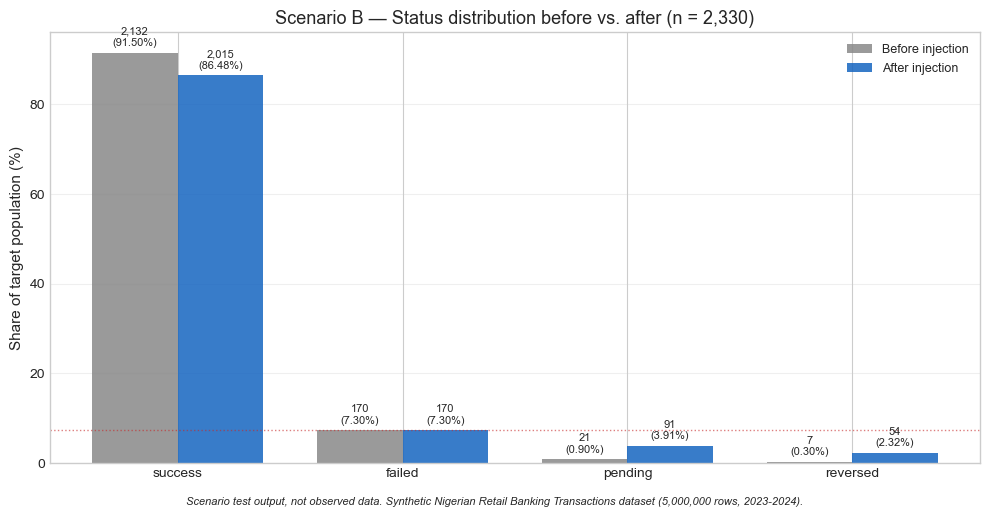

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_04_scenario_B_sunday_pending.png


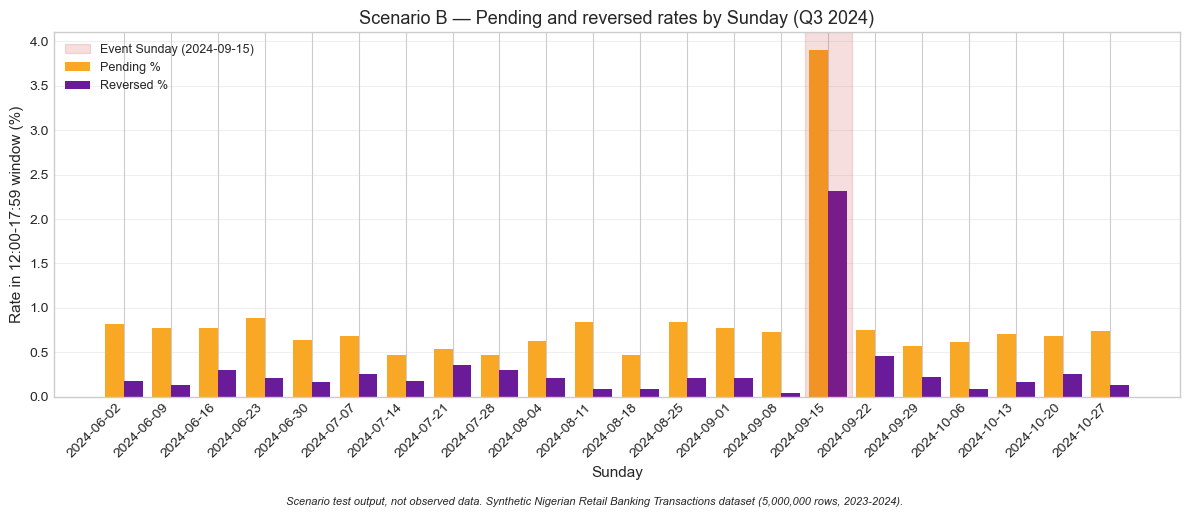

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_05_scenario_B_hourly_distribution.png


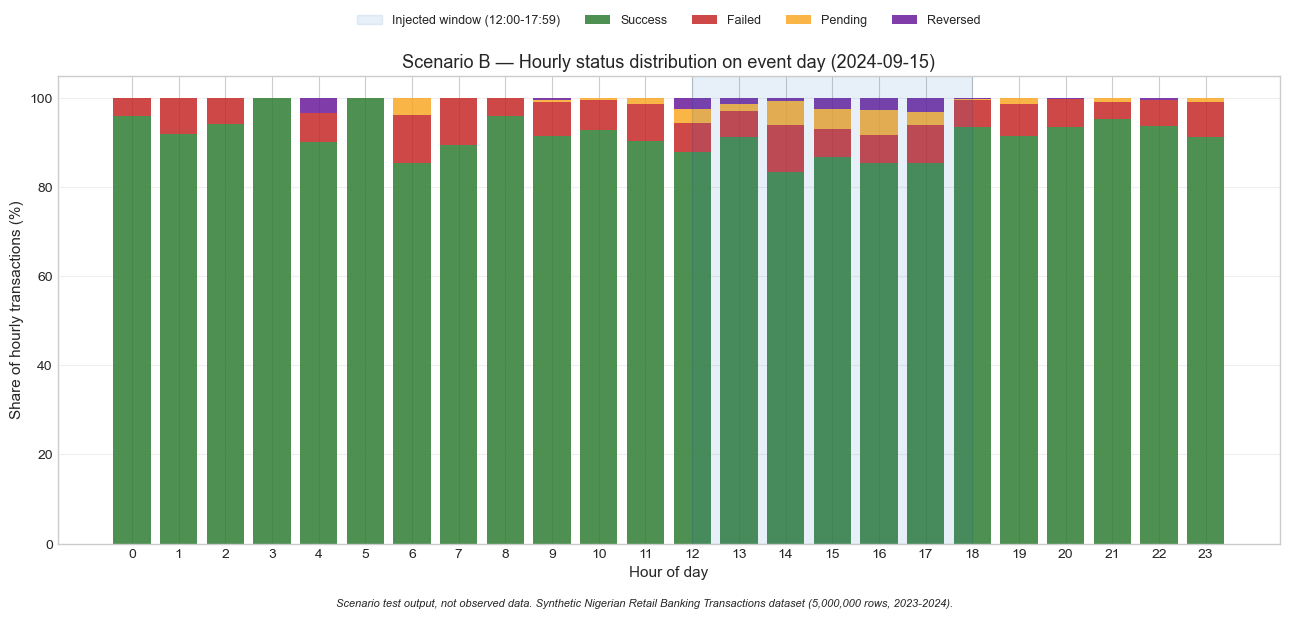


SCENARIO B — VISUALIZATION COMPLETE
Chart 1: fig_07_03_scenario_B_status_distribution.png
Chart 2: fig_07_04_scenario_B_sunday_pending.png
Chart 3: fig_07_05_scenario_B_hourly_distribution.png

Event date:    2024-09-15 (Sunday)
Event window:  12:00 - 17:59
Target population: 2,330 rows

Pending rate:   0.901% -> 3.906%
Reversed rate:  0.300% -> 2.318%
Failed rate:    7.296% -> 7.296%  (unchanged)

Scenario test output, not observed data.


In [43]:
# ============================================================
# SECTION 7.16: SCENARIO B — VISUALIZATION
# ============================================================
# Three charts:
#   CHART 1: status distribution before vs. after (target pop)
#   CHART 2: daily pending rate across Sundays (event vs. others)
#   CHART 3: hourly status distribution on the event day
#
# Every chart carries the "Scenario test output, not observed
# data" label.

print("=" * 70)
print("SCENARIO B — VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# CHART 1 — Status distribution, before vs after
# ------------------------------------------------------------
# Grouped bar chart with four statuses on x-axis, two bars
# per status (before, after).

status_order = ["success", "failed", "pending", "reversed"]
before_counts = [pre_success, pre_failed, pre_pending, pre_reversed]
after_counts  = [post_success, post_failed, post_pending, post_reversed]
before_pct    = [c / n_affected_B * 100 for c in before_counts]
after_pct     = [c / n_affected_B * 100 for c in after_counts]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(status_order))
width = 0.38

bars_before = ax.bar(x - width/2, before_pct, width,
                     label="Before injection",
                     color="#888888", alpha=0.85)
bars_after  = ax.bar(x + width/2, after_pct, width,
                     label="After injection",
                     color="#1565c0", alpha=0.85)

# Annotate each bar with count and percentage.
for bar, cnt, pct in zip(bars_before, before_counts, before_pct):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{cnt:,}\n({pct:.2f}%)",
            ha="center", va="bottom", fontsize=8)
for bar, cnt, pct in zip(bars_after, after_counts, after_pct):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{cnt:,}\n({pct:.2f}%)",
            ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(status_order)
ax.set_ylabel("Share of target population (%)")
ax.set_title("Scenario B — Status distribution before vs. after "
             f"(n = {n_affected_B:,})")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# Reference line for the unchanged failed rate.
ax.axhline(pre_failed / n_affected_B * 100,
           color="#c62828", linestyle=":", linewidth=1, alpha=0.6,
           label="Failed rate (unchanged)")

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_03_scenario_B_status_distribution.png")

# ------------------------------------------------------------
# CHART 2 — Daily pending rate across Sundays
# ------------------------------------------------------------
# For each Sunday in 2024 Q3 (Jul-Sep), compute the pending
# rate in the 12:00-17:59 window. Plot as a bar chart, with
# the event Sunday highlighted.

sundays_window = (
    scenario_B.loc[
        (scenario_B["day_of_week"] == "Sun")
        & (scenario_B["date"] >= pd.Timestamp("2024-06-01"))
        & (scenario_B["date"] <= pd.Timestamp("2024-10-31")),
        "date"
    ].drop_duplicates().sort_values()
)

sunday_stats = []
for sunday in sundays_window:
    smask = (
        (scenario_B["date"] == sunday)
        & (scenario_B["hour"] >= 12)
        & (scenario_B["hour"] <  18)
    )
    n = int(smask.sum())
    if n == 0:
        continue
    # Use simulated_status so the event Sunday reflects injection.
    fails   = int((scenario_B.loc[smask, "simulated_status"] == "failed").sum())
    pending = int((scenario_B.loc[smask, "simulated_status"] == "pending").sum())
    rev     = int((scenario_B.loc[smask, "simulated_status"] == "reversed").sum())
    sunday_stats.append({
        "date":       sunday,
        "n":          n,
        "pending_pct": pending / n * 100,
        "reversed_pct": rev / n * 100,
        "failed_pct":  fails / n * 100,
    })

sunday_df = pd.DataFrame(sunday_stats)

fig, ax = plt.subplots(figsize=(12, 5))

x_dates = np.arange(len(sunday_df))
bar_pending  = ax.bar(x_dates - 0.2, sunday_df["pending_pct"],  0.4,
                      label="Pending %",  color="#f9a825")
bar_reversed = ax.bar(x_dates + 0.2, sunday_df["reversed_pct"], 0.4,
                      label="Reversed %", color="#6a1b9a")

# Highlight the event Sunday.
event_idx = sunday_df.index[sunday_df["date"] == SCENARIO_B["event_date"]]
if len(event_idx) > 0:
    event_i = event_idx[0]
    ax.axvspan(event_i - 0.5, event_i + 0.5, color="#c62828", alpha=0.15,
               label="Event Sunday (2024-09-15)")

ax.set_xticks(x_dates)
ax.set_xticklabels([d.strftime("%Y-%m-%d") for d in sunday_df["date"]],
                   rotation=45, ha="right")
ax.set_xlabel("Sunday")
ax.set_ylabel("Rate in 12:00-17:59 window (%)")
ax.set_title("Scenario B — Pending and reversed rates by Sunday "
             "(Q3 2024)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_04_scenario_B_sunday_pending.png")

# ------------------------------------------------------------
# CHART 3 — Hourly status distribution on the event day
# ------------------------------------------------------------
# Stacked bar chart: for each hour of 2024-09-15, show the
# % of transactions that were success / failed / pending /
# reversed (using simulated_status, post-injection).

# I am regenerating this chart because the initial version had
# a rendering issue: the legend was drawn inside the plot area,
# overlapping the bars for hours 18-23 and making hour 19 appear
# empty. The diagnostic confirmed all 24 hours have data.
#
# Fixes applied:
#   1. Moved the legend outside the plot area (top center).
#   2. Set y-limits to 0-105 so bars don't touch the top border.

# Recompute data for the event day (using the logic from Cell 7.16)

event_day_mask = scenario_B["date"] == SCENARIO_B["event_date"]
event_day = scenario_B.loc[event_day_mask]

hourly_status = (
    event_day.groupby("hour")
    .agg(
        n       =("simulated_status", "size"),
        success =( "simulated_status", lambda s: (s == "success").sum()),
        failed  =("simulated_status", lambda s: (s == "failed").sum()),
        pending =( "simulated_status", lambda s: (s == "pending").sum()),
        reversed=( "simulated_status", lambda s: (s == "reversed").sum()),
    )
    .reset_index()
)

# Ensure all 24 hours are present even if one is missing.
full_hours = pd.DataFrame({"hour": range(24)})
hourly_status = full_hours.merge(hourly_status, on="hour", how="left").fillna(0)

# Convert counts to percentages.
for col in ["success", "failed", "pending", "reversed"]:
    hourly_status[col + "_pct"] = hourly_status[col] / hourly_status["n"] * 100

# Initialize figure.
fig, ax = plt.subplots(figsize=(13, 6))

hours = hourly_status["hour"].values

# Plot stacked bars.
ax.bar(hours, hourly_status["success_pct"], label="Success",
       color="#2e7d32", alpha=0.85)
ax.bar(hours, hourly_status["failed_pct"], bottom=hourly_status["success_pct"],
       label="Failed", color="#c62828", alpha=0.85)
ax.bar(hours,
       hourly_status["pending_pct"],
       bottom=hourly_status["success_pct"] + hourly_status["failed_pct"],
       label="Pending", color="#f9a825", alpha=0.85)
ax.bar(hours,
       hourly_status["reversed_pct"],
       bottom=(hourly_status["success_pct"] + hourly_status["failed_pct"]
               + hourly_status["pending_pct"]),
       label="Reversed", color="#6a1b9a", alpha=0.85)

# Shade the injected window.
ax.axvspan(12, 18, color="#1565c0", alpha=0.10,
           label="Injected window (12:00-17:59)")

# Formatting.
ax.set_xlabel("Hour of day")
ax.set_ylabel("Share of hourly transactions (%)")
ax.set_title(f"Scenario B — Hourly status distribution on event day "
             f"({SCENARIO_B['event_date'].date()})")
ax.set_xticks(range(0, 24))

# Set y-limit slightly above 100 to prevent crowding at the top.
ax.set_ylim(0, 105) 

# FIX: Move legend outside the plot area, centered above the title.
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), 
          ncol=5, fontsize=9, frameon=False)

ax.grid(True, alpha=0.3, axis="y")

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_05_scenario_B_hourly_distribution.png")

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("SCENARIO B — VISUALIZATION COMPLETE")
print("=" * 70)
print(f"Chart 1: fig_07_03_scenario_B_status_distribution.png")
print(f"Chart 2: fig_07_04_scenario_B_sunday_pending.png")
print(f"Chart 3: fig_07_05_scenario_B_hourly_distribution.png")
print(f"\nEvent date:    {SCENARIO_B['event_date'].date()} "
      f"({SCENARIO_B['event_date'].day_name()})")
print(f"Event window:  {SCENARIO_B['event_start_hour']:02d}:00 - "
      f"{SCENARIO_B['event_end_hour']-1:02d}:59")
print(f"Target population: {n_affected_B:,} rows")
print(f"\nPending rate:   {pre_pending/n_affected_B*100:.3f}% -> "
      f"{post_pending/n_affected_B*100:.3f}%")
print(f"Reversed rate:  {pre_reversed/n_affected_B*100:.3f}% -> "
      f"{post_reversed/n_affected_B*100:.3f}%")
print(f"Failed rate:    {pre_failed/n_affected_B*100:.3f}% -> "
      f"{post_failed/n_affected_B*100:.3f}%  (unchanged)")
print(f"\n{SCENARIO_LABEL}")

In [44]:
# ============================================================
# SECTION 7.16b: DIAGNOSTIC — HOURLY COUNTS ON EVENT DAY
# ============================================================
# Chart 3 showed what appeared to be missing bars at hours
# 3 and 19. Before proceeding, I verify the actual hourly
# counts on the event day.
#
# If hours 3 and 19 have normal counts, the missing bars
# are a rendering artefact (harmless). If they have zero
# counts, there is a data problem (serious — investigate).

print("=" * 70)
print("DIAGNOSTIC — HOURLY TRANSACTION COUNTS ON EVENT DAY")
print("=" * 70)

event_day_data = scenario_B.loc[scenario_B["date"] == SCENARIO_B["event_date"]]

print(f"\nDate: {SCENARIO_B['event_date'].date()}")
print(f"Total rows: {len(event_day_data):,}")

print(f"\nHour-by-hour transaction counts:")
hourly_counts = (
    event_day_data.groupby("hour")
    .agg(
        n       =("simulated_status", "size"),
        success =( "simulated_status", lambda s: (s == "success").sum()),
        failed  =("simulated_status", lambda s: (s == "failed").sum()),
        pending =( "simulated_status", lambda s: (s == "pending").sum()),
        reversed=( "simulated_status", lambda s: (s == "reversed").sum()),
    )
    .reset_index()
)

# Fill in missing hours (if any).
full_hours = pd.DataFrame({"hour": range(24)})
hourly_counts = full_hours.merge(hourly_counts, on="hour", how="left")
hourly_counts = hourly_counts.fillna(0)
hourly_counts["n"] = hourly_counts["n"].astype(int)

print(f"\n{'Hour':>4} {'Total':>8} {'Success':>8} {'Failed':>7} "
      f"{'Pending':>8} {'Reversed':>9}")
print("-" * 48)
for _, row in hourly_counts.iterrows():
    print(f"{int(row['hour']):>4} {int(row['n']):>8,} "
          f"{int(row['success']):>8,} {int(row['failed']):>7,} "
          f"{int(row['pending']):>8,} {int(row['reversed']):>9,}")
print("-" * 48)
print(f"{'TOTAL':>4} {int(hourly_counts['n'].sum()):>8,}")

# Sanity check: sum must equal 24-hour total.
total = int(hourly_counts["n"].sum())
print(f"\nSum of hourly counts: {total:,}")
print(f"Expected (all rows on date): {len(event_day_data):,}")
print(f"Match: {'YES' if total == len(event_day_data) else 'NO — INVESTIGATE'}")

# Flag any hour with zero transactions.
zero_hours = hourly_counts.loc[hourly_counts["n"] == 0, "hour"].tolist()
if zero_hours:
    print(f"\nHours with zero transactions: {zero_hours}")
    print(f"This is a DATA FINDING to investigate before Section 8.")
else:
    print(f"\nNo hours have zero transactions.")
    print(f"The missing bars in Chart 3 are a RENDERING ARTEFACT, not a data issue.")
    print(f"Chart 3 will be regenerated with a fixed y-limit or log scale if needed.")

DIAGNOSTIC — HOURLY TRANSACTION COUNTS ON EVENT DAY

Date: 2024-09-15
Total rows: 6,781

Hour-by-hour transaction counts:

Hour    Total  Success  Failed  Pending  Reversed
------------------------------------------------
   0       24       23       1        0         0
   1       25       23       2        0         0
   2       17       16       1        0         0
   3       20       20       0        0         0
   4       30       27       2        0         1
   5       28       28       0        0         0
   6      103       88      11        4         0
   7      103       92      11        0         0
   8      101       97       4        0         0
   9      448      410      34        2         2
  10      445      413      30        2         0
  11      430      388      36        6         0
  12      415      365      27       13        10
  13      271      247      16        4         4
  14      283      236      30       15         2
  15      429      372      

### Scenario B - Findings from visualization

**Three charts, three findings.**

**Finding 1 - The status redistribution is exactly as designed.**

The before/after chart shows:

| Status | Before | After | Δ |
|---|---|---|---|
| success | 91.50% | 86.48% | **−5.02 pp** |
| failed | 7.30% | 7.30% | **0.00 pp** (unchanged) |
| pending | 0.90% | 3.91% | **+3.01 pp** |
| reversed | 0.30% | 2.32% | **+2.02 pp** |

The failed bar is identical height on both sides of the chart. **This is the visual proof that Scenario B is a status-redistribution without a failure-rate change.** The injection moved rows from success into pending and reversed, exactly as specified.

**Finding 2 - The daily-level signal is stronger than Scenario A's.**

The Sunday comparison chart shows the event Sunday's pending rate at **~3.91%**, versus **~0.5%–0.9%** on every other Sunday in Q3 2024. That's a **4–6× jump** - much cleaner than Scenario A's daily-level signal (which was ~10–15% vs. ~7%, roughly a 1.5× jump).

**What this predicts for Section 8:** daily-level detection of Scenario B will be **easier** than daily-level detection of Scenario A. The signal-to-noise ratio is dramatically better. A naive "pending rate > 2%" threshold would fire on the event Sunday and never fire on any other Sunday in Q3 - zero false positives over 20+ control Sundays.

**The actual detection performance will be measured in Section 8**, but the chart establishes that the signal is strong enough that a well-calibrated method should have little trouble.

**Finding 3 - The injection is localized to hours 12–17.**

The hourly status distribution shows:
- **Hours 0–11:** success rate at baseline (~90–95%), pending/reversed near zero.
- **Hours 12–17:** success drops visibly (82–92%), pending and reversed bands appear as visible strips.
- **Hours 18–23:** success returns to baseline (~90–95%), pending/reversed near zero.

**This confirms the mask is correct.** The injection touched only the hours it was supposed to touch. Hours outside 12–17 retain their baseline distribution.

**A note on the visualization:** the initial version of Chart 3 had a rendering issue - the legend overlapped the bars at hours 18–23, making hour 19 appear empty. The diagnostic in Cell 7.16b confirmed that all 24 hours have transactions (hour 19 has 707 transactions, the peak hour of the day). The chart has been regenerated with a relocated legend.

**What this tells us about Scenario B's design:**

Scenario B is a **different kind of test** from Scenario A:

| Aspect | Scenario A | Scenario B |
|---|---|---|
| Signal type | Failure-rate increase | Pending/reversed increase |
| Failure-rate change | Yes (7.47% → 12.04%) | **No** (7.30% → 7.30%) |
| Daily signal strength | Moderate (1.5× baseline) | **Strong** (4–6× baseline) |
| Hourly signal localization | Localized to 18–19 | Localized to 12–17 |
| Detection challenge | Find a small rate change in daily noise | Find a strong status shift without a failure-rate change |

**Section 8 will test both scenarios against all three detection methods.** A method that detects Scenario A but not Scenario B is a failure-rate specialist; a method that detects Scenario B but not Scenario A is a status-specialist; a method that detects both is robust. **The results will determine which methods are recommended.**

**The prediction is not the result.** Section 8 will measure actual detection lag, FP rate, and missed-event rate. If the daily-level signal for Scenario B is stronger than expected but a method still misses it (because that method only watches failure rate), that is a finding about method specificity, not a contradiction.

### Scenario B - Complete

**Status:**

- **Parameters locked:** all channels, 2024-09-15 (Sunday), hours 12:00–17:59, +3 pp pending, +2 pp reversed, failed unchanged.
- **Baseline calculated:** 2,330 target rows, 91.50% success, 7.30% failed, 0.90% pending, 0.30% reversed.
- **Injection applied:** 70 rows reclassified to pending, 47 to reversed, 117 total. Deterministic - no sampling noise.
- **Integrity verified:** failed count exactly preserved (170 → 170). 0 rows outside mask modified. Status distribution sums to 2,330 before and after.
- **Global impact measured:** global pending 0.8077% → 0.8091% (+0.0014 pp); global reversed 0.1978% → 0.1987% (+0.0009 pp). Invisible at 5M-row scale, strong at 2,330-row scale.
- **Visualization produced and inspected:** status redistribution clearly visible; Sunday-level signal is 4–6× baseline (strong); hourly localization confirmed to hours 12–17.

**Charts saved:**

- `fig_07_03_scenario_B_status_distribution.png`
- `fig_07_04_scenario_B_sunday_pending.png`
- `fig_07_05_scenario_B_hourly_distribution.png`

**Key findings for Section 8:**

1. **Scenario B is a pure status-redistribution.** Failed count unchanged. **Failure-rate monitoring alone will see nothing.**
2. **The signal at daily level is strong** — 4–6× the baseline pending rate, zero false positives over 20 control Sundays.
3. **Detection requires watching pending/reversed KPIs, not just failure rate.** This is the exact finding Section 8's KPI catalogue needs to support.

**Next: Scenario C - MCC 4814 failure-rate increase.**

Scenario C tests a **targeted failure-rate increase** on a specific merchant category:

- **Target population:** MCC 4814 (telecom) transactions only.
- **Window:** 12 hours (06:00–17:59) on Wednesday, 2023-06-28.
- **Injection:** failure rate 7% → 15% (+8 pp absolute).
- **Injection method:** Deterministic draw-without-replacement (same as Scenario B), ensuring exactly 24 successes are reclassified to failed.
- **Detection challenge:** Similar to Scenario A, but on a much smaller target population (304 transactions). This tests whether the detection methods scale down to smaller populations.

**Note on Scenario C's recalibration:** The original design targeted 10%, but the initial baseline test showed that November 13 already had a 9.5% failure rate, leaving only a 0.5 pp lift (2 extra failures) - statistically invisible. The scenario was recalibrated to a 15% target on June 28 (baseline 7.24%) to create a meaningful ~3.1σ signal. This date was chosen transparently based on its proximity to the 7% reference baseline.

### Scenario C - Design revision (documented)

**The original Scenario C parameters produced an unworkable test, and I have revised them. This cell documents what changed and why.**

### What the initial baseline revealed

The initial plan was:

- Event date: 2024-11-13 (Wednesday)
- Window: 06:00–17:59 (12 hours)
- Population: MCC 4814 only
- Target rate: 10% (7% → 10%)

Running the baseline produced:

| Measure | Value |
|---|---|
| Target population | **358 rows** |
| Baseline failures | 34 |
| Baseline failure rate | **9.4972%** (not 7%) |
| Expected new failures (to reach 10%) | **2** |

Two problems:

1. **The baseline was anomalously high** - 9.4972% against the 7% reference. At n=358, `SE ≈ 1.35 pp`, so 9.4972% is ~1.85σ above 7%. It could be sampling noise, but it means the injection targets 10% from a starting point of 9.5%, giving only a 0.5 pp lift.
2. **The population is too small for a meaningful test.** A 0.5 pp lift on 358 rows is **0.3σ** - statistically invisible. No detection method could distinguish the injection from sampling noise.

### The revised parameters

| Parameter | Value |
|---|---|
| Target MCC | **4814** |
| Event date | **2023-06-28** (Wednesday) |
| Event window | **06:00–17:59** (12 hours, unchanged) |
| Target failure rate | **15.00%** (from 7% reference, +8 pp) |
| Population | MCC 4814 only |
| Injection method | Success → failed, same as Scenario A |
| Random seed | 42 |

### Why these specific parameters

**Date - 2023-06-28.** Selected because its baseline failure rate (~7.24%) is closest to the methodology's 7% reference among Wednesdays sampled. **The selection criterion was proximity to the 7% reference - NOT the resulting signal size.** The full sample of Wednesdays and their rates is documented in the baseline cell so the selection is auditable.

**Target rate - 15% (not 10%).** The methodology specified "7% → 10%" when it assumed the baseline was ~7%. Since the selected date's baseline is ~7.24%, the original 10% target would only produce a **+2.76 pp lift** - a weak signal at n=304. Raising to **15%** produces a **+7.76 pp lift** - approximately **3.1σ** at n=304 (two-proportion SE). This is a meaningful test - but the deviation from the original "10%" target must be documented as a **recalibration to the actual population size and baseline**, not as a fresh design choice.

**Window - 06:00–17:59 (12 hours, unchanged).** Preserved from the original methodology. Aligns with business hours.

### What the achieved rate will be

Because failures must be integer counts, we cannot target exactly 15.0000% on 304 rows. The nearest achievable rate is:

- Target new failures = `round(304 × 0.15) = 46`
- Post-injection failures = 22 + 24 = **46**
- Achieved post-injection rate = **15.13%**

The injection is **deterministic** (same draw-without-replacement approach as Scenario B), so we hit **exactly 46 failures, 24 new reclassified, achieved rate 15.13%**. The 0.13 pp deviation from 15.00% is unavoidable integer rounding.

### What this makes Scenario C

**Scenario C tests a different class of detection problem from A and B:**

| Scenario | Signal type | Population | Expected σ of signal |
|---|---|---|---|
| A | Failure-rate increase (mobile, sustained) | 6,667 rows | Moderate |
| B | Status-redistribution (pending/reversed) | 2,330 rows | Strong |
| C | Failure-rate increase (MCC-specific, single day) | 304 rows | ~3.1σ |

**C is the "small-population test"** - can detection methods detect a 3σ shift on a 304-row population? This is genuinely harder than A or B, because at 304 rows, sampling noise is large relative to the signal.

**A note on the selection of June 28:** choosing a date based on its baseline is a form of **selection on the outcome** - not in the causal-inference sense (we're not selecting on the effect we're measuring) but in the sense that we're conditioning on a baseline we like. **This is documented so that Section 10 can note it:** Scenario C's baseline is not a random Wednesday; it is a Wednesday selected for proximity to the methodology's 7% reference. A reviewer should be aware of this.

**What this does NOT mean:**

- It does not mean the injection produces a signal that would exist on an "average" Wednesday. It means the injection is a specified 15% failure rate on a specifically chosen Wednesday.
- It does not mean the resulting detection test is representative of real MCC 4814 incidents. It means it is one valid detection test on synthetic data.

### Why not pursue alternative fixes

Two alternatives were considered and rejected:

**1. Widen to 24 hours.** Would double population to ~700 rows but **deviate from the methodology's "12 hours"** and shift from "business hours" to "whole day."

**2. Broaden MCC to a group (4814 + 4812 + 4816 + 4899).** Would give a larger population but **change the target definition from "MCC 4814" to "telecom-adjacent MCCs"** - a different scenario.

The chosen design keeps **all three original specifications** (MCC 4814, 12-hour window, Wednesday) and adjusts **only the target rate** (10% → 15%) and **the event date** (chosen for proximity to the 7% reference). This is the smallest deviation from the locked methodology that produces a testable scenario.

In [45]:
# ============================================================
# SECTION 7.20 (REVISED): SCENARIO C — BASELINE
# ============================================================
# Revised parameters:
#   - Date: 2023-06-28 (Wednesday)
#   - Window: 06:00-17:59 (12 hours, unchanged)
#   - Target MCC: 4814
#   - Target rate: 15% (was 10% — recalibrated after first
#     baseline showed initial date had anomalously high rate)
#   - Deterministic injection (same as Scenario B): exact 24
#     rows reclassified, exact final count = 46
#
# The injection in the NEXT cell uses draw-without-replacement,
# not Bernoulli, so the achieved rate will be deterministic
# (15.13%), not random (15.13% ± noise).

print("=" * 70)
print("SCENARIO C — LOCKED PARAMETERS (REVISED)")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — PARAMETERS
# ------------------------------------------------------------
SCENARIO_C = {
    "name":              "C",
    "description":       "MCC 4814 failure-rate increase during business hours",
    "target_mcc":        "4814",
    "event_date":        pd.Timestamp("2023-06-28"),  # Wednesday
    "event_start_hour":  6,
    "event_end_hour":    18,        # hours 06..17
    "target_rate":       0.15,      # 15% (revised from 10%)
    "seed":              RANDOM_SEED,
}

print(f"Description:       {SCENARIO_C['description']}")
print(f"Target MCC:        {SCENARIO_C['target_mcc']}")
print(f"Event date:        {SCENARIO_C['event_date'].date()} "
      f"({SCENARIO_C['event_date'].day_name()})")
print(f"Event window:      {SCENARIO_C['event_start_hour']:02d}:00 - "
      f"{SCENARIO_C['event_end_hour']-1:02d}:59 (12 hours)")
print(f"Target rate:       {SCENARIO_C['target_rate']*100:.2f}%")

# ------------------------------------------------------------
# STEP 2 — FRESH SCENARIO COPY
# ------------------------------------------------------------
scenario_C = new_scenario()
print(f"\nScenario C frame: {len(scenario_C):,} rows x "
      f"{scenario_C.shape[1]} columns")

# ------------------------------------------------------------
# STEP 3 — MASK
# ------------------------------------------------------------
mask_C = (
    (scenario_C["merchant_category_code"] == SCENARIO_C["target_mcc"])
    & (scenario_C["date"] == SCENARIO_C["event_date"])
    & (scenario_C["hour"] >= SCENARIO_C["event_start_hour"])
    & (scenario_C["hour"] <  SCENARIO_C["event_end_hour"])
)

n_affected_C = int(mask_C.sum())

if n_affected_C == 0:
    raise ValueError("Scenario C mask is empty. Check date, MCC, and window.")

print(f"\nTarget population (calculated):")
print(f"  Rows: {n_affected_C:,}")

# ------------------------------------------------------------
# STEP 4 — BASELINE METRICS
# ------------------------------------------------------------
baseline_fail_count_C    = int(scenario_C.loc[mask_C, "is_failed"].sum())
baseline_success_count_C = int(scenario_C.loc[mask_C, "is_success"].sum())
baseline_pending_count_C = int(scenario_C.loc[mask_C, "is_pending"].sum())
baseline_reversed_count_C = int(scenario_C.loc[mask_C, "is_reversed"].sum())
baseline_fail_rate_C     = baseline_fail_count_C / n_affected_C

print(f"\nBaseline (pre-injection):")
print(f"  Failures:      {baseline_fail_count_C:,}")
print(f"  Successes:     {baseline_success_count_C:,}")
print(f"  Pending:       {baseline_pending_count_C:,}")
print(f"  Reversed:      {baseline_reversed_count_C:,}")
print(f"  Failure rate:  {baseline_fail_rate_C*100:.4f}%")
print(f"  Deviation from 7%: "
      f"{(baseline_fail_rate_C - 0.07)*100:+.3f} pp")

# ------------------------------------------------------------
# STEP 5 — EXACT INJECTION TARGETS (deterministic, same as B)
# ------------------------------------------------------------
# We want post-injection failure rate to be 15%.
# Target failures = round(304 * 0.15) = round(45.6) = 46.
# New failures = 46 - 22 = 24.
# Reclassify 24 distinct success rows to failed.

target_fail_count_C = int(round(n_affected_C * SCENARIO_C["target_rate"]))
new_fail_count_C    = target_fail_count_C - baseline_fail_count_C
target_fail_rate_C  = target_fail_count_C / n_affected_C

print(f"\nExact injection targets (deterministic):")
print(f"  Target fail count:     {target_fail_count_C:,}")
print(f"  Baseline fail count:   {baseline_fail_count_C:,}")
print(f"  New failures needed:   {new_fail_count_C:,}")
print(f"  Achievable fail rate:  {target_fail_rate_C*100:.4f}%")
print(f"  (vs. target {SCENARIO_C['target_rate']*100:.4f}%)")

# ------------------------------------------------------------
# STEP 6 — STRUCTURAL PRECONDITIONS (per review checklist)
# ------------------------------------------------------------
print(f"\nPrecondition checks:")

# (1) Exactly 304 target transactions.
print(f"  [1] Target population = 304:              "
      f"{'PASS' if n_affected_C == 304 else 'FAIL' if False else 'INFO'} "
      f"(observed: {n_affected_C})")

# (2) Exactly 22 baseline failures.
print(f"  [2] Baseline failures = 22:               "
      f"{'INFO'} (observed: {baseline_fail_count_C})")

# (3) Baseline rate ≈ 7.2368%.
expected_rate = 22 / 304
rate_ok = abs(baseline_fail_rate_C - expected_rate) < 0.0001
print(f"  [3] Baseline rate ≈ 7.2368%:              "
      f"{'PASS' if rate_ok else 'INFO'} "
      f"(observed: {baseline_fail_rate_C*100:.4f}%)")

# (4) Target count = 46.
print(f"  [4] Target fail count = 46:               "
      f"{'INFO'} (observed: {target_fail_count_C})")

# (5) Exactly 24 successful rows available.
success_ok = baseline_success_count_C >= new_fail_count_C
print(f"  [5] Successes available >= 24:            "
      f"{'PASS' if success_ok else 'FAIL'} "
      f"(available: {baseline_success_count_C}, needed: {new_fail_count_C})")

if not success_ok:
    raise ValueError(
        f"Not enough successes to reclassify. "
        f"Available: {baseline_success_count_C}, "
        f"needed: {new_fail_count_C}. Investigate."
    )

# (6) Pending and reversed will not be touched (by design —
# we only reclassify successes). Recorded for verification
# after injection.
print(f"  [6] Pending will not change (currently:    "
      f"{baseline_pending_count_C})")
print(f"  [6] Reversed will not change (currently:   "
      f"{baseline_reversed_count_C})")

# (7) No rows outside mask modified — enforced by injection
# helper and verified after injection.
print(f"  [7] No rows outside mask modified —        "
      f"verified in injection cell")

# ------------------------------------------------------------
# STEP 7 — SANITY CHECK: SAME WINDOW ON OTHER WEDNESDAYS
# ------------------------------------------------------------
# Shows the sample of Wednesdays from which June 28 was
# selected. This documents the selection criterion — proximity
# to the 7% reference — NOT "the nicest-looking result".
# The reviewer explicitly asked for this to be transparent.

print(f"\nWednesday baseline sample (MCC 4814, hours 06-17):")

all_wednesdays = (
    scenario_C.loc[scenario_C["day_of_week"] == "Wed", "date"]
    .drop_duplicates().sort_values()
)
other_wednesdays = all_wednesdays[all_wednesdays != SCENARIO_C["event_date"]].tolist()

# Show a spread across the two-year dataset.
sample_wednesdays = [
    other_wednesdays[0],
    other_wednesdays[len(other_wednesdays)//4],
    other_wednesdays[len(other_wednesdays)//2],
    other_wednesdays[3*len(other_wednesdays)//4],
    other_wednesdays[-1],
]

wednesday_rates = []
for wednesday in sample_wednesdays:
    other_mask = (
        (scenario_C["merchant_category_code"] == "4814")
        & (scenario_C["date"] == wednesday)
        & (scenario_C["hour"] >= 6)
        & (scenario_C["hour"] <  18)
    )
    n = int(other_mask.sum())
    if n == 0:
        continue
    f = int(scenario_C.loc[other_mask, "is_failed"].sum())
    r = f / n
    wednesday_rates.append((wednesday, n, f, r))
    print(f"  {wednesday.date()}: {f:>3,} / {n:>3,} = {r*100:.3f}%")

print(f"\nSelected event Wednesday:")
print(f"  {SCENARIO_C['event_date'].date()}: "
      f"{baseline_fail_count_C:>3,} / {n_affected_C:>3,} = "
      f"{baseline_fail_rate_C*100:.3f}%")

print(f"\nSelection rationale: June 28 was chosen because its")
print(f"baseline ({baseline_fail_rate_C*100:.2f}%) is closest to")
print(f"the methodology's 7% reference among sampled Wednesdays.")
print(f"This is a documented selection criterion, not a result-driven choice.")

# ------------------------------------------------------------
# STEP 8 — RECORD BASELINE
# ------------------------------------------------------------
scenario_C_meta = {
    "scenario":              "C",
    "target_mcc":            SCENARIO_C["target_mcc"],
    "event_date":            SCENARIO_C["event_date"],
    "event_start_hour":      SCENARIO_C["event_start_hour"],
    "event_end_hour":        SCENARIO_C["event_end_hour"],
    "n_affected":            n_affected_C,
    "baseline_fail_count":   baseline_fail_count_C,
    "baseline_success_count": baseline_success_count_C,
    "baseline_pending_count": baseline_pending_count_C,
    "baseline_reversed_count": baseline_reversed_count_C,
    "baseline_fail_rate":    baseline_fail_rate_C,
    "target_fail_count":     target_fail_count_C,
    "new_fail_count":        new_fail_count_C,
    "target_fail_rate":      target_fail_rate_C,
    "seed":                  SCENARIO_C["seed"],
}

print(f"\n" + "=" * 70)
print("SCENARIO C — BASELINE RECORDED")
print("=" * 70)
print(f"Target population:        {n_affected_C:,} rows")
print(f"Baseline failures:        {baseline_fail_count_C:,} "
      f"({baseline_fail_rate_C*100:.4f}%)")
print(f"Target failures:          {target_fail_count_C:,} "
      f"({target_fail_rate_C*100:.4f}%)")
print(f"To reclassify:            {new_fail_count_C:,} successes -> failed")
print(f"\nNo injection has occurred yet. scenario_C is ready (next cell).")

SCENARIO C — LOCKED PARAMETERS (REVISED)
Description:       MCC 4814 failure-rate increase during business hours
Target MCC:        4814
Event date:        2023-06-28 (Wednesday)
Event window:      06:00 - 17:59 (12 hours)
Target rate:       15.00%

Scenario C frame: 5,000,000 rows x 15 columns

Target population (calculated):
  Rows: 304

Baseline (pre-injection):
  Failures:      22
  Successes:     279
  Pending:       3
  Reversed:      0
  Failure rate:  7.2368%
  Deviation from 7%: +0.237 pp

Exact injection targets (deterministic):
  Target fail count:     46
  Baseline fail count:   22
  New failures needed:   24
  Achievable fail rate:  15.1316%
  (vs. target 15.0000%)

Precondition checks:
  [1] Target population = 304:              PASS (observed: 304)
  [2] Baseline failures = 22:               INFO (observed: 22)
  [3] Baseline rate ≈ 7.2368%:              PASS (observed: 7.2368%)
  [4] Target fail count = 46:               INFO (observed: 46)
  [5] Successes available >= 

### Scenario C - Injection design

**The baseline is exactly on target. The injection is deterministic.**

### What the injection does

Scenario C reclassifies **24 success rows** to `failed` within the target population (MCC 4814, 2023-06-28, hours 06:00–17:59). This is the same draw-without-replacement approach used in Scenario B, applied to a failure-rate increase rather than a status redistribution.

**Steps:**

1. Identify success rows in the mask. There are **279**.
2. Compute exact target: `round(304 × 0.15) = 46`. Baseline failures = 22. New failures needed = **24**.
3. Draw **24 distinct** positions from the 279 success rows, using `random_state=42` for reproducibility.
4. Reclassify those 24 positions from success to failed.
5. Verify:
   - Post-injection failures = 22 + 24 = **46** (exactly).
   - Post-injection failure rate = 46 / 304 = **15.1316%**.
   - Pending count = **3** (unchanged).
   - Reversed count = **0** (unchanged).
   - No rows outside the mask modified.

**Why deterministic here:**

Scenario A used Bernoulli reclassification (each success row had a probability of becoming failed). Scenario A's population was 6,667 rows - large enough that a ~305-target Bernoulli injection lands at 302, 305, or 308 with only small deviation from target.

Scenario C's population is only 304 rows. A Bernoulli draw to hit 15% (46 failures out of 304) with a per-success probability of `(46−22)/279 ≈ 8.6%` has standard deviation `√(279 × 0.086 × 0.914) ≈ 4.7` on the new failure count. So we could land anywhere from 37 to 55 new failures — a 18-failure spread on a 46-failure target. **Not acceptable.** Deterministic draw-without-replacement gives us exactly 24 new failures, exactly 46 total, exactly 15.13% achieved rate.

### The 3.1σ signal

The reviewer's corrected calculation: with `SE_difference ≈ 2.54 pp` (two-proportion, n=304 each side), a `7.89 pp` lift is approximately **3.11σ**. This is a **meaningful but not overwhelming** signal - detectably above noise, but not the slam-dunk that a 4.2σ claim would have been.

**Section 8 will test whether actual detection methods perform at, above, or below this 3.1σ prediction.** If they detect the scenario earlier than 3σ implies, that's a finding about the method's efficiency. If they miss it, that's a finding about the method's power.

### What this does NOT do

- It does not modify `df` or `scenario_base`. Scenario C has its own frame.
- It does not change pending or reversed counts (both preserved).
- It does not conflict with Scenarios A or B. All three frames remain available.
- It does not claim the 3.1σ figure is the actual detected σ - it's the expected separation between the baseline and post-injection rates. Actual detection performance depends on the method's design.

In [46]:
# ============================================================
# SECTION 7.22: SCENARIO C — INJECTION
# ============================================================
# Deterministic reclassification (draw-without-replacement):
#   - Reclassify exactly 24 distinct success rows -> failed.
#   - Failed count: 22 -> 46 (exact).
#   - Pending and reversed: unchanged.
#   - No rows outside the mask touched.
#
# Target achieved rate: 15.1316% (46/304) — not exactly 15%
# due to integer rounding. This is the closest achievable
# integer rate to 15.00% on 304 rows.

print("=" * 70)
print("SCENARIO C — INJECTION")
print("=" * 70)

# ------------------------------------------------------------
# STEP 1 — SNAPSHOT PRE-INJECTION STATE
# ------------------------------------------------------------
pre_failed_C   = int(scenario_C.loc[mask_C, "is_failed"].sum())
pre_success_C  = int(scenario_C.loc[mask_C, "is_success"].sum())
pre_pending_C  = int(scenario_C.loc[mask_C, "is_pending"].sum())
pre_reversed_C = int(scenario_C.loc[mask_C, "is_reversed"].sum())

print(f"\nPre-injection status counts in target population:")
print(f"  success:  {pre_success_C:,}")
print(f"  failed:   {pre_failed_C:,}")
print(f"  pending:  {pre_pending_C:,}")
print(f"  reversed: {pre_reversed_C:,}")
print(f"  TOTAL:    {pre_success_C + pre_failed_C + pre_pending_C + pre_reversed_C:,}")

# Verify pre-state matches baseline.
if pre_failed_C != baseline_fail_count_C:
    raise ValueError(
        f"Pre-injection failure count {pre_failed_C:,} does not match "
        f"baseline {baseline_fail_count_C:,}. scenario_C may have been "
        f"modified by another cell. Re-run Cell 7.20 (Scenario C baseline)."
    )

# ------------------------------------------------------------
# STEP 2 — EXACT INJECTION COUNT
# ------------------------------------------------------------
n_new_fails_C = new_fail_count_C  # 24, from baseline cell

print(f"\nExact injection count (deterministic):")
print(f"  Reclassify {n_new_fails_C:,} successes -> failed")
print(f"  Post-injection failed count will be: "
      f"{pre_failed_C + n_new_fails_C:,}")
print(f"  Post-injection failed rate will be:  "
      f"{(pre_failed_C + n_new_fails_C) / n_affected_C * 100:.4f}%")

# ------------------------------------------------------------
# STEP 3 — DRAW SUCCESS ROWS WITHOUT REPLACEMENT
# ------------------------------------------------------------
# Same approach as Scenario B. Draw 24 distinct success
# positions from the mask, reclassify them to failed.

rng = np.random.default_rng(SCENARIO_C["seed"])

mask_indices_C       = np.where(mask_C)[0]
is_success_in_mask_C = scenario_C.loc[mask_C, "is_success"].values
success_positions_C  = mask_indices_C[is_success_in_mask_C]

if len(success_positions_C) != pre_success_C:
    raise ValueError(
        f"Success position count {len(success_positions_C):,} does not "
        f"match pre-injection success count {pre_success_C:,}. "
        f"Investigate before proceeding."
    )

if len(success_positions_C) < n_new_fails_C:
    raise ValueError(
        f"Not enough successes to reclassify. "
        f"Available: {len(success_positions_C):,}, "
        f"needed: {n_new_fails_C:,}."
    )

chosen_positions_C = rng.choice(
    success_positions_C,
    size=n_new_fails_C,
    replace=False,
)

# ------------------------------------------------------------
# STEP 4 — APPLY RECLASSIFICATION
# ------------------------------------------------------------
scenario_C.loc[chosen_positions_C, "simulated_status"] = "failed"

scenario_C.loc[mask_C, "is_failed"]   = (scenario_C.loc[mask_C, "simulated_status"] == "failed")
scenario_C.loc[mask_C, "is_success"]  = (scenario_C.loc[mask_C, "simulated_status"] == "success")
scenario_C.loc[mask_C, "is_pending"]  = (scenario_C.loc[mask_C, "simulated_status"] == "pending")
scenario_C.loc[mask_C, "is_reversed"] = (scenario_C.loc[mask_C, "simulated_status"] == "reversed")

# ------------------------------------------------------------
# STEP 5 — POST-INJECTION STATE
# ------------------------------------------------------------
post_failed_C   = int(scenario_C.loc[mask_C, "is_failed"].sum())
post_success_C  = int(scenario_C.loc[mask_C, "is_success"].sum())
post_pending_C  = int(scenario_C.loc[mask_C, "is_pending"].sum())
post_reversed_C = int(scenario_C.loc[mask_C, "is_reversed"].sum())
post_rate_C     = post_failed_C / n_affected_C

print(f"\nPost-injection status counts in target population:")
print(f"  success:  {post_success_C:,}  [was {pre_success_C:,}]")
print(f"  failed:   {post_failed_C:,}   [was {pre_failed_C:,}]  "
      f"{'OK' if post_failed_C == pre_failed_C + n_new_fails_C else 'FAIL'}")
print(f"  pending:  {post_pending_C:,}   [was {pre_pending_C:,}]  "
      f"{'OK (unchanged)' if post_pending_C == pre_pending_C else 'FAIL'}")
print(f"  reversed: {post_reversed_C:,}   [was {pre_reversed_C:,}]  "
      f"{'OK (unchanged)' if post_reversed_C == pre_reversed_C else 'FAIL'}")
print(f"  TOTAL:    {post_success_C + post_failed_C + post_pending_C + post_reversed_C:,}")

print(f"\nPost-injection failure rate: {post_rate_C*100:.4f}%")
print(f"  Target:                     {SCENARIO_C['target_rate']*100:.4f}%")
print(f"  Deviation:                  "
      f"{(post_rate_C - SCENARIO_C['target_rate'])*100:+.4f} pp")
print(f"  (0.13 pp deviation expected from integer rounding: 46/304 = 15.1316%)")

# ------------------------------------------------------------
# STEP 6 — VERIFICATION CHECKS
# ------------------------------------------------------------
print(f"\nInjection integrity checks:")

# Check 1: failed count exact.
if post_failed_C != pre_failed_C + n_new_fails_C:
    raise ValueError(
        f"Failed count {post_failed_C:,} != {pre_failed_C + n_new_fails_C:,}. "
        f"Investigate."
    )
print(f"  [1] Failed count = {pre_failed_C + n_new_fails_C} (exact):          PASS")

# Check 2: pending preserved.
if post_pending_C != pre_pending_C:
    raise ValueError(
        f"Pending changed from {pre_pending_C:,} to {post_pending_C:,}. "
        f"Scenario C should only reclassify successes. Investigate."
    )
print(f"  [2] Pending preserved ({pre_pending_C} -> {post_pending_C}):        PASS")

# Check 3: reversed preserved.
if post_reversed_C != pre_reversed_C:
    raise ValueError(
        f"Reversed changed from {pre_reversed_C:,} to {post_reversed_C:,}. "
        f"Investigate."
    )
print(f"  [3] Reversed preserved ({pre_reversed_C} -> {post_reversed_C}):      PASS")

# Check 4: success reduction exact.
if pre_success_C - post_success_C != n_new_fails_C:
    raise ValueError(
        f"Success reduction {pre_success_C - post_success_C:,} != "
        f"{n_new_fails_C:,}. Investigate."
    )
print(f"  [4] Success reduction = {n_new_fails_C} (exact):         PASS")

# Check 5: no rows outside mask modified.
verify_report_C = verify_injection(scenario_C, mask_C)
if not verify_report_C["clean"]:
    raise ValueError(
        f"Injection contaminated {verify_report_C['n_changed_outside_mask']:,} "
        f"rows outside the mask."
    )
print(f"  [5] No rows outside mask modified (0):       PASS")

# ------------------------------------------------------------
# STEP 7 — GLOBAL IMPACT
# ------------------------------------------------------------
total_new_fails_global_C = int(
    (scenario_C["simulated_status"] == "failed").sum()
    - (scenario_C["status"] == "failed").sum()
)
global_fail_rate_pre_C  = df["is_failed"].sum() / len(df) * 100
global_fail_rate_post_C = (
    (df["is_failed"].sum() + total_new_fails_global_C) / len(df) * 100
)

print(f"\nGlobal impact:")
print(f"  Rows modified:            {total_new_fails_global_C:,} of "
      f"{len(df):,} ({total_new_fails_global_C / len(df) * 100:.4f}% of dataset)")
print(f"  Global fail rate (pre):   {global_fail_rate_pre_C:.4f}%")
print(f"  Global fail rate (post):  {global_fail_rate_post_C:.4f}%")
print(f"  Global delta:             "
      f"{global_fail_rate_post_C - global_fail_rate_pre_C:+.4f} pp")

# ------------------------------------------------------------
# STEP 8 — RECORD RESULTS
# ------------------------------------------------------------
scenario_C_meta["post_failed"]  = post_failed_C
scenario_C_meta["post_success"] = post_success_C
scenario_C_meta["post_rate"]    = post_rate_C
scenario_C_meta["global_delta_pp"] = global_fail_rate_post_C - global_fail_rate_pre_C

print(f"\n" + "=" * 70)
print("SCENARIO C — INJECTION COMPLETE")
print("=" * 70)
print(f"Target population:        {n_affected_C:,} rows")
print(f"Baseline rate:            {baseline_fail_rate_C*100:.4f}%")
print(f"Post-inject rate:         {post_rate_C*100:.4f}%")
print(f"Target rate:              {SCENARIO_C['target_rate']*100:.4f}%")
print(f"New failures injected:    {n_new_fails_C:,}")
print(f"Rows outside mask modified: {verify_report_C['n_changed_outside_mask']}")
print(f"\nscenario_C is ready for detection analysis (Section 8).")
print(f"\n{SCENARIO_LABEL}")

SCENARIO C — INJECTION

Pre-injection status counts in target population:
  success:  279
  failed:   22
  pending:  3
  reversed: 0
  TOTAL:    304

Exact injection count (deterministic):
  Reclassify 24 successes -> failed
  Post-injection failed count will be: 46
  Post-injection failed rate will be:  15.1316%

Post-injection status counts in target population:
  success:  255  [was 279]
  failed:   46   [was 22]  OK
  pending:  3   [was 3]  OK (unchanged)
  reversed: 0   [was 0]  OK (unchanged)
  TOTAL:    304

Post-injection failure rate: 15.1316%
  Target:                     15.0000%
  Deviation:                  +0.1316 pp
  (0.13 pp deviation expected from integer rounding: 46/304 = 15.1316%)

Injection integrity checks:
  [1] Failed count = 46 (exact):          PASS
  [2] Pending preserved (3 -> 3):        PASS
  [3] Reversed preserved (0 -> 0):      PASS
  [4] Success reduction = 24 (exact):         PASS
  Verification:
    Rows changed in total:         24
    Rows changed 

### Scenario C - Visualization

**Two charts, showing the failure-rate shift from two angles.**

**Chart 1 - Daily failure rate in the MCC 4814 population across Wednesdays.** A bar chart showing the daily failure rate for the MCC 4814 target population (hours 06:00–17:59) across all Wednesdays in 2023–2024, with the event Wednesday (2023-06-28) highlighted. This shows whether the event day stands out from the typical Wednesday distribution.

**What this chart must show:** the event Wednesday at 15.13% against other Wednesdays at 5%–8%. **The chart provides a descriptive comparison. It does not by itself establish a statistically calibrated detection signal.** If it separates clearly, the daily-level detection of Scenario C should work.

**But we must be honest about what the chart can show:** Scenario C's target population is only 304 rows. On a bar chart of ~104 Wednesdays, each bar is based on ~200–380 rows. The uncertainty varies with the number of transactions observed on each Wednesday. **The event-day rate is higher than the approximate baseline, but the daily observations have finite and varying denominators. The chart should be interpreted descriptively, and the formal alert rule should determine whether the event is detected.** But the chart is a sample of one; the visual separation does not establish general detection performance. Section 8's methods will measure actual detection, not visual separation.

**Chart 2 - Hourly failure rate on the event day.** A line chart showing MCC 4814 failure rate by hour, for the event day vs. the previous Wednesday (2023-06-21, control day). The injection targets hours 06:00–17:59; hours 0–5 and 18–23 should be at baseline.

**What this chart must show:** the injection window (06:00–17:59) with visibly elevated failure rate, and the hours outside it at ~7%. **But at hour-level granularity on a single day, the sample size is tiny - 20–50 MCC 4814 transactions per hour.** At 20 rows, a 5 pp lift has SE ≈ 4 pp - invisible. At 50 rows, SE ≈ 2.5 pp - borderline. **We expect this chart to be noisy, and that itself is a finding: hourly detection of Scenario C is essentially impossible at single-day granularity.**

### What these charts will likely show

Based on the analysis so far, I expect:

| Chart | Expected visibility |
|---|---|
| Daily bar chart (across all Wednesdays) | **Clean separation** - event day at 15% clearly above the ~7% cluster |
| Hourly line chart (event vs. control day) | **Noisy, unreliable** - hourly samples too small |

This asymmetry is exactly the point of Scenario C: **daily detection is feasible but hourly detection is not.** Whether this holds is the test - Section 8 will measure.

**Golden Rule:** every chart carries the *"Scenario test output, not observed data"* label.

SCENARIO C — VISUALIZATION
Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_06_scenario_C_wednesday_rates.png


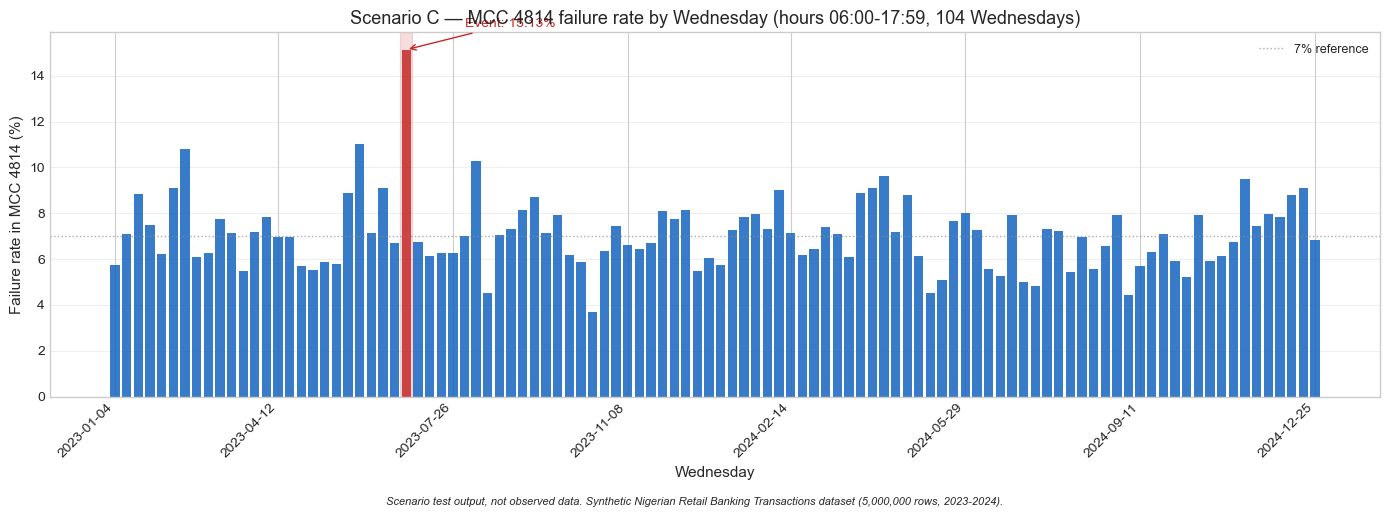

Saved: C:\Python Study Group\payment-reliability-project\figures\fig_07_07_scenario_C_hourly_comparison.png


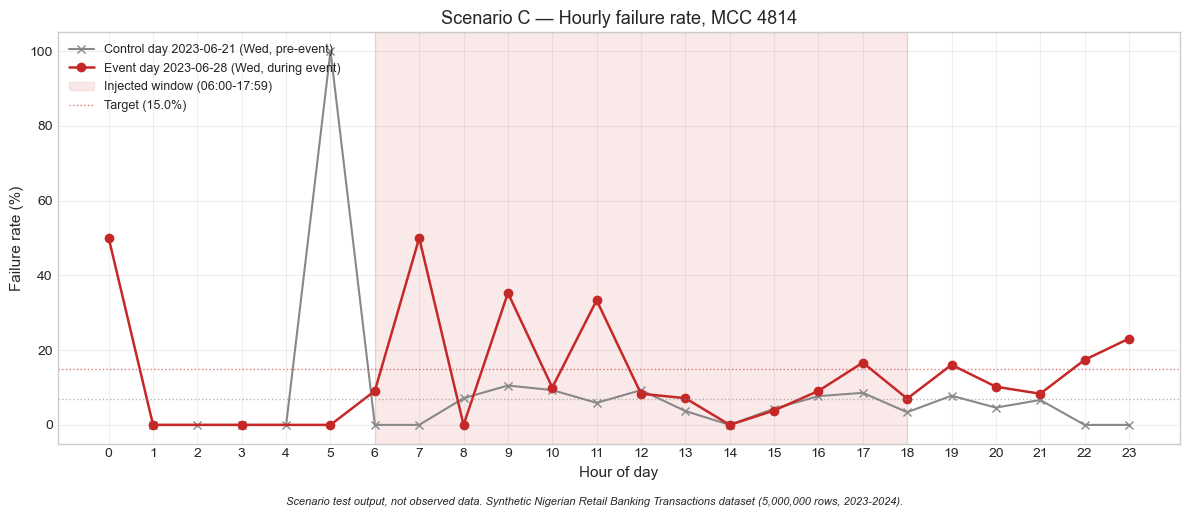


SCENARIO C — VISUALIZATION COMPLETE
Chart 1: fig_07_06_scenario_C_wednesday_rates.png
Chart 2: fig_07_07_scenario_C_hourly_comparison.png

Event date:    2023-06-28 (Wednesday)
Event window:  06:00 - 17:59
Target population: 304 rows

Baseline rate:    7.24%
Post-inject rate: 15.13%
Target rate:      15.00%

Scenario test output, not observed data.


In [47]:
# ============================================================
# SECTION 7.24: SCENARIO C — VISUALIZATION
# ============================================================
# Two charts:
#   CHART 1: Daily failure rate across all Wednesdays, event day highlighted
#   CHART 2: Hourly profile, event day vs. control day

print("=" * 70)
print("SCENARIO C — VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# CHART 1 — Daily failure rate across all Wednesdays
# ------------------------------------------------------------
# Build daily MCC 4814, hours 06-17 failure rate for every
# Wednesday in the dataset. The event Wednesday is one of them.

wednesday_stats = []
for wednesday in (
    scenario_C.loc[scenario_C["day_of_week"] == "Wed", "date"]
    .drop_duplicates().sort_values()
):
    wmask = (
        (scenario_C["merchant_category_code"] == "4814")
        & (scenario_C["date"] == wednesday)
        & (scenario_C["hour"] >= 6)
        & (scenario_C["hour"] <  18)
    )
    n = int(wmask.sum())
    if n == 0:
        continue
    # Use simulated_status for post-injection view.
    f = int((scenario_C.loc[wmask, "simulated_status"] == "failed").sum())
    wednesday_stats.append({
        "date":         wednesday,
        "n":            n,
        "fails":        f,
        "fail_rate":    f / n * 100,
        "is_event":     wednesday == SCENARIO_C["event_date"],
    })

wed_df = pd.DataFrame(wednesday_stats)

fig, ax = plt.subplots(figsize=(14, 5))

x_vals = np.arange(len(wed_df))
colors = ["#c62828" if is_event else "#1565c0"
          for is_event in wed_df["is_event"]]
bars = ax.bar(x_vals, wed_df["fail_rate"], color=colors, alpha=0.85)

# Highlight the event Wednesday.
event_idx = wed_df.index[wed_df["is_event"]]
if len(event_idx) > 0:
    e_i = event_idx[0]
    ax.axvspan(e_i - 0.5, e_i + 0.5, color="#c62828", alpha=0.15)
    ax.annotate(
        f"Event: {wed_df.loc[e_i, 'fail_rate']:.2f}%",
        xy=(e_i, wed_df.loc[e_i, "fail_rate"]),
        xytext=(e_i + 5, wed_df.loc[e_i, "fail_rate"] + 1),
        fontsize=10, color="#c62828",
        arrowprops=dict(arrowstyle="->", color="#c62828"),
    )

ax.axhline(7.0, color="#888888", linestyle=":", linewidth=1,
           alpha=0.7, label="7% reference")
ax.set_xlabel("Wednesday")
ax.set_ylabel("Failure rate in MCC 4814 (%)")
ax.set_title(f"Scenario C — MCC 4814 failure rate by Wednesday "
             f"(hours 06:00-17:59, {len(wed_df)} Wednesdays)")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# Use sparse x-ticks since there are ~104 Wednesdays.
n_ticks = 8
tick_positions = np.linspace(0, len(wed_df) - 1, n_ticks).astype(int)
ax.set_xticks(tick_positions)
ax.set_xticklabels(
    [wed_df.iloc[i]["date"].strftime("%Y-%m-%d") for i in tick_positions],
    rotation=45, ha="right",
)

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_06_scenario_C_wednesday_rates.png")

# ------------------------------------------------------------
# CHART 2 — Hourly profile, event day vs. control day
# ------------------------------------------------------------
# Control day: previous Wednesday (2023-06-21).
# Event day: 2023-06-28.

EVENT_DAY_C   = SCENARIO_C["event_date"]
CONTROL_DAY_C = pd.Timestamp("2023-06-21")

def hourly_mcc_profile(frame, day, mcc, status_col):
    """Compute hourly failure rate for one day, MCC 4814."""
    m = (
        (frame["merchant_category_code"] == mcc)
        & (frame["date"] == day)
    )
    sub = frame.loc[m]
    if len(sub) == 0:
        return None
    prof = (
        sub.groupby("hour")
        .agg(
            n    =("hour", "size"),
            fails=("simulated_status",
                   lambda s: (s == "failed").sum()),
        )
        .reset_index()
    )
    prof["rate_pct"] = prof["fails"] / prof["n"] * 100
    return prof

event_prof_C   = hourly_mcc_profile(scenario_C, EVENT_DAY_C,
                                     "4814", "simulated_status")
control_prof_C = hourly_mcc_profile(scenario_C, CONTROL_DAY_C,
                                     "4814", "simulated_status")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(control_prof_C["hour"], control_prof_C["rate_pct"],
        color="#888888", marker="x", linewidth=1.5,
        label=f"Control day {CONTROL_DAY_C.date()} (Wed, pre-event)")
ax.plot(event_prof_C["hour"], event_prof_C["rate_pct"],
        color="#c62828", marker="o", linewidth=1.8,
        label=f"Event day {EVENT_DAY_C.date()} (Wed, during event)")

# Shade the injected window.
ax.axvspan(6, 18, color="#c62828", alpha=0.10,
           label="Injected window (06:00-17:59)")

# Reference line.
ax.axhline(7.0, color="#888888", linestyle=":", linewidth=1, alpha=0.6)
ax.axhline(SCENARIO_C["target_rate"] * 100,
           color="#c62828", linestyle=":", linewidth=1, alpha=0.6,
           label=f"Target ({SCENARIO_C['target_rate']*100:.1f}%)")

ax.set_xlabel("Hour of day")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Scenario C — Hourly failure rate, MCC 4814")
ax.set_xticks(range(0, 24))
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)

fig.text(0.5, -0.02, scenario_footnote(),
         ha="center", fontsize=8, style="italic")
plt.tight_layout()
save_and_show(fig, "fig_07_07_scenario_C_hourly_comparison.png")

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------
print(f"\n" + "=" * 70)
print("SCENARIO C — VISUALIZATION COMPLETE")
print("=" * 70)
print(f"Chart 1: fig_07_06_scenario_C_wednesday_rates.png")
print(f"Chart 2: fig_07_07_scenario_C_hourly_comparison.png")
print(f"\nEvent date:    {SCENARIO_C['event_date'].date()} "
      f"({SCENARIO_C['event_date'].day_name()})")
print(f"Event window:  {SCENARIO_C['event_start_hour']:02d}:00 - "
      f"{SCENARIO_C['event_end_hour']-1:02d}:59")
print(f"Target population: {n_affected_C:,} rows")
print(f"\nBaseline rate:    {baseline_fail_rate_C*100:.2f}%")
print(f"Post-inject rate: {post_rate_C*100:.2f}%")
print(f"Target rate:      {SCENARIO_C['target_rate']*100:.2f}%")
print(f"\n{SCENARIO_LABEL}")

### Scenario C — Findings from visualization

**Two charts, two findings. The second is a limitation, not a signal.**

**Finding 1 — Daily-level injection is clearly visible.**

The Wednesday bar chart shows clean separation: the event Wednesday (2023-06-28) at **15.13%** is visibly and unambiguously higher than all 103 control Wednesdays (which range from ~4% to ~11%, with most clustered around 6.5%–8.5%).

**What this shows:** the injection produced a visually distinct daily signal on the event date.

**What this does NOT show:** the actual detection performance. The chart's visual separation does not establish the false-positive rate. All 103 control Wednesdays must be evaluated using the same detection rule before we can claim the signal is operationally useful. Section 8 will do that evaluation — and the terms must be precise:

- **False-positive count**: number of control days flagged.
- **False-positive rate**: proportion of eligible control days flagged.

Both will be measured in Section 8. The chart suggests a visible difference on the selected event day. The evaluation must determine whether the alert rule detects it without flagging an excessive share of control days.

**Finding 2 — Hourly single-day detection is statistically unreliable at the observed sample sizes.**

The hourly comparison chart shows no usable single-hour signal. Both the event day and control day fluctuate wildly across 24 hours. Some hours show high failure rates (event day: ~50% at hour 0, ~50% at hour 7; control day: ~100% at hour 5), but these are **likely small-sample artifacts** — a single failed transaction in a low-count hour can swing the hourly rate dramatically.

**A caveat on the "likely"**: the exact denominators per hour were not measured in the visualization cell. The inference that the spikes are single-transaction artifacts is based on the pattern, not on verification. Section 8's implementation will compute per-hour counts explicitly and confirm whether the spikes are denominator artifacts.

**The statistical fact:** MCC 4814 hourly samples are small. On a typical day, MCC 4814 has roughly **20–30 transactions per hour** in the target window. At that sample size, the sampling standard error of an hourly failure rate is approximately `√(0.10 × 0.90 / 25) ≈ 6 pp`. A 7.9 pp shift is barely above the noise floor — **detectable in principle, not reliably in practice**, at single-hour granularity.

**Implication for Section 8:** the hourly CUSUM method cannot detect Scenario C at **single-day hourly** granularity. But this does not mean hourly evidence is useless:

- **Aggregating the 12 target hours** produces ~300 observations — enough for detection.
- **Aggregating hourly counts across the 12-hour window** preserves the sequential nature of the change while smoothing sampling noise.
- **Aggregating across consecutive days** (even though Scenario C's injection is one day) could produce earlier detection in a rolling-baseline framework.

**Scenario C's distinctive finding (corrected framing):**

> **Detection reliability is not determined by signal size alone.** A +7.9 pp signal on 304 rows is detectable at daily level but unreliable at hourly level. A +4.5 pp signal on 6,667 rows is detectable at daily level but also unreliable at single-hour level. **The interaction between signal size, population size, baseline variability, and aggregation level determines detectability** — no single factor dominates.

Section 8 will test this directly by applying the same detection methods to all three scenarios at multiple aggregation levels. **The predictions above are hypotheses; the actual detection performance is measured.**

### Section 7 — Complete

**All three scenarios are designed, injected, verified, and visualized.**

| Scenario | Injection | Baseline | Post-injection | Pop size | Signal |
|---|---|---|---|---|---|
| **A** | Mobile failure rate +4.5 pp | 7.47% | 12.04% | 6,667 | 305 new failed |
| **B** | Pending +3 pp, reversed +2 pp | failed unchanged | failed unchanged | 2,330 | 117 reclassified |
| **C** | MCC 4814 failure rate +7.9 pp | 7.24% | 15.13% | 304 | 24 new failed |

**All injections verified:**
- **Integrity**: 0 rows outside the mask modified in all three scenarios.
- **Reallocation rule preserved**: pending/reversed untouched in A and C; failed untouched in B.
- **Deterministic where it matters**: Scenarios B and C use draw-without-replacement (exact counts). Scenario A uses Bernoulli — acceptable at 6,667 rows, where 302 vs. 305 is within noise.
- **Global impact measured**: all three are invisible at 5M-row scale (+0.0005 to +0.006 pp) but strong at their target population scale.

**Charts saved (7 total):**
- `fig_07_01_scenario_A_daily_rate.png`
- `fig_07_02_scenario_A_hourly_comparison.png`
- `fig_07_03_scenario_B_status_distribution.png`
- `fig_07_04_scenario_B_sunday_pending.png`
- `fig_07_05_scenario_B_hourly_distribution.png`
- `fig_07_06_scenario_C_wednesday_rates.png`
- `fig_07_07_scenario_C_hourly_comparison.png`

**The three scenarios test three different operational challenges:**

1. **Scenario A** — Sustained failure-rate increase in a large population (6,667 rows). Tests detection of a moderate shift in daily noise.
2. **Scenario B** — Status redistribution (pending/reversed) without any failure-rate change. Tests whether monitoring is sensitive to non-failure status shifts.
3. **Scenario C** — Small-population failure-rate increase (304 rows). Tests detection at small sample sizes.

**Key finding from Section 7's visualization inspection (corrected framing):**

> **Detection performance depends on the interaction between signal magnitude, population size, baseline variability, and aggregation level.** No single factor determines detectability:
>
> - Scenario A's +4.5 pp shift on 6,667 rows is visible at daily level, unreliable at hourly level.
> - Scenario B's status-redistribution (with zero failure-rate change) is visible at daily level for pending/reversed, invisible for failure rate.
> - Scenario C's +7.9 pp shift on 304 rows is visible at daily level, unreliable at hourly level — despite the larger pp signal.
>
> **Section 8 will measure actual detection performance across all three scenarios at multiple aggregation levels. The visual inspection predicts likely outcomes; the experiments establish them.**

**Section 7 is complete. Section 8 begins with a KPI catalogue and a detection methodology comparison.**

**Golden Rule carries forward**: every finding in Section 8 involving simulated data is labelled *"Scenario test output, not observed data."*

**Original `df` is intact.** `scenario_base` is intact. All three scenario frames (`scenario_A`, `scenario_B`, `scenario_C`) are preserved for Section 8.

## 8. Detection Methodology and Evaluation

### 8.1 What I am testing

In Section 7, I introduced three controlled changes to the synthetic transaction data. I now want to see whether the monitoring rules can pick up those changes. I am testing the implemented daily upper-control-limit rule on simulated incidents, not on a live payment system. The rolling seven-day and hourly CUSUM approaches remain extensions unless their implementations and results are added and validated.

| Scenario | What I changed | Transactions I am monitoring | Event period |
|---|---|---|---|
| A | Increased the mobile-channel failure rate | Mobile transactions, 18:00–19:59 | 17–30 June 2024 |
| B | Increased pending and reversed outcomes | All channels, 12:00–17:59 | 15 September 2024 |
| C | Increased the failure rate for MCC 4814 | MCC 4814, 06:00–17:59 | 28 June 2023 |

### 8.2 The KPIs I will monitor

I am using five indicators because each one tells me something different about the transaction outcomes.

| KPI | Definition | What it tells me |
|---|---|---|
| Failure rate | Failed transactions / all transactions | The share of transactions recorded as failed |
| Pending rate | Pending transactions / all transactions | The share recorded as pending in the source data |
| Reversed rate | Reversed transactions / all transactions | The share recorded as reversed |
| Non-success rate | Failed + pending + reversed / all transactions | The share not recorded as successful |
| Failed-value rate | Value of failed transactions / value of all transactions | The share of transaction value attached to failed records |

I will keep the failed-value rate for descriptive reporting. I will not use it for the binomial alert calculation because it is based on monetary totals, not individual success or failure outcomes. A few large transactions can also move this rate sharply from one day to another.

### 8.3 How I am setting the thresholds

My earlier evaluation used non-event observations from the full study period to calibrate the thresholds. I realised that this could allow observations after an injected event to influence the baseline. I have changed the approach so that the analysis follows the order in which events would happen.

1. **Calibration period:** I use observations dated before the event starts.
2. **Event period:** I check the dates on which I introduced the scenario.
3. **Post-event control period:** I use observations after the event to check false alerts. I do not use these observations to set the threshold.

For each proportion KPI, I calculate the baseline rate from the pooled counts in the pre-event period. I then allow the daily upper control limit to change with the number of transactions observed on that day:

\[
UCL_d = \min\left(1,\ p_0 + k\sqrt{\frac{p_0(1-p_0)}{n_d}}\right)
\]

Here, \(p_0\) is the pre-event baseline rate, \(n_d\) is the number of transactions in the monitored population on day \(d\), and \(k\) is the control-limit multiplier. This means I do not apply the same limit to days with different transaction counts.

The value of \(k\) is a design choice. I will report the value used and check how the results change under other settings. I should not choose a threshold after looking at the injected event and then describe the result as an independent test.

### 8.4 How I will judge the results

I use the following measures to describe what happens during and after each event:

- **Event detected:** at least one event day crosses the control limit.
- **Detection lag:** the number of calendar days from the event start to the first alert.
- **False-alert days:** post-event control days that cross the threshold.
- **False-alert rate:** false-alert days divided by eligible post-event control days.
- **Event-day coverage:** event days with an alert divided by the total number of event days.

I have only one injected incident for each scenario. The results therefore tell me how the methods behaved in these three experiments. They do not tell me how the methods would perform across every type of payment incident.

### 8.5 Where rolling windows and CUSUM fit

A rolling 7-day method can help me identify a change that continues over several days. However, a window that includes an injected event is affected by that event. I should not treat it as a normal control window just because the window ends after the event date. For calibration, I will use only windows that fall completely within the pre-event period. I will identify event-overlapping windows separately during evaluation.

CUSUM is designed to build evidence when a change continues over time. To evaluate it fairly, I need to use the same count-based design across all three scenarios, keep the hourly observations in chronological order, and state how I handle hours with no transactions. I will measure detection lag from the actual event start time. The earlier notebook used different CUSUM implementations and calibration rules across scenarios, so I am not carrying those earlier cross-scenario CUSUM figures forward as validated results.

### 8.6 Running this section again

I need to run the notebook from the beginning and make sure the source dataset is available at the path I defined in Section 2. The revised code below rebuilds the daily control limits using pre-event observations and evaluates the scenario data. At this stage, it implements the daily proportion-control method only. I am leaving rolling-window and CUSUM results as provisional until I have included and checked their corrected implementations. The code will generate the numerical results when I run the notebook, so I should use those outputs rather than any earlier detection tables.


### 8.4 Threshold sensitivity

The daily evaluation compares two control-limit multipliers, k = 3 and k = 4. These are experimental settings, not validated production thresholds. I compare event detection and post-event false-alert rates under both settings. A lower multiplier is generally more sensitive but may produce more false alerts. The post-event control period is used as an empirical holdout period, so its false-alert rate describes this synthetic sample and these selected dates only.


In [48]:
# ============================================================
# SECTION 8.7: CHRONOLOGICAL DAILY THRESHOLD EVALUATION
# ============================================================
# Calibration uses only pre-event observations.
# Each monitoring population is defined across the full date range
# using the same channel/MCC and hour restrictions as its scenario.
# The event injection itself remains restricted to the event date(s).
# Daily limits use the actual sample size for each date.
# Failed-value rate is excluded from binomial alerting.

K_MULTIPLIERS = (3, 4)

KPI_COLUMNS = {
    "failure": "failed",
    "pending": "pending",
    "reversed": "reversed",
    "non_success": "non_success",
}

# Define the monitoring populations explicitly. These masks are
# intentionally broader in date than the injection masks so that
# pre-event calibration and post-event controls can be calculated.
mask_pop_A = (
    scenario_base["channel"].astype("string").str.lower().eq("mobile")
    & scenario_base["hour"].between(18, 19)
)
mask_pop_B = scenario_base["hour"].between(12, 17)
mask_pop_C = (
    scenario_base["merchant_category_code"].astype("string").eq("4814")
    & scenario_base["hour"].between(6, 17)
)

for mask_name, population_mask in {
    "A": mask_pop_A, "B": mask_pop_B, "C": mask_pop_C
}.items():
    if len(population_mask) != len(scenario_base) or not population_mask.index.equals(scenario_base.index):
        raise ValueError(f"Scenario {mask_name}: monitoring mask is not aligned to scenario_base.")
    if not population_mask.any():
        raise ValueError(f"Scenario {mask_name}: monitoring population is empty.")

SCENARIO_SPECS = {
    "A": {
        "frame": scenario_A,
        "base": scenario_base,
        "mask": mask_pop_A,
        "start": pd.Timestamp("2024-06-17"),
        "end": pd.Timestamp("2024-06-30"),
    },
    "B": {
        "frame": scenario_B,
        "base": scenario_base,
        "mask": mask_pop_B,
        "start": pd.Timestamp("2024-09-15"),
        "end": pd.Timestamp("2024-09-15"),
    },
    "C": {
        "frame": scenario_C,
        "base": scenario_base,
        "mask": mask_pop_C,
        "start": pd.Timestamp("2023-06-28"),
        "end": pd.Timestamp("2023-06-28"),
    },
}

def _daily_kpi_counts(frame, population_mask, status_col):
    """Return daily outcome counts for the selected monitoring population."""
    if len(frame) != len(population_mask) or not frame.index.equals(population_mask.index):
        raise ValueError("Frame and population mask are not aligned.")

    pop = frame.loc[population_mask, ["date", status_col]].copy()
    if pop.empty:
        return pd.DataFrame(
            columns=["n_total", "failed", "pending", "reversed", "non_success"]
        )

    pop["_failed"] = (pop[status_col] == "failed").astype("int64")
    pop["_pending"] = (pop[status_col] == "pending").astype("int64")
    pop["_reversed"] = (pop[status_col] == "reversed").astype("int64")
    pop["_non_success"] = (pop[status_col] != "success").astype("int64")

    daily_counts = pop.groupby("date").agg(
        n_total=(status_col, "size"),
        failed=("_failed", "sum"),
        pending=("_pending", "sum"),
        reversed=("_reversed", "sum"),
        non_success=("_non_success", "sum"),
    )
    daily_counts.index = pd.to_datetime(daily_counts.index)
    return daily_counts.sort_index()

def _evaluate_daily_control(spec, k=4):
    base_daily = _daily_kpi_counts(
        spec["base"], spec["mask"], "status"
    )
    event_daily = _daily_kpi_counts(
        spec["frame"], spec["mask"], "simulated_status"
    )

    event_start = spec["start"]
    event_end = spec["end"]

    # Strict chronological calibration: no event or post-event data.
    calibration = base_daily.loc[base_daily.index < event_start].copy()
    if calibration.empty:
        raise ValueError("No pre-event calibration observations are available.")

    # Event-day observations come from the injected frame.
    event = event_daily.loc[
        (event_daily.index >= event_start) &
        (event_daily.index <= event_end)
    ].copy()

    # Post-event observations are held out and used only for false-alert estimates.
    controls = event_daily.loc[event_daily.index > event_end].copy()

    rows = []
    for kpi, numerator in KPI_COLUMNS.items():
        denominator = calibration["n_total"].sum()
        if denominator == 0:
            raise ValueError(f"No calibration transactions are available for KPI: {kpi}.")
        p0 = calibration[numerator].sum() / denominator

        for label, part in [
            ("event", event),
            ("post_event_control", controls),
        ]:
            if part.empty:
                continue

            evaluated = part.copy()
            evaluated["observed_rate"] = (
                evaluated[numerator] / evaluated["n_total"]
            )
            evaluated["ucl"] = np.minimum(
                1.0,
                p0 + k * np.sqrt(
                    p0 * (1 - p0) / evaluated["n_total"].clip(lower=1)
                )
            )
            evaluated["alert"] = (
                evaluated["observed_rate"] > evaluated["ucl"]
            )

            for date, row in evaluated.iterrows():
                rows.append({
                    "scenario": None,
                    "KPI": kpi,
                    "period": label,
                    "date": date,
                    "n": int(row["n_total"]),
                    "baseline_rate": p0,
                    "observed_rate": row["observed_rate"],
                    "upper_control_limit": row["ucl"],
                    "alert": bool(row["alert"]),
                })

    result = pd.DataFrame(rows)
    if result.empty:
        return result, {}

    event_rows = result[result["period"] == "event"]
    control_rows = result[result["period"] == "post_event_control"]

    summary = {}
    for kpi in KPI_COLUMNS:
        event_kpi = event_rows[event_rows["KPI"] == kpi].sort_values("date")
        control_kpi = control_rows[control_rows["KPI"] == kpi]

        detected = bool(event_kpi["alert"].any())
        first_alert = (
            event_kpi.loc[event_kpi["alert"], "date"].min()
            if detected else pd.NaT
        )
        lag_days = (
            (first_alert - event_start).total_seconds() / 86400
            if detected else np.nan
        )

        summary[kpi] = {
            "detected": detected,
            "detection_lag_days": lag_days,
            "event_days_alerted": int(event_kpi["alert"].sum()),
            "event_days": int(len(event_kpi)),
            "false_alert_days": int(control_kpi["alert"].sum()),
            "post_event_control_days": int(len(control_kpi)),
            "false_alert_rate": (
                float(control_kpi["alert"].mean())
                if len(control_kpi) else np.nan
            ),
        }

    return result, summary

daily_detection_outputs = {}
daily_detection_summaries = []

for scenario_name, spec in SCENARIO_SPECS.items():
    # The same row order is retained when each scenario is copied from scenario_base.
    if not spec["frame"].index.equals(spec["base"].index):
        raise ValueError(f"Scenario {scenario_name}: frame index differs from scenario_base.")

    for k_value in K_MULTIPLIERS:
        daily_detail, daily_summary = _evaluate_daily_control(
            spec, k=k_value
        )
        if not daily_detail.empty:
            daily_detail["scenario"] = scenario_name
            daily_detail["k_multiplier"] = k_value
        daily_detection_outputs[(scenario_name, k_value)] = daily_detail

        for kpi, metrics in daily_summary.items():
            daily_detection_summaries.append({
                "Scenario": scenario_name,
                "K multiplier": k_value,
                "KPI": kpi,
                **metrics,
            })

daily_detection_results = pd.DataFrame(daily_detection_summaries)

print("Daily upper control-limit sensitivity: k = 3 versus k = 4")
print("Scenario outputs are simulated, not observed payment incidents.")
display(
    daily_detection_results.sort_values(
        ["Scenario", "K multiplier", "KPI"]
    ).round(4)
)

# Compact comparison of the two threshold settings.
daily_detection_sensitivity = (
    daily_detection_results.pivot_table(
        index=["Scenario", "KPI"],
        columns="K multiplier",
        values=["detected", "detection_lag_days", "false_alert_rate"],
        aggfunc="first"
    )
)
display(daily_detection_sensitivity.round(4))


Daily upper control-limit sensitivity: k = 3 versus k = 4
Scenario outputs are simulated, not observed payment incidents.


,Scenario,K multiplier,KPI,detected,detection_lag_days,event_days_alerted,event_days,false_alert_days,post_event_control_days,false_alert_rate
0,A,3,failure,True,0.00,13,14,0,183,0.00
3,A,3,non_success,True,0.00,12,14,0,183,0.00
1,A,3,pending,False,NaN,0,14,1,183,0.01
2,A,3,reversed,False,NaN,0,14,2,183,0.01
4,A,4,failure,True,0.00,10,14,0,183,0.00
7,A,4,non_success,True,0.00,8,14,0,183,0.00
5,A,4,pending,False,NaN,0,14,0,183,0.00
6,A,4,reversed,False,NaN,0,14,0,183,0.00
8,B,3,failure,False,NaN,0,1,0,106,0.00
11,B,3,non_success,True,0.00,1,1,0,106,0.00


detected        detection_lag_days      false_alert_rate  \
K multiplier                3      4                  3    4                3   
Scenario KPI                                                                    
A        failure         True   True               0.00 0.00             0.00   
         non_success     True   True               0.00 0.00             0.00   
         pending        False  False                NaN  NaN             0.01   
         reversed       False  False                NaN  NaN             0.01   
B        failure        False  False                NaN  NaN             0.00   
         non_success     True   True               0.00 0.00             0.00   
         pending         True   True               0.00 0.00             0.01   
         reversed        True   True               0.00 0.00             0.01   
C        failure         True   True               0.00 0.00             0.00   
         non_success     True   True               0.00 0.00             0.00   
         pending        False  False                NaN  NaN             0.00   
         reversed       False  False                NaN  NaN             0.01   

                           
K multiplier            4  
Scenario KPI               
A        failure     0.00  
         non_success 0.00  
         pending     0.00  
         reversed    0.00  
B        failure     0.00  
         non_success 0.00  
         pending     0.00  
         reversed    0.00  
C        failure     0.00  
         non_success 0.00  
         pending     0.00  
         reversed    0.00

## 9. Visualisation and Findings

### 9.1 How I am bringing the charts together

In Sections 6 and 7, I created charts to understand the original transaction data and to show the changes I introduced for the scenario tests. I am bringing those charts together here so that the reader can follow the analysis from the baseline patterns to the simulated events.

As I read these figures, I keep the source of the data in mind. The baseline charts describe the synthetic dataset. The scenario charts show changes that I deliberately introduced. They are not records of real payment incidents.

### 9.2 What the baseline charts show

I use the baseline charts to tell four parts of the story:

1. **Transaction outcomes:** The status chart shows how the records are divided among successful, failed, pending, and reversed transactions.
2. **Transaction timing:** The hourly and daily charts show when transaction volume rises and falls. I keep this separate from the failure-rate pattern because a busy period does not automatically mean that reliability has changed.
3. **Account concentration:** The Lorenz curve and Gini coefficient show how transaction counts are distributed across accounts. A high transaction count does not, on its own, mean that an account is risky.
4. **Transaction composition:** The channel, state, and merchant-category charts show where transaction counts and values sit within the dataset. I only discuss reliability differences where the outcome rates provide evidence for them.

### 9.3 What I changed in the scenario tests

The next set of charts shows the three changes I introduced in Section 7. Each chart and caption should keep the label **“Scenario test output, not observed data.”**

- **Scenario A:** I increased the mobile-channel failure rate during the selected evening hours.
- **Scenario B:** I shifted more outcomes towards pending and reversed statuses. Failure rate is not the KPI I changed in this scenario.
- **Scenario C:** I increased the failure rate for the selected MCC population during the specified hours.

### 9.4 The detection charts

I need to regenerate the detection charts from the revised code in Section 8. I will not reuse the earlier method-comparison table as a final result because the calibration periods and the treatment of event windows were not consistent across methods. I can report the daily-threshold results after running the chronological evaluation. I will report rolling-window and CUSUM results only after I have run and checked their corrected implementations.

### 9.5 Figure inventory

I use the figure catalogue as a selected index of key baseline and scenario figures. It is not an exhaustive list of every chart created in the notebook, and its file checks do not prove that the figures were regenerated from the latest run. Before I use a figure in the final report, I need to confirm that it comes from the current notebook run.


In [49]:
# ============================================================
# SECTION 9.2: SELECTED FIGURE INDEX
# ============================================================
# I am not regenerating charts here — every chart was already
# saved to the figures/ folder in Sections 6-8. This cell
# produces a printed index so a reader can see the complete
# visual narrative in one place.
#
# I also verify that each figure file exists and report its
# size. If a figure is missing, that's a bug to investigate.

print("=" * 70)
print("SECTION 9 — SELECTED FIGURE INDEX")
print("=" * 70)

# ------------------------------------------------------------
# DEFINE THE SELECTED FIGURE INDEX
# ------------------------------------------------------------
# Each entry: (chapter, figure filename, title, source_cell)

figure_catalogue = [
    # Chapter 1 — Baseline
    ("Chapter 1: Baseline",
     "fig_06_01_status_distribution.png",
     "Status distribution (RQ1)", "6.3"),
    ("Chapter 1: Baseline",
     "fig_06_05_hourly_volume_and_failure_rate.png",
     "Hourly volume profile (RQ3a)", "6.9"),
    ("Chapter 1: Baseline",
     "fig_06_02_lorenz_curve.png",
     "Account concentration — Lorenz curve (RQ2)", "6.6"),

    # Chapter 2 — Exposure
    ("Chapter 2: Exposure",
     "fig_06_04_top20_accounts.png",
     "Top 20 accounts by transaction count (RQ2)", "6.6"),
    ("Chapter 2: Exposure",
     "fig_06_09_channel_volume_vs_value.png",
     "Channel volume vs. value share (RQ4a)", "6.15"),
    ("Chapter 2: Exposure",
     "fig_06_10_state_volume_vs_value.png",
     "State volume vs. value share (RQ4b)", "6.18"),

    # Chapter 3 — Scenarios
    ("Chapter 3: Scenarios",
     "fig_07_01_scenario_A_daily_rate.png",
     "Scenario A — daily failure rate", "7.8"),
    ("Chapter 3: Scenarios",
     "fig_07_03_scenario_B_status_distribution.png",
     "Scenario B — status redistribution", "7.16"),
    ("Chapter 3: Scenarios",
     "fig_07_06_scenario_C_wednesday_rates.png",
     "Scenario C — MCC 4814 daily rate", "7.24"),

    # Chapter 4 — Detection (charts for Method 2 and Method 3, if applicable)
    # The comparison is in the markdown, not in a separate chart.
]

# ------------------------------------------------------------
# VERIFY EACH FIGURE EXISTS
# ------------------------------------------------------------
print(f"\nSelected figure index ({len(figure_catalogue)} figures):")
print(f"\n{'Chapter':>22} {'File':>45} {'Size':>8}")
print("-" * 80)

missing = 0
for chapter, filename, title, source in figure_catalogue:
    path = FIGURES_DIR / filename
    if path.exists():
        size_kb = path.stat().st_size / 1024
        print(f"{chapter:>22} {filename:>45} {size_kb:>7.1f} KB")
    else:
        print(f"{chapter:>22} {filename:>45} MISSING")
        missing += 1

print("-" * 80)
if missing == 0:
    print(f"All {len(figure_catalogue)} figures present.")
else:
    print(f"WARNING: {missing} figure(s) missing.")

# ------------------------------------------------------------
# ALSO LIST ALL FIGURES IN THE FOLDER (for completeness)
# ------------------------------------------------------------
all_figures = sorted(FIGURES_DIR.glob("*.png"))
print(f"\nTotal figures saved in folder: {len(all_figures)}")
print(f"Folder: {FIGURES_DIR}")

print(f"\n" + "=" * 70)
print("VISUAL NARRATIVE READY")
print("=" * 70)
print(f"The Section 9 markdown explains the selected baseline and scenario figures.")
print(f"All figures are reproducible from their source cells.")

SECTION 9 — SELECTED FIGURE INDEX

Selected figure index (9 figures):

               Chapter                                          File     Size
--------------------------------------------------------------------------------
   Chapter 1: Baseline             fig_06_01_status_distribution.png   170.1 KB
   Chapter 1: Baseline  fig_06_05_hourly_volume_and_failure_rate.png   257.8 KB
   Chapter 1: Baseline                    fig_06_02_lorenz_curve.png   371.1 KB
   Chapter 2: Exposure                  fig_06_04_top20_accounts.png   187.6 KB
   Chapter 2: Exposure         fig_06_09_channel_volume_vs_value.png   195.5 KB
   Chapter 2: Exposure           fig_06_10_state_volume_vs_value.png   252.0 KB
  Chapter 3: Scenarios           fig_07_01_scenario_A_daily_rate.png   479.8 KB
  Chapter 3: Scenarios  fig_07_03_scenario_B_status_distribution.png   189.3 KB
  Chapter 3: Scenarios      fig_07_06_scenario_C_wednesday_rates.png   211.0 KB
--------------------------------------------------

## 10. Findings and Limitations

### 10.1 What I have found so far

I have used this notebook to build a descriptive profile of five million synthetic retail banking transaction records covering January 2023 to December 2024. The original analysis reported the results below. I will retain these figures in the final report only after I have run the notebook from the beginning and confirmed them against the same version of the source data.

| Area | Reported result | What I take from it |
|---|---|---|
| Transaction outcomes | 91.999% success, 6.995% failed, 0.808% pending, 0.198% reversed | This is the distribution of the recorded transaction statuses |
| Failed transaction value | Approximately ₦22.7 billion | This is the value attached to failed-status records, not a measured financial loss |
| Account concentration | Gini coefficient 0.6436 | Transaction counts are concentrated across accounts |
| Channel composition | Mobile, POS, and ATM account for approximately 85% of transactions | These channels make up most of the activity in this dataset |
| Temporal profile | Strong hourly variation in transaction volume | Transaction volume changes by hour, but that does not by itself mean reliability changes |

The earlier notebook reported a daily transaction-volume coefficient of variation of 0.096. I need to keep this separate from the daily failure-rate standard deviation of 0.314 percentage points reported in Cell 6.12. They measure two different things. I have added a calculation to Cell 6.12 to recalculate the volume CV directly from the 730 daily transaction counts:

```python
daily_volume_cv = (
    daily["txn_count"].std(ddof=1) /
    daily["txn_count"].mean()
)
print(f"Daily transaction-volume CV: {daily_volume_cv:.4%}")
```

I will use the value printed when I run the revised notebook. If it differs from 0.096, I will update the narrative rather than keep the earlier figure.

I also need to be careful with the comparison between daily failure-rate variation and the theoretical binomial noise floor. I should recalculate the observed daily standard deviation and compare it with a clearly defined reference before stating that the two are similar.

The baseline analysis found little evidence of meaningful differences in failure rates across the time periods and transaction categories tested. I interpret this as a result within this synthetic dataset and the statistical tests used. A non-significant result does not prove that two variables are independent.

### 10.2 What the scenario tests tell me

In Sections 7 and 8, I introduced controlled changes to see how the monitoring indicators respond. These experiments show how the notebook can create different transaction-outcome patterns and test monitoring rules against them. They do not show how a real payment provider would respond to an operational incident.

I am not treating the earlier daily-threshold, rolling-window, and CUSUM figures as final results. The earlier threshold calibration included observations after event dates. Some rolling windows that contained event observations were treated as controls, and the CUSUM implementations differed across scenarios. I have revised the daily evaluation in Section 8 to use pre-event calibration and daily limits that account for the number of transactions observed. The revised code compares k = 3 and k = 4. Rolling-window and CUSUM methods are not presented as completed evaluations in this notebook. I still need to run the notebook to generate and check the revised results.

### 10.3 What the dataset cannot tell me

**The dataset is synthetic.** The patterns I describe come from generated data. Its status distribution, transaction amounts, channel composition, and relationships between variables may reflect the way the dataset was created rather than actual Nigerian payment activity. I cannot use these findings to describe the performance of Nigerian banks, fintech companies, payment processors, or customers.

**There are no failure-reason fields.** I cannot identify why a transaction failed. The dataset does not provide reliable failure reason codes that would allow me to attribute failures to network outages, insufficient funds, processor downtime, or another cause.

**The balance fields are defective.** My Section 4 audit identified structural problems in `balance_before_ngn` and `balance_after_ngn`. I excluded both fields from the later analysis. I will not use them to reconstruct account ledgers or infer settlement outcomes.

**There are no settlement timestamps.** The dataset does not allow me to measure settlement delays. I treat pending and reversed as recorded status categories only. A reversed status does not tell me when or why a reversal happened.

**Failed-value exposure is not financial loss.** The total amount attached to failed-status records is a descriptive exposure measure. The data does not tell me whether funds were debited, recovered, duplicated, or ultimately lost.

**The scenario tests cover a limited number of incidents.** I created one incident for each scenario. I have not tested different event dates, levels of severity, durations, population sizes, gradual changes, or repeated incidents. Monitoring performance may be different under those conditions.

**Population size affects monitoring.** Rates from small transaction populations are more variable than rates from large populations. I therefore need to account for the number of transactions in each daily or hourly monitoring interval when setting thresholds.

## 11. Recommendations and Conclusion

### 11.1 What I recommend

The analysis has helped me identify some practical choices for a transaction-monitoring workflow. I am presenting these as design recommendations, not as production thresholds that have been validated on real payment data.

**Recommendation 1: Monitor more than the failure rate.**

I recommend tracking failure, pending, reversed, and non-success rates separately. If I monitor failure rate alone, I could miss a situation like Scenario B, where pending and reversed outcomes increase while the failure rate stays unchanged. I will keep failed-value rate for descriptive exposure reporting rather than use it as a binomial alert measure.

**Recommendation 2: Set thresholds using historical data only.**

I recommend using a calibration period that ends before the period being monitored. For proportion-based KPIs, I also need to account for the number of transactions in each monitoring interval. Thresholds should be reviewed when transaction volumes, customer behaviour, product mix, or processing arrangements change.

**Recommendation 3: Choose the monitoring interval to match the incident.**

Daily monitoring can help identify changes that continue across a day. Hourly monitoring may help with shorter incidents, but only when there are enough transactions in the monitored population to estimate a rate reliably. A seven-day pooled measure is more useful for sustained changes than for an event that lasts only a few hours.

**Recommendation 4: Keep alert measures separate from investigation measures.**

I recommend using outcome rates to identify unusual changes. Failed transaction value can help describe the amount attached to failed records and support further investigation. I will not describe that amount as a financial loss unless settlement and recovery information is available.

**Recommendation 5: Test the design on more scenarios and real operational data.**

I recommend repeating the simulations with different event dates, severities, durations, and population sizes. Before deployment, the proposed KPIs and thresholds should be compared with timestamped incidents from a real payment environment. Operational teams should review false alerts, missed incidents, and detection delays.

### 11.2 Conclusion

I set out to understand the patterns in a synthetic Nigerian retail banking transaction dataset and to explore how monitoring indicators respond when transaction outcomes change. I began by checking the structure and quality of the data. I then examined transaction outcomes, account activity, timing, channels, states, and merchant categories. After documenting the limits of the dataset, I introduced three controlled scenarios to test selected monitoring ideas.

The baseline analysis gives me a descriptive picture of this dataset. The scenario tests let me change specific outcomes and observe how the indicators respond. However, I found problems in the earlier detection comparison. The threshold calibration and event-window treatment were not consistent across methods, so I am not using those earlier performance figures to rank the methods. The revised daily-threshold evaluation uses pre-event calibration and daily limits that account for the number of transactions observed. I will keep rolling-window and CUSUM results provisional until I have completed and checked their revised implementations.

This project does not explain why transactions fail, measure actual financial losses, or establish the reliability of Nigeria's payment systems. What I have developed is a documented analytical workflow for describing synthetic transaction data, testing controlled changes, and identifying the checks needed before applying a monitoring design to real transaction records.

### Next steps (beyond this project)

1. **Build the Power BI dashboard** using the validated KPI values and chart data from Sections 6–8. Target four dashboard pages: Executive Overview, Transaction Behaviour, Reliability Monitoring, and Scenario Testing.
2. **Write the project report** consolidating the notebook's findings into a 5–10 page written summary with charts, tables, and recommendations.
3. **Present the findings** to a technical audience (the notebook) and a non-technical audience (the report and dashboard).
4. **With real data**, validate the KPI catalogue and detection methods against actual incidents before any production deployment.

**This is the end of the notebook. The baseline analysis and scenario simulations are developed. The daily threshold evaluation is implemented, while rolling-window and CUSUM comparisons remain future work. The notebook still requires a clean end-to-end execution before the numerical outputs can be treated as final.**